# Notebook 16: What Notebook 15 Left Open

**References:** Mitchell, M. and Pulvino, T. (2001). Characteristics of risk and return in risk arbitrage. *Journal of Finance* 56(6), 2135-2175. Gatev, E., Goetzmann, W. N. and Rouwenhorst, K. G. (2006). Pairs trading: performance of a relative-value arbitrage rule. *Review of Financial Studies* 19(3), 797-827. Avellaneda, M. and Lee, J.-H. (2010). Statistical arbitrage in the US equities market. *Quantitative Finance* 10(7), 761-782.

Notebook 15 gave the market of `lob/statarb.py` three things it lacked (an index book, stock deals, a factor that trends) and ended with three questions it could not settle. This notebook settles two and closes the third [written before the run; after it, the first is settled, the second is answered on a route with no order books and not in the market, where the 24 new seeds did not show the gap and its size stays open, and the third is closed at this market's price of an index]. It changes nothing in the library: every market and trader below is notebook 15's, as it stands.

1. **Does reading the news pay a pairs trader on its own pairs, where there is a risk premium?** In notebook 15 a pairs trader that sits out a deal's life in the target's pairs (the *reader*) led the one that does not read the news (the *blind* trader) at a true chance of a break of 0.20, where the market prices 0.40, on eight seeds: a lead, short of two standard errors, and not a finding (section 1 reprints it). Section 1 tests it on seeds that no market run of notebook 15 used, with the test written into the cell before it is run.
2. **Why are the pairs chosen in the market with a risk premium worth less?** In notebook 15 the pairs that a trader chose in the market of 0.40 were worth 446 to 635 more, in the market of 0.20, than the pairs that market's own mids gave it (7 seeds of 8; after the run, one comparison seen three times, since the three traders of a seed share their pairs), and nothing in that notebook explained it. Section 2 measures how the pairs differ, by a route with no order books that can use many seeds, then which half of the difference is the choice of pairs and which the hedge fitted to them, then whether the market agrees with the route, and whether the difference is the deals or the luck of the order flow.
3. **Would sector index books let a residual hedge with one leg, more cheaply?** Notebook 15's index book is of all twelve books, and it listed sector indexes as left out. Section 3 does not build one: it shows what the two hedges hold and what each costs to trade, and what the cheapest mix of books and a sector index could have saved the residual trader on the orders it made.

**The market** is notebook 15's: twelve books in three sectors (a market factor and three sector factors), each with a part of its own that mean-reverts and is moved by order flow, and traders around each fair value whose orders the mids follow. Deals (`lob/deals.py`) are announced at 0.002 a unit of time over the twelve books: an acquirer in the target's sector offers shares, the target's fair value moves toward the offer's worth for the deal's life of 500 units, and the deal may break, when it falls back. The market prices a chance `priced` of 0.40 that a deal breaks; the dial is the true chance, `breaks`. At 0.40 the price is fair and the target's fair value is expected to drift no more than it was priced to; at 0.20 a break is overpriced, so the target is expected to rise by more than it was priced to, against the short position that a z-score pairs trader tends to take in a target whose spread has jumped at the announcement. The reader, which stays out of the target while the deal is on, does not make that bet. The pairs trader is notebook 13's: eight pairs chosen by distance from a formation of 2,000 decisions, 2.5 lots of each, a window of 400 decisions, entering at a z-score of 2, deciding every 5 units, alone in its market with market orders.

**How to read it.**

- *Seeds.* Four groups, and nothing in this notebook was chosen on any of them: everything that was explored, the settings, the questions and the designs of the tests, was explored on seeds 1 to 100.
  - `FIRST`, seeds 101 to 108: notebook 15's eight. Section 1 reproduces notebook 15's rows on them, and asserts that they equal what notebook 15 printed, to the last digit; they are never tested again, because the hypothesis of section 1 came from them (and from seeds 1 to 8) [after the run: a cell of section 2, added after the first run, also walks the route on them, as a diagnostic that nothing was chosen on].
  - `NEW`, seeds 121 to 144: 24 seeds fixed before this notebook was written, which no market run of notebook 15 used. Section 1's test is on these alone.
  - `PAPER`, seeds 201 to 400: 200 seeds for section 2's route with no order books, which takes a few seconds a seed.
  - `FEW`, seeds 101 to 108 again: section 3's.

  Seeds 1 to 8, where the settings were chosen, are never pooled with these.
- *Paired by seed.* Two rows of one table are on the same seeds, and in one seed they share the market's factors and shocks (and in a market with deals, the deals), though not its order flow once a trader's orders move it. A difference between rows is taken seed by seed, and a table says how many seeds it was positive on. A standard error is the standard deviation across seeds (its variance with one fewer than the number of seeds in the denominator) over the square root of how many there are.
- *P&L* is in ticks times lots, after costs, over a span of 20,000 units of time (unless a section says otherwise) after a burn that is the same for every row of a table. The tables also print two risk figures: `deviation_long`, the standard deviation of the P&L's changes over successive stretches of 100 units over the square root of 100, and `risk_adjusted_long`, the mean change of P&L a unit over that.
- *Before costs* is P&L with what crossing the spreads cost added back. It holds what the mids' bounce around their fair values pays a trader that enters when a mid is off, and its own impact on the mid it is marked at. It is never an edge, here or in any table of this notebook.
- *Reproducing before extending.* Every helper of the setup cell is notebook 15's, and the first cell of section 1 runs notebook 15's own rows and compares them with what notebook 15 saved, so that a change in the harness cannot pass for a finding.
- *The backtest.* Sections 1 to 3 each end with the scorecard and signal chart of one trader on one seed that no setting was chosen on.
- *Run twice.* The notebook was run twice, each time in full. The second run corrected printed sentences of the first that were wrong, and added the cells whose heads say "added after the first run, on a review of it": each is a description and not a test, nothing was chosen from it, and each prints most of what the review of the first run measured and the conclusions quote. Every figure of the first run is printed again by the second to the digit, except the timings and the strings corrected below, because the second run is the same code on the same seeds (the traders now also record, which 1a and 1c (4) assert changes nothing, and the test cell changed only in how it prints the p): it is not a second test or a replication, and the test was decided by the first run, on the outcome texts written before it. What differs between the two runs is the text of the corrected sentences (a bet printed as two different whole figures, a p-value printed as 0.0000, a sentence that said the arithmetic of the bet and the split agree in expectation, market less route called what the bet adds, an entry called "at the touch", a P&L of half a tick that read as minus nothing, and the last line of the saving's curve, which put its zero at 4 book lots; and the caption of one scorecard, which called a size of 5 lots "5 lots of the largest leg"), the lines that say how long a run took, and the added cells.

**What is run.**

1. *Reading the news, on new seeds.* Notebook 15's pairs trader in notebook 15's market with deals, the blind trader and the reader, at a true chance of a break of 0.20 and 0.40. Its harness is checked on `FIRST`. The test, on `NEW`: the reader less the blind trader at 0.20, each on the pairs that market gave it, paired by seed, after costs. It is a one-sided test at two standard errors, written into the cell before the run with what will be said in each case. Then the secondaries, declared in the order they are printed: the same lead with the luck of the deals taken out, where the lead is made (the targets' books while deals are on, and everywhere else), the same two traders at 0.40 (the cost of reading where the bet is fair), the difference of leads across the two worlds on one set of pairs, the default reader, and `FIRST` and `NEW` pooled, as an estimate and not the test.
2. *Why a market's pairs differ.* The route with no order books on `PAPER`: pairs chosen on fair values and traded on fair values by the pairs rule, at true chances of a break of 0, 0.2, 0.4 and 0.6; a 2 x 2 of choosing from raw or cleaned values by hedging on raw or cleaned values; whether the market agrees, on the 24 seeds of section 1 and with one new row; and whether the choice of pairs is the deals' or the order flow's luck.
3. *Sector indexes.* What the residual trader's hedge holds, against one lot of a sector's sum index; what a lot of each costs in a bare market; its own orders, replayed, with the cheapest mix of books and an index; and, by arithmetic, what one index of all twelve books would leave of a hedge against a sector's own.

It ends with the conclusions and what each section cannot show.

**In short.** The questions, the setups and the methods above were written before the run and are left as written, except that a bracketed note marks where the run changed what a sentence says. What follows was written after it, from the figures the cells printed; the conclusions at the end give each with its standard error and the seeds positive. A premise review of the first run measured more than that run printed, and the two cells added after it print most of what it measured; four things are still the review's and no cell's (the 1.8 combined standard errors of the market's +38 below notebook 15's +446, the noise of the stand-in for the luck, the rough count of ten comparisons behind a 4.3%, and the limit of about 100 a run on how sharply the lead divides into the bet and the cost of reading, of which only the basis, +117 and +126, is printed), with the review's statements that the shift of the lead across the two chances is not affected by that limit and that it found no structural cause for section 2's miss; they are marked where used. A difference or ratio of two printed figures says that it is one.

*Section 1: the test is met, and the first of its four outcomes holds.* On the 24 seeds of `NEW` the reader out for a deal's life led the blind trader at a true chance of a break of 0.20 by +576 (se 116, t 4.98 on 23 degrees of freedom, one-sided p under 0.0001, 19 of 24 seeds positive); notebook 15's eight seeds gave +429 (se 256, 5 of 8). That puts the lead far from 0 in units of its own standard error, which is not a size. The lead is the bet that the blind trader holds in the targets of deals and the reader avoids, less a cost of reading. The split puts +829 (se 134, 21 of 24) in the targets' books while the deals are on and -254 (se 126, 10 of 24) everywhere else, and the second is not the cost of reading; the cost of reading where the bet is fair, at 0.40, is -454 (se 153, 8 of 24) as printed and -419 (se 105, 5 of 24) with the declared luck adjustment. A cell added after the first run, on a review of it (a description of these 24 seeds and not a test, with nothing chosen from it), measures the bet and the cost on the lots that the blind trader holds over a deal's life. Its net short in a target grows over the deal: weighted by the deal part over a deal's life it is 1.18 times what it holds at decision 2 on the same 927 deals (1.88 against 1.59 pooled over the deals; +1.89, se 0.07, against +1.60, se 0.08, over the seeds), so the printed arithmetic of -740 a run understates the bet: the expected bet on the lots held is -886 (se 39, 24 of 24 seeds below 0) on the own pairs at 0.20 and -942 (se 33) on the pairs of 0.40. The deal part that the blind trader realizes is -911 (se 68, 24 of 24 below 0) at 0.20 and +104 (se 128, 12 of 24 positive) at 0.40, and the cost of reading, the lead less the deal part it avoids, is -335 (se 103, 6 of 24 seeds positive) at 0.20 on the own pairs and -350 (se 88, 4 of 24) at 0.40, with -361 (se 89) at 0.20 on the pairs of 0.40, so it is not shown to differ between the two chances. The shift of the lead from 0.40 to 0.20 on one set of pairs, +984 (se 125), is +995 (se 123) of the deal part avoided with -11 (se 71) left. By its definition the cost of reading is the lead less the deal part avoided, so the lead is the deal part avoided, +911 (the printed -911 with its sign turned), less a cost of reading of -335, on any seeds (911 less 335 is 576, a plain sum). What the cell shows beyond that is that the deal part avoided is about the expected bet on the lots held (+911 against +886) and that what is left does not move with the chance of a break (-11, se 71). How much of the deal part is the bet is not measured: a target tracks its acquirer, so the deal part holds some ordinary reversion, and where the bet is 0 the sets of the route carry +117 and +126 a run on `PAPER` and +161 and +232 on these seeds (in the paths of 0.40), and the blind trader's realized deal part at 0.40 is +104 (se 128). If that is reversion that the reader gives up too, the deal part avoided is net of it, the bet avoided is larger than +911, and the cost of what reading gives up is larger than -335, by about that much. The luck adjustment, declared before the run, gives +553 (se 124, 18 of 24) and raised the variance to 1.15 of the plain lead's, so it did not sharpen the estimate. The pooled figure of 32 seeds, +539 (se 106, 24 of 32), is an estimate and not the test.

*Section 2: the route shows notebook 15's comparison on 200 seeds, on fair values before costs, and on the 24 new seeds neither the market nor the route shows it.* On fair values, with no order books and before costs, the set of pairs chosen at a true chance of 0.40 is worth +424 (se 72, 133 of 200 seeds positive) more than the set chosen at 0.20 in the paths of 0.40, and +442 (se 70, 134 of 200) in the paths of 0.20, where notebook 15 made its comparison: a similar size to its +446 in the market, and not that figure again. Along the dial the pairs across sectors among the eight fall from 2.15 to 0.60 a set (1.66 at 0.20 and 1.22 at 0.40) while the worth rises by +410 (se 34) a step of 0.2. The 2 x 2 does not put the gap in the choice of pairs or in the hedge: cleaning either alone leaves about three quarters of it (+321 and +340 against +424), cleaning both leaves +67 (se 31, 114 of 200 seeds positive), and the two overlap (interaction -169, se 55), so it is the completed deals' steps, through either channel; the sets chosen from cleaned values share 7.16 (se 0.05) of the eight pairs across the two true chances against 5.59 (se 0.10) for raw ones, so no share of the gap is the choice's or the hedge's. The cleaned sets are controls that no trader can have. On the 24 seeds of `NEW` the market's figure, +38 (se 177, 11 of 24 seeds positive), and the route's on the same seeds, -94 (se 186, 12 of 24), move together (correlation +0.74) and neither shows the gap. The route's -94 is 2.7 combined standard errors below its +442 on `PAPER`, and of 200,000 draws of 24 of `PAPER`'s seeds 0.18% have a mean as low as -94 and 0.44% are as far from +442 in either direction (a cell added after the first run: a description of the route and not a test). `NEW` has more of the completions that the mechanism runs on (+4.17 against +3.73) and its sets of 0.40 shed fewer pairs across sectors (-0.21, se 0.25, against -0.43, se 0.07, not separated), but `PAPER`'s line of the gap on the two gives +369 at `NEW`'s values where `NEW` gave -94, so the mechanism's own variables do not account for the miss; on `PAPER` the gap is the rest (+411, se 62) and not the deal part (+32, se 36), and on `NEW` neither part is separated from 0 and the shortfall from `PAPER` is in the rest, in both paths (418 and 375 below, plain differences; 2.4 and 2.1 combined standard errors). In the paths of 0.40 the gap is 1.4 combined standard errors below `PAPER`'s, and 11.00% of draws are as far. The route on notebook 15's eight seeds gives +491 (se 320), a diagnostic. The check was not the test, and no cause was found, so an unusual draw of seeds is the reading left, at the edge of what chance gives. A formation keeps 7.62 of its eight pairs when only the order flow's luck changes (se 0.12 at 0.20, 0.10 at 0.40) and 5.62 (se 0.30) when the true chance changes, +2.00 (se 0.28, 22 of 24 seeds positive) more, so the pairs differ by the deals and not by the flow's luck.

*Section 3: no, at this market's price.* In 83.2% of its openings the residual trader holds +4 lots of the book against -1, -1 and -1 of its three sector mates. Before rounding the fit is +3.74 and -1.24, which is 5 lots of the book against 1.25 lots of the sector's index taken apart, and 5 lots against 1 index lot is the same four whole lots, so the two routes hold one position and differ only in what they cost. An index lot costs 2.99 (se 0.04) against 1.00 for a book's lot, and an entry costs 9.23 by the index route against 7.75 by the books (+1.48, se 0.03, 8 of 8 seeds), both priced in bare books. The cheapest mix of books and a sector index saves 0.01% of the residual trader's crossing cost at the measured price, 13.27% (se 0.06 points; 16.42% of its P&L) at a book's price and 26.52% (se 0.12 points) if an index lot were free. Those are the savings of one policy, and not the most an index could save; for this trader's orders an index lot pays only where it costs less than 2 book lots (a trace of 0.01% remains above that, at the measured 2.98), and this market's costs 2.98. One index of all twelve books leaves 0.333 of a book's factor variance unhedged, and a sector's own index leaves 0.000 (3d, arithmetic with no seeds).

*What the three have in common.* Each took something that notebook 15 left resting on eight seeds or on no explanation and asked what it was made of, and each answer is a piece of arithmetic that the run then measured: the bet avoided less a cost of reading, a completed deal's step in a formation, an index lot's price against two book lots. Of the two figures that rested on eight seeds, the lead held on 24 new seeds (+576 against +429) and the market's gap did not show on them (+38 against +446), though the route shows its comparison on 200 seeds, before costs. So for the lead the eight seeds were right in sign and close in size. For the gap, notebook 15's +446 was of the size of the route's +442 (a similar comparison on fair values before costs, and not the same figure), and in the market the 24 new seeds showed neither the sign nor the size, with the route on those seeds at -94. A figure on eight seeds is where a test begins and not a size to rely on.

In [1]:
import json
import math
import re
import sys
import time
from typing import NamedTuple

sys.path.insert(0, '..')
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from quant_plots import Backtest, scorecard, signal_chart
from scipy import stats

from lob.analysis.plotting import set_style
from lob.deal_traders import NewsAwareTrader
from lob.deals import Deals
from lob.statarb import (
    BookMarket,
    FactorValues,
    RelationTrader,
    mixed_loadings,
    pairs_by_distance,
    score_holdings,
    sector_loadings,
)

set_style()
plt.close(plt.figure())  # starts the inline backend, so that a scorecard (a plain Figure) shows even before any chart
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'

# Every seed and every length of time below comes from a name defined in this cell, so that a smoke copy can shrink
# them in one place (smoke.py rewrites the lines that say FIRST, NEW, PAPER, FEW, SMOKE and SMOKE_SHARE). Nothing in
# this notebook was chosen on any of these seeds: what was explored, was explored on seeds 1 to 100.
FIRST = range(101, 109)  # notebook 15's eight: reproduced here, and never tested again
NEW = range(121, 145)  # 24 seeds fixed before this notebook was written: no market run of notebook 15 used them
PAPER = range(201, 401)  # the books-free route of section 2: no order books, a few seconds a seed
FEW = range(101, 109)  # section 3's seeds (the same eight as FIRST)
CARD_SEED = NEW[0]  # the card of section 1; section 3's is FEW[0] (recorded(..., seed=FEW[0]))
ALL_SEEDS = {*FIRST, *NEW, *PAPER, *FEW}
EVERY = 5.0  # a trader decides this often, in units of time, unless it says otherwise
SMOKE = False  # True in the smoke copy, which runs on seeds 1 to 6 and a share of each length of time
SMOKE_SHARE = 1.0
assert SMOKE or (set(NEW).isdisjoint(FIRST) and set(PAPER).isdisjoint(FIRST) and set(PAPER).isdisjoint(NEW)), (
    'FIRST, NEW and PAPER must be three groups of seeds with none in common'
)
assert SMOKE or list(FEW) == list(FIRST), 'FEW is the same eight seeds as FIRST'

LENGTHS = {}  # name -> (the length used, the length of the real run), filled by length() as the cells run


def length(name, full, least=0.0):
    # A span, a burn or a long run, in units of time, under a name. `full` here; in the smoke copy SMOKE_SHARE of it,
    # but not under `least`, which is what the section needs for its trader to trade at all (see burn_for).
    assert full >= least, f'{name}: {full:,.0f} units is under the least it declares, {least:,.0f}'
    used = max(least, round(full * SMOKE_SHARE)) if SMOKE else full
    LENGTHS[name] = (used, full)
    return float(used)


def burn_for(name, full, *makers, margin=20.0):
    # A burn that is `full` here and, in the smoke copy, no less than the longest warm-up of these traders (each given
    # as the function that makes it) and `margin` more: so that a trader chosen from a long formation still trades.
    return length(name, full, max(getattr(make(), 'warm_up', 0.0) for make in makers) + margin)


SPAN = length('span', 20_000.0, least=2_000.0)  # what every table counts, after its burn


def check_seed(seed):
    # Every run of a market, and every path of the books-free route, goes through here with its seed. In the smoke copy
    # a seed is one of 1 to 8; in the real notebook it is one of the notebook's own (FIRST, NEW, PAPER, FEW) and never
    # one of 1 to 100, which are where everything was explored.
    if SMOKE:
        assert 1 <= seed <= 8, f'seed {seed} in a smoke run'
    else:
        assert seed in ALL_SEEDS, f'seed {seed} is none of the notebook seeds (FIRST, NEW, PAPER, FEW)'


# Each market's loadings: twelve books in three sectors (a market factor and three sector factors), or in no order.
# The seed of mixed_loadings is notebook 13's loadings seed, not a market seed: no market is run on it, and this
# notebook runs no market in the mixed loadings (it is kept so that notebook 13's saved rows can be read).
LOADINGS = {'sectors': sector_loadings(3, 4), 'mixed': mixed_loadings(12, 3, seed=3)}


def market_of(name, **settings):
    # A function that makes the fair values of one of the markets, with the settings of this section's dial: a
    # partial, so that a joblib worker can make its own. Index, deals and trend are settings (index=, deals=, trend=).
    return partial(FactorValues, LOADINGS[name], **settings)


def pairs_by(kind=RelationTrader, **settings):
    # Notebook 13's pairs by distance (eight pairs, 2.5 lots of each, a window of 400 decisions, entering at a z-score
    # of 2, choosing from the last 2,000 decisions), as a function that makes one, with some settings changed. `kind`
    # may be NewsAwareTrader or any other RelationTrader.
    made = dict(size=2.5, window=400, entry=2.0, interval=EVERY, formation=2_000)
    return partial(kind, choose=partial(pairs_by_distance, count=8), **{**made, **settings})


# Notebook 13's burn for every trader of its first table: the longest warm-up there, which is the pairs' (a formation of
# 2,000 decisions of 5 units, and a little), and 400 units more. A row of this notebook that is a row of notebook 13
# (its pairs trader in its market, on its seeds) is the same run only from exactly this burn: a literal 10,465 would be
# another window by 0.03 units.
PAIRS_BURN = burn_for('pairs burn', pairs_by()().warm_up + 400.0, pairs_by())


def notebook_13_row(label, market='sectors'):
    # What notebook 13's saved output printed for a row of its first table, the line that holds `label` in the block of
    # `market`: P&L, standard error, seeds positive and seeds, in whole ticks. None if the notebook is not there (the
    # kernel starts in notebooks/), has no saved output or has no such row.
    try:
        notebook = json.load(open('13_more_long_short_strategies.ipynb'))
    except FileNotFoundError:
        return None
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            current = None
            for line in ''.join(out.get('text', '')).splitlines():
                if line.split(' ', 1)[0] in LOADINGS:  # a line that starts a market's block of the table
                    current = line.split(' ', 1)[0]
                if current == market and label in line:
                    found = re.search(r'\s(-?[\d.]+)\s+([\d.]+)\s+(\d+) of (\d+)\s', line.split(label, 1)[1] + ' ')
                    if found:
                        return float(found.group(1)), float(found.group(2)), int(found.group(3)), int(found.group(4))
    return None


def saved_row(path, label):
    # What a saved notebook's output printed for a row of a table of `shown` (or of notebook 13's frontier): the line
    # that starts with `label`, a row's name, and goes on at once with its P&L, standard error and seeds positive
    # ('k of n'). Returns (P&L, se, positive, seeds), in the figures as printed (whole ticks). A line that goes on with
    # anything else (a row of a table of differences, 'blind, breaks 0.40 less ...') is another row. None if the
    # notebook is not there (the kernel starts in notebooks/), has no saved output or has no such row; ValueError if two
    # lines for the label differ.
    try:
        notebook = json.load(open(path))
    except FileNotFoundError:
        return None
    line_of = re.compile(rf'^{re.escape(label)}\s+([+-]?[\d,]+(?:\.\d+)?)\s+([\d,]+(?:\.\d+)?)\s+(\d+) of (\d+)\s')
    found = []
    for cell in notebook['cells']:
        for out in cell.get('outputs', []):
            for line in ''.join(out.get('text', '')).splitlines():
                match = line_of.match(line + ' ')
                if match:
                    pnl, se, positive, seeds = match.groups()
                    found.append((float(pnl.replace(',', '')), float(se.replace(',', '')), int(positive), int(seeds)))
    if len(set(found)) > 1:
        raise ValueError(f'{path} prints {label!r} with different figures: {sorted(set(found))}')
    return found[0] if found else None


def notebook_15_row(label):
    # What notebook 15's saved output printed for a row of its tables (see saved_row).
    return saved_row('15_an_index_deals_and_a_trend.ipynb', label)


def run_one(make_fair, make_trader, seed, burn, span, extra=None):
    # One trader alone in one market on one seed, scored over `span` after `burn`. `extra(market, trader)` may return
    # more columns, read after the run.
    check_seed(seed)
    trader = make_trader()
    market = BookMarket(make_fair(), seed=seed, traders=(trader,))
    started = time.time()
    score = score_holdings(market, trader, burn, span)
    score['rest'] = score['pnl'] - score['factor_part']  # everything but the factors; not named for its parts
    score.update(pushed=float(market.fair.pushed), warm_up=float(getattr(trader, 'warm_up', 0.0)))
    score['secs'] = time.time() - started
    if extra is not None:
        score.update(extra(market, trader))
    return {'seed': seed, **score}


def run_rows(rows, seeds, burn, span=SPAN, extra=None):
    # rows: {name: (make_fair, make_trader)}, two functions with no arguments (partials, for the workers). Every row
    # on every seed, the same span after the same burn: one line a run, with the name in the column 'row'.
    jobs = [(name, seed) for name in rows for seed in seeds]
    runs = Parallel(n_jobs=-1)(delayed(run_one)(*rows[name], seed, burn, span, extra) for name, seed in jobs)
    frame = pd.DataFrame([{'row': name, **run} for (name, _), run in zip(jobs, runs, strict=True)])
    cut = frame[frame.warm_up > burn].row.unique()
    assert not len(cut), f'the burn of {burn:,.0f} cuts into the warm-up of {list(cut)}'
    return frame


MEANS = (
    'before_costs',
    'costs',
    'lots',
    'entries',
    'gross',
    'exposure',
    'deviation',
    'deviation_long',
    'risk_adjusted',
    'risk_adjusted_long',
    'factor_part',
    'rest',
)
COLUMNS = ['pnl', 'se', 'positive', 'before_costs', 'costs', 'entries', 'lots', 'cost_a_lot', 'cost_an_entry']
COLUMNS += ['gross', 'exposure', 'deviation', 'deviation_long', 'risk_adjusted', 'risk_adjusted_long']
COLUMNS += ['factor_part', 'rest']
FORMATS = {  # by column, without any '_se' or '_positive' on it
    'pnl': '+,.0f',
    'se': ',.0f',
    'before_costs': ',.0f',
    'costs': ',.0f',
    'entries': ',.1f',
    'lots': ',.0f',
    'cost_a_lot': '.2f',
    'cost_an_entry': '.1f',
    'gross': '.1f',
    'exposure': '.2f',
    'deviation': '.2f',
    'deviation_long': '.2f',
    'risk_adjusted': '.3f',
    'risk_adjusted_long': '.3f',
    'factor_part': '+,.0f',
    'rest': '+,.0f',
}


def se_of(x):
    return x.std() / math.sqrt(len(x))  # the standard deviation over the seeds (ddof 1), over their root


def table_of(frame, by='row', also=()):
    # The mean of every column over the seeds, a line for each row (or each of `by`, a list for market and row), with
    # the standard error of its P&L, how many seeds it made money on, and what a lot and an entry cost.
    columns = [*MEANS, *(c for c in also if c not in MEANS)]
    table = frame.groupby(by, sort=False).agg(
        pnl=('pnl', 'mean'),
        se=('pnl', se_of),
        positive=('pnl', lambda p: int((p > 0).sum())),
        seeds=('pnl', 'size'),
        **{c: (c, 'mean') for c in columns},
    )
    table['cost_a_lot'] = table.costs / table.lots.replace(0, np.nan)
    table['cost_an_entry'] = table.costs / table.entries.replace(0, np.nan)
    return table


def formatter(spec):
    return lambda x: format(x, spec)


def shown(table, *drop, keep=None, add=(), **formats):
    # A table of table_of (or paired_table) as text: the columns of COLUMNS, less `drop`, and those of `add`; or only
    # the list `keep`. Each in its own format (`formats` adds or changes one, by column, as a format spec); positive
    # as 'k of n'.
    keep = [c for c in (COLUMNS if keep is None else keep) + list(add) if c in table.columns and c not in drop]
    spec = {**FORMATS, **formats}
    out = table[keep].copy()
    cells = {}
    for column in keep:
        if column.endswith('positive'):
            out[column] = [f'{k} of {n}' for k, n in zip(table[column], table.seeds, strict=True)]
        else:
            cells[column] = formatter(spec.get(column.removesuffix('_se'), ',.2f'))
    return out.to_string(formatters=cells)


class Paired(NamedTuple):
    mean: float
    se: float
    positive: int
    seeds: int


def said(r, digits=0):
    # '+1,234 (se 56, t 2.10, 8 of 8 seeds positive)' for a Paired, for a line of table_of or paired_table, or for a
    # Series with one number a seed (a lead): the mean, its standard error over the seeds, the mean in standard errors
    # (t: a ratio, and nothing more) and the seeds above 0. `digits` is the decimals of the mean and the error. This is
    # how every paired difference of this notebook is printed.
    if isinstance(r, pd.Series) and 'pnl' not in r.index:
        r = paired_of(r)
    mean = r.mean if isinstance(r, Paired) else r.pnl
    t = mean / r.se if r.se > 0 else math.nan
    return f'{mean:+,.{digits}f} (se {r.se:.{digits}f}, t {t:.2f}, {int(r.positive)} of {int(r.seeds)} seeds positive)'


def lead_of(frame, one, other, column='pnl', by='row'):
    # One row less another, seed by seed: a Series with one number a seed, in the order of the seeds. Refuses two rows
    # that are not on the same seeds: then it is not paired.
    a = frame[frame[by] == one].set_index('seed')[column]
    b = frame[frame[by] == other].set_index('seed')[column]
    if a.empty or b.empty or not (a.index.is_unique and b.index.is_unique) or set(a.index) != set(b.index):
        raise ValueError(f'{one!r} and {other!r} are not on the same seeds: {sorted(a.index)} and {sorted(b.index)}')
    return (a - b.loc[a.index]).sort_index()


def paired_of(x):
    # A Series with one number a seed as a Paired: its mean, its standard error over the seeds, the seeds above 0 and
    # how many seeds.
    return Paired(float(x.mean()), float(se_of(x)), int((x > 0).sum()), len(x))


def paired(frame, one, other, column='pnl', by='row'):
    # One row less another, seed by seed: (mean, se, positive, seeds), the mean, its standard error over the seeds,
    # the seeds above 0 and how many seeds. Refuses two rows that are not on the same seeds (see lead_of).
    return paired_of(lead_of(frame, one, other, column, by))


def paired_table(frame, pairs, *also, by='row'):
    # pairs: {label: (one, other)}. A line a label: the P&L of one less the other (pnl, se, positive), and for each
    # column of `also` its difference (c, c_se, c_positive).
    lines = {}
    for label, (one, other) in pairs.items():
        got = paired(frame, one, other, 'pnl', by)
        line = {'pnl': got.mean, 'se': got.se, 'positive': got.positive, 'seeds': got.seeds}
        for column in also:
            more = paired(frame, one, other, column, by)
            line.update({column: more.mean, f'{column}_se': more.se, f'{column}_positive': more.positive})
        lines[label] = line
    return pd.DataFrame.from_dict(lines, orient='index')


def shown_paired(table, *columns, lead=('pnl', 'se', 'positive'), **formats):
    # A table of paired_table as text: P&L, its standard error and the seeds positive, then each of `columns` (those
    # given to paired_table as `also`) and its standard error, each in the format of its column.
    return shown(table, keep=[*lead, *(x for c in columns for x in (c, f'{c}_se'))], **formats)


def ran(*frames, label=''):
    # How many runs the frames hold (frames of run_rows, or any with a column of seconds a run) and the core-minutes
    # they took.
    print(f'{label}{sum(len(f) for f in frames)} runs, {sum(f.secs.sum() for f in frames) / 60:.1f} core-minutes.')


FIGSIZE, FIGSIZE_WIDE = (10.0, 5.0), (12.5, 4.5)  # a figure of one panel, and of two side by side

# What the deals are in every market of this notebook (lob.deals): a deal is worth `premium` ticks more than its target
# at the announcement, lasts `length` units unless it breaks, and its two books stay out of a new deal for `cool` units
# after. `priced` is the chance of a break that the market gives, held fixed; the dial is the true chance, `breaks`.
DEALS = dict(premium=60.0, length=500.0, priced=0.4, cool=100.0, within=True)
DEAL_PREMIUM, DEAL_PRICED = DEALS['premium'], DEALS['priced']
DEAL_RATE = 0.002  # announcements a unit of time over the twelve books, as in notebook 15's pairs table
DEAL_FAIR = DEAL_PRICED  # the true chance of a break at which the price is fair: a break is priced at what it is
DEAL_CHEAP = 0.20  # the one the settings were chosen at, on seeds 1 to 8: a break is overpriced
PAIRS_DIAL = (DEAL_FAIR, DEAL_CHEAP)  # `breaks` of the two markets of sections 1 and 2; `priced` is 0.40 in both


def dealing(breaks, rate=DEAL_RATE, market='sectors'):
    # The fair values of one of the markets with deals announced at `rate` that break with probability `breaks`: a
    # function with no arguments, so that a joblib worker makes its own.
    return market_of(market, deals=Deals(rate=rate, breaks=breaks, **DEALS))


def check_deals(frame, rows):
    # `rows` go by rising `breaks`. On every seed every row has the same deals (target, acquirer and time announced), as
    # far as the shortest of its runs goes, and what is broken at one value is broken at the next. The dial changes how
    # a deal ends and nothing else. Returns the number of deals compared, summed over the seeds. (Needs the columns
    # `deals` and `end` that pairs_extra returns.)
    compared = 0
    for seed, runs in frame[frame.row.isin(rows)].groupby('seed'):
        horizon = runs.end.min()
        deals = {run.row: [d for d in run.deals if d[2] <= horizon] for run in runs.itertuples()}
        every = {row: {d[:3] for d in deals[row]} for row in rows}
        broken = {row: {d[:3] for d in deals[row] if d[3] == 'broken'} for row in rows}
        assert all(every[row] == every[rows[0]] for row in rows), f'seed {seed}: the rows have different deals'
        for lower, higher in zip(rows[:-1], rows[1:], strict=True):
            assert broken[lower] <= broken[higher], f'seed {seed}: a deal broke at {lower} and not at {higher}'
        compared += len(every[rows[0]])
    return compared


def deals_of(fair):
    # Every deal a market's fair values have announced so far, as (target, acquirer, announced, outcome), in a fixed
    # order: the outcome is None while it is on.
    return tuple(sorted((d.target, d.acquirer, round(d.announced, 3), d.outcome) for d in (*fair.ended, *fair.deals)))


# The pairs trader of sections 1 and 2, as notebook 15's pairs and deals cell has it: three traders alike in everything
# but what they do with a deal's target, and the names of their rows (three_of), which section 2 reads section 1's by.
PAIRS_QUARANTINE = pairs_by(NewsAwareTrader)().quarantine  # one window of decisions
BLIND, READER_0, READER_Q = 'blind', 'reader, quarantine 0', f'reader, quarantine {PAIRS_QUARANTINE:,.0f}'
SAME = f', pairs of breaks {DEAL_FAIR:.2f}'  # what a row on the other world's pairs adds to its name (notebook 15's)


def three_of(b):
    # The names of the three traders' rows at a true chance of a break `b`: blind, reader with no quarantine, reader
    # with the default quarantine (notebook 15's, which notebook_15_row finds in its saved output by these names).
    return [f'{BLIND}, breaks {b:.2f}', f'{READER_0}, breaks {b:.2f}', f'{READER_Q}, breaks {b:.2f}']


def pairs_row(breaks, kind, **settings):
    # A market (with no deals if `breaks` is None) and a pairs trader that keeps a record of its decisions.
    market = market_of('sectors') if breaks is None else dealing(breaks)
    return market, pairs_by(kind, record=True, **settings)


def pairs_extra(market, trader, burn):
    # What a run of a pairs trader leaves to read, in the worker: the deals (all of them, with how each ended), the
    # pairs the trader chose (as the books of each, and as whole rows of weights), and for each deal announced in the
    # span two things. `held_on`: the decisions at which the trader held lots of the deal's target from the announcement
    # until the deal was over, and for a reader until its quarantine after that was over too (as the reader itself
    # counts it), which for a reader must be none. And, for a deal over by the run's end, the lots of the target it held
    # two decisions after the announcement (the first decision at or after it, and two more): a blind trader's bet. A
    # deal that broke before then is over by that decision, and a reader with no quarantine may be in its books again.
    # And `target_on`: the P&L of the targets' books from each such deal's announcement to two units after its end, at
    # the decisions' mids and before the spread paid, summed over the deals: where the bet is made. This is notebook
    # 15's, as it was; to read more of a run, wrap it (a function of (market, trader) that calls this and adds).
    ended, on = market.fair.ended, market.fair.deals
    times = np.array([h[0] for h in trader.history])
    held = np.array([h[2] for h in trader.history], dtype=float)
    mids = np.array([h[1] for h in trader.history], dtype=float)  # the books' mids each decision saw, before it
    quarantine = getattr(trader, 'quarantine', 0.0)
    held_on, lots, target_on = 0, [], 0.0
    for deal in (*ended, *on):
        if deal.announced < burn:
            continue
        out = times >= deal.announced
        if deal.ended_at is not None:
            out &= times - deal.ended_at < quarantine
        held_on += int(np.count_nonzero(held[out, deal.target]))
        first = int(np.searchsorted(times, deal.announced))  # the first decision at or after the announcement
        if deal.ended_at is not None and first + 3 < len(times):
            lots.append(held[first + 2, deal.target])
        if deal.ended_at is not None and deal.ended_at + 2.0 < times[-1]:
            # The target's book while the deal is on, to two units after it ends: the lots held after each decision
            # times the move of that book's mid to the next decision. At the decisions' mids, before the spread paid.
            window = np.nonzero((times[:-1] >= deal.announced) & (times[:-1] < deal.ended_at + 2.0))[0]
            move = mids[window + 1, deal.target] - mids[window, deal.target]
            target_on += float(np.sum(held[window, deal.target] * move))
    return dict(
        completed=sum(d.outcome == 'completed' for d in ended),
        broken=sum(d.outcome == 'broken' for d in ended),
        on=len(on),
        end=market.time,
        deals=tuple((d.target, d.acquirer, round(d.announced, 3), d.outcome) for d in (*ended, *on)),
        pairs=tuple(tuple(int(book) for book in np.nonzero(w)[0]) for w in trader.weights),
        weights=tuple(tuple(float(x) for x in w) for w in trader.weights),  # the whole rows, hedges included
        held_on=held_on,
        counted=len(lots),
        held_n=sum(lot != 0 for lot in lots),
        short_n=sum(lot < 0 for lot in lots),
        long_n=sum(lot > 0 for lot in lots),
        net_short=-float(sum(lots)),
        target_on=target_on,
        mean_lots=float(np.mean([abs(lot) for lot in lots if lot != 0])) if any(lot != 0 for lot in lots) else 0.0,
    )


class Fixed:
    # A chooser that returns the rows it was given, whatever history it is shown: the pairs another run chose, whole
    # (each pair's hedge too). A class and not a function, so that a joblib worker can have it and the rows stay.
    def __init__(self, rows):
        self.rows = np.array(rows, dtype=float)

    def __call__(self, history, **kwargs):
        return self.rows.copy()


# Ticks x lots: more than a card of this notebook holds at its most (each prints its peak as a multiple of it, and one
# that holds more says so).
CAPITAL = 150_000.0


class Record(NamedTuple):
    backtest: Backtest
    prices: pd.DataFrame  # the mids at each decision, a column a book
    weights: pd.DataFrame  # what the trader held after each decision, valued at those mids, over the capital
    signals: list  # trader.signal() at each decision: None before it has one
    days: pd.DatetimeIndex  # a card day is a decision
    cost_bp: float
    times: tuple  # the time of each decision


def record_of(trader, capital=CAPITAL):
    times, mids, held, signals = zip(*trader.history, strict=True)
    held = np.array(held)
    first = max(int(np.argmax(np.abs(held).sum(axis=1) > 0)) - 1, 0)
    days = pd.bdate_range('2026-01-01', periods=len(times) - first)
    columns = [f'book {i}' for i in range(held.shape[1])]
    prices = pd.DataFrame(np.array(mids)[first:], index=days, columns=columns)
    weights = pd.DataFrame(held[first:] * np.array(mids)[first:] / capital, index=days, columns=columns)
    returns = prices.pct_change().fillna(0.0)
    turnover = Backtest(weights, returns, cost_bp=0.0).turnover.sum() * capital
    cost_bp = trader.spread_paid / turnover * 1e4
    backtest = Backtest(weights, returns, cost_bp=cost_bp)
    return Record(backtest, prices, weights, signals[first:], days, cost_bp, times[first:])


CARD_SECS = []  # the seconds each recorded run took (a card's run has no frame to read them from)


def recorded(make_fair, make_trader, burn, span=SPAN, seed=None):
    # One run of a trader that keeps a record of its decisions, to burn + span: the trader, what its fills made, and
    # the market (its fair.ended and fair.deals say what the deals did). The seed is the card's unless given.
    seed = CARD_SEED if seed is None else seed
    check_seed(seed)
    started = time.time()
    trader = make_trader()
    trader.record = True
    market = BookMarket(make_fair(), seed=seed, traders=(trader,))
    while market.time < burn + span:
        market.step()
    got = trader, trader.value(market.marks()), market
    CARD_SECS.append(time.time() - started)
    return got


def check_card_deals(table_row, market, seed):
    # A card's recorded run is a table's run of the same row on the same seed (`table_row`: that run's line of the
    # frame, one row): the same deals, as far as the shorter of the two runs goes.
    assert len(table_row) == 1, f"the table has no run of the card's row on seed {seed}"
    both = pd.DataFrame(
        {
            'row': ['table', 'card'],
            'seed': [seed, seed],
            'deals': [table_row.deals.item(), deals_of(market.fair)],
            'end': [table_row.end.item(), market.time],
        }
    )
    check_deals(both, ['table', 'card'])


def most_changed(trader):
    held = np.array([step[2] for step in trader.history])
    return int(np.argmax((np.diff(held, axis=0) != 0).sum(axis=0)))  # the book whose lots change most often


def largest_leg(trader):
    return int(np.argmax(np.abs(trader.weights[0])))  # the book of the first pair's largest leg


def around(trader):
    # Lines at the level it enters at on either side of 0, and at the level it leaves at.
    enter, leave = trader.levels
    return [(enter, 'C3', 'short it'), (-enter, 'C2', 'long it'), (leave, 'C7', 'exit')]


def card(
    trader,
    fills,
    strategy,
    detail,
    title,
    setting,
    signal_label,
    levels,
    book,
    *,
    relation=0,
    signal=None,
    capital=CAPITAL,
    asset='one of the twelve books it trades',
    per_unit=5,
    span=SPAN,
    start=200,
    end=900,
):
    # The scorecard and the signal chart of one recorded run (see recorded). `book` is the one the chart shows, given
    # by the caller. The signal on the chart is the trader's own, its `relation`-th entry, unless `signal` is given: an
    # array with a value for each decision of the record, or a function of the Record that returns one.
    rec = record_of(trader, capital)
    bt, prices, weights, signals, days, cost_bp, times = rec
    note = (
        f'Simulated: {setting}. A card day is one decision of the trader, {per_unit} unit'
        f"{'' if per_unit == 1 else 's'} of simulation time (252 make a card year); it trades at once, with market "
        f'orders in the books it changes. The record holds what it held after each decision, valued at the mids just '
        f"before its orders, on capital of {capital:,.0f} ticks x lots; its costs, {cost_bp:.1f} bp of the record's "
        f'turnover, add up to what crossing the spreads cost. Its fills '
        f"made {fills:+,.0f}, this record {bt.net.sum() * capital:+,.0f}. The record runs from the trader's first "
        f'order, at time {times[0]:,.0f}, to the end of the run, at {times[-1]:,.0f}; the tables count only the last '
        f'{span:,.0f} units, so their figure for this trader differs.'
    )
    # The library's note on the circles, which follows this footnote, is for a backtest that fills after it decides.
    chart_note = (
        f'The position is what the trader held after each decision, in ticks x lots: the weight times {capital:,.0f} '
        f"of capital. Marker area grows with the lots traded; re-sizing trades under a quarter of the window's largest "
        f"are not marked. The note on the circles that follows is the library's, for a backtest that fills after it "
        f"decides; here the record holds the position after each decision's own orders, so a circle sits on the step "
        f'it caused.'
    )
    display(scorecard(bt, strategy, detail=detail, capital=capital, title=title, footnote=note))
    name = f'book {book}'
    if callable(signal):
        signal = signal(rec)
    if signal is None:
        signal = [np.nan if s is None or len(s) <= relation else s[relation] for s in signals]
    signal = pd.Series(np.asarray(signal, dtype=float), index=days)
    held = weights[name]
    side, before = np.sign(held), np.sign(held).shift(fill_value=0)
    end = min(end, len(days) - 1)  # a smoke copy has fewer decisions than the card's window
    start = min(start, max(end - 100, 0))
    signal_chart(
        name,
        prices[name],
        held,
        signal,
        capital=capital,
        strategy=strategy,
        signal_label=signal_label,
        levels=levels,
        entries=list(days[((side != 0) & (side != before)).to_numpy()]),
        exits=list(days[((before != 0) & (side != before)).to_numpy()]),
        start=days[start],
        end=days[end],
        footnote=chart_note,
        asset_name=asset,
    )
    plt.show()
    gross = weights.abs().sum(axis=1)  # what it holds, as a multiple of the capital
    got = {'fills': fills, 'record': bt.net.sum() * capital, 'peak': gross.max(), 'above_one': (gross > 1).mean()}
    print(
        f"{title}: its fills made {got['fills']:+,.0f} and the record {got['record']:+,.0f}; it holds at most "
        f"{got['peak']:.2f} times the capital of {capital:,.0f}, and more than it on {got['above_one']:.1%} of days."
    )
    return got

## 1. Reading the News, on New Seeds

**Does reading the news pay a pairs trader on its own pairs, where there is a risk premium?** In notebook 15 a pairs trader that sits out a deal's life in the target's pairs (the *reader*) led the one that does not read the news (the *blind* trader) at a true chance of a break of 0.20, where the market prices 0.40, on seeds 101 to 108: a lead short of two standard errors from 0, a lead and not a finding, which 1a below reprints from notebook 15's saved output. This section tests it on 24 seeds that no market run of notebook 15 used, with the test written into the cell before it is run.

**Why a reader might lead.** A deal moves its target's fair value for a reason that has nothing to do with the relations of the target's pairs, and a z-score pairs trader that holds a pair with the target finds the pair's spread far above its window after the announcement, so it is short the target: the side of the deal trader's counterparty. From the announcement to the deal's end the target is expected to move by the offer's premium times the gap between the price of a break and its true chance, ticks a lot, more than it was priced to: nothing where the price is fair (a true chance of 0.40), and a gain for the long side where a break is overpriced (0.20). A trader that is short the target there makes a bet that loses on average, and the reader, which stays out of the target for the deal's life, does not. By the model's arithmetic the reader's lead is therefore the bet it avoids less what staying out costs it: the ordinary trades of the pair in the target's books, which it gives up. Where the price is fair there is no bet to avoid, and the lead is what reading costs, which is expected below 0.

**The market and the traders** are notebook 15's, as its pairs-and-deals cell has them, and the setup cell holds them: twelve books in three sectors, deals announced at 0.002 a unit of time over the twelve books, each worth 60 ticks above its target, lasting 500 units unless it breaks, a book out of a new deal for 100 units after, the acquirer from the target's sector. The pairs trader is notebook 13's: eight pairs by distance from a formation of 2,000 decisions, 2.5 lots of each, a window of 400 decisions, entering at a z-score of 2, deciding every 5 units, alone in its market with market orders. The burn is notebook 13's (the pairs trader's warm-up and 400 more) and the span 20,000 units; P&L is after costs, `score_holdings`.

- *blind*: a `RelationTrader`, which does not read the news;
- *the reader out for the deal's life*: a `NewsAwareTrader` with a quarantine of 0, flat in every relation that holds the target of a deal that is on, and trading again as soon as the deal is over;
- *the default reader*: a `NewsAwareTrader` at its default quarantine, one window of decisions after the deal's end, so that the window holds no decision from before the deal's end when it trades again.

A reader chooses its pairs exactly as the blind trader does, and reads the news only after. So in one market, on one seed, the blind trader and the readers have the same eight pairs and the same deals, and "each on its own pairs" means the market's own set, shared by the traders of that market. The cells assert it.

**Seeds.** `FIRST` is seeds 101 to 108, notebook 15's: its four rows are reproduced in the next cell and asserted equal to what notebook 15 printed, and they are never tested again, because this hypothesis came from them (and from seeds 1 to 8). `NEW` is seeds 121 to 144, 24 seeds fixed before this notebook was written, which no market run of notebook 15 used: the test is on these alone. Seeds 1 to 8 are never pooled with either.

**What was explored before, and on which seeds.** Nothing here was chosen on `FIRST` or `NEW`. On seeds 1 to 8, before notebook 15, the reader out for the deal's life led the blind trader at 0.20 by +732 (se 267, 7 of 8 seeds positive), the same eight pairs for both traders on every seed; at 0.40, where the price is fair, by -387 (se 196, 2 of 8), the cost of reading; and the default reader by +294 (se 341, 5 of 8). The spread of the lead across seeds is a standard deviation of about 756 on seeds 1 to 8, and about 740 on those and the first eight pooled. These figures come from runs of the same harness on seeds 1 to 8 and from notebook 15's printed output, and nothing in this notebook prints them. From the spread, the size of the test: with 24 seeds and a per-seed standard deviation of 740, a true lead of the first eight's size gives an expected t of 2.84, and a probability of 0.78 of passing a two-sided test at 5% and 0.87 of a one-sided one (the rule of the test below, a t above 2, lies between the two); a true lead of half that gives an expected t of 1.42, and probabilities of 0.28 and 0.40. So a test that fails does not show that the lead is nothing, and the text says so. The bet's arithmetic on seeds 1 to 8 was 884 ticks a run (and 694 on `FIRST`, in notebook 15), so by a rough reckoning the lead to expect at 0.20 is the bet less what reading costs: some hundreds of ticks. On seeds 1 to 8 the luck-adjusted lead of the first secondary below, which adds back the luck of the blind trader's bet, had a variance 0.66 of the lead's.

**What is run.**

1. *The harness* (1a): the four rows (blind and the reader out for the deal's life, at 0.40 and 0.20) on `FIRST`, 32 runs, asserted equal to notebook 15's.
2. *The test* (1b), on `NEW`: the reader less the blind trader at 0.20, each on its own market's pairs, 48 runs.
3. *Six secondaries* (1c), declared in the order they are printed, none of them a test: the luck-adjusted lead; the split of the lead into the targets' books while deals are on and everywhere else, beside the bet's arithmetic; the same two traders at 0.40, the cost of reading where the bet is fair (48 runs); the two traders on the pairs the market of 0.40 chose, traded in the market of 0.20, and the difference of leads across the two markets on that one set of pairs (48 runs, and 8 to check the chooser); the default reader at 0.20 (24 runs); and `FIRST` and `NEW` pooled, as an estimate and not the test.
4. *The bet on the lots held* (after the picture of the leads), a cell added after the first run, on a review of it: what the blind trader held in a deal's target over the deal's life, the bet on those lots and the cost of reading from it. A description and not a test, nothing was chosen from it, and it runs nothing new.
5. *The card*: the scorecard and signal chart of the reader on the first seed of `NEW`, at 0.20.

**What the cells check.** In every table the traders of a seed have the same deals, the same eight pairs, and the deals that break at 0.20 break at 0.40 (the dial changes how a deal ends and nothing else); no reader holds a deal's target over the deal's life, or in its quarantine (the check is over the deal's life, and not at a fixed number of decisions after the announcement, because a reader with no quarantine may be back in a target's pairs as soon as its deal has broken); the burn is no less than the warm-up; every seed comes from a name the setup defines. Every comparison is paired by seed and says so, and a standard error is over seeds.

### 1a. The Harness Is Notebook 15's

Before anything is extended, the cells below run notebook 15's own four rows on notebook 15's own eight seeds, `FIRST`, and assert that each equals what notebook 15's saved output printed for it: the blind trader and the reader out for the deal's life, at a true chance of a break of 0.40 (the price is fair) and of 0.20 (a break is overpriced), and the reader's lead over the blind trader at each. Each is compared as notebook 15 printed it, whole ticks: P&L and its standard error to half a tick, and the seeds positive and the number of seeds exactly. That is 32 runs, notebook 15's rerun on the same seeds, burn and span. They are a reproduction and not a replication, and they are not a test of anything: `FIRST` is never tested again.

The first cell holds the helpers of the whole section. Almost all of them are notebook 15's as they were (the setup cell holds `pairs_extra`, `check_deals`, the chooser and the tables); what this section adds is small. A run also reports the lots of the target the trader held two decisions after each announcement, summed over the deals that completed and over those that broke, which the luck-adjusted lead needs and which add up, asserted, to minus the net short lots notebook 15 already printed (a long lot counts positive, a net short lot negative); and the checks that every table's rows share their deals and their pairs and that no reader holds a deal's target. Added after the first run, on a review of it: the traders of this section also keep, at each decision, what the deals add to each book's fair value, and a run reports from it what the trader held in a deal's target over the deal's life, which only the cell after the picture of the leads reads. It changes nothing the traders do: 1a asserts the rows equal to notebook 15's, and 1c (4) asserts a plain `RelationTrader` equal to the recording one in P&L, lots and entries.

A change in the harness, in the setup cell or in the library since notebook 15 was run would show as a difference here, and the assertion stops the notebook before a new seed is run. (In a smoke copy, which runs on other seeds, nothing is compared.)

In [2]:
# Every table of this section is notebook 15's pairs trader in notebook 15's market: twelve books in three sectors,
# deals announced at DEAL_RATE a unit that break with probability `breaks` (the price of a break, `priced`, is 0.40 in
# every one), the blind trader and the reader. A deal's target gains BET_UP ticks a lot from just after the
# announcement to a completion and loses BET_DOWN at a break (it falls back to where it would have been): the offer is
# worth DEAL_PREMIUM ticks above it, and the price already holds the share 1 - priced of that. Both come from the
# settings.
BET_UP = DEAL_PREMIUM * DEAL_PRICED  # +24 ticks a lot at a completion
BET_DOWN = -DEAL_PREMIUM * (1 - DEAL_PRICED)  # -36 ticks a lot at a break


class Watching:
    # Added after the first run, on a review of it. A mixin for the two traders of this section: at each decision,
    # before the trader decides, it keeps what the deals add to each book's fair value at that moment (the fair value
    # less the book's value alone), a row a decision beside the trader's own record of what it held. It reads the market
    # and writes only to itself, so the trader does what it did: the table of 1c (4) trades the blind trader at 0.40
    # with a plain RelationTrader and asserts its P&L, lots and entries equal to those of its recording row, to the last
    # digit.
    def __post_init__(self):
        super().__post_init__()
        self.deal_parts = []

    def observe(self, market):
        super().observe(market)
        fair = market.fair
        alone = getattr(fair, '_standalone', None)  # the books' values on their own: the library keeps them with deals
        fairs = np.array(fair.fairs[: fair.m], dtype=float)
        self.deal_parts.append(fairs - np.array(alone, dtype=float) if alone is not None else np.zeros(len(fairs)))


class WatchedRelation(Watching, RelationTrader):
    pass


class WatchedNews(Watching, NewsAwareTrader):
    pass


NEWS_KINDS = [(WatchedRelation, {}), (WatchedNews, dict(quarantine=0.0)), (WatchedNews, {})]
WHO = [BLIND, READER_0, READER_Q]  # in the order of NEWS_KINDS
HELD_AT = (2, 10, 50, 75)  # the decisions after an announcement at which the lots of a deal's target are read


def news_p_text(p):
    # A p-value as the cells print it: 'p = 0.0123' to four decimals, and 'p under 0.0001' for one below that (it never
    # prints as 0.0000).
    return 'p under 0.0001' if p < 0.0001 else f'p = {p:.4f}'


def news_held_measures(market, trader, burn):
    # Added after the first run, on a review of it; a description and not a test. What a run of a recording trader
    # (Watching) says of the lots it held in the targets of the deals announced from the burn on and over by the run's
    # end (the deals the target_on of pairs_extra counts), over each deal's whole life and not at the second decision.
    # A book's fair value in a deal is its value alone plus a deal part. At the last decision before a deal's end the
    # deal part goes to 0 at a break, and at a completion to the offer's whole difference from the target alone (the
    # deal part over pi), where the target's own level takes that difference and the fair value does not jump. `q` and
    # `p` are the hazards of a break that the market prices and that is true. A line of sums and counts a run, which the
    # cell that reads them turns into means:
    #   deal_realized   the lots held after each decision times the change of the target's deal part to the next
    #                   decision, summed over the decisions from the announcement to two units after the deal's end
    #                   (the decision over the end counts the step over it) and over the deals: what the lots made from
    #                   the deal part, at fair values, before the spread paid.
    #   deal_expected   the same lots times the change of the deal part that was expected at each decision, (q - p)
    #                   times the deal part times the time to the next decision (or to the deal's end): what the lots
    #                   held were expected to make from it.
    #   held_deals      the deals of at least three decisions from the announcement to their end; and for each k of
    #                   HELD_AT, held_deals_k the number of them with a decision k after the announcement, and
    #                   held_short_k the lots net short of the target at it, summed over them (a short lot counts
    #                   positive).
    #   held_weighted   for each of those deals, the lots net short of the target at its decisions weighted by the deal
    #                   part times the time to the next decision (or to the deal's end), summed over the deals.
    if not hasattr(trader, 'deal_parts'):
        return {}  # a trader that does not record what the deals add to the fair values (the check row of 1c (4))
    settings = market.fair.deal_settings
    p, q = settings.hazards(settings.length)
    times = np.array([h[0] for h in trader.history])
    held = np.array([h[2] for h in trader.history], dtype=float)
    parts = np.array(trader.deal_parts)
    assert len(parts) == len(times), 'a deal part for every decision'
    got = {'deal_realized': 0.0, 'deal_expected': 0.0, 'held_deals': 0, 'held_weighted': 0.0}
    got.update({f'held_deals_{k}': 0 for k in HELD_AT})
    got.update({f'held_short_{k}': 0.0 for k in HELD_AT})
    for deal in (*market.fair.ended, *market.fair.deals):
        if deal.announced < burn or deal.ended_at is None or deal.ended_at + 2.0 >= times[-1]:
            continue
        book, part, over = deal.target, parts[:, deal.target], deal.ended_at
        window = np.nonzero((times[:-1] >= deal.announced) & (times[:-1] < over + 2.0))[0]
        inside = window[times[window + 1] < over]  # both this decision and the next are in the deal's life
        gap = times[inside + 1] - times[inside]
        got['deal_realized'] += float(np.sum(held[inside, book] * (part[inside + 1] - part[inside])))
        got['deal_expected'] += float(np.sum(held[inside, book] * (q - p) * part[inside] * gap))
        for k in window[(times[window + 1] >= over) & (times[window] < over)]:  # the step over the deal's end
            if deal.outcome == 'completed':
                step = part[k] / math.exp(-q * (deal.ends - times[k])) - part[k]
            else:
                step = -part[k]
            got['deal_realized'] += float(held[k, book] * step)
            got['deal_expected'] += float(held[k, book] * (q - p) * part[k] * (over - times[k]))
        life = np.nonzero((times >= deal.announced) & (times < over))[0]  # the decisions in the deal's life
        if len(life) < 3:
            continue
        got['held_deals'] += 1
        for k in HELD_AT:
            if k < len(life):
                got[f'held_deals_{k}'] += 1
                got[f'held_short_{k}'] += float(-held[life[k], book])
        weights = part[life] * np.diff(np.append(times[life], over))
        got['held_weighted'] += float(np.sum(-held[life, book] * weights) / np.sum(weights))
    return got


def news_extra(market, trader, burn):
    # notebook 15's pairs_extra, and what the luck-adjusted lead of 1c needs more: the lots of the target held two
    # decisions after each announcement (the first decision at or after it, and two more), over the deals announced from
    # the burn on and over by the run's end, summed over those that completed and over those that broke. They add up to
    # minus pairs_extra's net_short, which is asserted. And, for a trader that records the deals' part of the fair
    # values (Watching), news_held_measures: what it held in a deal's target over the deal's life.
    got = pairs_extra(market, trader, burn)
    times = np.array([h[0] for h in trader.history])
    held = np.array([h[2] for h in trader.history], dtype=float)
    lots = {'completed': 0.0, 'broken': 0.0}
    for deal in market.fair.ended:
        if deal.announced < burn:
            continue
        first = int(np.searchsorted(times, deal.announced))
        if first + 3 < len(times):
            lots[deal.outcome] += held[first + 2, deal.target]
    assert abs(lots['completed'] + lots['broken'] + got['net_short']) < 1e-9, 'the lots do not add up to net_short'
    return {
        **got,
        'lots_completed': lots['completed'],
        'lots_broken': lots['broken'],
        **news_held_measures(market, trader, burn),
    }


news_read = partial(news_extra, burn=PAIRS_BURN)


def news_rows(b, *who):
    # The rows of a true chance of a break `b`, by the names three_of gives: `who` are indexes into WHO (0 the blind
    # trader, 1 the reader out for a deal's life, 2 the reader at the default quarantine).
    return {three_of(b)[i]: pairs_row(b, NEWS_KINDS[i][0], **NEWS_KINDS[i][1]) for i in who}


def news_luck(runs, breaks):
    # The luck of the blind trader's bet, a value a seed (runs: its rows, indexed by seed). Over the deals that
    # count, the lots of the target it held two decisions after the announcement times what the target then moved,
    # from just after the announcement to the deal's end (BET_UP at a completion, BET_DOWN at a break), less the
    # same lots times what the move was expected to be at the true chance of a break: realized less expected, at
    # fair values.
    expected_move = (1 - breaks) * BET_UP + breaks * BET_DOWN
    lots = runs.lots_completed + runs.lots_broken
    return runs.lots_completed * BET_UP + runs.lots_broken * BET_DOWN - lots * expected_move


def news_split(frame, one, other):
    # One row less another, seed by seed, split by where the P&L was made: in the targets' books from a deal's
    # announcement to two units after its end (`target_on`, at the decisions' mids, before the spread paid), and
    # everywhere else (the rest of the P&L, so that the two add to the row's P&L less the other's).
    frame = frame.assign(elsewhere=frame.pnl - frame.target_on)
    inside, outside = paired(frame, one, other, 'target_on'), paired(frame, one, other, 'elsewhere')
    return f"in the targets' books while their deals are on {said(inside)}; everywhere else {said(outside)}"


def news_checks(frame, rows, seeds):
    # What must hold for the rows of `frame` (rows at one true chance of a break, in one market) to mean anything. Every
    # row is on every seed of `seeds`; on each seed the rows have the same deals (target, acquirer, time announced and
    # how it ended) and the same eight pairs (a reader reads the news only after choosing them); and no reader holds a
    # deal's target from its announcement until the deal is over, nor, for a reader with a quarantine, until that is
    # over too. `held_on` counts those decisions, from the announcement to the deal's end plus the quarantine, which for
    # a reader with none is the deal's life: it may be back in a target's pairs as soon as its deal has broken, so it is
    # not checked at a fixed number of decisions after the announcement. And no run's fair values were pushed off their
    # floor (`pushed`). Returns the number of deals compared.
    for row in rows:
        assert sorted(frame[frame.row == row].seed) == sorted(seeds), f'{row!r} is not on every seed of the table'
    here = frame[frame.row.isin(rows)]
    deals = check_deals(here, rows)
    check_deals(here, rows[::-1])  # both ways
    for seed, runs in here.groupby('seed'):
        assert runs.pairs.nunique() == 1, f'seed {seed}: the rows did not choose the same pairs'
    assert (here.pairs.map(len) == 8).all(), 'a trader chose other than eight pairs'
    assert (here.pushed == 0).all(), "a run's fair values were pushed off their floor"
    reading = here[here.row.str.startswith('reader')]
    caught = reading[reading.held_on > 0]
    assert caught.empty, (
        "a reader held lots of a deal's target while the deal was on or in its quarantine (row, seed, decisions): "
        f'{[(row, int(seed), int(n)) for row, seed, n in zip(caught.row, caught.seed, caught.held_on, strict=True)]}'
    )
    return deals

In [3]:
# 1a. The harness is notebook 15's. Its four rows, on its own eight seeds: the blind trader and the reader out for a
# deal's life, at a true chance of a break of 0.40 (the price is fair) and of 0.20 (a break is overpriced).
news_first_rows = {**news_rows(DEAL_FAIR, 0, 1), **news_rows(DEAL_CHEAP, 0, 1)}
news_first_frame = run_rows(news_first_rows, FIRST, PAIRS_BURN, extra=news_read)
for b in PAIRS_DIAL:
    news_checks(news_first_frame, list(news_rows(b, 0, 1)), FIRST)
check_deals(news_first_frame, [three_of(b)[0] for b in sorted(PAIRS_DIAL)])  # the same deals at both values, nested
print(
    'Checked: on every seed the blind trader and the reader have the same deals and the same eight pairs, the deals '
    "that break at 0.20 break at 0.40, and no reader holds a deal's target.\n"
)

news_first_table = table_of(news_first_frame, also=('completed', 'broken', 'on')).loc[list(news_first_rows)]
print(
    f'The pairs trader in a market with deals announced at {DEAL_RATE} a unit, {len(FIRST)} seeds, burn '
    f'{PAIRS_BURN:,.0f}:\n'
)
print(
    shown(news_first_table, 'cost_an_entry', add=['completed', 'broken', 'on'], completed='.1f', broken='.1f', on='.1f')
)
print('\ncompleted, broken and on are deals a run over the burn and the span: ended, and still on at the end.')

news_first_leads = {
    f'{three_of(b)[1]} less blind, breaks {b:.2f}': (three_of(b)[1], three_of(b)[0]) for b in PAIRS_DIAL
}
print('\nThe reader less the blind trader at the same value of breaks, seed by seed:\n')
print(
    shown_paired(
        paired_table(news_first_frame, news_first_leads, 'before_costs', 'costs', 'risk_adjusted_long'),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)

# What notebook 15 printed for them, from its saved output: the four rows and the two leads, to the last digit printed.
mine = {}
for row in news_first_rows:
    line = news_first_table.loc[row]
    mine[row] = (float(line.pnl), float(line.se), int(line.positive), int(line.seeds))
for label, (one, other) in news_first_leads.items():
    got = paired(news_first_frame, one, other)
    mine[label] = (got.mean, got.se, got.positive, got.seeds)
print('\nAgainst what notebook 15 printed on the same seeds (P&L, standard error, seeds positive):')
for label, got in mine.items():
    saved = notebook_15_row(label)
    ours = f'{got[0]:+,.0f} {got[1]:,.0f} {got[2]} of {got[3]}'
    if SMOKE:
        print(f'{label:<62} {ours}   (a smoke copy: nothing to compare)')
        continue
    assert saved is not None, f"notebook 15's saved output has no line for {label!r}: is the notebook saved?"
    same = abs(got[0] - saved[0]) <= 0.5 and abs(got[1] - saved[1]) <= 0.5 and got[2:] == saved[2:]
    assert same, (
        f'{label!r}: {ours}, and notebook 15 printed {saved[0]:+,.0f} {saved[1]:,.0f} {saved[2]} of {saved[3]}: the '
        "harness is not notebook 15's"
    )
    print(f'{label:<62} {ours}   = notebook 15: {saved[0]:+,.0f} {saved[1]:,.0f} {saved[2]} of {saved[3]}')
if not SMOKE:
    print(
        f'\nAll {len(mine)} lines are the figures notebook 15 printed, to the last digit: the same runs, not a '
        f'replication.'
    )
print()
ran(news_first_frame)

Checked: on every seed the blind trader and the reader have the same deals and the same eight pairs, the deals that break at 0.20 break at 0.40, and no reader holds a deal's target.

The pairs trader in a market with deals announced at 0.002 a unit, 8 seeds, burn 10,465:

                                     pnl  se positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                               
blind, breaks 0.40                +2,044 272   8 of 8        3,452 1,408   138.4 1,205       1.17  15.5     3.14      8.10           7.42         0.013              0.014         +69 +1,975      36.0   24.9 1.0
reader, quarantine 0, breaks 0.40 +1,924 287   8 of 8        3,208 1,284   128.4 1,101       1

**The harness is notebook 15's, to the last digit.** The cell's line "All 6 lines are the figures notebook 15 printed, to the last digit: the same runs, not a replication" says that the four rows (the blind trader and the reader out for the deal's life, at 0.40 and at 0.20) and the two leads each equal what notebook 15 printed for them, in P&L, standard error and seeds positive, and the assertion that would have stopped the notebook before a new seed was run did not fire. So the reader's lead at 0.20 on `FIRST` is notebook 15's own figure, +429 (standard error 256, 5 of 8 seeds positive), and its lead at 0.40 is -119 (se 217, 4 of 8). These are the same runs run again and not a replication: no seed that notebook 15 had not used has entered, and `FIRST` is not tested again.

**What the table shows that the test needs.** At 0.20 on `FIRST` the blind trader makes +837 (se 268, 6 of 8 seeds positive) and the reader +1,266 (se 268, 8 of 8), with the same deals a run for both, 47.9 completed, 12.8 broken and 1.2 still on, while the reader makes 117.4 entries a run against the blind trader's 128.2 and holds 11.9 lots gross against 16.5, so it reads as a trader that trades less in the same market.

### 1b. The Test, and What Will Be Said in Each Outcome

**The test, written before the run.** The reader out for the deal's life (quarantine 0) less the blind trader, at a true chance of a break of 0.20 where the price is 0.40, each on the pairs its own market chose (one set for both traders, which the cell asserts), paired by seed, P&L after costs, on the 24 seeds of `NEW` alone. **The test is that this lead is more than two of its standard errors above 0**, the rule this project uses everywhere. The standard error is the standard deviation of the 24 leads (with one fewer than 24 in the denominator) over the square root of 24. The test is one-sided, because the direction (the reader ahead of the blind trader where a break is overpriced) was written down before notebook 15's first run. The cell prints t, the one-sided and the two-sided p on 23 degrees of freedom, and the seeds positive; the sign test is printed as robustness and is not the test. Nothing else decides which outcome below holds: not the pooled figure, not a luck-adjusted lead, not a lead on another set of pairs, which are secondaries and come after.

**The four outcomes**, written before the run. Each is a conditional sentence with blanks (`___`) for figures the cell prints; the four are left below as they were written, blanks included, and the cell after the test says which one held.

1. *The lead is more than two standard errors above 0 (t above 2).* "On the 24 seeds fixed before the run, the reader out for a deal's life led the blind trader by ___ (se ___, t ___ on 23 degrees of freedom, one-sided p ___, ___ of 24 seeds positive), more than the two standard errors the test asked for, on seeds that no market run of notebook 15 used. On its own pairs, at a true chance of a break of 0.20 where the price is 0.40, sitting out a deal's life paid a pairs trader after costs. What the lead is made of is for the secondaries to say: by the model's arithmetic it is the bet that the blind trader holds and the reader avoids, less what the reader gives up by being out, so what this shows is that avoiding an overpriced bet pays more than the trades it gives up cost, and not that the news says anything about the pairs. It is one premium of one simulated market, and the notebook has two values of the true chance and no line through them."

2. *The lead is between one and two standard errors above 0.* "On the 24 seeds fixed before the run, the reader out for a deal's life led the blind trader by ___ (se ___, t ___, ___ of 24 seeds positive), short of the test written down beforehand. The new seeds do not show that reading the news pays a trader on its own pairs at this premium. [If the lead is about half of notebook 15's:] The estimate is about half the first eight's ___ and ___ standard errors from both it and 0, so it rules out neither. Over all 32 seeds the estimate is ___ (se ___). That is an estimate and not the test, because 24 of the seeds were added after 8 had been seen, and its t may pass 2 where the test did not. [If the lead in the targets' books while the deals are on is still about the bet's arithmetic (___ against ___) and everywhere else is negative (___):] Reading saves the bet and gives part of it back elsewhere, about ___ of it."

3. *The lead is under one standard error above 0, or is 0.* "On the 24 seeds fixed before the run, the reader out for a deal's life led the blind trader by ___ (se ___, t ___, ___ of 24 seeds positive), under one standard error from 0, and ___ standard errors below the first eight's ___. The new seeds show nothing that separates the lead from 0, and notebook 15's lead is not replicated: eight seeds gave a figure that 24 do not. That is not a lead of 0: a test on 24 seeds has little power against a lead of a few hundred ticks, and the interval the standard error gives, ___ to ___, holds both 0 and a good part of the first eight's."

4. *The lead is below 0.* "On the 24 seeds fixed before the run, the reader out for a deal's life made ___ less than the blind trader (se ___, t ___, ___ of 24 seeds positive): the sign is the opposite of the one written down, on seeds that notebook 15 did not use, and the first eight's ___ is not replicated. [If t is below -2:] The new seeds separate the blind trader from the reader: where a break is overpriced, what reading costs here is more than the bet it avoids. [If it is between -2 and 0:] Nothing separates the two traders. The test was one-sided, so a negative lead is not tested at all, and the two-sided p printed is a description of it."

**In every outcome**, the 0.40 rows are said to be the cost of reading where the bet is fair and expected below 0, and what they print is said as they come; a luck-adjusted lead, a split, a lead on the pairs of the other market and a pooled figure are said to be secondaries, in their declared order, and one that is further from 0 than the test is not allowed to change which outcome holds; seeds 1 to 8 are not pooled with anything; and what this section cannot show (the last cell of the section) is said after.

Checked: on every one of the 24 seeds the blind trader and the reader have the same deals (1464 compared) and the same eight pairs, and the reader holds no deal's target.

Breaks 0.20, 24 seeds, burn 10,465:

                                     pnl  se  positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                                
blind, breaks 0.20                +1,017 243  20 of 24        2,345 1,328   131.2 1,135       1.17  15.8     4.44      7.17           7.30         0.007              0.008         -82 +1,099      48.3   11.9 0.8
reader, quarantine 0, breaks 0.20 +1,593 194  23 of 24        2,829 1,236   126.8 1,075       1.15  11.1     3.73      5.46           5.73         0.015   

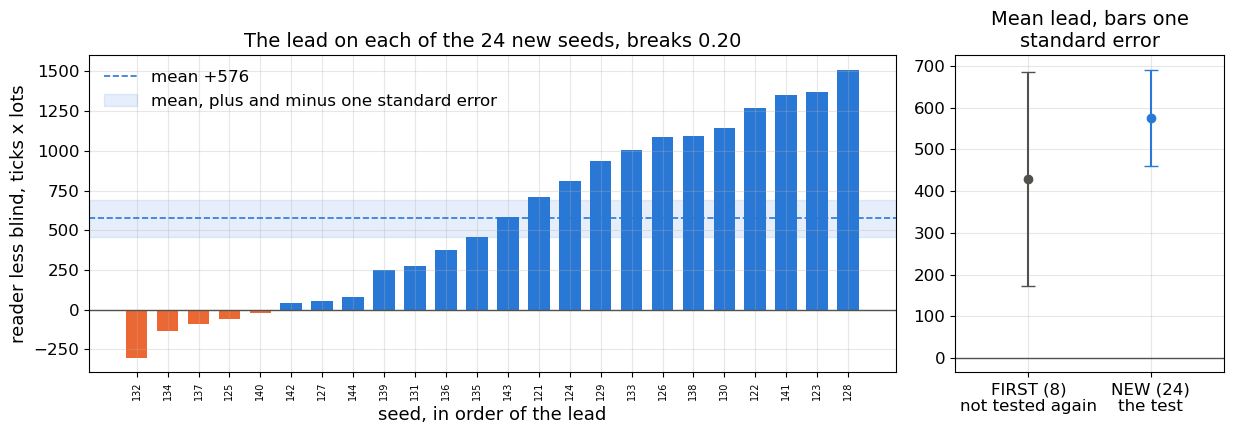


48 runs, 39.1 core-minutes.


In [4]:
# 1b. THE TEST, as written before the run (the cell above it says what is said in each outcome).
# The comparison: the reader out for a deal's life (quarantine 0) less the blind trader, at a true chance of a break of
# 0.20 (the price is 0.40), each on the pairs that market chose (one set for both: asserted), seed by seed, P&L after
# costs, on the seeds of NEW alone.
# The test: that lead is more than TEST_ERRORS standard errors above 0, the standard error being the standard
# deviation of the leads over the seeds (ddof 1) over the square root of their number. One-sided, because the
# direction was written down before notebook 15's first run. The cell prints t, the one-sided and the two-sided p on
# n - 1 degrees of freedom, and the seeds positive. FIRST is not tested again: it is notebook 15's.
TEST_ERRORS = 2.0
news_test_blind, news_test_reader = three_of(DEAL_CHEAP)[:2]
news_test_frame = run_rows(news_rows(DEAL_CHEAP, 0, 1), NEW, PAIRS_BURN, extra=news_read)
compared = news_checks(news_test_frame, [news_test_blind, news_test_reader], NEW)
print(
    f'Checked: on every one of the {len(NEW)} seeds the blind trader and the reader have the same deals ({compared} '
    "compared) and the same eight pairs, and the reader holds no deal's target.\n"
)

news_test_table = table_of(news_test_frame, also=('completed', 'broken', 'on')).loc[[news_test_blind, news_test_reader]]
print(f'Breaks {DEAL_CHEAP:.2f}, {len(NEW)} seeds, burn {PAIRS_BURN:,.0f}:\n')
print(
    shown(news_test_table, 'cost_an_entry', add=['completed', 'broken', 'on'], completed='.1f', broken='.1f', on='.1f')
)
print('\nThe reader less the blind trader, seed by seed:\n')
print(
    shown_paired(
        paired_table(
            news_test_frame,
            {f'{news_test_reader} less blind': (news_test_reader, news_test_blind)},
            'before_costs',
            'costs',
            'risk_adjusted_long',
        ),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)


def news_test_of(lead):
    # The test's figures for a lead, a value a seed: t over n - 1 degrees of freedom, the one-sided and two-sided p, the
    # seeds positive, the sign test (robustness) and whether it is more than TEST_ERRORS standard errors above 0.
    n, se = len(lead), se_of(lead)
    t, positive = lead.mean() / se, int((lead > 0).sum())
    return dict(
        n=n,
        df=n - 1,
        mean=lead.mean(),
        se=se,
        t=t,
        positive=positive,
        p_one=stats.t.sf(t, n - 1),
        p_two=2 * stats.t.sf(abs(t), n - 1),
        sign_p=stats.binomtest(positive, n, 0.5, alternative='greater').pvalue,
        met=bool(t > TEST_ERRORS),
    )


news_test_lead = lead_of(news_test_frame, news_test_reader, news_test_blind)  # a value a seed: what the test is about
news_test_result = news_test_of(news_test_lead)
r = news_test_result
assert abs(r['mean'] - paired(news_test_frame, news_test_reader, news_test_blind).mean) < 1e-9, (
    'paired() and the test differ'
)
print(
    f"\nTHE TEST. The reader's lead over the blind trader at breaks {DEAL_CHEAP:.2f}, on the {r['n']} seeds of NEW "
    f"({NEW[0]} to {NEW[-1]}), each on its own market's pairs:"
)
print(
    f"  lead {r['mean']:+,.1f} ticks x lots, standard error {r['se']:,.1f} (over the seeds), {r['positive']} of "
    f"{r['n']} seeds positive"
)
print(
    f"  t = {r['t']:.2f} on {r['df']} degrees of freedom; {news_p_text(r['p_one'])} one-sided (the direction written "
    f"down), {news_p_text(r['p_two'])} two-sided"
)
print(
    f"  the test, a lead more than {TEST_ERRORS:g} standard errors above 0: {'MET' if r['met'] else 'NOT MET'} "
    f"(t {r['t']:.2f})"
)
print(
    f"  for scale: t = {TEST_ERRORS:g} on {r['df']} degrees of freedom is p = {stats.t.sf(TEST_ERRORS, r['df']):.4f} "
    f"one-sided, {2 * stats.t.sf(TEST_ERRORS, r['df']):.4f} two-sided"
)
print(
    f"  as robustness, and not the test: the sign test of {r['positive']} positive of {r['n']}, one-sided p = "
    f"{r['sign_p']:.4f}"
)
print('\nThe lead on each seed, ticks x lots (seed: lead):')
print('  ' + ', '.join(f'{seed}: {x:+,.0f}' for seed, x in news_test_lead.items()))

# The figure: the lead seed by seed on NEW (the test), and its mean beside the first eight's (notebook 15's, reproduced
# above and not tested again). One y-axis a panel; the bars on the right are one standard error of the mean.
news_first_lead = lead_of(news_first_frame, news_test_reader, news_test_blind)
fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE_WIDE, gridspec_kw={'width_ratios': [3, 1]})
order = news_test_lead.sort_values()
left.bar(range(r['n']), order.to_numpy(), color=[BLUE if x > 0 else ORANGE for x in order], width=0.7)
left.axhline(0, color=GRAY, lw=1)
left.axhline(r['mean'], color=BLUE, lw=1.2, ls='--', label=f"mean {r['mean']:+,.0f}")
left.axhspan(
    r['mean'] - r['se'], r['mean'] + r['se'], color=BLUE, alpha=0.12, label='mean, plus and minus one standard error'
)
left.set_xticks(range(r['n']), [str(seed) for seed in order.index], rotation=90, fontsize=7)
left.set_xlabel('seed, in order of the lead')
left.set_ylabel('reader less blind, ticks x lots')
left.set_title(f"The lead on each of the {r['n']} new seeds, breaks {DEAL_CHEAP:.2f}")
left.legend(frameon=False, loc='upper left')
right.errorbar([0], [news_first_lead.mean()], yerr=[se_of(news_first_lead)], fmt='o', color=GRAY, capsize=5)
right.errorbar([1], [r['mean']], yerr=[r['se']], fmt='o', color=BLUE, capsize=5)
right.axhline(0, color=GRAY, lw=1)
right.set_xlim(-0.6, 1.6)
right.set_xticks([0, 1], [f'FIRST ({len(news_first_lead)})\nnot tested again', f"NEW ({r['n']})\nthe test"])
right.set_title('Mean lead, bars one\nstandard error')
fig.tight_layout()
plt.show()
print()
ran(news_test_frame)

**The test is met, and the first of the four outcomes holds.** The cell prints, for the reader's lead over the blind trader at breaks 0.20 on the 24 seeds of `NEW` (121 to 144), each on its own market's pairs: a lead of +575.5 ticks x lots, standard error 115.5 (over the seeds), 19 of 24 seeds positive; t = 4.98 on 23 degrees of freedom; p under 0.0001 one-sided (the direction written down) and p under 0.0001 two-sided; and "the test, a lead more than 2 standard errors above 0: MET (t 4.98)". For scale it prints t = 2 on 23 degrees of freedom as p = 0.0287 one-sided and 0.0574 two-sided, and, as robustness and not the test, the sign test of 19 positive of 24 at one-sided p = 0.0033. The lead is more than two standard errors above 0, so the first outcome text above is the one that holds; the other three stay above as they were written and none of them holds. Here is the first, with its blanks filled from the cell's lines:

> On the 24 seeds fixed before the run, the reader out for a deal's life led the blind trader by +575.5 (se 115.5, t 4.98 on 23 degrees of freedom, one-sided p under 0.0001, 19 of 24 seeds positive), more than the two standard errors the test asked for, on seeds that no market run of notebook 15 used. On its own pairs, at a true chance of a break of 0.20 where the price is 0.40, sitting out a deal's life paid a pairs trader after costs. What the lead is made of is for the secondaries to say: by the model's arithmetic it is the bet that the blind trader holds and the reader avoids, less what the reader gives up by being out, so what this shows is that avoiding an overpriced bet pays more than the trades it gives up cost, and not that the news says anything about the pairs. It is one premium of one simulated market, and the notebook has two values of the true chance and no line through them.

Every sentence is kept as it was written. The secondaries say what the lead is made of, and where they say more or less than the sentence did, they say so. The test shows that the lead is far from 0 in units of its own standard error. It does not show how large the lead is: a t of 4.98 is not a size, and a lead that has cleared a bar is on average larger than the true one. The pooled figure and the secondaries did not decide which outcome holds.

**Where the lead comes from, after costs.** The paired table prints the lead as +576 (se 116), made of +484 before costs (se 117) and a costs difference of -92 (se 19): the reader's costs are 92 lower than the blind trader's, 1,236 against 1,328 in the table of the two rows. So 92 of the +576 comes from lower costs and 484 from before them (the lead is the sum, 484 and 92), about 16% from the costs (a plain ratio of 92 to 576). "Before costs" is not an edge: a trader pays the costs on every order, and the test, the lead and every figure here are after them. The lead in `risk_adjusted_long` is +0.008 (se 0.001), the reader's 0.016 against the blind trader's 0.008.

**The two traders.** On `NEW` at 0.20 the blind trader makes +1,017 (se 243, 20 of 24 seeds positive) and the reader +1,593 (se 194, 23 of 24). The reader makes 126.8 entries a run against the blind trader's 131.2, trades 1,075 lots against 1,135, and holds 11.1 lots gross against 15.8: it trades a little less and holds a good deal less. The deals a run are 48.3 completed, 11.9 broken and 0.8 still on at the end, the same for the two traders, by construction: the cell checks that they have the same deals (1464 compared) and the same eight pairs on every seed, and that the reader holds no deal's target.

**The lead seed by seed.** Nineteen of the 24 leads are above 0 and five are below it: seeds 125 (-57), 132 (-305), 134 (-138), 137 (-88) and 140 (-24). The largest is +1,511 (seed 128) and the smallest is -305 (seed 132). The left panel of the figure shows the 24 in order, the five below 0 in orange, with the mean of +576 inside a band of one standard error. The per-seed standard deviation is the printed standard error times the square root of 24, 115.5 times 4.90, about 566 (plain arithmetic). The size of the test assumed about 740, so the spread is 174 smaller than planned (a plain difference). A smaller spread gives a smaller standard error and so a larger t for a lead of any size. The head expected a t of 2.84 for a true lead of the first eight's size, and the t of 4.98 comes from a lead that is larger than the first eight's +429 and a spread that is smaller than planned, both of which raise it. So the test could show more than the plan allowed for. The 566 is itself the spread of one draw of 24 seeds, and the test passing does not show that the spread is 566, or that a test on other seeds would pass by as much.

**The first eight beside the new 24.** The right panel shows the mean lead with a bar of one standard error for each group: `FIRST`, notebook 15's eight, at +429 (se 256, 5 of 8 seeds positive), which in notebook 15 was 1.7 standard errors from 0, and `NEW` at +576 (se 116, 19 of 24). The `NEW` mean is 147 above `FIRST`'s (a plain difference) with a bar less than half as wide, and the two bars overlap. Secondary (6) below prints the gap with its standard error. This is a picture and not a comparison, and `FIRST` is not tested again: its +429 is notebook 15's figure, reproduced in 1a, and it is plotted for reference. The test is on `NEW` alone.

### 1c. The Secondaries, in Their Declared Order

These six were declared before the run, in this order, and none is a test: the test was on the lead alone, and it has been reported. Each is paired by seed, with standard errors over seeds, and a t printed beside a lead is a ratio, not a p-value of a test, with no allowance for there being six. A secondary that is further from 0 than the test is not allowed to change which outcome holds. They are:

1. *The luck-adjusted lead.* The blind trader's bet is on how its deals end; add its luck back to the lead, which removes the part of the lead's spread that the deals' outcomes make.
2. *Where the lead is made.* The lead split into the targets' books while the deals are on and everywhere else, beside the bet's arithmetic from the blind trader's lots.
3. *The same two traders at 0.40*, the cost of reading where the bet is fair, expected below 0.
4. *On one set of pairs.* The blind trader and the reader on the pairs the market of 0.40 chose, traded in the market of 0.20, and the difference of leads across the two markets on that one set of pairs.
5. *The default reader at 0.20.*
6. *`FIRST` and `NEW` pooled*, 32 seeds, as an estimate and not the test.

A figure after the sixth shows them all in one picture. Section 2 reads the frames of 3 and 4 (its 2c compares the market's figure for "the pairs of 0.40 less the pairs of 0.20" on these seeds with the route with no order books), and the conclusions read the test's lead and the secondaries.

#### (1) The Luck-Adjusted Lead

A blind trader that holds a deal's target after the announcement is short it, on average, and has made a bet on how the deal ends: from just after the announcement, the target moves by the offer's premium times the price of a break (0.40: +24 ticks a lot, from the settings) if the deal completes, and by minus the premium times the price of a completion (0.60: -36) if it breaks, and it is expected to move by the gap between the two at the true chance, `premium x (priced - breaks)`, which is nothing at 0.40 and an edge at 0.20. Which way each deal goes is luck that the lead inherits, because the reader makes no such bet and the blind trader does. Its definition was fixed before the run:

- the deals that count are those notebook 15 counts for the bet (announced from the burn on and over by the run's end);
- for each, the lots of the target the blind trader held two decisions after the announcement (the first decision at or after it, and two more), times the move that happened, less the same lots times the move expected at the true chance of a break, summed over the deals: the blind trader's *luck* in a run;
- the luck-adjusted lead is the reader's lead plus the blind trader's luck of the same seed, since the lead is the reader's P&L less the blind trader's and the blind trader's P&L holds that luck. There is no coefficient to fit.

On seeds 1 to 8 this cut the variance of the lead at 0.20 to 0.66 of the plain lead's, the lead's correlation with the luck being -0.58, and at 0.40 to 0.27 (correlation -0.86). It is a control variate, and the cell prints how far it cuts the variance here. It is not exact: the lots are those at the second decision and are taken as held for the deal's life, and a deal that breaks within the first two decisions (a fraction of one percent of them) has its payoff from before the lots were held.

In [5]:
# 1c (1). The luck-adjusted lead, defined before the run. A blind trader that holds a deal's target two decisions after
# the announcement has made a bet on how the deal ends, whose payoff per lot is BET_UP at a completion and BET_DOWN at a
# break. Over the deals that count (announced from the burn on and over by the run's end), its luck in a run is the
# lots times the move that happened, less the lots times the move expected at the true chance of a break; and the
# luck-adjusted lead is the reader's lead plus the blind trader's luck of the same seed (the reader makes no such bet).
# The adjustment has no coefficient to fit: it is the luck itself, added back once.
expected_move = (1 - DEAL_CHEAP) * BET_UP + DEAL_CHEAP * BET_DOWN  # ticks a lot the target is expected to move
assert abs(expected_move - DEAL_PREMIUM * (DEAL_PRICED - DEAL_CHEAP)) < 1e-9, (
    "the expected move is not notebook 15's edge"
)
news_blind_runs = news_test_frame[news_test_frame.row == news_test_blind].set_index('seed').sort_index()
news_test_luck = news_luck(news_blind_runs, DEAL_CHEAP)
assert list(news_test_luck.index) == list(news_test_lead.index), 'the luck and the lead are not on the same seeds'
news_test_adjusted = news_test_lead + news_test_luck
expected_bet = -news_blind_runs.net_short * expected_move  # the arithmetic of the bet at the expected move, a seed each
# The arithmetic of the bet, a run: one variable, which this cell and the next print with one rounding. It is minus the
# edge times the mean net short lots, 61.7 x 12 = 740.5, a tie that the float noise of the two products (the expected
# move here is 12.000000000000004, the edge in the next cell 12.0) used to round to 741 here and to 740 in the next
# cell; the noise is rounded off at the sixth decimal, so that both print the same figure, in the same format.
news_bet_arithmetic = round(float(expected_bet.mean()), 6)
luck = news_test_luck
print(
    f'The blind trader at breaks {DEAL_CHEAP:.2f}, a run: {news_blind_runs.counted.mean():.1f} deals counted, '
    f'{news_blind_runs.net_short.mean():.1f} lots net short of their targets two decisions after the announcements; '
    f'the target is expected to move {expected_move:+.1f} ticks a lot, so the expected P&L of the bet is '
    f'{news_bet_arithmetic:+,.0f}, and its luck, what happened less that, is {said(luck)}; its standard deviation '
    f'over the seeds is {luck.std():.0f}.\n'
)
print(f"The reader's lead:            {said(news_test_lead)}")
print(f'The luck-adjusted lead:       {said(news_test_adjusted)}')
print(
    f"The lead's variance over the seeds is {news_test_lead.var():,.0f}; the luck-adjusted lead's is "
    f'{news_test_adjusted.var():,.0f}, {news_test_adjusted.var() / news_test_lead.var():.2f} of it (the correlation of '
    f'the lead with the luck is {news_test_lead.corr(luck):+.2f}).'
)
print(
    'The luck-adjusted lead is a secondary, declared in this order and not a second chance at the test: whatever it '
    'shows, the outcome of the test is the one above.'
)

The blind trader at breaks 0.20, a run: 38.9 deals counted, 61.7 lots net short of their targets two decisions after the announcements; the target is expected to move +12.0 ticks a lot, so the expected P&L of the bet is -740, and its luck, what happened less that, is -23 (se 76, t -0.30, 10 of 24 seeds positive); its standard deviation over the seeds is 372.

The reader's lead:            +576 (se 116, t 4.98, 19 of 24 seeds positive)
The luck-adjusted lead:       +553 (se 124, t 4.46, 18 of 24 seeds positive)
The lead's variance over the seeds is 320,333; the luck-adjusted lead's is 368,246, 1.15 of it (the correlation of the lead with the luck is -0.21).
The luck-adjusted lead is a secondary, declared in this order and not a second chance at the test: whatever it shows, the outcome of the test is the one above.


**The luck-adjusted lead did not cut the spread on these seeds.** The cell prints that the blind trader at 0.20 has, a run, 38.9 deals counted and 61.7 lots net short of their targets two decisions after the announcements, that the target is expected to move +12.0 ticks a lot, and so that the expected P&L of the bet is -740, the figure that the next cell prints too. The cell prints no standard error or standard deviation for this expected bet, only for the luck. The luck, what happened less that, is -23 (standard error 76, t -0.30, 10 of 24 seeds positive), with a standard deviation over the seeds of 372. The reader's lead is +576 (se 116, t 4.98, 19 of 24 seeds positive) and the luck-adjusted lead is +553 (se 124, t 4.46, 18 of 24). The lead's variance over the seeds is 320,333 and the luck-adjusted lead's is 368,246, which is 1.15 of it, and the correlation of the lead with the luck is -0.21. The head expected a cut, from seeds 1 to 8, where the variance ratio was 0.66 and the correlation -0.58. There is no cut here: on `NEW` at 0.20 the adjustment raised the variance, and with it the standard error, from 116 to 124.

It cut the spread elsewhere in this notebook. The standard error of the lead on `FIRST` falls from 256 to 126 (+429 and +440, in the pooled cell below), and at 0.40 on `NEW` from 153 to 105 (-454 and -419, in the cell for the cost of reading). So the adjustment cut the spread on `FIRST` and at 0.40 and did not cut it at the price and on the seeds of the test. The definition has no fitted coefficient: it adds the whole luck, whose own standard deviation, 372, enters the adjusted lead in full, and at a correlation of -0.21 that takes out less variance than it puts in. The premise review of the first run adds that the stand-in for the luck, the lots two decisions after the announcement, is a noisy measure of the luck on the lots the blind trader holds over a deal's life; no cell prints that luck or its noise (the review's measure of it is still not printed). The cell added after the first run prints the lots themselves: +1.60 (se 0.08, 24 of 24 seeds positive) net short at decision 2 after the announcement, the lots that the stand-in takes as held for the deal's life, and +1.89 (se 0.07, 24 of 24) over the deal's life weighted by the deal part, so the stand-in takes fewer lots than the blind trader holds. The notebook keeps the adjustment as it was declared before the run and says what it did.

What the adjusted lead's standard error says that the plain test did not is nothing: it is larger than the plain lead's (124 against 116), its t is smaller (4.46 against 4.98), and the estimate is 23 lower (a plain difference), so the lead is no better known for it. It is a secondary. It does not change which outcome of the test holds: the first holds on the plain lead, as the cell above reported.

**The luck was about nothing.** The blind trader's luck on the 24 seeds is -23 (se 76), 0.30 of its standard error from 0 (the printed t is -0.30), on 10 of 24 seeds positive, so its bet was neither lucky nor unlucky as far as 24 seeds can say. A luck below 0 for the blind trader inflates the reader's lead and a luck above 0 shrinks it. This luck would have inflated the plain lead by 23, which is the gap between +576 and the adjusted +553 (the adjusted lead is the lead plus the luck), and 23 is within the luck's own standard error of 76. The plain lead of +576 is therefore not shown to be flattered by an unlucky blind trader.

#### (2) Where the Lead Is Made, and the Bet's Arithmetic

The blind trader's bet in notebook 15's terms: of the deals announced in the span and over by its end, the cell prints how many it holds the target of two decisions after the announcement, on which side, the lots it holds then (a pair holds a few) and in all (net short), and the arithmetic of the bet, minus the edge times the net short lots, where the edge is `premium x (priced - breaks)` ticks a lot. That arithmetic is the model's, from lots the cell prints.

The split is measured. It divides the lead, seed by seed, into the P&L made in the targets' books while their deals are on, and everywhere else. The first is made, for each deal announced in the span and over by the run's end, from the lots held after each decision from the announcement to two units after the deal's end, times the move of the target's mid to the next decision, so it is at the decisions' mids and before the spread paid. The rest of the P&L, which is after the spread paid, is everywhere else: it holds the spread paid in those books too, the jump at an announcement on the lots held before it, the deals still on at the end, and every other book and time. The two parts are one lead split in two. The part in the targets' books is what the reader avoids, which the arithmetic of the bet prices; everywhere else is the empirical half, and holds the cost of reading.

The arithmetic and the split do not agree, even in expectation, and they are not an identity: the arithmetic counts the lots held two decisions after the announcement, as if they were held for the deal's life, and pays them from just after the announcement (and a deal may break before the second decision), whereas the blind trader's net short in a target grows as a deal goes on. A cell added after the first run, on a review of it, after the picture of the leads, measures the bet on the lots held over the deal's life; the text does not present the arithmetic and the split as an identity.

In [6]:
# 1c (2). Where the lead is made, beside the bet's arithmetic. The blind trader's side: of the deals announced in the
# span and over by its end, how many it holds the target of two decisions after the announcement, on which side, the
# lots it holds then (a pair holds a few) and in all (net short); and the arithmetic of the bet, -edge x net short lots,
# where the edge is the expected move a lot, DEAL_PREMIUM x (priced - breaks).
edge = DEAL_PREMIUM * (DEAL_PRICED - DEAL_CHEAP)
news_bet = pd.DataFrame(
    {
        'deals': news_blind_runs.counted.mean(),
        'held': news_blind_runs.held_n.mean(),
        'short': news_blind_runs.short_n.mean(),
        'long': news_blind_runs.long_n.mean(),
        'lots': news_blind_runs.mean_lots.mean(),
        'net_short': news_blind_runs.net_short.mean(),
        'edge': edge,
        'bet': news_bet_arithmetic,  # -edge x net short lots, the variable the cell above prints
    },
    index=pd.Index([DEAL_CHEAP], name='breaks'),
)
print(
    f'The blind trader at breaks {DEAL_CHEAP:.2f}, {len(NEW)} seeds, a run: deals announced in the span and over by '
    f'its end, '
    'how many it holds the target of two decisions after the announcement, on which side, the lots it holds then and '
    'in '
    'all (net short), and the arithmetic of the bet, -edge x net short lots.\n'
)
formats = {name: '{:.1f}'.format for name in ('deals', 'held', 'short', 'long', 'net_short', 'edge')}
print(news_bet.to_string(formatters={**formats, 'lots': '{:.2f}'.format, 'bet': '{:+,.0f}'.format}))
print(
    "\nThe lead, split by where the P&L was made: in the targets' books while their deals are on (for each deal "
    "announced "
    'in the span and over by its end: the lots held after each decision from the announcement to two units after the '
    "end, times the move of the target's mid to the next decision, at the decisions' mids and before the spread paid), "
    'and everywhere else (the P&L, which is after the spread paid, less that: so it holds the spread paid in those '
    'books too, the jump at an announcement on the lots held before it, the deals still on at the end, and the rest of '
    'the books and times):'
)
print(
    f'The reader less the blind trader, breaks {DEAL_CHEAP:.2f}: '
    f'{news_split(news_test_frame, news_test_reader, news_test_blind)}.'
)
news_split_inside = lead_of(news_test_frame, news_test_reader, news_test_blind, 'target_on')
print(
    f"\nThe lead in the targets' books less the bet avoided, {news_split_inside.mean():+,.0f} less "
    f"{-news_bet.bet.iloc[0]:+,.0f}: {news_split_inside.mean() + news_bet.bet.iloc[0]:+,.0f} (a plain difference). "
    f"The arithmetic "
    'is the model\'s, from the lots the blind trader holds and the edge; the split is measured. The arithmetic counts '
    'the lots held two decisions after the announcement, as if they were held for the deal\'s life and paid from just '
    'after the announcement (and a deal may break before the second decision); the cell added below, after the first '
    'run, measures the bet on the lots held over the deal\'s life.'
)

The blind trader at breaks 0.20, 24 seeds, a run: deals announced in the span and over by its end, how many it holds the target of two decisions after the announcement, on which side, the lots it holds then and in all (net short), and the arithmetic of the bet, -edge x net short lots.

       deals held short long lots net_short edge  bet
breaks                                               
0.2     38.9 25.3  22.4  2.9 3.01      61.7 12.0 -740

The lead, split by where the P&L was made: in the targets' books while their deals are on (for each deal announced in the span and over by its end: the lots held after each decision from the announcement to two units after the end, times the move of the target's mid to the next decision, at the decisions' mids and before the spread paid), and everywhere else (the P&L, which is after the spread paid, less that: so it holds the spread paid in those books too, the jump at an announcement on the lots held before it, the deals still on at the end, a

**The blind trader's side is short the target.** At 0.20 on `NEW` the blind trader has, a run, 38.9 deals announced in the span and over by its end. Two decisions after the announcement it holds the target of 25.3 of them, short in 22.4 and long in 2.9, 3.01 lots in each target it holds, and 61.7 lots net short of their targets in all. The edge is 12.0 ticks a lot, and the arithmetic of the bet, minus the edge times the net short lots, is -740 a run. In the plain terms of the paragraph above, a blind pairs trader that holds a pair with the target finds the pair's spread far above its window after the announcement and so is short the target, the side of the deal trader's counterparty, and the counts say that it is: short in 22.4 of the 25.3 deals it holds a target of. The arithmetic takes the lots at the second decision as held for the deal's life, and the blind trader's net short in a target grows as the deal goes on, so it understates the bet. The cell added after the first run, on a review of it, counts the lots actually held and prints the expected bet at -886 a run (se 39, t -22.54, 0 of 24 seeds positive; 24 of 24 below 0) on these pairs, 146 from the arithmetic's -740 and 1.20 times it (a plain difference and a plain ratio, as that cell prints them).

**The split.** The cell prints the reader less the blind trader at 0.20, split by where the P&L was made: in the targets' books while the deals are on, +829 (se 134, t 6.19, 21 of 24 seeds positive), and everywhere else, -254 (se 126, t -2.02, 10 of 24 seeds positive). The two parts add to the lead, +575.5 (+576 in the table). The line below them is the lead in the targets' books less the bet avoided, +829 less +740: +89 (a plain difference), 0.7 of the books part's standard error of 134 (a plain ratio). So the targets' books carry the bet that the reader does not hold, and 89 more than the printed arithmetic gives. The books part is 6.19 standard errors above 0 and everywhere else is 2.02 standard errors below 0 (the printed t's, which are ratios and not tests, with no allowance for how many are printed in this section). Everywhere else is negative: outside the targets' books while the deals are on, the reader is behind the blind trader by 254, 31% of the 829 it gains in them (a plain ratio).

What the split shows is where the lead was made, and not a split of the lead into a bet and a cost of reading. Everywhere else holds the spread paid in the targets' books as well, the jump at an announcement on the lots held before it, the deals still on at the end and every other book and time, so the -254 is not read as the cost of reading. The cell added after the first run measures the cost of reading on the lots held, the lead less the deal part that the reader avoids: -335 (se 103, t -3.25, 6 of 24 seeds positive) at 0.20 on these pairs, and -350 (se 88, t -3.98, 4 of 24) at 0.40 on its own pairs. This cell's last sentence says that the arithmetic counts the lots held two decisions after the announcement, as if they were held for the deal's life, and that the cell added below measures the bet over the deal's life. The arithmetic and the split are not an identity and do not agree in expectation: the arithmetic understates the bet, as above, so the +89 is smaller than the arithmetic's shortfall (146) and is not a second source of the lead, and the split is measured where the arithmetic is the model's. The notebook does not present them as an identity.

**Against notebook 15's split on `FIRST`.** In notebook 15 the reader's lead on `FIRST`, +429 (se 256), was +693 (se 295, 7 of 8 seeds positive) in the targets' books against a bet's arithmetic of 694, and -264 (se 201, 2 of 8) everywhere else. On `NEW` the part in the targets' books is 136 higher (+829 against +693), the printed arithmetic 46 higher (740 against 694) and the part everywhere else 10 higher (-254 against -264), all plain differences. These are two groups of seeds, and the comparison tests nothing. The shape is the same on both: the targets' books carry about the bet the blind trader holds, and the rest of the lead is negative.

#### (3) The Same Two Traders at a True Chance of 0.40

At 0.40 the price is the true chance, the edge is 0, and the blind trader's bet has no expected P&L: the reader has no bet to avoid, and still sits out every deal's life. So the reader's lead over the blind trader here is the cost of reading where the bet is fair, what it gives up in the targets' books. It is expected below 0, and it was below 0 on both eights it has been seen on, on seeds 1 to 8 (-387, se 196, 2 of 8 seeds positive) and in notebook 15 on `FIRST`. The cell prints the one-sided p of a lead this low or lower as a description, not as a test. The luck-adjusted lead at 0.40 is printed too: the blind trader's luck at 0.40 has an expected bet of 0, and on seeds 1 to 8 it cut the lead's variance to 0.27 of the plain lead's.

The lead at 0.20 on `NEW` is the test's; the difference between the lead at 0.20 and the lead at 0.40 is the bet avoided, once the pairs are the same, and is for the next secondary. These 48 runs are on the two markets' own pairs, and the 0.40 market's pairs chosen here are the ones the next secondary hands to the traders of the 0.20 market.

In [7]:
# 1c (3). The same two traders at breaks 0.40, where the price is the true chance and the bet is fair. A reader sits out
# a deal's life and gives up what the pair would have made in the target's books, and has no bet to avoid: this lead is
# the cost of reading, and is expected below 0. It is a row of the section's table of secondaries, not a test.
news_fair_blind, news_fair_reader = three_of(DEAL_FAIR)[:2]
news_fair_frame = run_rows(news_rows(DEAL_FAIR, 0, 1), NEW, PAIRS_BURN, extra=news_read)
compared = news_checks(news_fair_frame, [news_fair_blind, news_fair_reader], NEW)
news_both_dials = pd.concat([news_test_frame, news_fair_frame], ignore_index=True)
check_deals(news_both_dials, [news_test_blind, news_fair_blind])  # the same deals at both values of breaks, nested
print(
    f'Checked: the same deals ({compared} compared) and the same eight pairs for the two traders on every seed, no '
    "reader holding a deal's target, and the deals that break at 0.20 break at 0.40.\n"
)
assert abs((1 - DEAL_FAIR) * BET_UP + DEAL_FAIR * BET_DOWN) < 1e-9, 'a fair price should leave no expected move'

news_fair_table = table_of(news_fair_frame, also=('completed', 'broken', 'on')).loc[[news_fair_blind, news_fair_reader]]
print(f'Breaks {DEAL_FAIR:.2f}, {len(NEW)} seeds, burn {PAIRS_BURN:,.0f}:\n')
print(
    shown(news_fair_table, 'cost_an_entry', add=['completed', 'broken', 'on'], completed='.1f', broken='.1f', on='.1f')
)
print('\nThe reader less the blind trader, seed by seed:\n')
print(
    shown_paired(
        paired_table(
            news_fair_frame,
            {f'{news_fair_reader} less blind': (news_fair_reader, news_fair_blind)},
            'before_costs',
            'costs',
            'risk_adjusted_long',
        ),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)
news_fair_lead = lead_of(news_fair_frame, news_fair_reader, news_fair_blind)
news_fair_blind_runs = news_fair_frame[news_fair_frame.row == news_fair_blind].set_index('seed').sort_index()
news_fair_adjusted = news_fair_lead + news_luck(news_fair_blind_runs, DEAL_FAIR)
t_fair = news_fair_lead.mean() / se_of(news_fair_lead)
print(f'\nThe cost of reading, the reader less the blind trader at breaks {DEAL_FAIR:.2f}: {said(news_fair_lead)}')
print(
    f'  expected below 0 (one-sided p of a lead this low or lower, on {len(news_fair_lead) - 1} degrees of freedom: '
    f'{stats.t.cdf(t_fair, len(news_fair_lead) - 1):.4f}); a description, not a test'
)
print(f'The same, luck-adjusted (the blind trader\'s luck, from its lots, added back): {said(news_fair_adjusted)}')
print(
    f'The blind trader at breaks {DEAL_FAIR:.2f}, a run: {news_fair_blind_runs.counted.mean():.1f} deals counted, '
    f'{news_fair_blind_runs.net_short.mean():.1f} lots net short; the edge is 0, so the arithmetic of the bet is 0.'
)
print()
ran(news_fair_frame)

Checked: the same deals (1464 compared) and the same eight pairs for the two traders on every seed, no reader holding a deal's target, and the deals that break at 0.20 break at 0.40.

Breaks 0.40, 24 seeds, burn 10,465:

                                     pnl  se  positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                                
blind, breaks 0.40                +2,075 188  23 of 24        3,460 1,385   137.5 1,192       1.16  14.6     3.97      7.62           7.52         0.014              0.015         -44 +2,119      36.1   24.2 0.7
reader, quarantine 0, breaks 0.40 +1,621 144  23 of 24        2,875 1,254   125.8 1,069       1.17  10.1     3.34      5.25           5.47     

**The cost of reading is below 0, as expected.** Where the price is fair, the reader less the blind trader is -454 (standard error 153, t -2.97, 8 of 24 seeds positive), on each trader's own pairs. The cell prints the one-sided p of a lead this low or lower, on 23 degrees of freedom, as 0.0034, as a description and not a test: the lead is 2.97 standard errors below 0 (the printed t), and it was below 0 on the two eights it had been seen on, -387 (se 196) on seeds 1 to 8 and -119 (se 217) on `FIRST`. The paired table splits it as -585 before costs (se 169) and -131 in costs (se 28): the reader gives up 585 before costs and its costs are 131 lower, which gives back part of it. Its `risk_adjusted_long` is higher by +0.002 (se 0.001), 0.017 against 0.015, because it holds less risk (a `deviation_long` of 5.47 against 7.52). The two rows show what reading gives up: the blind trader makes +2,075 (se 188, 23 of 24 seeds positive) and the reader +1,621 (se 144, 23 of 24), and the reader makes 125.8 entries a run against 137.5 and holds 10.1 lots gross against 14.6. The deals a run, 36.1 completed, 24.2 broken and 0.7 on, are the same for both.

**The luck-adjusted lead at 0.40 moves it little and cuts its standard error.** The adjusted lead is -419 (se 105, t -4.00, 5 of 24 seeds positive) against the plain -454 (se 153, t -2.97, 8 of 24). The estimate moves by 35 (a plain difference), under a quarter of the plain lead's standard error, and the standard error falls from 153 to 105, so here the adjustment cut the spread as it was meant to, which it did not at 0.20. The blind trader's expected bet at 0.40 is 0 (the cell prints 72.8 lots net short and an edge of 0), so what the adjustment adds back is the luck of how its deals ended, and by this adjustment most of the cost of reading is not luck. The adjustment's stand-in for the luck is noisy, though (the review's measure of that noise is not printed), and the cell added after the first run, which measures the cost of reading on the lots the blind trader actually held, prints it at -350 (se 88, t -3.98, 4 of 24 seeds positive) at 0.40 on these pairs: the lead of -454 less the deal part that the reader avoids, which is -104 here, the blind trader's realized +104 (se 128) with its sign turned. The notebook quotes -454 as printed and -419 as the declared adjustment gives it, and does not take either for the cost of reading with the luck taken out exactly; the -350 is a measure on the lots held, with a limit of its own (the deal part holds some ordinary reversion, which that cell does not measure: the review put it at about 100 a run from the route on `PAPER`, and the route's sets carry +161 and +232 on `NEW`'s own seeds where the bet is 0; if the reader gives it up too, the cost at 0.40 lies between -350 and -454).

**What the two leads say together.** On each market's own pairs the reader is ahead of the blind trader where a break is overpriced, +576 (se 116, 19 of 24 seeds positive) at 0.20, and behind it where the price is fair, -454 (se 153, 8 of 24) at 0.40: the sign changes with the dial. These are two paired differences, each within one market, and their difference, +1,030 (the plain difference of 576 and -454, which secondary (4) below prints with its standard error), is taken across two markets whose pairs are different sets, because each trader chose its pairs from its own market's mids. So it is not like for like, and the next secondary takes the same difference on one set of pairs.

#### (4) The Same Pairs in the Other World

A pairs trader chooses its eight pairs once, from the mids of its own market, at the end of its formation, and the markets of the two values of the true chance differ by then: the deals that complete in one break in the other, and the mids follow the fair values. So a trader's row at 0.20 against its row at 0.40 is not one trader on one set of pairs: the cell prints how many of the eight pairs the blind trader chose in the two markets have in common, by seed, and the difference of leads across 0.20 and 0.40 on each market's own pairs is not like for like.

This cell holds the pairs fixed. It trades the market of 0.20 with the pairs that the trader of the same seed chose in the market of 0.40: the whole rows of weights, each pair's hedge included, handed to the trader by a chooser that returns them whatever history it is shown, so that it chooses nothing. The blind trader and the reader out for the deal's life each get them on every seed of `NEW`: 48 runs. The two traders of a seed chose the same rows at 0.40, which the cell asserts, so each is given the same ones.

A check that the chooser makes no difference of its own runs the blind trader in the market of 0.40 with its own 0.40 pairs handed to the same chooser, and asserts that its P&L, lots and entries are those of its row in the table of the cost of reading, to the last digit. It is run on the first eight seeds of `NEW` and not on all 24, so that it costs 8 runs and not 24, a third of the cost: the chooser's behavior does not depend on the seed, and the other 48 runs each assert that they trade the rows they were handed. The line `CHECK_SEEDS = NEW[:8]` in the cell is the one to change to check all 24.

The cell prints the two rows on the other market's pairs; each less its own row at 0.40 (the pairs held and the chance lower: for the blind trader the bet, for a reader about nothing); each less its own row at 0.20 on the pairs it chose there (what the pairs of 0.40 were worth more than those); the reader less the blind trader on the same pairs; and the difference of those leads across 0.20 and 0.40, once on the 0.40 pairs in both (one set of pairs) and once on each market's own pairs (two sets: not like for like, kept for the comparison with notebook 15's). It splits each comparison by where the P&L was made, as the cell above does. The rows on the other market's pairs are **controls, not a trader's choice**: a trader in the market of 0.20 cannot hold the pairs of 0.40, and their levels are not what a trader makes there.

In [8]:
# 1c (4). The same pairs in the other world. Each trader's eight pairs are chosen once, from the mids of its own
# market, and the markets of the two values of breaks differ by then, so the two markets' pairs are two sets (the
# review's count: about two of the eight differ). Here the market of breaks 0.20 is traded with the pairs that the
# trader of the same seed chose at breaks 0.40, the whole rows of weights, hedges included, handed over by a chooser
# that returns them whatever history it is shown, to the blind trader and to the reader out for a deal's life: 2 runs
# a seed, on every seed of NEW. Section 2 reads this frame.
CHECK_SEEDS = NEW[:8]  # where the chooser itself is checked, below: 1 run a seed
news_chosen = {}
for seed, runs in news_fair_frame.groupby('seed'):
    assert runs.weights.nunique() == 1, f'seed {seed}: the two traders did not choose the same rows of weights'
    news_chosen[int(seed)] = runs.weights.iloc[0]
assert sorted(news_chosen) == sorted(NEW), 'the table above has not every seed of NEW at breaks 0.40'

news_same_blind, news_same_reader = (f'{row}{SAME}' for row in three_of(DEAL_CHEAP)[:2])
news_check_row = (
    f'{news_fair_blind}, its pairs handed over'  # the blind trader at 0.40, its own pairs handed to the chooser
)
jobs = []
for i, name in enumerate((news_same_blind, news_same_reader)):
    market_cheap, maker = pairs_row(DEAL_CHEAP, NEWS_KINDS[i][0], **NEWS_KINDS[i][1])
    jobs += [(name, market_cheap, partial(maker, choose=Fixed(news_chosen[s])), s) for s in NEW]
market_fair, maker = pairs_row(DEAL_FAIR, RelationTrader)
jobs += [(news_check_row, market_fair, partial(maker, choose=Fixed(news_chosen[s])), s) for s in CHECK_SEEDS]
runs = Parallel(n_jobs=-1)(
    delayed(run_one)(make_fair, make_trader, seed, PAIRS_BURN, SPAN, news_read)
    for _, make_fair, make_trader, seed in jobs
)
news_same_frame = pd.DataFrame([{'row': name, **run} for (name, *_), run in zip(jobs, runs, strict=True)])
assert not (news_same_frame.warm_up > PAIRS_BURN).any(), 'the burn cuts into the warm-up'
assert (news_same_frame.pushed == 0).all(), "a run's fair values were pushed off their floor"

# How far the two markets' pairs are the same set: the pairs in common between the blind trader's eight at the two
# values of breaks, by seed (a pair is the books it holds, whatever its hedge).
pairs_cheap = news_test_frame[news_test_frame.row == news_test_blind].set_index('seed').pairs
pairs_fair = news_fair_frame[news_fair_frame.row == news_fair_blind].set_index('seed').pairs
news_in_common = [len(set(pairs_cheap[seed]) & set(pairs_fair[seed])) for seed in NEW]
print(f"Pairs in common between the blind trader's eight at the two values of breaks, by seed: {news_in_common}.\n")

# What must hold for the table to mean anything: every run trades the rows it was handed; the deals are those of the
# runs above at the same value of breaks; no reader holds a deal's target; and the chooser makes no difference of its
# own.
for run in news_same_frame.itertuples():
    assert run.weights == news_chosen[run.seed], f'{run.row}, seed {run.seed}: not the rows it was handed'
same_two = [news_same_blind, news_same_reader]
check_deals(news_same_frame, same_two)
check_deals(news_same_frame, same_two[::-1])
news_both_worlds = pd.concat([news_test_frame, news_fair_frame, news_same_frame], ignore_index=True)
check_deals(
    news_both_worlds[news_both_worlds.row.isin([news_test_blind, news_same_blind])], [news_test_blind, news_same_blind]
)  # the 0.20 market's
on_check = news_both_worlds[news_both_worlds.seed.isin(CHECK_SEEDS)]
check_deals(
    on_check[on_check.row.isin([news_fair_blind, news_check_row])], [news_fair_blind, news_check_row]
)  # and the 0.40 market's
caught = news_same_frame[news_same_frame.row.str.startswith('reader') & (news_same_frame.held_on > 0)]
assert caught.empty, (
    f"a reader held lots of a deal's target: {list(zip(caught.row, caught.seed, caught.held_on, strict=True))}"
)
own_row = news_fair_frame[news_fair_frame.row == news_fair_blind].set_index('seed')
handed = news_same_frame[news_same_frame.row == news_check_row].set_index('seed')
own_there = own_row.loc[handed.index]
assert (handed.pnl == own_there.pnl).all(), (
    f'the handed-over pairs do not reproduce the 0.40 row: {(handed.pnl - own_there.pnl).to_dict()}'
)
assert (handed.lots == own_there.lots).all() and (handed.entries == own_there.entries).all(), 'lots or entries differ'
print(
    f"Checked: every run trades the rows it was handed, the market's deals are those of the runs above, no reader "
    f"holds a "
    f'deal\'s target; and the blind trader at breaks {DEAL_FAIR:.2f} with its own pairs handed to the chooser makes '
    f'the '
    f'P&L, the lots and the entries of its own row to the last digit on all {len(handed)} seeds it was run on.\n'
)

news_same_table = table_of(news_same_frame[news_same_frame.row.isin(same_two)], also=('completed', 'broken', 'on'))
print(
    f'The market of breaks {DEAL_CHEAP:.2f} traded with the pairs that the trader of the same seed chose at breaks '
    f'{DEAL_FAIR:.2f}, {len(NEW)} seeds, burn {PAIRS_BURN:,.0f}:\n'
)
print(
    shown(
        news_same_table.loc[same_two],
        'cost_an_entry',
        add=['completed', 'broken', 'on'],
        completed='.1f',
        broken='.1f',
        on='.1f',
    )
)
news_blind_same = news_same_frame[news_same_frame.row == news_same_blind].sort_values('seed')
news_edge_same = DEAL_PREMIUM * (DEAL_PRICED - DEAL_CHEAP)
same = news_blind_same  # the blind trader's rows on the pairs held, a line a seed
print(
    f'\nThe blind trader on the pairs of breaks {DEAL_FAIR:.2f} in the market of breaks {DEAL_CHEAP:.2f}, a run: it '
    f'holds the target of {same.held_n.mean():.1f} of the {same.counted.mean():.1f} deals announced in the span and '
    f'over by its end, two decisions after the announcement ({same.short_n.mean():.1f} short, '
    f'{same.long_n.mean():.1f} long), {same.net_short.mean():.1f} lots net short in all; with an edge of '
    f'{news_edge_same:.1f} ticks a lot the arithmetic of the bet, -edge x net short lots, is '
    f'{-news_edge_same * same.net_short.mean():+,.0f}.'
)

# Each trader on the other world's pairs, against the same trader in each of the two tables above.
own_fair, own_cheap, same_of = three_of(DEAL_FAIR)[:2], three_of(DEAL_CHEAP)[:2], same_two
paired_columns = ('before_costs', 'costs', 'risk_adjusted_long')


def print_paired(title, pairs):
    print(title)
    print(shown_paired(paired_table(news_both_worlds, pairs, *paired_columns), *paired_columns))


print_paired(
    f'\nEach trader on the pairs of breaks {DEAL_FAIR:.2f} in the market of breaks {DEAL_CHEAP:.2f}, less its own '
    f'row at '
    f'breaks {DEAL_FAIR:.2f}, seed by seed (the pairs held, the chance of a break lower):\n',
    {
        f'{w}, breaks {DEAL_CHEAP:.2f} less {DEAL_FAIR:.2f}': (s, o)
        for w, s, o in zip(WHO[:2], same_of, own_fair, strict=True)
    },
)
print_paired(
    f'\nEach less its own row at breaks {DEAL_CHEAP:.2f}, on the pairs it chose there (what the pairs of '
    f'{DEAL_FAIR:.2f} '
    'were worth more than those):\n',
    {
        f'{w}, pairs of {DEAL_FAIR:.2f} less its own': (s, o)
        for w, s, o in zip(WHO[:2], same_of, own_cheap, strict=True)
    },
)
print_paired(
    f'\nThe reader less the blind trader, on the same pairs, at breaks {DEAL_CHEAP:.2f}:\n',
    {f'{READER_0} less blind': (news_same_reader, news_same_blind)},
)

# The difference of leads across the two worlds, on one set of pairs and on two. The lead at 0.20 on the pairs of
# 0.40, less the lead at 0.40 (which is on the pairs of 0.40): one set of pairs in both. The lead at 0.20 on its own
# pairs, less the same: two sets, which differ, so that it is not like for like.
news_same_lead = lead_of(news_both_worlds, news_same_reader, news_same_blind)
news_did_same = news_same_lead - news_fair_lead
news_did_own = news_test_lead - news_fair_lead
print(
    f'\nReader less blind, at {DEAL_CHEAP:.2f} less at {DEAL_FAIR:.2f}, on the pairs of {DEAL_FAIR:.2f} in both: '
    f'{said(news_did_same)}'
)
print(f'The same on each world\'s own pairs (two sets of pairs, so not like for like): {said(news_did_own)}')
print(
    f'The bet the blind trader bears on the pairs held and the reader does not, from its lots, is '
    f'{news_edge_same * news_blind_same.net_short.mean():+,.0f} '
    f'a run (the arithmetic above, with its sign turned): the shift of the lead across the two values of breaks is '
    f'expected near it, and the reader at 0.40 has no bet to avoid.'
)

# The same comparisons split by where the P&L was made (news_split is defined above): the targets' books while their
# deals are on, and everywhere else.
print(
    "\nThe same comparisons split by where the P&L was made: in the targets' books while their deals are on (for "
    "each deal "
    'announced in the span and over by its end: the lots held after each decision from the announcement to two units '
    "after the end, times the move of the target's mid to the next decision, at the decisions' mids and before the "
    'spread paid), and everywhere else (the P&L, which is after the spread paid, less that: so it holds the spread '
    'paid '
    'in those books too, the jump at an announcement on the lots held before it, the deals still on at the end, and '
    'the '
    'rest of the books and times):'
)
for w, s, o in zip(WHO[:2], same_of, own_fair, strict=True):
    print(
        f'{w}, pairs of {DEAL_FAIR:.2f}, breaks {DEAL_CHEAP:.2f} less {DEAL_FAIR:.2f}: '
        f'{news_split(news_both_worlds, s, o)}.'
    )
for w, s, o in zip(WHO[:2], same_of, own_cheap, strict=True):
    print(
        f'{w}, pairs of {DEAL_FAIR:.2f} less its own pairs at breaks {DEAL_CHEAP:.2f}: '
        f'{news_split(news_both_worlds, s, o)}.'
    )
print(
    f'{READER_0} less blind, on the pairs of {DEAL_FAIR:.2f} at breaks {DEAL_CHEAP:.2f}: '
    f'{news_split(news_both_worlds, news_same_reader, news_same_blind)}.'
)
print()
ran(news_same_frame)

Pairs in common between the blind trader's eight at the two values of breaks, by seed: [8, 5, 7, 4, 6, 5, 5, 4, 5, 7, 6, 4, 8, 7, 7, 7, 2, 5, 5, 6, 4, 6, 7, 5].

Checked: every run trades the rows it was handed, the market's deals are those of the runs above, no reader holds a deal's target; and the blind trader at breaks 0.40 with its own pairs handed to the chooser makes the P&L, the lots and the entries of its own row to the last digit on all 8 seeds it was run on.

The market of breaks 0.20 traded with the pairs that the trader of the same seed chose at breaks 0.40, 24 seeds, burn 10,465:

                                                           pnl  se  positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                  

**The chooser changes nothing but the pairs.** The cell's check line says that the blind trader at 0.40 with its own pairs handed to the chooser made the P&L, the lots and the entries of its own row to the last digit on all 8 seeds it was run on (the first eight of `NEW`, as the head says), and that every run traded the rows it was handed, the market's deals are those of the runs above, and no reader held a deal's target.

**With the pairs held, a lower chance of a break costs the blind trader about its bet and the reader about nothing.** On the pairs of 0.40, the blind trader in the market of 0.20 makes -1,020 (standard error 115, 1 of 24 seeds positive) less than its own row at 0.40: before costs -1,050 (se 122) and costs -30 (se 21). It holds the target of 25.2 of the 38.9 deals two decisions after the announcement (22.6 short, 2.6 long) and 67.2 lots net short in all, and the arithmetic of the bet, at an edge of 12.0 ticks a lot, is -807 a run. The fall is 213 more than that (a plain difference), 1.9 of its standard error (a plain ratio). By the split, the fall in the targets' books while the deals are on is -1,026 (se 135, t -7.58, 1 of 24 seeds positive), 219 from the arithmetic's 807 (a plain difference, 1.6 of its standard error), and everywhere else it is +6 (se 81, t 0.08, 12 of 24), nothing. The printed arithmetic understates the bet, for the reason given with the split above: the cell added after the first run, on a review of it, prints the expected bet with the lots actually held on these pairs at -942 (se 33, t -28.30, 0 of 24 seeds positive; 24 of 24 below 0) a run, 135 from the arithmetic's -807 and 1.17 times it (as that cell prints them), and 78 from the fall of -1,020 (a plain difference of two printed figures). The reader's row changes by -36 (se 51, 12 of 24 seeds positive), about nothing: it holds none of a deal's target while the deal is on, and its part in the targets' books is +3 (se 3) and everywhere else -39 (se 52).

**What the pairs of 0.40 were worth in the market of 0.20.** Each trader on the pairs of 0.40, less its own row at 0.20 on the pairs it chose there, is +38 (se 177, 11 of 24 seeds positive) for the blind trader, with +64 before costs (se 197) and +27 in costs (se 38), and -8 (se 120, 11 of 24) for the reader, with +16 before costs (se 145) and +24 in costs (se 38). Neither is separated from 0: 38 against a standard error of 177, and -8 against 120. By the split, the blind trader's +38 is +32 (se 93, 15 of 24) in the targets' books while the deals are on and +6 (se 153, 8 of 24) everywhere else, and the reader's -8 is -2 (se 4, 13 of 24) and -6 (se 120, 12 of 24). The two traders of a seed share their pairs, so the two rows are one comparison seen twice and not two comparisons. These are the figures that section 2 reads on these seeds: its 2c sets the market's +38 beside the route with no order books. Notebook 15's on `FIRST` were +446 (se 143, 7 of 8 seeds positive) for the blind trader and +635 (se 242, 7 of 8) for the reader, so `NEW`'s are 408 and 643 lower (plain differences). These are two groups of seeds and the comparison tests nothing, but the new seeds do not show what notebook 15 found for the pairs of 0.40 in the market of 0.20.

**The reader less the blind trader on the same pairs, and the shift of the lead across the two markets.** On the pairs of 0.40 held in the market of 0.20, the reader leads the blind trader by +530 (se 103, 22 of 24 seeds positive), with +436 before costs (se 113) and -95 in costs (se 21), and a `risk_adjusted_long` of +0.008 (se 0.001). The difference of leads across 0.20 and 0.40 is +984 (se 125, t 7.88, 24 of 24 seeds positive) on the pairs of 0.40 in both markets, one set of pairs, and +1,030 (se 165, t 6.25, 22 of 24) on each world's own pairs, two sets. The first is like for like and the second is not. The bet's arithmetic on the pairs held is 807 a run with its sign turned, and the shift on one set of pairs is 177 above it (a plain difference), 1.4 of its standard error (a plain ratio): about the bet, as in notebook 15, where the shift on `FIRST` was +737 (se 202, 7 of 8 seeds positive) against an arithmetic of 873, 136 below it. By the split the shift is +1,029 in the targets' books (the reader's +3 less the blind trader's -1,026) and -45 everywhere else (the reader's -39 less the blind trader's +6), plain differences of printed parts that add to the +984. So the shift is made in the targets' books. The 177 by which it exceeds the printed arithmetic is not a second source of the lead: the arithmetic understates the bet, and the bet on the lots actually held, -942 (printed by the cell added after the first run), is 42 from the shift (a plain difference). That cell splits the shift into +995 (se 123, t 8.11, 23 of 24 seeds positive), the difference of the deal part that the blind trader realizes (avoided at 0.20 less at 0.40), and -11 (se 71, t -0.16, 11 of 24), the difference of the cost of reading, which is what is left.

**What these are not.** A trader in the market of 0.20 cannot choose the pairs of 0.40, which were chosen from another market's mids, so the rows on them are controls and not a trader's choice, and their levels are not what a trader makes there. The reader's lead on them, +530, is not the answer to the section's question, which is the test on a trader's own pairs, +575.5 above. What the rows are for is to hold the pairs fixed, so that with them held a lower chance of a break moves the blind trader by about its bet and the reader by about nothing.

#### (5) The Default Reader at 0.20

The reader at its default quarantine stays out of a deal's target for a window of decisions after the deal's end as well as for the deal's life, so that when it trades again the window holds no decision from before the deal's end and the step of the target's level has left it. It is the longer quarantine of the two readers, and in notebook 15 it cost a good deal where the price is fair (-692 at 0.40 on `FIRST`) and was not separated from the blind trader where a break is overpriced. It is 24 runs on `NEW` at 0.20, on the pairs of the blind trader and of the other reader, which the cell asserts, and the table prints it beside them. It is a secondary: the pre-declared question is whether its lead at 0.20 is anything, and not a second chance at the test.

In [9]:
# 1c (5). The default reader at breaks 0.20: a reader that also stays out of a deal's target for a quarantine of one
# window of decisions after the deal's end, so that the step has left its window when it trades again. 1 run a seed on
# NEW; its pairs are the blind trader's and the other reader's, which is asserted.
news_default_row = three_of(DEAL_CHEAP)[2]
news_default_frame = run_rows(news_rows(DEAL_CHEAP, 2), NEW, PAIRS_BURN, extra=news_read)
news_three = pd.concat([news_test_frame, news_default_frame], ignore_index=True)
compared = news_checks(news_three, three_of(DEAL_CHEAP), NEW)
print(
    f'Checked: the same deals ({compared} compared) and the same eight pairs for the three traders on every seed, '
    f'and no '
    "reader holding a deal's target or in its quarantine.\n"
)
news_three_table = table_of(news_three, also=('completed', 'broken', 'on')).loc[three_of(DEAL_CHEAP)]
print(f'Breaks {DEAL_CHEAP:.2f}, {len(NEW)} seeds, burn {PAIRS_BURN:,.0f}:\n')
print(
    shown(news_three_table, 'cost_an_entry', add=['completed', 'broken', 'on'], completed='.1f', broken='.1f', on='.1f')
)
print('\nThe default reader less the blind trader, and less the reader out for the deal, seed by seed:\n')
print(
    shown_paired(
        paired_table(
            news_three,
            {
                f'{news_default_row} less blind': (news_default_row, news_test_blind),
                f'{news_default_row} less {READER_0}': (news_default_row, news_test_reader),
            },
            'before_costs',
            'costs',
            'risk_adjusted_long',
        ),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)
news_default_lead = lead_of(news_three, news_default_row, news_test_blind)
print(f'\nThe default reader less the blind trader, breaks {DEAL_CHEAP:.2f}: {said(news_default_lead)}')
print()
ran(news_default_frame)

Checked: the same deals (1464 compared) and the same eight pairs for the three traders on every seed, and no reader holding a deal's target or in its quarantine.

Breaks 0.20, 24 seeds, burn 10,465:

                                         pnl  se  positive before_costs costs entries  lots cost_a_lot gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest completed broken  on
row                                                                                                                                                                                                                    
blind, breaks 0.20                    +1,017 243  20 of 24        2,345 1,328   131.2 1,135       1.17  15.8     4.44      7.17           7.30         0.007              0.008         -82 +1,099      48.3   11.9 0.8
reader, quarantine 0, breaks 0.20     +1,593 194  23 of 24        2,829 1,236   126.8 1,075       1.15  11.1     3.73      5.46           5.73         0

**The default reader is not separated from the blind trader, and it gives up P&L against the reader out for the deal's life.** The default reader (quarantine 2,012) less the blind trader at 0.20 is +258 (standard error 156, t 1.65, 15 of 24 seeds positive), under the two standard errors the project asks for, as in notebook 15, where the default reader on `FIRST` was +88 (se 295, 3 of 8). The paired table has it as -289 before costs (se 158) and -548 in costs (se 23): it pays 548 less in costs and gives up 289 before them. Less the reader out for the deal's life, it is -317 (se 109, 7 of 24 seeds positive), with -773 before costs (se 114) and -456 in costs (se 26): the longer quarantine gives up 773 before costs and its costs are 456 lower, so that it ends 317 behind after costs. In P&L the quarantine costs here and gains nothing. The three rows show how much less it trades: 81.0 entries a run against the reader out for the deal's life at 126.8 and the blind trader at 131.2, and 4.6 lots gross against 11.1 and 15.8. It also holds less risk, a `deviation_long` of 3.44 against 5.73 and 7.30, and has the highest `risk_adjusted_long` of the three, 0.022 against 0.016 and 0.008, which is +0.006 (se 0.001) above the reader out for the deal's life. So the default reader gives up P&L for a lower deviation: its P&L is lower than the other reader's while its risk-adjusted figure is higher, and both are said together. The comparison with the blind trader is a secondary, and it does not change which outcome of the test holds.

#### (6) `FIRST` and `NEW` Pooled, as an Estimate and Not the Test

The lead at 0.20 on the 32 seeds of `FIRST` and `NEW` together, and its luck-adjusted version, and the lead at 0.40. **These are estimates, and the printed line says so itself.** Eight of the 32 seeds are notebook 15's, from which the hypothesis came, and the other 24 were added after those eight had been seen: a pooled t is not a test of anything, and it may pass 2 where the test on the 24 new seeds alone did not. The test of record is on `NEW` alone and has been reported. Seeds 1 to 8, where the settings were chosen, are never pooled. The cell prints the groups side by side (`FIRST`, `NEW` and the pooled), and how far `NEW`'s lead is from `FIRST`'s, with two readings of the distance: the two standard errors added in quadrature (two separate groups of seeds, not paired), and `NEW`'s own standard error with `FIRST`'s mean taken as given (how the outcome texts count it). Neither is a test.

In [10]:
# 1c (6). FIRST and NEW pooled, 32 seeds: an estimate, and not the test. Eight of the 32 are notebook 15's, where the
# hypothesis came from, and the other 24 were added after those eight had been seen, so the pooled t is not a test of
# anything: it can pass 2 where the test on NEW alone did not. Seeds 1 to 8, where the settings were chosen, are never
# pooled. The lead at each value of breaks, on FIRST (the runs of 1a), on NEW and pooled.
news_first_blind_runs = news_first_frame[news_first_frame.row == news_test_blind].set_index('seed').sort_index()
news_first_adjusted = news_first_lead + news_luck(news_first_blind_runs, DEAL_CHEAP)
news_first_fair_lead = lead_of(news_first_frame, news_fair_reader, news_fair_blind)
assert set(news_first_lead.index).isdisjoint(news_test_lead.index), 'FIRST and NEW have a seed in common'


def estimate(name, x):
    # A line of the printed table: the group's name, its seeds, its lead, standard error, t and seeds positive.
    return f'  {name:<54} {len(x):>2} seeds  {said(x)}'


for label, from_first, from_new in (
    (f'Breaks {DEAL_CHEAP:.2f}, the reader less the blind trader', news_first_lead, news_test_lead),
    (f'Breaks {DEAL_CHEAP:.2f}, luck-adjusted', news_first_adjusted, news_test_adjusted),
    (f'Breaks {DEAL_FAIR:.2f}, the cost of reading', news_first_fair_lead, news_fair_lead),
):
    both = pd.concat([from_first, from_new])
    assert both.index.is_unique and len(both) == len(from_first) + len(from_new), 'a seed counted twice'
    gap = from_new.mean() - from_first.mean()
    gap_se = math.sqrt(se_of(from_new) ** 2 + se_of(from_first) ** 2)
    print(f'{label}:')
    print(estimate("FIRST (notebook 15's eight; reproduced, not tested)", from_first))
    print(estimate('NEW (the test is on these alone)', from_new))
    print(estimate('FIRST and NEW pooled: AN ESTIMATE, NOT THE TEST', both))
    print(
        f'  NEW less FIRST, two separate groups of seeds, not paired and not a test: {gap:+,.0f} (se {gap_se:.0f} '
        f'with the '
        f"two standard errors added in quadrature); in NEW's own standard errors, with FIRST's mean taken as given, "
        f'{gap / se_of(from_new):+.1f}.\n'
    )
news_pooled = pd.concat([news_first_lead, news_test_lead])
print(
    f'Pooled over the {len(news_pooled)} seeds of FIRST and NEW, the reader\'s lead at breaks {DEAL_CHEAP:.2f} is an '
    f'estimate '
    f'of {news_pooled.mean():+,.0f} (se {se_of(news_pooled):.0f}); it is not the test, which is on NEW alone and was '
    f'reported above.'
)

Breaks 0.20, the reader less the blind trader:
  FIRST (notebook 15's eight; reproduced, not tested)     8 seeds  +429 (se 256, t 1.68, 5 of 8 seeds positive)
  NEW (the test is on these alone)                       24 seeds  +576 (se 116, t 4.98, 19 of 24 seeds positive)
  FIRST and NEW pooled: AN ESTIMATE, NOT THE TEST        32 seeds  +539 (se 106, t 5.08, 24 of 32 seeds positive)
  NEW less FIRST, two separate groups of seeds, not paired and not a test: +147 (se 281 with the two standard errors added in quadrature); in NEW's own standard errors, with FIRST's mean taken as given, +1.3.

Breaks 0.20, luck-adjusted:
  FIRST (notebook 15's eight; reproduced, not tested)     8 seeds  +440 (se 126, t 3.48, 7 of 8 seeds positive)
  NEW (the test is on these alone)                       24 seeds  +553 (se 124, t 4.46, 18 of 24 seeds positive)
  FIRST and NEW pooled: AN ESTIMATE, NOT THE TEST        32 seeds  +524 (se 98, t 5.37, 25 of 32 seeds positive)
  NEW less FIRST, two separate group

**The pooled estimate.** Over the 32 seeds of `FIRST` and `NEW`, the reader's lead at 0.20 is +539 (standard error 106, t 5.08, 24 of 32 seeds positive), an estimate and not the test, because 8 of the 32 seeds are the ones the hypothesis came from and the other 24 were added after those had been seen. It lies between the two groups, 37 below `NEW`'s +576 and 110 above `FIRST`'s +429 (plain differences), nearer `NEW`'s because it has three times the seeds. Its t of 5.08 passes 2, and so did the test's 4.98: the pooled figure is an estimate with a smaller standard error (106 against 116), which includes the eight seeds the hypothesis came from, and no more, and it has no say in which outcome holds. The same cell prints the pooled luck-adjusted lead, +524 (se 98, t 5.37, 25 of 32), and the pooled cost of reading at 0.40, -370 (se 128, t -2.90, 12 of 32), both estimates and not tests.

**`NEW` against `FIRST`.** `NEW` less `FIRST` at 0.20 is +147 (se 281, the two standard errors added in quadrature, as two separate groups of seeds and not paired), and +1.3 in `NEW`'s own standard errors with `FIRST`'s mean taken as given. The gap is about half its combined standard error (a plain ratio of 147 to 281), so the two groups of seeds are consistent with each other: `NEW` is higher than `FIRST`, by less than the standard errors of the two means leave open. Neither reading is a test. The outcome text's "half the first eight's" belongs to the second outcome, which did not hold, so there is nothing of it to fill in: `NEW`'s lead is above `FIRST`'s and not below it. The luck-adjusted lead gives the same picture, +113 (se 177) between `NEW` and `FIRST`, +0.9 in `NEW`'s own standard errors. At 0.40 `NEW`'s cost of reading is 335 lower than `FIRST`'s (`NEW`'s -454 less `FIRST`'s -119, a different quantity from the -335 that the cell added after this one prints as the cost of reading at 0.20; se 266, -2.2 in `NEW`'s own standard errors); that is the largest of the three gaps by the second reading, and it is not a test either.

#### The Leads in One Picture

Each lead of the section as a mean over seeds with bars of one standard error: the test first, then the secondaries in their order, then the first eight alone and the pooled estimate, which are estimates and not the test. The figure adds nothing to the printed lines. It is only the leads next to each other and next to 0. Blue is the reader at 0.20 on its own market's pairs (the test, and the secondaries that are made from it), orange the cost of reading at 0.40, green the lead on the pairs of 0.40 held in the market of 0.20 (a control, not a trader's choice), and gray the two estimates that are not the test.

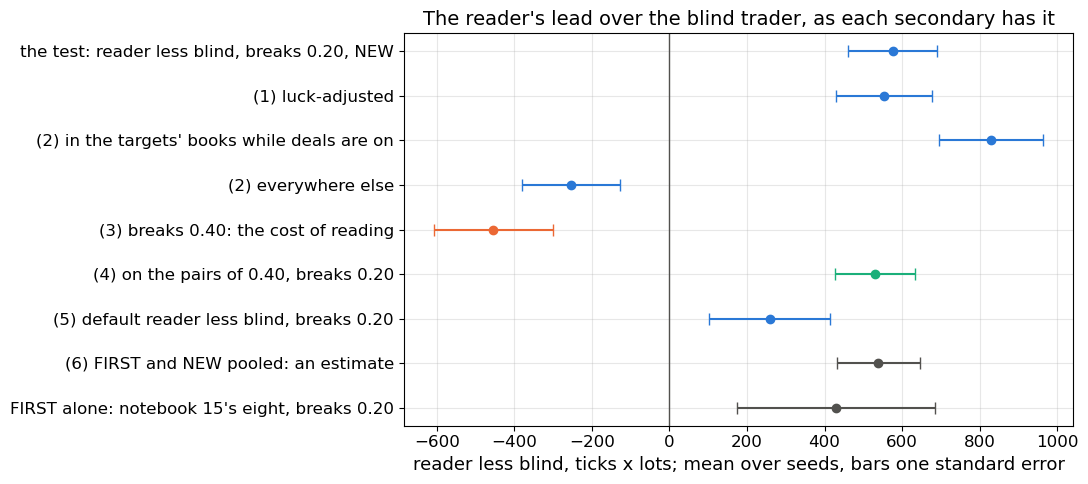

In [11]:
# The leads of this section in one figure: each a mean over seeds, with bars of one standard error (one y-axis; the
# groups of seeds are in the labels). The first line is the test; the others are the secondaries, in their order, and
# the figure adds nothing to them. FIRST and the pooled line are estimates, and not the test.
news_elsewhere_lead = lead_of(
    news_test_frame.assign(elsewhere=news_test_frame.pnl - news_test_frame.target_on),
    news_test_reader,
    news_test_blind,
    'elsewhere',
)
forest = [  # (label, a value a seed, color)
    (f'the test: reader less blind, breaks {DEAL_CHEAP:.2f}, NEW', news_test_lead, BLUE),
    ('(1) luck-adjusted', news_test_adjusted, BLUE),
    ("(2) in the targets' books while deals are on", news_split_inside, BLUE),
    ('(2) everywhere else', news_elsewhere_lead, BLUE),
    (f'(3) breaks {DEAL_FAIR:.2f}: the cost of reading', news_fair_lead, ORANGE),
    (f'(4) on the pairs of {DEAL_FAIR:.2f}, breaks {DEAL_CHEAP:.2f}', news_same_lead, AQUA),
    (f'(5) default reader less blind, breaks {DEAL_CHEAP:.2f}', news_default_lead, BLUE),
    ('(6) FIRST and NEW pooled: an estimate', news_pooled, GRAY),
    (f"FIRST alone: notebook 15's eight, breaks {DEAL_CHEAP:.2f}", news_first_lead, GRAY),
]
fig, ax = plt.subplots(figsize=(11.0, 5.0))
for i, (_, x, color) in enumerate(forest):
    ax.errorbar([x.mean()], [-i], xerr=[se_of(x)], fmt='o', color=color, capsize=4)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks([-i for i in range(len(forest))], [label for label, _, _ in forest])
ax.set_xlabel('reader less blind, ticks x lots; mean over seeds, bars one standard error')
ax.set_title("The reader's lead over the blind trader, as each secondary has it")
fig.tight_layout()
plt.show()

**What the picture shows.** Every bar, a mean with one standard error either side, clears 0. Seven of the nine are more than two standard errors from 0 (the printed t's, and 530 over 103 for the lead on the pairs of 0.40 held, a plain ratio), and the two that are not, the default reader at +258 (se 156, t 1.65) and `FIRST` at +429 (se 256, t 1.68), clear 0 by one standard error and not by two. That count is not a test: only the first bar was held to the bar of two standard errors, and the t's of the secondaries are ratios with no allowance for there being six of them beside the test. The test's lead, +576 (se 116), sits among three others of about its size, the luck-adjusted +553 (se 124), the lead on the pairs of 0.40 held, +530 (se 103), and the pooled estimate, +539 (se 106), whose bars overlap the test's, while the part in the targets' books, +829 (se 134), lies to the right of all of them, its bar just above the test's. The two halves of the one lead have opposite signs, +829 in the targets' books while the deals are on and -254 (se 126, t -2.02) everywhere else, and the cost of reading at 0.40, -454 (se 153), is the one other bar left of 0.

#### The Bet on the Lots Held, and the Cost of Reading, Measured

**This cell was added after the first run, on a review of it; it is a description and not a test, and nothing was chosen from it.** The first run printed the bet's arithmetic (the lots the blind trader holds two decisions after an announcement, once, times the edge) and a split of the lead by where it was made, and could not say what the lead is made of: the arithmetic counts the lots at one decision, and the blind trader's lots in a target change over a deal. The review of the run measured, from its own runs, what the blind trader holds over a deal's life and what that is worth, and the conclusions of this notebook quote it. This cell puts those measures into the notebook, so that it prints what it quotes. It runs nothing new: it reads the frames of 1b (the test, 0.20 on each market's own pairs), 1c (3) (0.40) and 1c (4) (the pairs of 0.40 held in the market of 0.20), each a run of the blind trader and of the reader on every one of the 24 seeds of `NEW`. Each figure is a mean over the seeds with its standard error over the seeds and the seeds positive, and a lead or a difference is paired by seed.

**What was kept to measure it.** The traders of this section are now recorded: at each decision, before it decides, a mixin (`Watching`, in the helpers cell) keeps what the deals add to each book's fair value at that moment, beside the record of what the trader held. It reads the market and writes only to itself, so the trader does what it did and no figure above this cell changes; the check in 1c (4), which trades the blind trader at 0.40 with a plain `RelationTrader` on the first eight seeds of `NEW` and asserts its P&L, lots and entries equal to those of the recording trader's row to the last digit, now covers the recording too. Each run's measures are made in the worker from that record (`news_held_measures`, in the helpers cell) and are columns of the frames.

**What is measured.** In a deal a target's fair value is its value alone plus a *deal part*: while the deal is on, its fair value is a mix of what the offer is worth and what the target is worth alone, so the deal part is the fair value less the value alone, which the library keeps; at a break the deal part falls to 0, and at a completion the target's own level takes the offer's difference, so the deal part goes to that whole difference and the fair value does not jump. A decision's lots are those held after it. The deals are those the split of 1c (2) counts: announced from the burn on and over by the run's end, each from its announcement to two units after its end.

1. *The lots in a target over the deal's life.* The lots net short of the deal's target (a short lot counts positive) at the decisions 2, 10, 50 and 75 after the announcement, the first decision at or after it being the 0th, over the deals of three decisions or more, the blind trader at 0.20 on its own pairs: the mean over the deals of a seed, then the mean over the seeds, and the mean over all the deals pooled. And the lots over each deal's life weighted by the deal part times the time to the next decision, which is what the bet earns on. The arithmetic of the bet is at decision 2.
2. *The expected bet with the lots held.* For each decision of a deal's life, the lots held times the change of the deal part that was expected to the next decision, which is (q - p) times the deal part times the time, where q and p are the hazards of a break the market prices and that is true (so it is 0 where they are alike, and it is the model's expectation given the lots, not what happened); summed over the deals, a run. The blind trader's, on its own pairs at 0.20 and on the pairs of 0.40 held in the market of 0.20, beside the arithmetic of 1c (2) and 1c (4).
3. *The deal part the blind trader realizes.* The same lots times the change of the deal part that happened, over each deal's life and the decision over its end (where it goes to 0 at a break and to the offer's whole difference at a completion), at fair values and before the spread paid, a run; the blind trader's, at 0.20 on its own pairs, on the pairs of 0.40 held in the market of 0.20, and at 0.40 on its own. The reader realizes none (it holds none of a deal's target while it is on, which the cell asserts). *The cost of reading* is the reader's lead less the deal part it avoids, which is the reader's realized deal part less the blind trader's, so the blind trader's with its sign turned: at 0.20 on the own pairs, and at 0.20 and 0.40 on one set of pairs, the pairs of 0.40.
4. *The shift of the lead across the two markets on one set of pairs* (1c (4)), split in two: the difference of the deal part that the reader avoids at 0.20 and at 0.40, and what is left, which is the difference of the cost of reading across the two.

**What it cannot show.** A target tracks its acquirer during a deal, so the deal part holds some ordinary reversion as well as the bet, and the bet and what reading gives up are separated only as far as that is small; this cell does not measure how small. The deal part is counted at fair values, from the library's own record, so the spread paid, and the moves of a target's mid that are not its fair value's, are outside it. A seed's deals are not the same number, so the mean over the deals of a seed and the mean over all the deals differ a little, and both are printed. Every figure here is a description of these 24 seeds' runs, and a t beside it is a ratio and not a test.

In [12]:
# 1c, added after the first run, on a review of it: what the blind trader held in the target of a deal over the deal's
# life, and the bet and the cost of reading from it. A description and not a test, and nothing was chosen from it. No
# new run: it reads the frames of 1b, 1c (3) and 1c (4), whose rows were run with a trader that records what the deals
# add to the fair values at each decision (Watching, in the helpers cell, which also defines the columns read here, in
# news_held_measures). Each is a value a seed, paired by seed with its standard error over the seeds.
print(
    'Added after the first run, on a review of it: a description and not a test, and nothing was chosen from it. The '
    "runs are those of 1b, 1c (3) and 1c (4), read again.\n"
)


def held_runs(frame, row):
    # The lines of one row of a frame of runs, a line a seed, in the order of the seeds.
    return frame[frame.row == row].set_index('seed').sort_index()


# The three settings the cell reads, as it labels them, and the width of the labels.
held_own_cheap = f'own pairs, breaks {DEAL_CHEAP:.2f}:'
held_same = f'pairs of {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}:'
held_own_fair = f'own pairs, breaks {DEAL_FAIR:.2f}:'
held_width = len(held_same)


def held_said(x):
    # said(x), and the seeds below 0 (a bet that loses on every seed has none above 0: said the other way too).
    return f'{said(x)}; {int((x < 0).sum())} of {len(x)} below 0'


# (1) The lots the blind trader holds in a deal's target over the deal's life, at 0.20 on its own pairs: the lots net
# short (a short lot counts positive) at the decisions that many after the announcement (the first decision at or after
# it is the 0th), over the deals of at least three decisions announced from the burn on and over by the run's end; and
# the lots over each deal's life weighted by the deal part of the target's fair value times the time to the next
# decision. A mean over the deals of a seed, then over the seeds; and over all the deals of all the seeds pooled (the
# deals are not the same number on every seed).
news_held_runs = held_runs(news_test_frame, news_test_blind)
assert list(news_held_runs.index) == list(NEW), 'the test frame is not on every seed of NEW'
assert (news_held_runs[f'held_deals_{HELD_AT[0]}'] == news_held_runs.held_deals).all(), 'a deal of 3 has a 2nd'
news_held_by_decision = pd.DataFrame(
    {k: news_held_runs[f'held_short_{k}'] / news_held_runs[f'held_deals_{k}'].replace(0, np.nan) for k in HELD_AT}
)
news_held_by_decision['weighted'] = news_held_runs.held_weighted / news_held_runs.held_deals.replace(0, np.nan)
news_held_pooled = pd.Series(
    {k: news_held_runs[f'held_short_{k}'].sum() / news_held_runs[f'held_deals_{k}'].sum() for k in HELD_AT}
)
news_held_pooled['weighted'] = news_held_runs.held_weighted.sum() / news_held_runs.held_deals.sum()
news_held_ratio = news_held_pooled['weighted'] / news_held_pooled[HELD_AT[0]]  # on the same deals
print(
    f'The blind trader at breaks {DEAL_CHEAP:.2f} on its own pairs, a run: {news_held_runs.held_deals.mean():.1f} '
    f"deals of three decisions or more, announced from the burn on and over by the end. The lots net short of the "
    f"deal's target, {len(NEW)} seeds (the mean over the deals of a seed, then over the seeds; the standard error "
    f'over the seeds), and over all the deals pooled:\n'
)
for k in HELD_AT:
    column = news_held_by_decision[k].dropna()
    print(
        f'  {k:>2} decisions after the announcement: {said(column, 2)}; all deals pooled {news_held_pooled[k]:.2f} '
        f"({int(news_held_runs[f'held_deals_{k}'].sum())} deals)"
    )
column = news_held_by_decision['weighted'].dropna()
print(
    f"  over the deal's life, weighted by the deal part of the fair value times the time: {said(column, 2)}; all deals "
    f'pooled {news_held_pooled["weighted"]:.2f}, {news_held_ratio:.2f} times the {news_held_pooled[HELD_AT[0]]:.2f} at '
    f'decision {HELD_AT[0]} on the same {int(news_held_runs.held_deals.sum())} deals'
)

# (2) The expected bet with the lots held: the lots held after each decision times the change of the deal part that was
# expected to the next, (q - p) times the deal part times the time, over each deal's life, a run; beside the arithmetic
# of 1c (2) and (4), which counts the lots two decisions after the announcement once. The blind trader on its own pairs
# at 0.20, and on the pairs of 0.40 held in the market of 0.20 (1c (4)).
news_held_same_runs = held_runs(news_same_frame, news_same_blind)
assert list(news_held_same_runs.index) == list(NEW), 'the same-pairs frame is not on every seed of NEW'
news_held_bet_own = news_held_runs.deal_expected
news_held_bet_same = news_held_same_runs.deal_expected
news_held_arithmetic_own = news_bet_arithmetic  # 1c (2), -edge x net short lots, as printed there and in 1c (1)
news_held_arithmetic_same = -news_edge_same * news_held_same_runs.net_short.mean()  # as printed in 1c (4)
print(
    '\nThe expected bet with the lots held (the lots held after each decision times (q - p) times the deal part times '
    "the time to the next decision, over each deal's life), the blind trader, a run, beside the arithmetic of the bet "
    "(the lots two decisions after the announcement, once), -edge x net short lots:\n"
)
for label, bet, arithmetic in (
    (f'own pairs, breaks {DEAL_CHEAP:.2f}', news_held_bet_own, news_held_arithmetic_own),
    (f'pairs of {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}', news_held_bet_same, news_held_arithmetic_same),
):
    print(
        f'  {label}: {held_said(bet)}; the arithmetic {arithmetic:+,.0f}, so the bet on the lots held is '
        f'{bet.mean() - arithmetic:+,.0f} from it, {bet.mean() / arithmetic:.2f} times it (a plain difference and a '
        f'plain ratio)'
    )

# (3) The deal part the blind trader realizes: the lots held after each decision times the change of the target's deal
# part to the next, over each deal's life, at fair values and before the spread paid, a run; and the cost of reading,
# the lead less the deal part the reader avoids (the reader's realized deal part less the blind trader's: the reader
# holds none of a deal's target while it is on, so it realizes none, asserted).
news_held_real_own = news_held_runs.deal_realized
news_held_real_same = news_held_same_runs.deal_realized
news_held_real_fair = held_runs(news_fair_frame, news_fair_blind).deal_realized
for frame, reader in ((news_test_frame, news_test_reader), (news_fair_frame, news_fair_reader)):
    assert (held_runs(frame, reader).deal_realized.abs() < 1e-9).all(), 'a reader realized a deal part'
assert (held_runs(news_same_frame, news_same_reader).deal_realized.abs() < 1e-9).all(), 'a reader realized a deal part'
print(
    '\nThe deal part that the blind trader realizes (the lots held after each decision times the change of the '
    "target's deal part to the next, over each deal's life, at fair values and before the spread paid), a run:\n"
)
print(f'  {held_own_cheap:<{held_width}} {held_said(news_held_real_own)}')
print(f'  {held_same:<{held_width}} {held_said(news_held_real_same)}')
print(f'  {held_own_fair:<{held_width}} {held_said(news_held_real_fair)}')
news_held_avoided_own = lead_of(news_test_frame, news_test_reader, news_test_blind, 'deal_realized')
news_held_avoided_fair = lead_of(news_fair_frame, news_fair_reader, news_fair_blind, 'deal_realized')
news_held_avoided_same = lead_of(news_both_worlds, news_same_reader, news_same_blind, 'deal_realized')
news_held_cost_own = news_test_lead - news_held_avoided_own
news_held_cost_same = news_same_lead - news_held_avoided_same
news_held_cost_fair = news_fair_lead - news_held_avoided_fair
print(
    "\nThe cost of reading, the reader's lead less the deal part it avoids (the blind trader's realized deal part, "
    'with its sign turned), seed by seed:\n'
)
print(f'  {held_own_cheap:<{held_width}} {said(news_held_cost_own)}')
print(f'  {held_same:<{held_width}} {said(news_held_cost_same)}')
print(f'  {held_own_fair:<{held_width}} {said(news_held_cost_fair)}')

# (4) The shift of the lead across the two markets on one set of pairs (1c (4)), split: the difference of the deal part
# the reader avoids at 0.20 and at 0.40, and what is left, which is the difference of the costs of reading.
news_held_shift_deal = news_held_avoided_same - news_held_avoided_fair
news_held_shift_rest = news_held_cost_same - news_held_cost_fair
assert np.allclose(news_held_shift_deal + news_held_shift_rest, news_did_same), 'the shift and its two parts differ'
print(
    f'\nThe shift of the lead from {DEAL_FAIR:.2f} to {DEAL_CHEAP:.2f} on the pairs of {DEAL_FAIR:.2f} in both '
    f'(1c (4)): {said(news_did_same)}. As the difference of the deal part that the blind trader realizes, avoided at '
    f'{DEAL_CHEAP:.2f} less at {DEAL_FAIR:.2f}: {said(news_held_shift_deal)}; and what is left, the cost of reading at '
    f'{DEAL_CHEAP:.2f} less at {DEAL_FAIR:.2f}: {said(news_held_shift_rest)}.'
)

Added after the first run, on a review of it: a description and not a test, and nothing was chosen from it. The runs are those of 1b, 1c (3) and 1c (4), read again.

The blind trader at breaks 0.20 on its own pairs, a run: 38.6 deals of three decisions or more, announced from the burn on and over by the end. The lots net short of the deal's target, 24 seeds (the mean over the deals of a seed, then over the seeds; the standard error over the seeds), and over all the deals pooled:

   2 decisions after the announcement: +1.60 (se 0.08, t 19.89, 24 of 24 seeds positive); all deals pooled 1.59 (927 deals)
  10 decisions after the announcement: +1.68 (se 0.07, t 22.46, 24 of 24 seeds positive); all deals pooled 1.68 (908 deals)
  50 decisions after the announcement: +1.96 (se 0.08, t 25.97, 24 of 24 seeds positive); all deals pooled 1.95 (826 deals)
  75 decisions after the announcement: +2.02 (se 0.07, t 28.80, 24 of 24 seeds positive); all deals pooled 2.01 (782 deals)
  over the deal's l

**The blind trader's net short in a target grows over a deal.** This part was added after the first run, on a review of it: what it prints is a description of these 24 seeds and not a test, and nothing was chosen from it. The first block measures the lots net short of a deal's target (a short lot counts positive) that the blind trader at 0.20 on its own pairs holds at decisions 2, 10, 50 and 75 after the announcement, over its 38.6 deals a run of three decisions or more: a seed's mean over its deals, then the mean over the 24 seeds, and the mean over all the deals pooled. Over the seeds they are +1.60 (se 0.08, t 19.89, 24 of 24 seeds positive) at decision 2, +1.68 (se 0.07, t 22.46, 24 of 24) at 10, +1.96 (se 0.08, t 25.97, 24 of 24) at 50 and +2.02 (se 0.07, t 28.80, 24 of 24) at 75; pooled over the deals they are 1.59 (927 deals), 1.68 (908), 1.95 (826) and 2.01 (782). The text quotes the figure over the seeds with its standard error and the pooled one beside it; the two ways of averaging differ by 0.01 at most. Weighted by the deal part of the fair value times the time, which is what the bet earns on, the lots over a deal's life are +1.89 (se 0.07, t 27.26, 24 of 24 seeds positive) over the seeds and 1.88 pooled, which is 1.18 times the 1.59 at decision 2 on the same 927 deals. So the mean net short rises from +1.60 at decision 2 to +2.02 at decision 75, and over the deal's life it is 1.18 times the lots at decision 2: the arithmetic of 1c (2), which counts the lots at decision 2 once, counts fewer lots than the blind trader holds, and undercounts the lots that the bet is made on. The block does not say why the lots grow. The deals counted fall from 927 at decision 2 to 782 at decision 75, so the later decisions are on fewer deals and the rise from decision 2 to 75 is partly a change in which deals are counted; the comparison on the same 927 deals, 1.88 against 1.59, is free of that. A t beside a figure here is a ratio and not a test.

**The expected bet on the lots held is -886 a run, against the arithmetic's -740.** The second block puts the lots held after each decision of a deal's life against the model's expectation of what the deal part moves, (q - p) times the deal part times the time to the next decision, summed over the deals: it is the expectation given the lots and not what happened. For the blind trader on its own pairs at 0.20 it is -886 (se 39, t -22.54, 0 of 24 seeds positive; 24 of 24 below 0), beside the arithmetic of -740: 146 from it and 1.20 times it (a plain difference and a plain ratio, as the cell prints them). On the pairs of 0.40 held in the market of 0.20 it is -942 (se 33, t -28.30, 0 of 24 seeds positive; 24 of 24 below 0), beside the arithmetic of -807: 135 from it and 1.17 times it. So the printed arithmetic understates the bet, by 146 and 135 a run. The +89 by which the targets' books of 1c (2) exceed that arithmetic is smaller than the 146 by which it falls short of the expected bet on the lots held, so it is within the arithmetic's shortfall and is not a second source of the lead; and the shift of 1c (4), +984, is 42 from the expected bet of -942 on those pairs, where it was 177 above the arithmetic's 807 (plain differences of printed figures). What the block does not show: it is a model's expectation, below 0 on every seed, and it does not measure what the bet made, which the next block does; the t of -22.54 is a ratio and not a test.

**The deal part the blind trader realizes is -911 a run at 0.20, and +104 at 0.40, not separated from 0.** The third block counts the same lots times the change of the target's deal part that happened, over each deal's life and the decision over its end, at fair values and before the spread paid, a run. At 0.20 it is -911 (se 68, t -13.47, 0 of 24 seeds positive; 24 of 24 below 0) on the blind trader's own pairs and -891 (se 85, t -10.49, 1 of 24 seeds positive; 23 of 24 below 0) on the pairs of 0.40 held in the market of 0.20, beside the expected bets of -886 and -942 above: it loses on every seed on its own pairs and on 23 of the 24 on the pairs of 0.40. At 0.40 on its own pairs, where the price is fair and the expected bet is 0, it makes +104 (se 128, t 0.81, 12 of 24 seeds positive; 12 of 24 below 0): not separated from 0, with half the seeds each way. The reader realizes none of this, since it holds none of a deal's target while the deal is on, which the cell asserts. What the block does not show: the deal part is counted at fair values, from the library's own record, so the spread paid and the moves of a target's mid that are not its fair value's are outside it; it holds some ordinary reversion as well as the bet (the head); and the t's are ratios and not tests.

**The lead less the deal part avoided, which this cell calls the cost of reading, is -335 to -361 a run at 0.20 and -350 at 0.40, and is not shown to differ between the two chances of a break.** The fourth block takes the reader's lead less the deal part it avoids (the blind trader's realized deal part with its sign turned), seed by seed: -335 (se 103, t -3.25, 6 of 24 seeds positive) at 0.20 on the own pairs, -361 (se 89, t -4.04, 5 of 24) at 0.20 on the pairs of 0.40, and -350 (se 88, t -3.98, 4 of 24) at 0.40 on its own pairs. Beside the cost of reading at 0.40 that 1c (3) prints, -454 (se 153, t -2.97, 8 of 24), the -350 is the same lead with the blind trader's realized deal part of +104 taken out (-454 less the -104 that the reader avoids, a plain subtraction of printed figures). Beside the part everywhere else in 1c (2), -254 (se 126, t -2.02, 10 of 24), it is another quantity: the -254 is the lead's share made outside the targets' books while the deals are on, and it holds the spread paid in those books and the jump at an announcement, so it is not the cost of reading. On one set of pairs the cost is -361 at 0.20 and -350 at 0.40, and their difference, -11 (se 71, t -0.16, 11 of 24 seeds positive), is printed in the last block and is not separated from 0. The cost of reading is defined as the lead less the deal part avoided, so the lead is their sum on any seeds (911 less 335 is 576, a plain sum); what this block shows beyond that is that the deal part avoided is about the expected bet on the lots held (+911 against +886) and that what is left does not move with the chance of a break (-11, se 71, last block). The line between the bet and what reading gives up is not sharp, and this cell does not measure it: a target tracks its acquirer, so the deal part holds some ordinary reversion as well as the bet, and the review put the limit at about 100 a run, from the +117 (se 47) and +126 (se 51) that a set of the route carries in the paths of 0.40 on `PAPER`, where the bet is 0. That is another instrument, on fair values and on other seeds: on these 24 seeds the route's sets carry +161 (se 131) and +232 (se 153) where the bet is 0 (the route's figures are printed in the cell added to section 2, below), and the blind trader's realized deal part at 0.40 is +104 (se 128). The limit is not measured on these seeds, and the standard errors come on top of it (se 68 on the deal part, se 103 on the -335). If the reader gives the reversion up too, the deal part avoided is net of it: the bet avoided is larger than +911, and the cost of what reading gives up is larger than -335, by about that much; at 0.40 it lies between -350, if the blind trader's +104 is luck, and the -454 of 1c (3), if all of it is such reversion. This is a description of these 24 seeds, made after seeing the first run, at one premium of one simulated market, and not a test.

**The shift of the lead from 0.40 to 0.20 on one set of pairs is almost all the deal part avoided.** The last block takes the shift on the pairs of 0.40 in both markets (1c (4)), +984 (se 125, t 7.88, 24 of 24 seeds positive), and splits it into the difference of the deal part that the blind trader realizes, avoided at 0.20 less at 0.40, +995 (se 123, t 8.11, 23 of 24 seeds positive), and what is left, the cost of reading at 0.20 less at 0.40, -11 (se 71, t -0.16, 11 of 24 seeds positive). So, on these seeds and on this measure, the shift is the bet avoided measured on the lots held, with nothing left that is separated from 0; this replaces the comparison with the printed arithmetic in 1c (4), whose gap (+984 against 807, 177) was the arithmetic's shortfall (the expected bet on those pairs, -942, is 135 from the arithmetic and 42 from the shift). What the block does not show: that the ordinary reversion in the deal part is absent (the review read the difference across the two chances as not affected by it, a reading the cell does not measure), how much of the deal part is the bet (the route's figure for the reversion is about 100 a run on `PAPER` and +161 and +232 on `NEW`, where the bet is 0), or anything beyond these 24 seeds and these two chances of a break. It is a description that was added after the first run, on a review of it, and nothing was chosen from it.

### In a Backtest's Terms

The scorecard and signal chart of the reader out for the deal's life, in the sectors market with deals on the first seed of `NEW`, which played no part in choosing any setting: `breaks` 0.20, announcements at 0.002, eight pairs by distance, 2.5 lots of each, deciding every 5 units. It is the recorded run of the test's table on that seed, to its end, and the cell checks that its deals are the table's. The card is on capital of 150,000, as the other sections' cards are; the cell prints how much the trader holds at its most as a multiple of it, and the text says so if it is above 1. The chart is of the largest leg of the first pair, with that pair's z-score, lines at the entry level on either side of 0 and at the level it leaves at, and circles where the trader enters and exits. The card runs from the trader's first order to the end of the run, and the tables count only the last 20,000 units, so the card's figure differs from the table's for the same run.

**A card's hit rate and profit factor are those of legs, not of deals or pairs.** The record holds the position in each book after each decision, so a trade of the scorecard is a run of one sign in one book. A pair is two or more such legs, and a book is in several pairs one after another, and the reader is flat in a pair while a deal on its target is on, so a leg that stops for a deal is cut in two. The scorecard cannot show a pair's round trip or a deal's bet.

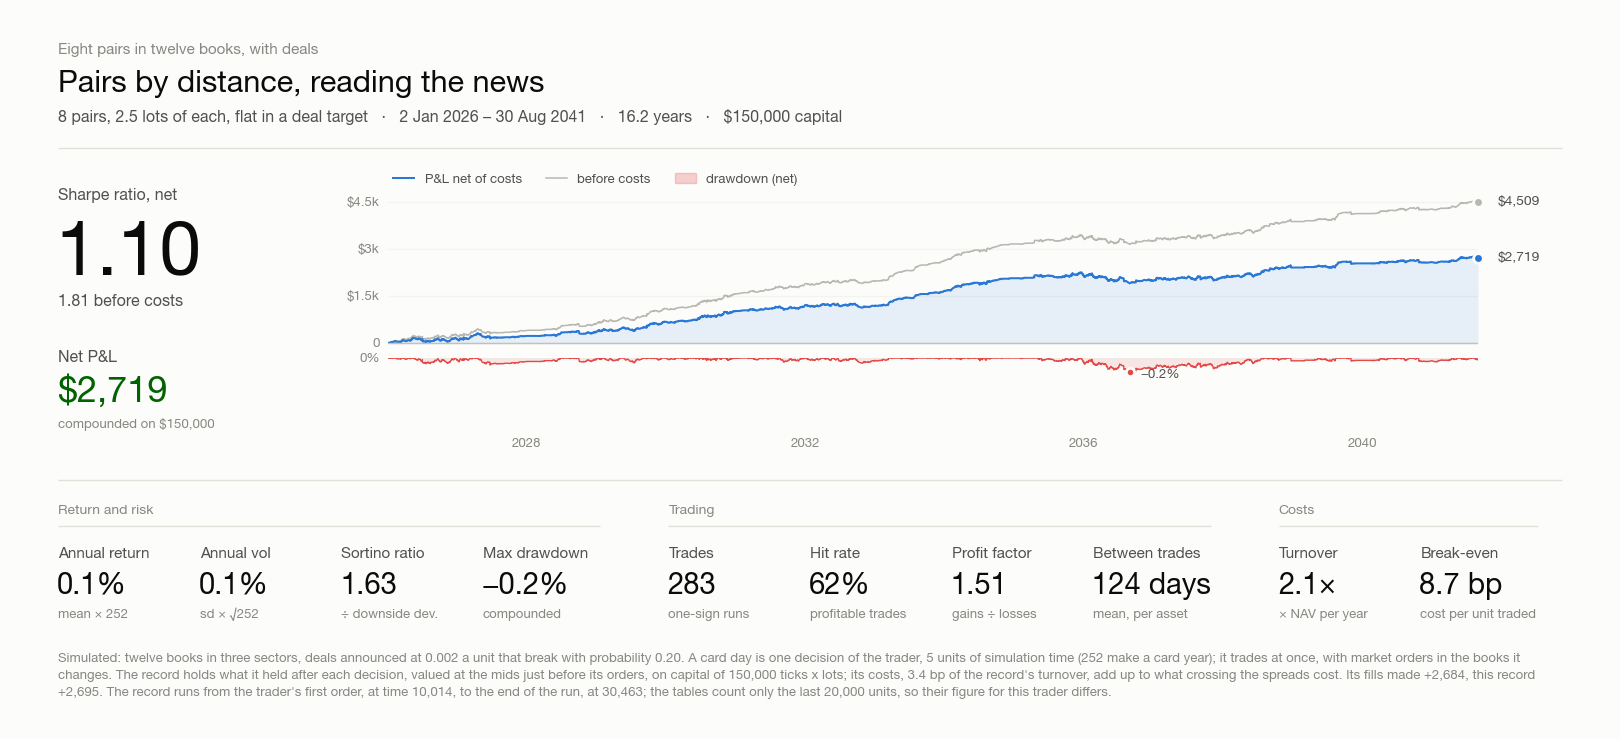

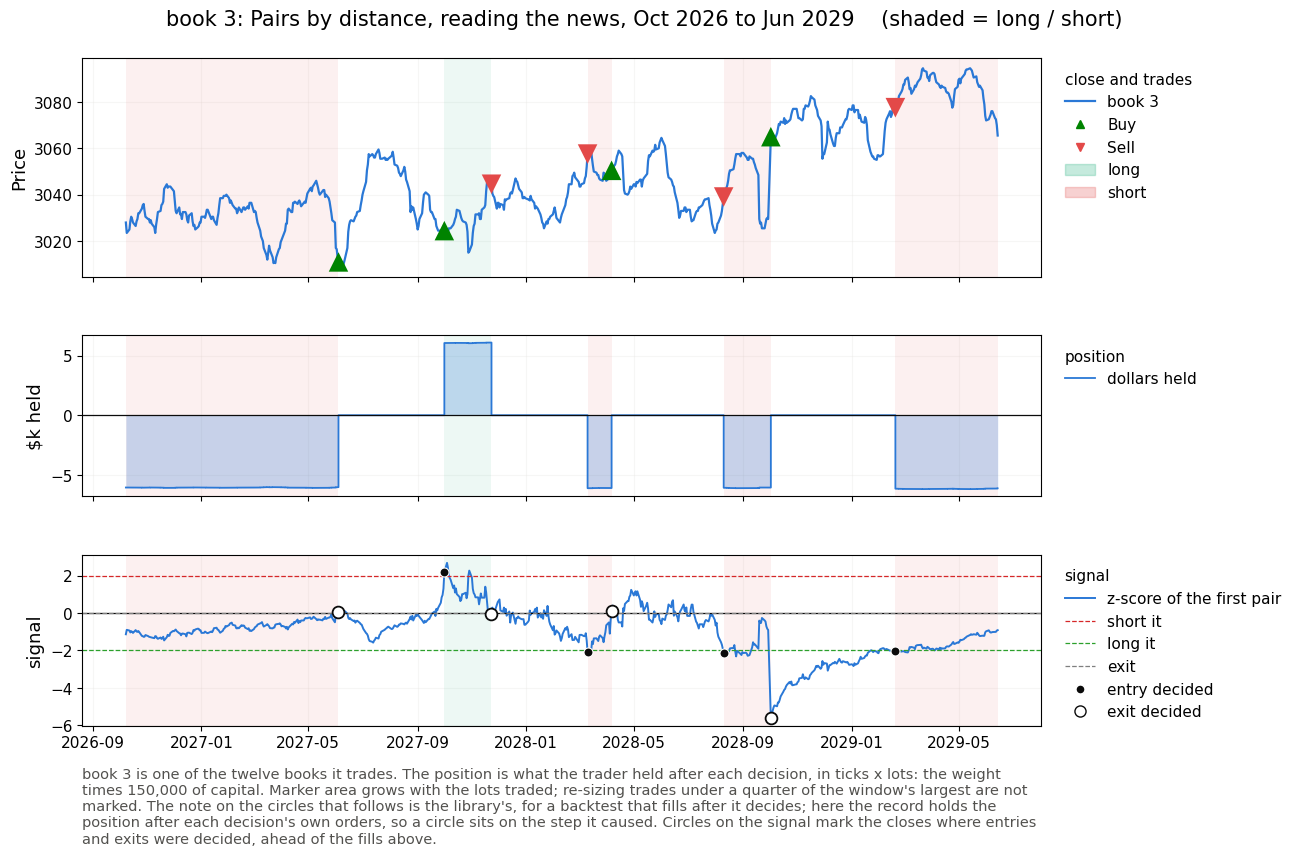

Eight pairs in twelve books, with deals: its fills made +2,684 and the record +2,695; it holds at most 0.64 times the capital of 150,000, and more than it on 0.0% of days.
The test's table figure for this run (breaks 0.20, seed 121), the last 20,000 units only: +2,572
The run has 56 deals ended and 0 on at its end; the reader holds none of a deal's target while it is on (checked above for every run of the table).


In [13]:
# The reader out for a deal's life on the first seed of NEW (CARD_SEED), at breaks 0.20: the run of the test's table, to
# its end, with a record of every decision.
trader, fills, market = recorded(dealing(DEAL_CHEAP), pairs_by(NewsAwareTrader, quarantine=0.0), PAIRS_BURN)
news_card = card(
    trader,
    fills,
    'Pairs by distance, reading the news',
    '8 pairs, 2.5 lots of each, flat in a deal target',
    'Eight pairs in twelve books, with deals',
    f'twelve books in three sectors, deals announced at {DEAL_RATE} a unit that break with probability '
    f'{DEAL_CHEAP:.2f}',
    'z-score of the first pair',
    around(trader),
    largest_leg(trader),
)
# It is the run of the table's row on this seed: the same deals (as far as the shorter of the two runs goes).
table_row = news_test_frame[(news_test_frame.row == news_test_reader) & (news_test_frame.seed == CARD_SEED)]
check_card_deals(table_row, market, CARD_SEED)
# And the trader's own eight rows of weights, which depend on the trader and not on time alone: the table's run's.
assert tuple(map(tuple, trader.weights.tolist())) == table_row.weights.item(), (
    "the card's run chose other pairs or hedges than the table's run of the same row and seed"
)
print(
    f"The test's table figure for this run (breaks {DEAL_CHEAP:.2f}, seed {CARD_SEED}), the last {SPAN:,.0f} units "
    f"only: {table_row.pnl.item():+,.0f}"
)
print(
    f'The run has {len(market.fair.ended)} deals ended and {len(market.fair.deals)} on at its end; the reader holds '
    f'none '
    "of a deal's target while it is on (checked above for every run of the table)."
)

**The record against the fills.** The card line prints that the reader's fills made +2,684 and the record +2,695, 11 apart (a plain difference): the record is the position after each decision valued at the mids, and the run moves a little after its last decision. The test's table prints +2,572 for this run (breaks 0.20, seed 121), 112 below the fills' figure (a plain difference), because the table counts only the last 20,000 units, from the end of the burn at 10,465, and the card counts from the trader's first order, at time 10,014 (the card's footnote), to the end of the run at 30,463. The scorecard's own headline Net P&L, \$2,719, is labeled as compounded on \$150,000 and is a third figure beside the two printed ones, with its dollar sign standing for ticks x lots, as the footnote says; the fills and the record are the figures read here.

**The most the card holds.** The reader holds at most 0.64 times the capital of 150,000 and holds more than it on 0.0% of days. It is never above 1, so the card is not leveraged on any day, and the capital exceeds what the card holds at its most, as it is meant to.

**What the chart shows.** The chart is of book 3, the largest leg of the first pair, from October 2026 to June 2029 on the card's calendar. Its position goes between flat and about 6k on one side or the other in one step each way, at about the same size, and the entries are decided where the z-score of the first pair reaches the entry line: this leg is bought at a z-score of about +2.2 and sold at about -2.1, -2.1 and -2.0. The exits are decided where the z-score comes back to about 0: the short held from the window's left edge, which was entered before the window began, is closed at about 0 in mid-2027, the long entered in late 2027 is closed at about 0 a few months later, and the short entered in early 2028 is closed at about 0 within weeks. The short entered in early 2029 is still held at the window's end. One exit, in late 2028, is decided at a z-score of about -5.6 and not near 0, right after a step in the book's price of about 40 (read off the chart), and the chart does not say what closed it. The chart marks no deal, so it does not show whether the book is flat while a deal on it, or on the other book of its pair, is on. What the cell prints is that the run has 56 deals ended and 0 on at its end, across all twelve books, and that the reader holds none of a deal's target while it is on, checked for every run of the table.

### What This Section Cannot Show

- **That reading the news pays in a real market.** The news here is a perfectly informative list of deals: the target, the announcement's time and the deal's end are known to the reader exactly and at once, and the deals come at random from the books themselves, with no information in the order flow before or after them, no leakage, no crowding of other arbitrageurs and no change in the premium with the market. A completed deal here is worth a fixed premium and a broken one falls back to where it was, as `lob/deals.py` has it. What is tested is a trader that stops trading a target while its deal is on, in a market built so that the target's pair is disturbed by the deal.
- **That the lead, if there is one, is the news.** By the model's arithmetic it is the bet that the blind trader holds and the reader avoids, less what the reader gives up. A pairs trader that knew nothing of deals could avoid the bet by trading less, and a trader that wanted the premium would take the other side of the bet, as notebook 15's deal trader does. The section does not run those traders, and the reader is not compared with them.
- **That the lead holds at other premiums.** There are two values of the true chance of a break, 0.20 and 0.40, with the price fixed at 0.40, and so no break-even and no line. Where a break is underpriced (a true chance above 0.40) the bet changes sign, and the reader's lead would be a different quantity: it is not run.
- **That a failed test means a lead of 0.** A test on 24 seeds has little power against a lead of a few hundred ticks when the per-seed standard deviation is about 740, as the head of this section says (on `NEW` it came out at about 566, the printed standard error times the square root of 24): if the true lead were half of notebook 15's, the chance of two standard errors on 24 seeds is under a half. The outcome text for a lead under two standard errors says that the new seeds do not show it, and not that it is not there.
- **That the test could not have been passed by luck, or that a pass is the size of the lead.** One test on 24 seeds, one-sided, at two standard errors, passes at the rate of a one-sided t of 2 on 23 degrees of freedom when the true lead is 0 (the cell prints it), and a lead that has passed it is, on average, larger than the true one: it is the one that cleared a bar.
- **That the luck-adjusted lead is exact.** It adds back the blind trader's luck from its lots two decisions after the announcement, taken as held for the deal's life, and pays them from just after the announcement. A deal that breaks inside those two decisions, and lots that change in the deal's life, are not in it. It has no fitted coefficient, so it is not the best linear control, and it is a secondary.
- **That the arithmetic of the bet and the split in the targets' books agree, as an identity or in expectation.** They do not. The arithmetic counts the lots held two decisions after the announcement, as if they were held for the deal's life, and the blind trader's net short in a target grows over the deal, so it understates the bet: the cell added after the first run, after the picture of the leads, measures the expected bet with the lots actually held, a run (-886, se 39, on the test's own pairs at 0.20), beside the printed arithmetic (-740). The split is measured and the arithmetic is the model's, and the text does not present the gap between them (+89 on the test's seeds) as a second source of the lead.
- **That the rows on the other market's pairs are what a trader makes.** A trader in the market of 0.20 cannot choose the pairs of 0.40, and the rows on them are controls. They hold the pairs fixed to separate the bet from the pairs, in one market, on 24 seeds.
- **That the pooled figure is a test.** Eight of its 32 seeds are the ones the hypothesis came from, and 24 were added after; `FIRST` is notebook 15's and is not tested again, and seeds 1 to 8, where the settings were chosen, are in neither.
- **What the model leaves out.** Orders cross the spread at once at the books' prices: no queue, no rebates, no partial fills the trader waits on. The pairs trader is alone in its market. The pairs are chosen once, from one formation, and never revisited: a chooser that read the news and re-based a target's mids after a completion, so that the deals do not damage the formation, is the lead that the premise review of the design, made before the run, named, and it is not built here.
- **That any of this holds beyond one simulated market**: twelve books in three sectors, 24 seeds of it.

## 2. Why a Market's Pairs Differ

**Why are the pairs chosen in the market with a risk premium worth less?** A pairs trader chooses its eight pairs once, from the mids of its own market, at the end of its formation. In notebook 15 the pairs that the trader chose in the market of 0.40 (where the price of a break is the true chance) were worth more, traded in the market of 0.20 (where a break is overpriced), than the pairs that market's own mids gave it: +446 (se 143, 7 of 8 seeds positive) for the blind trader, +635 (se 242, 7 of 8) for the reader with no quarantine and +491 (se 166, 7 of 8) for the default reader. The three traders of a seed share their pairs, so these are one comparison seen three times. Notebook 15 counted how many pairs the two markets share, and said that why the market of 0.20 chooses worse ones is not shown.

**The explanation tested.** A deal that completes leaves a step behind. At its end the target's level takes the difference between what the offer is worth and what the target is worth on its own (`FactorValues.level`), so that its fair value does not jump, and from then on the target sits that far from its sector mates for good. A deal that breaks leaves none: the target falls back to what it was worth on its own. At a true chance of a break of 0.20 four deals in five complete, and at 0.40 three in five, so a formation of 2,000 decisions holds more completed steps in the market of 0.20 than in the market of 0.40. A pair is chosen for the least sum of squared differences between the two books' prices, each rebased to its first, so a pair that holds a target with a step looks far apart for the rest of the window and is dropped from the best eight; the pairs that take its place are the next best, and some are across sectors, where the two books share the market factor and nothing else: such a pair is not cointegrated, looks close only over this window, and drifts apart after. And the hedge of a pair that holds a target with a step, the least-squares ratio of its legs fitted on the same window, is bent by the step, so that a pair within a sector is not as neutral to the factors as its books' loadings say. So there are two channels, the choice of pairs and the hedge fitted to them, and both should be worse in the market with more completions. That is a mechanism and a prediction, and it was seen on paper before this notebook; what is measured here is how big each part is.

**How it is measured.** The market with order books is slow (about 50 seconds of one core a run), and the comparison it has to separate from 0 is noisy: the set of 0.40 less the set of 0.20 has a spread across seeds of about a thousand ticks, so that a market test on 24 seeds has power under a half and one on 8 seeds well under a fifth (a figure from seeds 1 to 100, below). So the test here is a route with no order books. It takes the fair values (the factors, the own parts and the deals of one seed, from `FactorValues` alone), samples them where the market's trader decides, chooses the eight pairs from the first 2,000 samples with the library's own chooser and trades them by the pairs rule, on fair values. It takes a few seconds a seed, so the true chance of a break can be a dial of four values on 200 seeds (2a), the choice and the hedge can be separated by a 2 x 2 (2b), and the market, which is the thing itself, is a check that the route agrees with it (2c). The last question (2d) is whether the sets differ because of the deals or because of the luck of the order flow.

**Seeds.** 2a and 2b are on `PAPER`, seeds 201 to 400: 200 seeds of the route, which makes no market run. 2c and 2d are on `NEW`, seeds 121 to 144, the 24 seeds of section 1, whose market runs 2c reads; the route is also run on them, for 2c's comparison, and the cell added after 2c walks it again on `PAPER`, on `NEW` and, as a diagnostic, on the eight seeds of `FIRST`. The card is on the second seed of `NEW`. Nothing here was chosen on any of them: what was explored, was explored on seeds 1 to 100, and those seeds are never pooled with these.

**What was explored before, and on which seeds.** Nothing in this notebook prints these figures; they are why the section is built as it is.

- *Seeds 1 to 8, in the market.* Of the 64 pairs the blind trader chose on eight seeds, 8 were across sectors in the market of 0.20, 2 in the market of 0.40, and none with no deals at all. These eight seeds turned out to be unusual: a route on seeds 9 to 100 had 1.83 pairs across sectors a set at 0.20 and 1.33 at 0.40, against 0.88 and 0.25 on seeds 1 to 8, and a real formation of the market on seeds 9 to 24 agreed with the route (2.06 and 1.62, with 7.2 to 7.4 of the 8 pairs the same). So a market test on seeds 1 to 8 could not have shown the mechanism, which is why the test is on many seeds of the route.
- *Seeds 9 to 100, the route.* A set's worth, traded on fair values in the paths of 0.40, rose with the true chance of a break at which it was chosen, from 3,656 at 0 to 3,929, 4,347 and 4,806 at 0.2, 0.4 and 0.6, about +400 a step of 0.2, and the pairs across sectors among the eight fell about half a pair a step. The set of 0.40 less the set of 0.20 was +418 (se 111, 61 of 92 seeds positive) in the paths of 0.40 and +395 (se 109) in the paths of 0.20: no home effect (+23, se 42). Its spread across seeds was a standard deviation of 1,064; on seeds 1 to 8 it was 1,110, and notebook 15's printed standard error on 101 to 108 (143) is a standard deviation of 404, which only about 1 draw of 100 of eight seeds from the route's distribution would be. At a standard deviation of 1,064 a market test of an effect of 418 has a power of 0.16 on 8 seeds, 0.45 on 24 and 0.76 on 48 (two-sided, 5%). So the market is a check of sign and size, and the route the test.
- *Seeds 1 to 8, the route against the market.* The route's figure for notebook 15's comparison, the pairs of 0.40 less the pairs of 0.20 in the market of 0.20, tracked the market's seed by seed on seeds 1 to 8, with a correlation of +0.85 (the market's: 354, 3,192, -121, 674, 274, 1,422, -238 and 449; the route's, on the same seeds, 450, 2,189, 413, 180, 159, 558, -655 and 1,060).

**What is run.**

1. *2a, the route's dial*: the route on 200 seeds of `PAPER` and on the 24 of `NEW`, at true chances of a break of 0, 0.2, 0.4 and 0.6: completions in the formation window, pairs across sectors, what each set is worth, the set of 0.40 less the set of 0.20, a pair's worth within a sector and across, and whether a set is worth more in the market it was chosen in. About 14 core-minutes, measured beforehand at about 4 core-seconds a seed.
2. *2b, the choice and the hedge*: a 2 x 2 at 0.2 and at 0.4, from the same frame, no new runs.
3. *2c, does the market agree*: the blind trader on the pairs of the market of 0.20, traded in the market of 0.40, on the 24 seeds of `NEW` (24 runs; the chooser was checked in section 1), set beside section 1's rows and the route's figures for the same seeds. About 20 core-minutes.
4. *The 24 new seeds against the 200* (after 2c), a cell added after the first run, on a review of it: the route walked again on `PAPER`, `NEW` and, as a diagnostic, `FIRST`, to keep the deal part of each set, and what it measures: how unusual the 24 seeds' gap is among the route's own, what the mechanism runs on there, what the gap is made of and what the cleaned sets share. A description and not a test, nothing was chosen from it, and the market is not run again.
5. *2d, the deals or luck*: the formation alone, with the order flow's stream replaced, on `NEW` at both true chances: 48 runs (and 2 to check), about 16 seconds each, 13 core-minutes.
6. *The card*: the blind trader on another market's pairs, one seed.

Every comparison is paired by seed and says so, a standard error is over seeds, and "before costs" is never an edge. Every figure of the route is before costs and on fair values: it says what a set of pairs is worth, not what a trader makes.

### 2a. The Books-Free Route

**The route.** A *path* is the twelve books' fair values of one seed, from `FactorValues` alone: the factors, the own parts and the deals, and no order books, so no orders, no mids and no spread. It is sampled where the market's pairs trader decides. The trader decides 5 units after its last decision, at the next order of the twelve books, which takes a few thousandths of a unit more on average; the route samples every 5.002 units, the spacing measured beforehand, so that its 2,000th sample falls within a unit of the trader's 2,000th decision (2c measures both on its own runs and asserts it). On a path the route does what the market's trader does, on fair values:

- it chooses its eight pairs from the first 2,000 samples with the library's own `pairs_by_distance` (the least sum of squared differences of prices rebased to the first, each pair hedged by least squares), the function the market's trader is given;
- from its 2,000th sample it trades each pair by the pairs rule: the z-score of the pair's spread over the last 400 samples, including the current one, short above 2, long below -2, flat again when the z-score crosses 0, 2.5 lots of the pair's larger leg, deciding at each sample;
- its P&L is what the pair's position after each sample earns on the change of its spread to the next, counted over the same 20,000 units after the same burn (10,465) as every market row.

The settings of the rule are read off a trader made by `pairs_by()`, so the route and the market cannot differ in them.

**What the route leaves out**, and the prose says so wherever it quotes a figure of the route: the order books (so the mids that a trader sees bounce around their fair values, which they do not here, and its own orders do not move them); the spread paid, so every figure is before costs; the rounding of 2.5 lots to whole lots in each leg; and the market orders' impact on the books' fair values. It is the worth of a set of pairs on fair values, which is a part of what the same pairs earn in a market, not a trader's P&L and never an edge.

**What the cells check.**

- The route is the trader: fed one path's fair values as if they were its mids, decision by decision, the library's own pairs trader chooses the route's eight pairs and is in the route's state in every pair after every decision from its fit on. Rounding aside, the route trades what the trader trades. (One seed, asserted equal at all of its decisions.)
- The sets are the library's: on every seed, at every true chance of a break, the rows of weights the route chooses are `pairs_by_distance`'s own, to the last digit.
- The deals are the same at every true chance of a break on every seed (the formation of all four paths, and the whole paths of 0.20 and 0.40), and those that break at a lower one break at a higher one, deal for deal: the dial changes how a deal ends and nothing else. So a difference between two sets, on one seed, is the pairs alone.
- The books whose levels a completed deal moved are the targets of the completed deals, and the floor never pushed the first factor.
- A pair is within a sector or across sectors by the loadings: two books are in one sector when their rows of loadings are parallel, the library's own test for a deal's acquirer.

**Every set is traded in the same paths.** A set chosen at a true chance of a break is traded in the paths of 0.40 (the common market: the bet is fair there, and the sets differ by their pairs alone) and, to see whether a set is worth more in the market it was chosen in, in the paths of 0.20 too. A trader cannot choose its market's pairs, and these sets are what a trader would have chosen in each world, taken to a common one.

**The prediction, written before the run.** From the mechanism above and from seeds 9 to 100 (not these seeds): along the dial the completions in the formation window and the pairs across sectors fall in steps of about the same size, a line and not a step, about half a pair a step of 0.2, while a set's worth rises, about 400 a step of 0.2; the set of 0.40 is worth more than the set of 0.20 in both paths, and about as much more in one as in the other (no home effect); a pair across sectors makes less than a pair within a sector; and the pairs across sectors are part of the gap and not all of it, since the hedge is the other channel.

**What is printed**, in order: for each true chance of a break the completions in the formation window, the pairs across sectors (and in how many seeds there are any) and the set's worth in the paths of 0.40, each with its standard error over the seeds; each set less the next lower, seed by seed, in the paths of 0.40; the set of 0.40 less the set of 0.20 in each path (the comparison of notebook 15) and the home effect, the first less the second; the slope of the dial as a line, per 0.2; what a pair across sectors makes against a pair within a sector, pooled and seed by seed; the gap on how many more pairs across sectors the set of 0.40 has, and on the seeds where the two sets have as many; and the figure.

In [14]:
# The books-free route of section 2 (2a to 2c read what this cell makes). A path is the twelve books' fair values, from
# FactorValues alone (the factors, the own parts and the deals of one seed; no order books), sampled at the times the
# market's pairs trader decides. It chooses its eight pairs from the first FORM of them with the library's own
# pairs_by_distance, and trades the z-score of each pair by the pairs rule, on fair values.
ROUTE = pairs_by()()  # a pairs trader of sections 1 and 2: the route takes every setting of the rule from it
FORM, WINDOW, ENTRY, EXIT, SIZE = ROUTE.formation, ROUTE.window, ROUTE.entry, ROUTE.exit, ROUTE.size
COUNT = ROUTE.choose.keywords['count']  # eight pairs
# A decision of the market's trader comes 5 units after the last and then waits for the next order of the twelve books,
# which takes a few thousandths of a unit more. The route samples the fair values every 5.002 units, the spacing
# measured beforehand, so that its 2,000th sample falls within a unit of the trader's 2,000th decision; 2c measures
# both on the market's own runs and asserts it.
FREE_EVERY = 5.002
TOTAL = int((PAIRS_BURN + SPAN) / FREE_EVERY) + 3  # decisions of a path that is traded: to the end of the span
FREE_BREAKS = (0.0, 0.2, 0.4, 0.6)  # the true chances of a break at which the route chooses a set of pairs
FREE_PATHS = (DEAL_FAIR, DEAL_CHEAP)  # the paths the sets are traded in: those of 0.40 (the common one) and of 0.20
# Two books are in one sector when their rows of loadings are parallel (the library's own test for a deal within a
# sector); a pair is across sectors when they are not.
UNIT = LOADINGS['sectors'] / np.linalg.norm(LOADINGS['sectors'], axis=1, keepdims=True)
SAME_SECTOR = UNIT @ UNIT.T > 1 - 1e-9
assert all(SAME_SECTOR[x, y] == (x // 4 == y // 4) for x in range(12) for y in range(12)), (
    'sectors are not 4 books each'
)


class Path(NamedTuple):
    raw: np.ndarray  # the fair values at each decision, a column a book
    clean: np.ndarray  # the same with every completed deal's step in its target's level taken out
    formed: tuple  # the deals at the formation's last decision: (target, acquirer, announced, outcome) each
    ended: tuple  # and at the path's last
    steps: np.ndarray  # the levels' steps at the formation's last decision, a book each


def walk(seed, breaks, decisions):
    # The fair values of one seed with deals that break with probability `breaks`, at the decisions' times. `clean` is
    # what a trader cannot see: a completed deal sets its target's level to the offer's (fair.level), and the step is
    # taken out of every decision from the first at which it exists. The library is read, not changed.
    check_seed(seed)
    fair = dealing(breaks)()
    fair.reseed(seed)
    start = fair.level.copy()
    raw, clean = np.empty((decisions, fair.n)), np.empty((decisions, fair.n))
    formed = steps = None
    for k in range(decisions):
        fair.advance_to(FREE_EVERY * (k + 1))
        raw[k] = fair.fairs
        clean[k] = raw[k] - (fair.level - start)
        if k == FORM - 1:
            formed, steps = deals_of(fair), fair.level - start
    assert fair.pushed == 0, f'seed {seed}, breaks {breaks}: the floor pushed the first factor'
    return Path(raw, clean, formed, deals_of(fair), steps)


def alike(lower, higher, where):
    # The same deals in the paths of two true chances of a break, and those that break at the lower one break at the
    # higher (so those that complete at the higher complete at the lower): the dial changes how a deal ends and nothing
    # else.
    def ids(deals, outcome=None):
        return {d[:3] for d in deals if outcome is None or d[3] == outcome}

    assert ids(lower) == ids(higher), f'{where}: the paths have different deals'
    assert ids(lower, 'broken') <= ids(higher, 'broken'), (
        f'{where}: a deal broke at the lower chance and not the higher'
    )
    assert ids(higher, 'completed') <= ids(lower, 'completed'), f'{where}: a deal completed at the higher chance only'


def chosen(choice, hedge):
    # The eight pairs of least distance in the first FORM rows of `choice` (the library's pairs_by_distance), with each
    # pair hedged by least squares on the first FORM rows of `hedge`, as the library does when the two are the same, and
    # each row scaled so that its largest leg is 1. Returns the books of each pair and the rows of weights.
    books = [tuple(int(book) for book in np.nonzero(w)[0]) for w in pairs_by_distance(choice[:FORM], count=COUNT)]
    rows = np.zeros((COUNT, choice.shape[1]))
    for i, (x, y) in enumerate(books):
        rows[i, x] = 1.0
        rows[i, y] = -np.cov(hedge[:FORM, x], hedge[:FORM, y], ddof=0)[0, 1] / max(np.var(hedge[:FORM, y]), 1e-9)
    return books, rows / np.abs(rows).max(axis=1, keepdims=True)


def free_states(spreads):
    # The pairs rule on the spreads (a column a pair, a row a decision), from the decision at which the trader has its
    # pairs (the FORM-th) on: the z-score over the last WINDOW decisions including this one (population standard
    # deviation), a pair is short above ENTRY, long below minus ENTRY, and flat again when z crosses EXIT back. Returns
    # -1, 0 or 1 for each pair after each decision; 0 before the FORM-th.
    count = spreads.shape[1]
    sums = np.cumsum(np.vstack([np.zeros(count), spreads]), axis=0)
    squares = np.cumsum(np.vstack([np.zeros(count), spreads**2]), axis=0)
    states = np.zeros(spreads.shape, dtype=int)
    state = np.zeros(count, dtype=int)
    for j in range(FORM - 1, len(spreads)):
        mean = (sums[j + 1] - sums[j + 1 - WINDOW]) / WINDOW
        sd = np.sqrt(np.maximum((squares[j + 1] - squares[j + 1 - WINDOW]) / WINDOW - mean**2, 0.0))
        z = np.divide(spreads[j] - mean, sd, out=np.zeros_like(sd), where=sd > 0)
        new = state.copy()
        new[((state < 0) & (z < EXIT)) | ((state > 0) & (z > -EXIT))] = 0
        new[z > ENTRY] = -1
        new[z < -ENTRY] = 1
        states[j] = state = new
    return states


def free_made(values, rows):
    # What each pair (a row of `rows`) makes on these fair values over the span: SIZE lots of its largest leg, the
    # state after each decision times the change of its spread to the next, counted for the decisions from PAIRS_BURN
    # for SPAN units. No spread paid, no rounding to whole lots, no impact of its own orders, no order books.
    spreads = values @ rows.T
    times = FREE_EVERY * (np.arange(len(values)) + 1)
    counted = (times >= PAIRS_BURN) & (times < PAIRS_BURN + SPAN)
    counted[-1] = False  # the last decision has no next one
    moves = np.diff(spreads, axis=0, append=spreads[-1:])
    return (SIZE * free_states(spreads) * moves)[counted].sum(axis=0)


def set_name(b, choice='raw', hedge='raw'):
    # A set of pairs: chosen at true chance `b`, from raw or cleaned values, hedged on raw or cleaned values.
    cleaned = {
        ('clean', 'raw'): ', choice cleaned',
        ('raw', 'clean'): ', hedge cleaned',
        ('clean', 'clean'): ', both cleaned',
    }
    return f'set of {b:.2f}' + cleaned.get((choice, hedge), '')


def in_path(frame, b_path):
    # The rows of a frame of the route that are traded in the paths of `b_path`: a frame for paired and paired_table.
    return frame[frame.b_path == b_path]


def free_seed(seed):
    # Everything the route makes from one seed: paths at each true chance of a break (the two that are traded run to
    # the end of the span, the others to the formation's end), the sets chosen at each from raw values, the three other
    # cells of the 2 x 2 of choice and hedge at the two true chances of 2b, and each set traded in the paths of 0.40 and
    # of 0.20: a line a set and a path, with each pair's worth. And a line a path for what the formation held.
    check_seed(seed)
    started = time.time()
    paths = {b: walk(seed, b, TOTAL if b in FREE_PATHS else FORM) for b in FREE_BREAKS}
    for lower, higher in zip(FREE_BREAKS[:-1], FREE_BREAKS[1:], strict=True):
        alike(paths[lower].formed, paths[higher].formed, f'seed {seed}, formation, breaks {lower} and {higher}')
    alike(paths[min(FREE_PATHS)].ended, paths[max(FREE_PATHS)].ended, f'seed {seed}, whole paths of {FREE_PATHS}')
    sets = {}
    for b in FREE_BREAKS:
        sets[(b, 'raw', 'raw')] = chosen(paths[b].raw, paths[b].raw)
        library = pairs_by_distance(paths[b].raw[:FORM], count=COUNT)
        assert np.array_equal(sets[(b, 'raw', 'raw')][1], library), f'seed {seed}, breaks {b}: not the library chooser'
    for b in FREE_PATHS:
        for choice, hedge in (('clean', 'raw'), ('raw', 'clean'), ('clean', 'clean')):
            sets[(b, choice, hedge)] = chosen(getattr(paths[b], choice), getattr(paths[b], hedge))
    keys = list(sets)
    rows = np.vstack([sets[key][1] for key in keys])
    lines = []
    for b_path in FREE_PATHS:
        made = free_made(paths[b_path].raw, rows).reshape(len(keys), COUNT)
        for key, pair_made in zip(keys, made, strict=True):
            books = sets[key][0]
            cross = tuple(int(not SAME_SECTOR[x, y]) for x, y in books)
            lines.append(
                dict(
                    seed=seed,
                    row=set_name(*key),
                    b_set=key[0],
                    choice=key[1],
                    hedge=key[2],
                    b_path=b_path,
                    books=tuple(books),
                    crosses=cross,
                    cross=sum(cross),
                    made=tuple(float(x) for x in pair_made),
                    pnl=float(pair_made.sum()),
                )
            )
    windows = []
    for b in FREE_BREAKS:
        formed = paths[b].formed
        touched = {int(book) for book in np.nonzero(paths[b].steps)[0]}
        stepped = {d[0] for d in formed if d[3] == 'completed'}
        assert touched == stepped, (
            f'seed {seed}, breaks {b}: the levels moved in {touched}, the completed targets {stepped}'
        )
        windows.append(
            dict(
                seed=seed,
                breaks=b,
                completed=sum(d[3] == 'completed' for d in formed),
                broken=sum(d[3] == 'broken' for d in formed),
                on=sum(d[3] is None for d in formed),
            )
        )
    return lines, windows, time.time() - started


def free_route(seeds):
    # The route on every seed of `seeds` (a worker each, as the market's runs are): the frame of sets (a line a set and
    # a path), the frame of formation windows (a line a seed and true chance), and the core-seconds a seed took.
    got = Parallel(n_jobs=-1)(delayed(free_seed)(seed) for seed in seeds)
    sets = pd.DataFrame([line for lines, _, _ in got for line in lines])
    windows = pd.DataFrame([line for _, windows, _ in got for line in windows])
    secs = pd.Series([secs for _, _, secs in got], index=list(seeds), name='secs')
    return sets, windows, secs


def check_rule(seed):
    # The paper rule is the trader's rule: the market's own pairs trader (the library's RelationTrader with
    # pairs_by_distance, notebook 13's settings), fed one path's fair values as if they were its mids, decision by
    # decision, chooses the route's eight pairs and is in the route's state, in every pair, after every decision from
    # its fit on. Rounding to whole lots aside, the route trades what the trader trades. Returns those decisions.
    path = walk(seed, DEAL_FAIR, TOTAL)
    trader = pairs_by()()
    trader.attach(path.raw.shape[1])
    seen = []
    for values in path.raw:
        trader.decide(values)
        seen.append(trader.states.copy() if trader.states is not None else np.zeros(COUNT, dtype=int))
    rows = chosen(path.raw, path.raw)[1]
    assert np.array_equal(trader.weights, rows), "the route's pairs are not the trader's"
    assert np.array_equal(np.array(seen)[FORM - 1 :], free_states(path.raw @ rows.T)[FORM - 1 :]), (
        "the route's states are not the trader's"
    )
    return TOTAL - FORM + 1


print(
    f'Checked on seed {PAPER[0]}: fed the same fair values, the market pairs trader chooses the eight pairs of the '
    f'route and is in the state of the route, in every pair, after each of the {check_rule(PAPER[0]):,} decisions from '
    'its fit on.'
)

route_seeds = sorted({*PAPER, *NEW})  # NEW is 2c's: the same seeds as the market's runs of section 1
route_started = time.time()
pairs_route_sets, pairs_route_windows, pairs_route_secs = free_route(route_seeds)
pairs_paper_frame = pairs_route_sets[pairs_route_sets.seed.isin(PAPER)]
pairs_new_frame = pairs_route_sets[pairs_route_sets.seed.isin(NEW)]
pairs_paper_windows = pairs_route_windows[pairs_route_windows.seed.isin(PAPER)]
assert len(pairs_route_sets) == len(route_seeds) * 2 * (len(FREE_BREAKS) + 3 * len(FREE_PATHS)), 'a set is missing'
print(
    f'\nThe route on {len(PAPER)} seeds of PAPER and {len(NEW)} of NEW ({len(route_seeds)} in all): '
    f'{pairs_route_secs.sum() / 60:.1f} core-minutes, {pairs_route_secs.mean():.1f} core-seconds a seed '
    f'(sd {pairs_route_secs.std():.1f}), {(time.time() - route_started) / 60:.1f} minutes in all.'
)
print(
    'The deals are the same at every true chance of a break on every seed (the formation of all four, and the whole '
    "paths of 0.20 and 0.40), and those that break at a lower one break at a higher: asserted for every seed."
)

Checked on seed 201: fed the same fair values, the market pairs trader chooses the eight pairs of the route and is in the state of the route, in every pair, after each of the 4,094 decisions from its fit on.



The route on 200 seeds of PAPER and 24 of NEW (224 in all): 10.2 core-minutes, 2.7 core-seconds a seed (sd 0.1), 0.9 minutes in all.
The deals are the same at every true chance of a break on every seed (the formation of all four, and the whole paths of 0.20 and 0.40), and those that break at a lower one break at a higher: asserted for every seed.


The route on 200 seeds of PAPER: the eight pairs chosen from the first 2,000 decisions at each true chance of a break, traded 20,000 units after 10,465 in the paths of breaks 0.40, on fair values, no costs.

       completed completed_se cross cross_se cross_positive worth worth_se
breaks                                                                    
0.0         18.5          0.3  2.15     0.11     161 of 200 3,803       97
0.2         14.7          0.3  1.66     0.10     143 of 200 4,055       96
0.4         11.0          0.2  1.22     0.09     118 of 200 4,479       92
0.6          7.3          0.2  0.60     0.07      63 of 200 5,029       87

completed: deals completed in the formation window; cross: of the eight pairs, those across sectors, and cross_positive: the seeds with any; worth: the set's P&L over the span; each with its standard error (_se) over the seeds.

Each set less the next lower, seed by seed, in the paths of breaks 0.40:

                              pnl se  

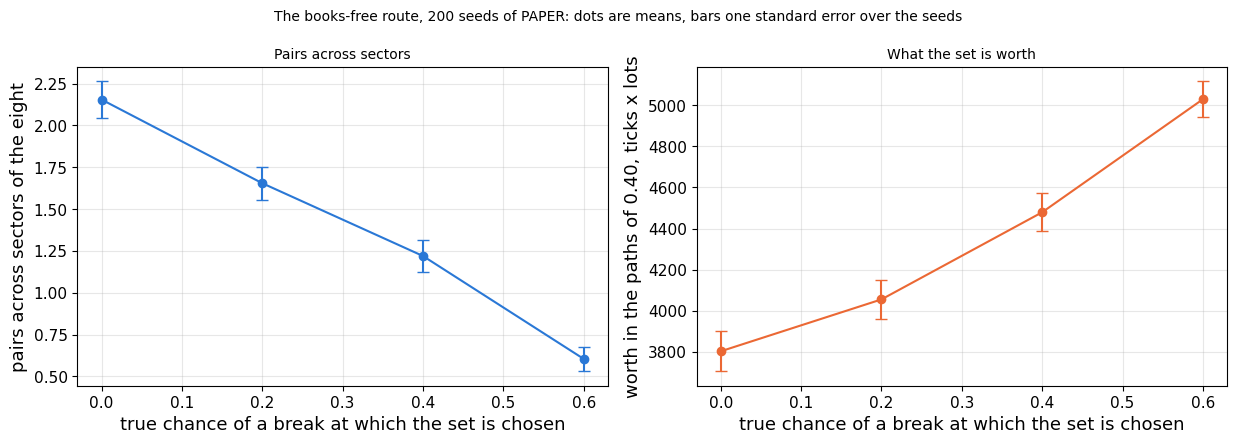

In [15]:
pairs_at_fair, pairs_at_cheap = in_path(pairs_paper_frame, DEAL_FAIR), in_path(pairs_paper_frame, DEAL_CHEAP)
# The four sets chosen from raw values (the rest of the frame are 2b's cleaned cells).
pairs_own = pairs_at_fair[pairs_at_fair.row.isin([set_name(b) for b in FREE_BREAKS])]

# 2a. For each true chance of a break: the completions in the formation window, how many of the eight pairs are across
# sectors, and what the set is worth traded in the paths of 0.40 (fair values, before any cost).
pairs_dose = {}
for b in FREE_BREAKS:
    window = pairs_paper_windows[pairs_paper_windows.breaks == b]
    own = pairs_own[pairs_own.row == set_name(b)]
    assert list(window.seed) == list(own.seed), f'breaks {b}: the windows and the sets are not on the same seeds'
    pairs_dose[b] = dict(
        completed=window.completed.mean(),
        completed_se=se_of(window.completed),
        cross=own.cross.mean(),
        cross_se=se_of(own.cross),
        cross_positive=int((own.cross > 0).sum()),
        worth=own.pnl.mean(),
        worth_se=se_of(own.pnl),
        seeds=len(own),
    )
pairs_dose = pd.DataFrame(pairs_dose).T.astype({'cross_positive': int, 'seeds': int})
pairs_dose.index.name = 'breaks'
completed = pairs_paper_windows.pivot(index='seed', columns='breaks', values='completed')
assert (completed.diff(axis=1).iloc[:, 1:] <= 0).all().all(), (
    'completions fall (or stay) as the true chance of a break rises'
)
print(
    f'The route on {pairs_own.seed.nunique()} seeds of PAPER: the eight pairs chosen from the first {FORM:,} decisions '
    f'at each true chance of a break, traded {SPAN:,.0f} units after {PAIRS_BURN:,.0f} in the paths of '
    f'breaks {DEAL_FAIR:.2f}, on fair values, no costs.\n'
)
print(
    shown(
        pairs_dose,
        keep=['completed', 'completed_se', 'cross', 'cross_se', 'cross_positive', 'worth', 'worth_se'],
        completed='.1f',
        cross='.2f',
        worth=',.0f',
    )
)
print(
    '\ncompleted: deals completed in the formation window; cross: of the eight pairs, those across sectors, and '
    "cross_positive: the seeds with any; worth: the set's P&L over the span; each with its standard error (_se) over "
    'the seeds.'
)

# The steps of the dial, seed by seed: each less the next lower, in the paths of 0.40, and the comparison of notebook 15
# (the set of 0.40 less the set of 0.20) in both paths. `cross` is how the number of pairs across sectors changes.
steps = {
    'set of 0.20 less set of 0.00': (set_name(0.2), set_name(0.0)),
    'set of 0.40 less set of 0.20': (set_name(0.4), set_name(0.2)),
    'set of 0.60 less set of 0.40': (set_name(0.6), set_name(0.4)),
}
print(f'\nEach set less the next lower, seed by seed, in the paths of breaks {DEAL_FAIR:.2f}:\n')
print(shown_paired(paired_table(pairs_at_fair, steps, 'cross'), 'cross', cross='.2f'))
pairs_gap_fair = lead_of(pairs_at_fair, set_name(DEAL_FAIR), set_name(DEAL_CHEAP))
pairs_gap_cheap = lead_of(pairs_at_cheap, set_name(DEAL_FAIR), set_name(DEAL_CHEAP))
print(
    f'\nThe set of 0.40 less the set of 0.20, which notebook 15 measured in the market of {DEAL_CHEAP:.2f}: in the '
    f'paths of {DEAL_FAIR:.2f} {said(pairs_gap_fair)}; in the paths of {DEAL_CHEAP:.2f} '
    f'{said(pairs_gap_cheap)}.'
)
print(
    f'Is a set worth more in the market it was chosen in? The set of 0.40 less the set of 0.20, in the paths of '
    f'{DEAL_FAIR:.2f} less the same in the paths of {DEAL_CHEAP:.2f}: '
    f'{said(pairs_gap_fair - pairs_gap_cheap)}.'
)

# The dial as a line: each seed's least-squares slope of the cross count, and of the worth, on the true chance of a
# break, over the four sets, per 0.2 of the true chance.
pairs_slopes = {}
for column in ('cross', 'pnl'):
    wide = pairs_own.pivot(index='seed', columns='b_set', values=column)[list(FREE_BREAKS)]
    pairs_slopes[column] = pd.Series(np.polyfit(FREE_BREAKS, wide.to_numpy().T, 1)[0] * 0.2, index=wide.index)
print(
    f'Per 0.2 of the true chance of a break, a set has {pairs_slopes["cross"].mean():+.2f} pairs across sectors '
    f'(se {se_of(pairs_slopes["cross"]):.2f}) and is worth {pairs_slopes["pnl"].mean():+,.0f} '
    f'(se {se_of(pairs_slopes["pnl"]):.0f}): each seed\'s least-squares slope over its four sets, then the mean and '
    'the standard error over the seeds.'
)

# What a pair across sectors makes against one within a sector, over the four sets chosen from raw values, in the paths
# of 0.40: the pairs themselves, and seed by seed (the difference of the two means a seed, in the seeds that have both).
each = pairs_own.explode(['made', 'crosses'])[['seed', 'made', 'crosses']].astype({'made': float, 'crosses': int})
pairs_kind = each.groupby('crosses').made.agg(['mean', 'std', 'size'])  # by pairs within (0) and across (1)
across, within = pairs_kind.loc[1], pairs_kind.loc[0]
pairs_by_seed = each.groupby(['seed', 'crosses']).made.mean().unstack().dropna()
print(
    f'\nA pair across sectors makes {across["mean"]:+,.0f} (sd {across["std"]:,.0f}, {across["size"]:,.0f} pairs) and '
    f'one within a sector {within["mean"]:+,.0f} (sd {within["std"]:,.0f}, {within["size"]:,.0f} pairs). Seed by seed, '
    f'across less within: {said(pairs_by_seed[1] - pairs_by_seed[0])} '
    f'(the {len(pairs_by_seed)} seeds with a pair across sectors).'
)

# How much of the gap is the pairs across sectors? The gap of each seed on how many more pairs across sectors the set of
# 0.40 has than the set of 0.20 (a description: a line through the seeds), and the gap on the seeds where the two sets
# have as many.
pairs_more = (
    pairs_own[pairs_own.row == set_name(0.4)].set_index('seed').cross
    - pairs_own[pairs_own.row == set_name(0.2)].set_index('seed').cross
)
pairs_line = np.polyfit(pairs_more, pairs_gap_fair.loc[pairs_more.index], 1)  # the slope a pair, and the intercept
pairs_equal = pairs_gap_fair[pairs_more[pairs_more == 0].index]
pairs_more_r = np.corrcoef(pairs_more, pairs_gap_fair.loc[pairs_more.index])[0, 1]
print(
    f'The set of 0.40 less the set of 0.20 on how many more pairs across sectors it has: {pairs_line[0]:+,.0f} a pair '
    f'(intercept {pairs_line[1]:+,.0f}, correlation {pairs_more_r:+.2f}). On the {len(pairs_equal)} seeds where the '
    f'two sets have as many, the gap is {said(pairs_equal)}.'
)

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
left.errorbar(pairs_dose.index, pairs_dose.cross, yerr=pairs_dose.cross_se, color=BLUE, marker='o', capsize=4)
left.set_xlabel('true chance of a break at which the set is chosen')
left.set_ylabel('pairs across sectors of the eight')
left.set_title('Pairs across sectors', fontsize=10)
right.errorbar(pairs_dose.index, pairs_dose.worth, yerr=pairs_dose.worth_se, color=ORANGE, marker='o', capsize=4)
right.set_xlabel('true chance of a break at which the set is chosen')
right.set_ylabel(f'worth in the paths of {DEAL_FAIR:.2f}, ticks x lots')
right.set_title('What the set is worth', fontsize=10)
fig.suptitle(
    f'The books-free route, {pairs_own.seed.nunique()} seeds of PAPER: dots are means, bars one standard error '
    'over the seeds',
    fontsize=10,
)
fig.tight_layout()
plt.show()

**How to read the dial.** Everything above is the route's, on fair values and before costs. The set of 0.40 less the set of 0.20, traded in the paths of 0.40, is this section's measure of the comparison that notebook 15 made in a market, on 200 seeds that nothing was chosen on: it is a plain paired difference with a standard error over the seeds, and the text says what it is (more than two standard errors above 0, or not), and nothing about a cause. The causal part is the mechanism of the section's opening, and what the dial can show of it is that the completions and the pairs across sectors move together along it. The route's figure is not the market's; 2c is where they meet.

**The dial: the completions and the pairs across sectors fall in steps of about one size, and the worth of a set rises in steps that grow.** At true chances of a break of 0, 0.2, 0.4 and 0.6 the completions in the formation window are 18.5 (standard error 0.3), 14.7 (se 0.3), 11.0 (se 0.2) and 7.3 (se 0.2), steps of 3.8, 3.7 and 3.7 (plain differences of the printed means). The pairs across sectors among the eight are 2.15 (se 0.11), 1.66 (se 0.10), 1.22 (se 0.09) and 0.60 (se 0.07), and some pair is across sectors in 161, 143, 118 and 63 of the 200 seeds. Seed by seed, each set has 0.50 (se 0.08), 0.43 (se 0.07) and 0.61 (se 0.08) fewer pairs across sectors than the set of the next lower true chance, and the line through a seed's four sets falls by 0.51 pairs across sectors (se 0.04) per 0.2: about half a pair a step, a line and not a step, as the prediction above said. The worth of a set in the paths of 0.40 is 3,803 (se 97), 4,055 (se 96), 4,479 (se 92) and 5,029 (se 87), and the line through a seed's four sets rises by +410 (se 34) per 0.2, the prediction's "about 400". The steps themselves are not of one size. Each set less the next lower is +252 (se 67, 120 of 200 seeds positive), +424 (se 72, 133 of 200) and +550 (se 75, 138 of 200), each more than three standard errors above 0 (plain ratios) and each larger than the last, so the worth rises along a curve that steepens, and the line's +410 summarizes it. What the dial shows of the mechanism is that the completions and the pairs across sectors move together along it, with the worth against them. It does not show that one makes the other, because the dial changes how often a deal completes and how often it breaks together; 2b is where the steps are taken out.

**The set of 0.40 is worth more than the set of 0.20 in both paths, and about as much more in one as in the other.** Traded in the paths of 0.40 it is worth +424 (se 72, t 5.87, 133 of 200 seeds positive) more, and in the paths of 0.20, where notebook 15 made the comparison, +442 (se 70, t 6.36, 134 of 200): each more than two standard errors above 0. Notebook 15's market gave +446 (se 143) for the blind trader in the market of 0.20. The route's +442 is of a similar size (the plain difference is -4, which is 0.03 of the larger standard error), and it is not that figure again: it is on fair values, before costs, on 200 seeds that nothing was chosen on, where notebook 15's was in the market, after costs, on eight. The route leaves out the costs, the rounding of 2.5 lots to whole lots, and the order books (the bounce of the mids and the impact of its own orders). It says what the pairs are worth on fair values and not what a market gives; 2c is where the market is set beside it. The home effect, the first of the two figures less the second, is -18 (se 31, t -0.58, 99 of 200 seeds positive), within one standard error of 0. A set is not shown to be worth more in the market it was chosen in, as the head cell predicted, which is why every later table trades the sets in one market, the paths of 0.40.

**A pair across sectors makes about 400 less than a pair within a sector, and the pairs across sectors are part of the gap and not all of it.** Of the 6,400 pairs in the dial's four sets on the 200 seeds, the 1,127 across sectors make +225 a pair on average (sd 445) and the 5,273 within a sector +611 (sd 329). Seed by seed, a pair across sectors less one within a sector is -401 (se 30, t -13.54, 28 of 169 seeds positive), over the 169 seeds that have a pair across sectors. So a pair across sectors costs a set about 400 a pair. That is a comparison of the pairs that the dial chose, and a pair's worth here is partly what chose it: a pair across sectors is in the best eight by a draw of the window. On how much of the gap that is, the gap on the difference in pairs across sectors between the two sets has a slope of -420 a pair (intercept +241, correlation -0.43). That is a description over seeds and not a causal split. On the 103 seeds where the two sets have as many pairs across sectors, the gap is +271 (se 86, t 3.14, 61 of 103 seeds positive): smaller than +424, and more than three standard errors above 0, so the gap does not go away when the pairs across sectors do not differ. Those 103 seeds are picked by an outcome, which makes that a description too. What is left on them is not the hedge alone, because the two sets also differ in which pairs within a sector they hold; 2b is the section's separation of the choice and the hedge, and finds that the two overlap.

The figure's two panels draw the dial table's lines, with one standard error over the seeds as bars: on the left the pairs across sectors against the true chance of a break at which the set is chosen, falling along a line, and on the right the worth of the set in the paths of 0.40, rising and steepening. The route took 10.2 core-minutes for its 224 seeds (200 of `PAPER` and 24 of `NEW`), 2.7 core-seconds a seed (sd 0.1) with its four true chances, against the opening's estimate of about 14 core-minutes at about 4 core-seconds a seed. A market run takes about 50 seconds of one core (the opening's figure; 2c's 24 runs took 20.4 core-minutes), so a seed of the route costs about 0.05 of one market run (a plain ratio of 2.7 to 50), which is why 200 seeds at four true chances are cheap beside a market's.

### 2b. Which Half Does It: the Choice or the Hedge

**The question.** A completed deal's step damages a pair that holds its target in two ways: through the choice (the pair looks far apart over the formation window, so it is dropped from the best eight, and some pair across sectors takes its place) and through the hedge (the least-squares ratio of the two legs is fitted on a window that holds the step, so it is not the ratio the books' loadings give). The set of 0.40 is worth more than the set of 0.20, and the explanation tested is that its formation holds fewer completed steps. Which half of that is the choice, and which the hedge?

**Cleaned values.** The route can take the steps out, because it reads them: a completed deal sets its target's level to the offer's (`FactorValues.level`, which is the sum of the steps so far, from the path's start), and a *cleaned* path is the fair values less that sum, decision by decision. Every completed deal's permanent step is out of it; the humps that a deal puts on its target while it is on (60 ticks at the announcement, drifting in) stay, and weigh about a tenth of a permanent step in the distance a pair is chosen by. The library is read and not changed.

**A cleaned set is a control no trader can have.** A step is the offer's worth less what the target is worth on its own, and what the target is worth on its own is never seen: not in the mids, not in the news (the offer is announced, the target's value without it is not). So a set chosen from cleaned values, or hedged on them, is not a trader's. It says where the damage is, and not how to avoid it; what a trader could do is a chooser that reads the news and re-bases a target after a completion, which this notebook does not build.

**The 2 x 2.** At a true chance of a break of 0.20 and at 0.40, four sets of eight pairs each: the pairs chosen from raw fair values or from cleaned ones, by hedge ratios fitted on raw values or on cleaned ones. The raw-and-raw cell is 2a's own set. Every set is traded on raw fair values in the paths of 0.40, as in 2a, so that the sets differ by their pairs alone, and each is on the same seeds. The cell prints what each set is worth; what cleaning adds to each set; the set of 0.40 less the set of 0.20 in each cell (the gap); and how the gap moves when its halves are cleaned, seed by seed, each contrast being the gap of the cleaned cell less the gap of raw values, so that a contrast below 0 is a gap narrowed: cleaning the choice, cleaning the hedge, both, and both less the two halves alone (the interaction). If the choice were all of it, cleaning it would take the gap away and cleaning the hedge would not; if the hedge were all of it, the other way round; and if each does part, both together do the sum, and the interaction is 0.

**What was explored before, and on which seeds.** On seeds 9 to 100, on the route, a single steps-removed set (choice and hedge both cleaned), chosen at 0.20, beat the set chosen at 0.20 from raw values by +1,516 (se 144): about 3.6 times the gap of 418 that it was meant to explain (a plain ratio, 3.63). A steps-removed set recovers more than the damage that the gap measures, because the deals damage a formation at either true chance, so "the steps-removed set recovers the gap" proves too much, and a 2 x 2 replaced it. On those seeds the gap in each cell was +418 for raw choice and raw hedge, +412 with the choice cleaned, +349 with the hedge cleaned and +107 with both: neither half alone closed the gap, and both together did. That was one route, on paper, and no second route reproduced it, so it is a hypothesis here, to be read as the 200 new seeds give it. One piece of evidence from the market: on real formations on seeds 9 to 24, the hedge of the 74 pairs within a sector that were chosen at both 0.2 and 0.4 was more bent at 0.2 (a hedge error, one less the smaller leg over the larger, where the true ratio is 1, of 0.155 against 0.134: +0.021, se 0.012). So the hedges are not bent equally in the two markets, as a first reading of notebook 15 had it.

**What the cell prints, and what it does not claim.** The contrasts are paired by seed, with standard errors over the seeds, and read as they come out. The route is before costs and on fair values, as in 2a. The 2 x 2 says which half of the gap on paper is which; it does not say what a trader that cannot clean its values would gain by choosing differently.

What a set is worth, chosen at the true chance of a break `breaks` from raw or cleaned values and hedged on raw or cleaned values, traded on raw fair values in the paths of 0.40, 200 seeds of PAPER (before any cost; the cleaned sets are controls no trader can have):

                 cell breaks worth worth_se cross
raw choice, raw hedge   0.20 4,055       96  1.66
raw choice, raw hedge   0.40 4,479       92  1.22
       choice cleaned   0.20 4,207       83  0.00
       choice cleaned   0.40 4,528       78  0.00
        hedge cleaned   0.20 4,650       99  1.66
        hedge cleaned   0.40 4,989       88  1.22
         both cleaned   0.20 5,477       75  0.00
         both cleaned   0.40 5,545       73  0.00

worth_se: the standard error of the worth over the seeds; cross: of the eight pairs, those across sectors.
Pairs across sectors among the 6400 pairs of the sets chosen from cleaned values: 0.

What cleaning adds to a set, seed by seed, in the paths of 0.40:

                      

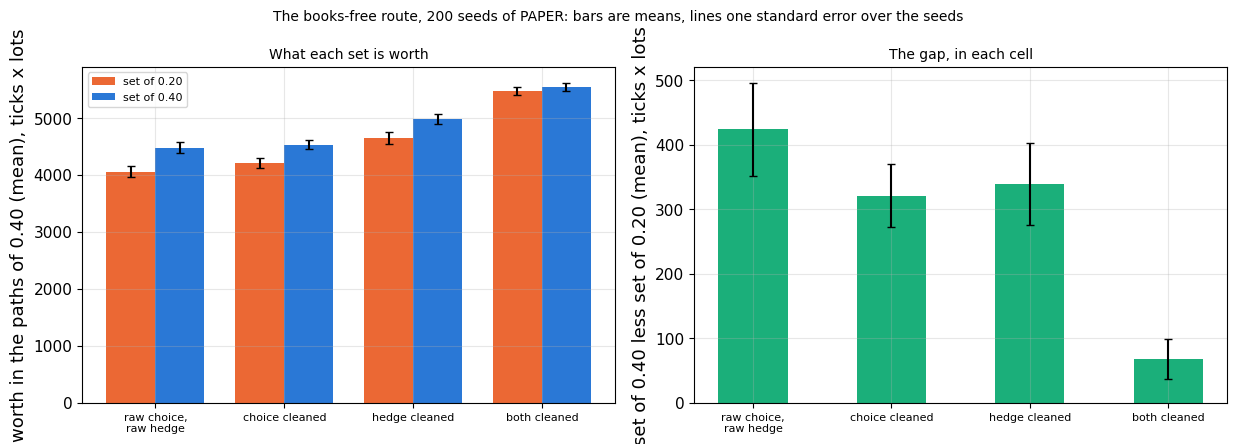

In [16]:
# 2b. The 2 x 2 of choice and hedge, at the true chances of a break of 0.20 and 0.40: the eight pairs chosen from raw
# fair values or from fair values with the completed deals' steps taken out, and hedged by least squares on raw or on
# cleaned values. Every set is traded on raw fair values, in the paths of 0.40, so the sets differ by their pairs alone.
# The cleaned sets are controls that no trader can have: the step of a completed deal is the difference between the
# offer's worth and the target's worth on its own, and the target's worth on its own is never seen. (pairs_paper_frame
# is the route's frame of 2a; pairs_at_fair its rows traded in the paths of 0.40.)
PAIRS_CELLS = {
    'raw choice, raw hedge': ('raw', 'raw'),
    'choice cleaned': ('clean', 'raw'),
    'hedge cleaned': ('raw', 'clean'),
    'both cleaned': ('clean', 'clean'),
}
HEDGE_DIAL = sorted(FREE_PATHS)  # the two true chances of the 2 x 2: 0.20 and 0.40


def named(b, label):
    return set_name(b, *PAIRS_CELLS[label])


pairs_levels = []
for label in PAIRS_CELLS:
    for b in HEDGE_DIAL:
        rows = pairs_at_fair[pairs_at_fair.row == named(b, label)]
        pairs_levels.append(
            dict(cell=label, breaks=b, worth=rows.pnl.mean(), worth_se=se_of(rows.pnl), cross=rows.cross.mean())
        )
pairs_levels = pd.DataFrame(pairs_levels)
cleaned_sets = pairs_at_fair[pairs_at_fair.row.str.contains('cleaned')]
print(
    f'What a set is worth, chosen at the true chance of a break `breaks` from raw or cleaned values and hedged on raw '
    f'or cleaned values, traded on raw fair values in the paths of {DEAL_FAIR:.2f}, {pairs_paper_frame.seed.nunique()} '
    'seeds of PAPER (before any cost; the cleaned sets are controls no trader can have):\n'
)
print(
    pairs_levels.to_string(
        index=False,
        formatters={
            'breaks': '{:.2f}'.format,
            'worth': '{:,.0f}'.format,
            'worth_se': '{:,.0f}'.format,
            'cross': '{:.2f}'.format,
        },
    )
)
print('\nworth_se: the standard error of the worth over the seeds; cross: of the eight pairs, those across sectors.')
chosen_clean = cleaned_sets[cleaned_sets.choice == 'clean']
print(
    f'Pairs across sectors among the {COUNT * len(chosen_clean)} pairs of the sets chosen from cleaned values: '
    f'{int(chosen_clean.cross.sum())}.'
)

# What cleaning does to a set's worth: the set of the cleaned cell less the same true chance's set of raw values.
pairs_cleaning = {
    f'{label}, set of {b:.2f}, less raw choice and raw hedge': (named(b, label), named(b, 'raw choice, raw hedge'))
    for b in HEDGE_DIAL
    for label in list(PAIRS_CELLS)[1:]
}
print('\nWhat cleaning adds to a set, seed by seed, in the paths of 0.40:\n')
print(shown_paired(paired_table(pairs_at_fair, pairs_cleaning, 'cross'), 'cross', cross='.2f'))

# The gap in each cell: the set of 0.40 less the set of 0.20, seed by seed.
pairs_hedge_gaps = {
    label: lead_of(pairs_at_fair, named(DEAL_FAIR, label), named(DEAL_CHEAP, label)) for label in PAIRS_CELLS
}
pairs_hedge_table = pd.DataFrame.from_dict(
    {
        label: dict(zip(('pnl', 'se', 'positive', 'seeds'), paired_of(gap), strict=True))
        for label, gap in pairs_hedge_gaps.items()
    },
    orient='index',
)
print(f'\nThe set of {DEAL_FAIR:.2f} less the set of {DEAL_CHEAP:.2f}, seed by seed, in each cell:\n')
print(shown_paired(pairs_hedge_table))

# How the gap changes when a half is cleaned: the gap of the cleaned cell less the gap of raw values, seed by seed.
pairs_raw_gap = pairs_hedge_gaps['raw choice, raw hedge']
pairs_contrasts = {
    'gap with the choice cleaned, less the gap with raw values': pairs_hedge_gaps['choice cleaned'] - pairs_raw_gap,
    'gap with the hedge cleaned, less the gap with raw values': pairs_hedge_gaps['hedge cleaned'] - pairs_raw_gap,
    'gap with both cleaned, less the gap with raw values': pairs_hedge_gaps['both cleaned'] - pairs_raw_gap,
    'gap with both cleaned, less the two halves alone (the interaction)': (
        pairs_hedge_gaps['both cleaned']
        - pairs_hedge_gaps['choice cleaned']
        - pairs_hedge_gaps['hedge cleaned']
        + pairs_raw_gap
    ),
}
print('\nHow the gap moves when its halves are cleaned, seed by seed:\n')
for label, contrast in pairs_contrasts.items():
    print(f'{label}: {said(contrast)}')
print(f'\nThe gap with raw values, for reference: {said(pairs_raw_gap)}.')

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
spots, width = np.arange(len(PAIRS_CELLS)), 0.38
for shift, b, color in ((-width / 2, DEAL_CHEAP, ORANGE), (width / 2, DEAL_FAIR, BLUE)):
    one = pairs_levels[pairs_levels.breaks == b]
    left.bar(spots + shift, one.worth, width, yerr=one.worth_se, color=color, capsize=3, label=f'set of {b:.2f}')
left.set_xticks(spots, [label.replace(', ', ',\n') for label in PAIRS_CELLS], fontsize=8)
left.set_ylabel(f'worth in the paths of {DEAL_FAIR:.2f} (mean), ticks x lots')
left.set_title('What each set is worth', fontsize=10)
left.legend(fontsize=8)
right.bar(spots, pairs_hedge_table.pnl, 0.5, yerr=pairs_hedge_table.se, color=AQUA, capsize=3)
right.set_xticks(spots, [label.replace(', ', ',\n') for label in PAIRS_CELLS], fontsize=8)
right.set_ylabel(f'set of {DEAL_FAIR:.2f} less set of {DEAL_CHEAP:.2f} (mean), ticks x lots')
right.set_title('The gap, in each cell', fontsize=10)
fig.suptitle(
    f'The books-free route, {pairs_paper_frame.seed.nunique()} seeds of PAPER: bars are means, lines one standard '
    'error '
    'over the seeds',
    fontsize=10,
)
fig.tight_layout()
plt.show()

**Cleaning the choice removes the pairs across sectors, and cleaning the hedge adds the most.** Among the 6,400 pairs of the sets chosen from cleaned values, 0 are across sectors, where the sets chosen from raw values have 1.66 and 1.22 a set at 0.20 and 0.40: with the steps out, nothing drops a pair within a sector from the best eight, as the distance should give. Traded in the paths of 0.40, the sets of 0.20 and of 0.40 are worth 4,055 (standard error 96) and 4,479 (se 92) with raw choice and raw hedge, 4,207 (se 83) and 4,528 (se 78) with the choice cleaned, 4,650 (se 99) and 4,989 (se 88) with the hedge cleaned, and 5,477 (se 75) and 5,545 (se 73) with both cleaned. What cleaning adds to a set, seed by seed, over the raw set of the same true chance: the choice alone +152 (se 84, 110 of 200 seeds positive) at 0.20 and +49 (se 76, 97 of 200) at 0.40; the hedge alone +595 (se 52, 164 of 200) and +510 (se 46, 159 of 200); both +1,422 (se 94, 176 of 200) and +1,066 (se 85, 163 of 200). The hedge adds more than the choice at both true chances, and the choice's addition is under two standard errors from 0 at both (plain ratios of 1.8 and 0.6). Both cleaned is a control that no trader can have and, like the one set of the earlier design, it adds more than the gap itself: +1,422 and +1,066 against +424, about 3.4 and 2.5 times it (plain ratios). That is expected, since the deals damage a formation at either true chance, so recovering more than the gap does not make the gap the whole of the damage.

**The gap is more than two standard errors above 0 in all four cells.** The set of 0.40 less the set of 0.20, seed by seed, is +424 (se 72, 133 of 200 seeds positive) with raw choice and raw hedge, +321 (se 49, 139 of 200) with the choice cleaned, +340 (se 64, 131 of 200) with the hedge cleaned and +67 (se 31, 114 of 200) with both cleaned. The first three are many standard errors from 0; the fourth is 2.2 (a plain ratio), only just, and is small beside +424. The raw cell is 2a's comparison again, from the same sets, and its figure is the same as 2a's: +424 (se 72, 133 of 200).

**Cleaning either half alone does not narrow the gap by two standard errors; cleaning both does, by more than the two alone, so the channels overlap.** The contrasts, each the gap of the cleaned cell less the gap of raw values, so that a contrast below 0 is a gap narrowed: choice cleaned -103 (se 73, t -1.42, 95 of 200 seeds positive), hedge cleaned -84 (se 50, t -1.68, 98 of 200), both cleaned -357 (se 82, t -4.36, 73 of 200), and the interaction, both less the two halves alone, -169 (se 55, t -3.08, 78 of 200). Each single contrast is within two standard errors of 0. The 200 seeds do not separate either from 0, and do not show that either is 0: each cleaning leaves about three quarters of the gap, +321 and +340 against +424 (plain ratios of 0.76 and 0.80). Both cleaned narrows the gap by -357, which is more than the two alone (-103 and -84 sum to -187, a plain sum), and the difference is the interaction, -169, more than three standard errors from 0. The design said that if each half did part, both together would do the sum and the interaction would be 0; it is not. So the two channels overlap, as the premise review put it: a completed step either gets a pair dropped from the best eight or, if the pair is kept, bends its hedge, so cleaning one channel leaves the step to act through the other, and only cleaning both narrows the gap by much. The cell added after 2c (the 24 new seeds against the 200) counts how many of the eight pairs the set of 0.20 and the set of 0.40 have in common: 5.59 (se 0.10) when both are chosen from raw values, and 7.16 (se 0.05) when both are chosen from cleaned values, hedged on raw or on clean alike (which pairs a set chooses does not depend on the hedge). So the gap with the choice cleaned is the hedge's damage on nearly one set of pairs, and the gap with the hedge cleaned is the choice's damage with clean hedges. No share of the gap belongs to "the choice" or to "the hedge". What the 2 x 2 puts the gap on is the completed steps, through either channel.

Against the explorations on seeds 9 to 100 (the gap in each cell +418, +412, +349 and +107), the pattern is the same in kind. There neither single cleaning closed the gap and both together did, leaving +107; here neither single contrast is separated from 0, and both together narrow the gap by -357 (t -4.36), leaving +67. The choice cleaned leaves less here than there (+321 against +412) and the hedge cleaned about the same (+340 against +349), so which of the two leaves more is the other way round (+321 and +340 here, +412 and +349 there), and here the two differ by less than a standard error of either. So which half narrows the gap more is not a stable result, and none is claimed. That neither single contrast is separated from 0 is what these seeds show, and it is not the same as neither narrowing the gap. The cleaned sets are controls that no trader can have, because a step needs the target's value on its own, which is never seen: this says where the damage is, and not how to avoid it.

The figure's left panel is the worth of each of the eight sets (the set of 0.20 in orange and the set of 0.40 in blue, one standard error over the seeds as lines), and its right panel is the gap in each cell with one standard error as bars; the right panel is the table above it.

### 2c. Does the Market Agree?

**The question.** The route is a measurement on fair values, with no order books, no costs and no rounding. Is the comparison it measures the one the market makes? 2c sets the market's figures beside the route's, on the 24 seeds of section 1.

**The two comparisons, each in the market and in the route.**

- *A, in the market of 0.20.* The blind trader on the pairs that the trader of the same seed chose in the market of 0.40, less the blind trader on its own pairs there. The market's figure is already made, by section 1's same-pairs rows and its blind row at 0.20 (the comparison notebook 15 made, on `NEW`). The route's is the set of 0.40 less the set of 0.20, traded in the paths of 0.20, on the same seeds. In the market this is also the pairs and the bet: on the pairs of 0.40 the blind trader is expected to hold more net short lots of deal targets, which at 0.20 loses on average, so the market's A is the pairs less a bet. The route's figure is not free of a bet either: it trades fair values, and a target's fair value holds the deal's premium, its drift and its fall at a break, so each set carries some bet in the paths of 0.20. How much each carries is measured in the cell added after 2c (the 24 new seeds against the 200); this cell does not separate it.
- *B, in the market of 0.40.* The blind trader on the pairs that the trader of the same seed chose in the market of 0.20, less the blind trader on its own pairs there. Here the price of a break is the true chance, so the bet is fair on any set of pairs, and the difference is the pairs alone. The route's counterpart is the set of 0.20 less the set of 0.40, traded in the paths of 0.40. This row is new, and is the one that this cell runs: 24 market runs, one a seed of `NEW`.

Each is run with the whole rows of weights, each pair's hedge included, handed to the trader by a chooser that returns them whatever history it is shown (the same `Fixed` as section 1's), so the trader chooses nothing. The cell asserts that each run trades the rows it was handed, that its deals are those of section 1's blind trader at 0.40 on the same seed (the same deals, and those that break at 0.20 break at 0.40), and that the chooser changes nothing by itself, which is not run again here: section 1's cell on the same pairs (1c (4)) handed the blind trader at 0.40 its own pairs through the same `Fixed` and asserted that it makes its row's P&L, lots and entries to the last digit, on the first eight seeds of `NEW`, the first seed among them. It also measures the market's decisions, how far apart they are in the formation and when the 2,000th comes, and asserts that they are where the route samples.

**What the printed figures are.** For each comparison and each seed, the market's figure and the route's, the standard error of each over the 24 seeds, the market less the route seed by seed (what the order books, the costs, the rounding and the difference between the market's sets and the route's sets add to the route's figure; the route carries a bet too, so it is not "what the bet adds"), and the correlation over the seeds with its 95% interval. And the check's power: the market figure's standard error, the route's figure on the 200 seeds of `PAPER` (which is not these 24, and is the best estimate of what the market's figure should be if the route is right) in units of that standard error, and the probability that a two-sided test at 5% would separate a true figure of that size from 0 on 24 seeds. That probability is computed as a noncentral t's: the true figure is taken to be the route's on `PAPER`, its standard error to be the market figure's own over these 24 seeds, and the probability is the share of a noncentral t distribution on 23 degrees of freedom, with that ratio as its shift, that falls beyond the two-sided 5% cut of the t. It is the cell's figure from these seeds and the printed standard error, and the head of section 2's power from seeds 1 to 100 (from a per-seed spread of about a thousand ticks) is another computation that this cell does not repeat; the two need not agree, and the cell prints the one it computes. **This is a check of sign and size, and not the test**: the test is the route on 200 seeds. What the check can do is catch a route that disagrees with the market in sign, or by a large factor, and give a correlation seed by seed; it cannot confirm a size that is within a standard error or two of what it would be if the route were wrong by half.

**What was explored before.** On seeds 1 to 8 the route's figure for A tracked the market's seed by seed (correlation +0.85, the figures in the opening), and nothing was known of B. Both are on new seeds here.

Checked: every run trades the rows it was handed; its deals are those of section 1's blind trader on the same seed at breaks 0.40, nested with the 0.20 row; the chooser, which is section 1's `Fixed`, was checked in 1c (4) on 8 seeds (the first seed of NEW among them).
The market's decisions are 5.0046 apart on average in the formation, against the route's 5.002, and its 2,000th decision came at 10,004.2 (10,003.7 to 10,004.5) against the route's 10,004.0: the route samples the fair values where the trader decides, to a few tenths of a unit.

The market against the route, on the 24 seeds of NEW, seed by seed:

A, in the market of 0.20: the pairs of 0.40 less its own
  the market   +38 (se 177, t 0.21, 11 of 24 seeds positive)
  the route    -94 (se 186, t -0.50, 12 of 24 seeds positive)
  market less route, seed by seed: +132 (se 130, t 1.01, 13 of 24 seeds positive)
  correlation over the seeds, market with route: +0.74 (95% interval +0.49 to +0.88)
  what this check can tell: the mark

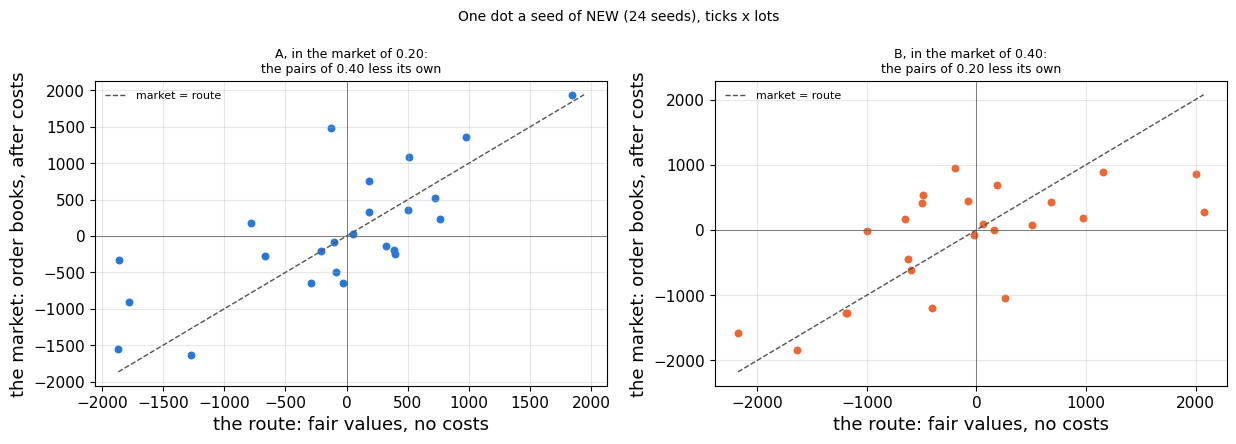

In [17]:
# 2c. Does the market agree with the route? Reads section 1's runs on NEW: news_test_frame (the blind
# trader and the reader at breaks 0.20, each on its own market's pairs), news_fair_frame (the same at 0.40) and
# news_same_frame (the market of 0.20 traded with the pairs of the market of 0.40), by the rows' names (news_test_blind,
# news_fair_blind, news_same_blind), with run_rows' columns and pairs_extra's (pnl, costs, before_costs, weights, pairs,
# deals, end). And the route's frames of 2a (pairs_new_frame: the route on the same seeds). Its one new market row
# is made here: the blind trader on the pairs of the market of 0.20, traded in the market of 0.40, on every seed of NEW.
MARKET_OTHER = f'{news_fair_blind}, pairs of breaks {DEAL_CHEAP:.2f}'  # at 0.40, on the pairs of 0.20 (this cell's)
for frame, row in (
    (news_test_frame, news_test_blind),
    (news_fair_frame, news_fair_blind),
    (news_same_frame, news_same_blind),
):
    assert sorted(frame[frame.row == row].seed) == sorted(NEW), f'section 1 has no row {row!r} on every seed of NEW'


def market_extra(market, trader):
    # pairs_extra, and when the trader's formation ended and how far apart its decisions were: what the route samples.
    times = np.array([h[0] for h in trader.history])
    return {
        **pairs_extra(market, trader, PAIRS_BURN),
        'fit_at': float(times[FORM - 1]),
        'gap': float(np.diff(times[:FORM]).mean()),
    }


def rows_of(frame, row):
    # The rows of weights that each seed's trader of `row` chose: a dict by seed, as the whole rows of a hand-over.
    got = frame[frame.row == row].set_index('seed').weights
    assert all(len(w) == COUNT for w in got), f'{row!r} chose other than {COUNT} pairs'
    return got.to_dict()


pairs_handed_cheap = rows_of(news_test_frame, news_test_blind)  # the pairs of the market of 0.20, by seed
fair_maker, trader_maker = pairs_row(DEAL_FAIR, RelationTrader)
jobs = [(partial(trader_maker, choose=Fixed(pairs_handed_cheap[seed])), seed) for seed in NEW]
runs = Parallel(n_jobs=-1)(
    delayed(run_one)(fair_maker, make_trader, seed, PAIRS_BURN, SPAN, market_extra) for make_trader, seed in jobs
)
pairs_other_frame = pd.DataFrame([{'row': MARKET_OTHER, **run} for run in runs])
assert not (pairs_other_frame.warm_up > PAIRS_BURN).any(), 'the burn cuts into the warm-up'
assert (pairs_other_frame.pushed == 0).all(), 'the floor pushed the first factor in a run'

# What must hold for the table to mean anything. Every run trades the rows it was handed; the deals are those of
# section 1's blind trader on the same seed at 0.40 and at 0.20 (the same deals, and those that break at 0.20 break at
# 0.40); the chooser makes no difference of its own (1c (4) ran it: the blind trader at 0.40 with its own pairs handed
# over made its row's P&L, lots and entries to the last digit, on CHECK_SEEDS, which hold the first seed of NEW, and
# that cell asserts it); and the market's decisions are where the route put them.
for run in pairs_other_frame.itertuples():
    assert run.weights == pairs_handed_cheap[run.seed], f'seed {run.seed}: not the rows it was handed'
market_runs = pd.concat([news_both_worlds, pairs_other_frame], ignore_index=True)
check_deals(market_runs[market_runs.row.isin([news_fair_blind, MARKET_OTHER])], [news_fair_blind, MARKET_OTHER])
check_deals(market_runs[market_runs.row.isin([news_test_blind, MARKET_OTHER])], [news_test_blind, MARKET_OTHER])
assert NEW[0] in CHECK_SEEDS and (news_same_frame.row == news_check_row).any(), "1c (4) did not check the chooser"
assert abs(pairs_other_frame.gap.mean() - FREE_EVERY) < 0.01, 'the decisions are not where the route puts them'
assert abs(pairs_other_frame.fit_at.mean() - FORM * FREE_EVERY) < 2.0, (
    'the formation does not end where the route has it'
)
print(
    f"Checked: every run trades the rows it was handed; its deals are those of section 1's blind trader on the same "
    f'seed at breaks {DEAL_FAIR:.2f}, nested with the {DEAL_CHEAP:.2f} row; the chooser, which is section 1\'s '
    f"`Fixed`, was checked in 1c (4) on {len(CHECK_SEEDS)} seeds (the first seed of NEW among them)."
)
print(
    f"The market's decisions are {pairs_other_frame.gap.mean():.4f} apart on average in the formation, against "
    f"the route's {FREE_EVERY}, and its {FORM:,}th decision came at {pairs_other_frame.fit_at.mean():,.1f} "
    f"({pairs_other_frame.fit_at.min():,.1f} to {pairs_other_frame.fit_at.max():,.1f}) against the route's "
    f'{FORM * FREE_EVERY:,.1f}: the route samples the fair values where the trader decides, to a few tenths of a '
    'unit.\n'
)


def correlation(a, b):
    # Pearson's r of two series, and the 95% interval of Fisher's z (nan with under four seeds or a perfect fit).
    r = float(np.corrcoef(a, b)[0, 1])
    if len(a) < 4 or abs(r) >= 1:
        return r, math.nan, math.nan
    half = 1.96 / math.sqrt(len(a) - 3)
    return r, math.tanh(math.atanh(r) - half), math.tanh(math.atanh(r) + half)


def power_of(lead, size):
    # The probability that a two-sided test at 5% on these seeds (t on one fewer than their number, the standard error
    # of `lead`, a value a seed) would separate a true figure of `size` from 0: a noncentral t.
    df = len(lead) - 1
    cut, shift = stats.t.ppf(0.975, df), abs(size) / se_of(lead)
    return float(stats.nct.sf(cut, df, shift) + stats.nct.cdf(-cut, df, shift))


pairs_new_cheap, pairs_new_fair = in_path(pairs_new_frame, DEAL_CHEAP), in_path(pairs_new_frame, DEAL_FAIR)
# The two comparisons, each in the market and in the route, a value a seed. A: the blind trader on the pairs of the
# market of 0.40 less on its own pairs, in the market of 0.20 (notebook 15's, section 1's rows). B: the blind trader on
# the pairs of the market of 0.20 less on its own pairs, in the market of 0.40, where the bet is fair (this cell's new
# row). The route's counterparts are the sets of the same seeds traded in the paths of the same market.
pairs_comparisons = {
    f'A, in the market of {DEAL_CHEAP:.2f}: the pairs of {DEAL_FAIR:.2f} less its own': (
        lead_of(market_runs, news_same_blind, news_test_blind),
        lead_of(pairs_new_cheap, set_name(DEAL_FAIR), set_name(DEAL_CHEAP)),
        pairs_gap_cheap.mean(),
    ),
    f'B, in the market of {DEAL_FAIR:.2f}: the pairs of {DEAL_CHEAP:.2f} less its own': (
        lead_of(market_runs, MARKET_OTHER, news_fair_blind),
        lead_of(pairs_new_fair, set_name(DEAL_CHEAP), set_name(DEAL_FAIR)),
        -pairs_gap_fair.mean(),
    ),
}
print(f'The market against the route, on the {len(NEW)} seeds of NEW, seed by seed:\n')
for label, (market_lead, route_lead, expected) in pairs_comparisons.items():
    assert list(market_lead.index) == list(route_lead.index), f'{label}: the market and the route differ in seeds'
    r, low, high = correlation(market_lead, route_lead)
    se, power = se_of(market_lead), power_of(market_lead, expected)
    print(label)
    print(f'  the market   {said(market_lead)}')
    print(f'  the route    {said(route_lead)}')
    print(f'  market less route, seed by seed: {said(market_lead - route_lead)}')
    print(f'  correlation over the seeds, market with route: {r:+.2f} (95% interval {low:+.2f} to {high:+.2f})')
    print(
        f'  what this check can tell: the market figure has standard error {se:,.0f} over {len(market_lead)} seeds; '
        f"the route's figure on the {len(PAPER)} seeds of PAPER is {expected:+,.0f}, {abs(expected) / se:.1f} "
        'standard errors of that; a two-sided 5% test would separate a true figure of that size from 0 with '
        f'probability {power:.2f}. A check of sign and size, and not the test.'
    )

# What the market's figures are made of: before and after costs, as the other tables of this notebook print them.
market_pairs = {
    f'A, the pairs of {DEAL_FAIR:.2f} less its own, breaks {DEAL_CHEAP:.2f}': (news_same_blind, news_test_blind),
    f'B, the pairs of {DEAL_CHEAP:.2f} less its own, breaks {DEAL_FAIR:.2f}': (MARKET_OTHER, news_fair_blind),
}
print('\nThe same two figures in the market, before and after costs, seed by seed:\n')
print(
    shown_paired(
        paired_table(market_runs, market_pairs, 'before_costs', 'costs', 'risk_adjusted_long'),
        'before_costs',
        'costs',
        'risk_adjusted_long',
    )
)
print(
    '\nThe blind trader on the pairs of the other market, a run: '
    f'{pairs_other_frame.net_short.mean():.1f} lots net short in the targets two decisions after an announcement, '
    f"against {news_fair_frame[news_fair_frame.row == news_fair_blind].net_short.mean():.1f} on its own pairs at "
    f'{DEAL_FAIR:.2f} (the edge is 0 at {DEAL_FAIR:.2f}, so neither is a bet).'
)
print()
ran(pairs_other_frame)

fig, panels = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
for panel, (label, (market_lead, route_lead, _)), color in zip(
    panels, pairs_comparisons.items(), (BLUE, ORANGE), strict=True
):
    panel.scatter(route_lead, market_lead, color=color, s=22)
    low = min(route_lead.min(), market_lead.min())
    high = max(route_lead.max(), market_lead.max())
    panel.plot([low, high], [low, high], color=GRAY, lw=1, ls='--', label='market = route')
    panel.axhline(0, color=GRAY, lw=0.5)
    panel.axvline(0, color=GRAY, lw=0.5)
    panel.set_xlabel('the route: fair values, no costs')
    panel.set_ylabel('the market: order books, after costs')
    panel.set_title(label.replace(': ', ':\n'), fontsize=9)
    panel.legend(frameon=False, fontsize=8)
fig.suptitle(f'One dot a seed of NEW ({len(NEW)} seeds), ticks x lots', fontsize=10)
fig.tight_layout()
plt.show()

**A, in the market of 0.20: the market gives +38 on these seeds, the route on the same seeds -94, and the two move together.** The blind trader on the pairs of 0.40 less on its own pairs, in the market of 0.20 (notebook 15's comparison, on `NEW`, after costs), is +38 (standard error 177, t 0.21, 11 of 24 seeds positive). The route's counterpart on the same 24 seeds, the set of 0.40 less the set of 0.20 in the paths of 0.20, is -94 (se 186, t -0.50, 12 of 24). Against the route on the same seeds the signs differ, and the market's figure is about one standard error from it: market less route, seed by seed, is +132 (se 130, t 1.01, 13 of 24). Against the route's +442 on the 200 seeds of `PAPER`, the market's mean is positive, but 0.21 standard errors from 0 with 11 of 24 seeds positive, so its sign is not shown; and it is far below +442 (the discrepancy, next). The correlation over the seeds, market with route, is +0.74 (95% interval +0.49 to +0.88). On 24 seeds that excludes 0 and anything under +0.49: the market and the route rise and fall together from seed to seed. It does not exclude a correlation of +0.5, and it includes the +0.85 of seeds 1 to 8; and a correlation says nothing about size, since +0.74 would hold if the market's figures were twice the route's or half.

Market less route is what the order books, the costs, the rounding and the difference between the market's sets and the route's sets add to the route's figure. The route trades fair values, which hold the deals' premia, falls and drift, so it carries a bet too, and market less route is not "what the bet adds". The cell added after 2c (the 24 new seeds against the 200; a description and not a test) prints it: the deal part of a set's fair values, in the paths of 0.20 on `PAPER`, is -819 (se 49, t -16.65, 24 of 200 seeds positive) for the set of 0.20 and -787 (se 51, t -15.46, 28 of 200) for the set of 0.40, and the route's +442 there splits into a deal part of +32 (se 36, t 0.90, 101 of 200 seeds positive) and the rest, +411 (se 62, t 6.62, 135 of 200). So both sets carry nearly the same bet, the route's gap is not the bet, and market less route is not what the bet adds. The before and after costs table, below the power line, says how much of the market's figure is costs.

**The discrepancy: on the 24 new seeds neither the market nor the route shows the gap.** The route is +442 (se 70, 134 of 200 seeds positive) on `PAPER` in the paths of 0.20 and -94 (se 186, 12 of 24) on `NEW`: the plain difference is 536, with a combined standard error of 199, which is 2.7 of them (printed by the cell added after 2c). The market's +38 is 408 below notebook 15's +446 (se 143), a plain difference that the premise review puts at 1.8 combined standard errors (its figure, which no cell prints). The two agree seed by seed (+0.74 here, +0.68 in B), and the route on these seeds is lower still, so this is not a disagreement between market and route. The premise review reproduced both figures from its own code (-94 and +111 for the route on `NEW`, +442 and +424 on `PAPER`: the same quantity and the same sign). The cell added after 2c draws 200,000 samples of 24 of `PAPER`'s 200 seeds: 0.18% have a mean as low as -94, and 0.44% are as far from `PAPER`'s mean of +442 in either direction, which is 4.3% across ten such comparisons (plain arithmetic, ten being the review's rough count of this notebook's comparisons of this kind and not a number computed here): at the edge of what chance gives, and not the ordinary miss of one time in three that the check's power allows for a market figure, since it is the route itself that fell to -94 on these seeds. In the paths of 0.40, where the route's figure on `NEW` is +111 (se 209), the shares are 5.31% as low and 11.00% as far in either direction (`PAPER` less `NEW` is +313, 1.4 combined standard errors). `NEW` has more of what the mechanism runs on, the completions in the formation at 0.20 less at 0.40: +4.17 (se 0.42, t 9.82, 24 of 24 seeds positive) against +3.73 (se 0.14, t 26.52, 195 of 200) on `PAPER`. Its sets of 0.40 shed fewer pairs across sectors than `PAPER`'s (the set of 0.40 less the set of 0.20: -0.21, se 0.25, t -0.84, 6 of 24 seeds positive, against -0.43, se 0.07, t -5.86, 21 of 200, the two not separated), but `PAPER`'s line of the gap on the completions and on the pairs across sectors (+135 +37 x completions -393 x pairs across sectors), at `NEW`'s own values, gives +369 for `NEW`, and `NEW` gave -94. So the mechanism's own variables do not account for the miss: the draw is odd in the gap itself, and no cause was found. In the paths of 0.20 the gap on `NEW` is a deal part of -87 (se 124) and the rest, -7 (se 164), neither separated from 0. The shortfall from `PAPER` is in the rest in both paths (+411 against -7 in the paths of 0.20 and +415 against +40 in the paths of 0.40, which is 418 and 375 below, 2.4 and 2.1 combined standard errors, plain arithmetic) and not in the deal part, which is within one combined standard error of `PAPER`'s in both (-87 against +32 and +71 against +9). `NEW`'s home effect, +205 (se 75, 16 of 24 seeds positive), is 223 above `PAPER`'s -18 (se 31), which is 2.75 combined standard errors of 81 (plain arithmetic): a second figure of the same seeds that is far from `PAPER`'s, and not an account of the first. The premise review found no structural cause, as seeds differ only in their random streams, so the reading left is an unusual draw of seeds. The route on notebook 15's own eight seeds (`FIRST`, a diagnostic; nothing here was chosen on it) gives +491 (se 320, 6 of 8 seeds positive) in the paths of 0.20 and +509 (se 369, 6 of 8) in the paths of 0.40, consistent with notebook 15's market figure at a standard error of 320: the route's gap on those eight is not unusual beside the 200. What this notebook says is that the route shows notebook 15's comparison before costs on 200 seeds, and that the market check on 24 new seeds does not show it, nor does the route on those seeds. It does not say that the market confirms the route's size, that `NEW` refutes the route, or that notebook 15's +446 to +635 replicated in the market: those three figures are one comparison seen three times, and only the blind trader's +446 is 2c's A.

**B, in the market of 0.40: the market's mean has the route's sign, and 24 seeds show neither its sign nor its size.** The blind trader on the pairs of 0.20 less on its own pairs, in the market of 0.40, where the price of a break is the true chance and the bet is fair on any set of pairs, so that the difference is the pairs alone, is -139 (se 168, t -0.83, 14 of 24 seeds positive). The route's counterpart, the set of 0.20 less the set of 0.40 in the paths of 0.40, whose sign is the opposite of 2a's gap, is -111 (se 209, t -0.53, 10 of 24). Market less route is -28 (se 157, t -0.18, 10 of 24), and the correlation is +0.68 (95% interval +0.37 to +0.85). Both figures are negative, as the route's figure on `PAPER` is (-424), and neither is separated from 0. The market's standard error of 168 puts -424 at 2.5 standard errors from 0 and -139 at 0.8 (the printed t). So the market's -139 can be told neither from 0 nor from -424 (it is 1.7 standard errors above it): these 24 seeds show neither the sign nor the size (the mean is negative, and 14 of the 24 seeds are positive). On the pairs of the other market the blind trader holds 67.3 lots net short in the targets two decisions after an announcement, against 72.8 on its own pairs at 0.40 (the printed line: the edge is 0 at 0.40, so neither is a bet).

**What the check can tell is sign and size, and it is not the test.** The market's standard error is 177 in A and 168 in B. The route's figure on `PAPER` is +442 in A and -424 in B, 2.5 standard errors of the market's in each, and a two-sided 5% test on 24 seeds would separate a true figure of that size from 0 with probability 0.67 and 0.68. That is higher than the 0.45 in the head of this section, which came from seeds 1 to 100 and a spread of about a thousand ticks a seed: the market's standard errors on these seeds are smaller. It is still two in three, so a third of the time 24 seeds would not separate a true figure of the route's size from 0. Against it, the market's A is +38, 2.3 standard errors below +442 (a plain ratio of 404 to 177), and the route on the same seeds is lower still, which is the discrepancy above (the power describes the ordinary miss of one time in three, and the route's own -94 on these seeds is not that miss); B is -139, with the route's sign and 1.7 standard errors above -424 (a plain ratio of 285 to 168). Neither market figure is separated from 0 (t 0.21 and -0.83), and 24 seeds could not have separated a true figure of the route's size from 0 with more than the printed probability. So the market's figures are not evidence that the route is wrong, and they are not evidence that it is right. The test is the route on 200 seeds.

**The route samples the fair values where the trader decides.** The market's decisions in the formation are 5.0046 units apart on average, against the route's 5.002, and the market's 2,000th decision came at 10,004.2 on average (10,003.7 to 10,004.5 over the 24 runs), against the route's 10,004.0: to a few tenths of a unit. So the route's formation is the market's, and the cell asserts both.

**The scatter.** Each dot is a seed of `NEW`: the route's figure on the horizontal axis (fair values, no costs) and the market's on the vertical axis (order books, after costs), A on the left and B on the right, with the dashed line where the two are equal. The dots follow the line with wide scatter around it in both panels, which is the correlations of +0.74 and +0.68. Costs are not what separates the market's figures from the route's. In the table before and after costs, A is +38 (se 177, 11 of 24 seeds positive) after costs and 64 (se 197) before, so the pairs of 0.40 cost 27 (se 38) more than the market's own pairs; B is -139 (se 168, 14 of 24) after costs and -175 (se 202) before, so the pairs of 0.20 cost 36 (se 40) less. Each cost difference is within one standard error of 0, so the costs of the two sets are not separated, and the market's figures before costs are no more separated from 0 than they are after.

#### The 24 New Seeds Against the 200

**This cell was added after the first run, on a review of it; it is a description and not a test, and nothing was chosen from it.** The first run found, in 2c, that on the 24 seeds of `NEW` neither the market nor the route shows the gap that the route shows on the 200 seeds of `PAPER`. A review of the run asked how unusual those 24 seeds are, in the gap itself and in what the mechanism of this section runs on, and what the gap is made of; it measured them from raw data, with code written from the library alone, and the conclusions of this notebook quote its figures. This cell puts those measures into the notebook, so that it prints what it quotes. The market is not run again: the route is walked again, on the same paths, to keep what 2a did not keep. Each figure is a mean over the seeds of a group with its standard error over the seeds and the seeds positive, and a difference is paired by seed.

**What is run.** The route of 2a, on the paths of 0.20 and of 0.40 of every seed of `PAPER` and `NEW` (the same paths, so the same deals, and the same two sets of eight pairs a seed: the set chosen at 0.20 and the set chosen at 0.40, each from raw values and hedged on them), and on the eight seeds of `FIRST`, notebook 15's, where the route has not been run before: a diagnostic, and nothing was chosen on it. What 2a did not keep is the deal part of each book's fair value at each decision. In a deal a target's fair value is its value alone plus a *deal part*: while the deal is on, its fair value is a mix of what the offer is worth and what the target is worth alone, so the deal part is the fair value less the value alone, which the library keeps; at a break it goes to 0, and at a completion the target's own level takes the offer's difference, so that the deal part goes to that whole difference and the fair value does not jump (the deal part here counts the levels' steps from the start of the path). The cell asserts that every set's worth on every seed that 2a has is 2a's, so that what it splits is 2a's own figure. The route walked again costs about 2 core-seconds a seed, a walk of two paths a seed against 2a's four (measured beforehand on seeds 9 to 100), so about 8 core-minutes for the 232 seeds, and a few seconds for the draws.

**What is measured.**

1. *The gap, `NEW` against `PAPER`.* The set of 0.40 less the set of 0.20, traded in the paths of 0.20 (where notebook 15 made its comparison) and in the paths of 0.40, for each group of seeds; the plain difference of `PAPER`'s mean and `NEW`'s, with its standard error as the two standard errors combined in quadrature; and the share of draws of 24 seeds from `PAPER`'s 200, without replacement, 200,000 of them from a generator that is started with a fixed number of its own (not a market seed, and nothing else uses it), whose mean is as low as `NEW`'s and, in either direction, as far from `PAPER`'s mean as `NEW`'s is. Those shares say how often 24 seeds of the route's own would give a gap like `NEW`'s. A plain arithmetic follows: the chance that some one of ten comparisons of one group of seeds against another is as extreme as the two-sided share, ten being the review's rough count of this notebook's comparisons of that kind and not a number computed here.
2. *What the mechanism runs on.* For `NEW` and for `PAPER`: the completions in the formation window at 0.20 and at 0.40, and the first less the second; the pairs across sectors of the eight, in the set chosen at 0.20 and in the one chosen at 0.40, and the second less the first; and a pair across sectors less one within a sector, seed by seed, over the seeds that have both, as 2a counts it (the four sets of 2a's dial, in the paths of 0.40). Then the line of the gap in the paths of 0.20 on the completions' difference and the pairs across sectors' difference, fitted by least squares on `PAPER`'s 200 seeds and read at `NEW`'s own values of the two: what `PAPER`'s mechanism predicts for `NEW`, beside what `NEW` gave.
3. *The gap as the deal part and the rest.* The set of 0.40 less the set of 0.20, in each path and for each group, split into the deal part (what the sets' positions, which are those of the pairs rule on the fair values, make on the changes of the deal parts instead of the changes of the fair values, over the same span) and the rest (the gap less it); the home effect (the gap in the paths of 0.40 less the gap in the paths of 0.20) split the same way; and the deal part that each set carries in each path. The route has the bet too: it trades fair values, which hold the deals' premia, their drift and their fall at a break, so a set's positions in the targets of deals make or lose something from the deals' own moves, and the deal part of a set is that. In the paths of 0.20, where a break is overpriced, a set that is short a target during a deal is expected to lose on the deal part.
4. *The route on `FIRST`.* The same gap and its parts on notebook 15's eight seeds, in both paths: a diagnostic of how the route behaves on the seeds on which notebook 15's market figure was made, and not a test.
5. *What the cleaned sets share.* How many of the eight pairs the set chosen at 0.20 and the set chosen at 0.40 have in common, in the paths of 0.40, when the sets are chosen from raw values and when they are chosen from cleaned values (2b's controls, which no trader can have), over the seeds of `PAPER` and of `NEW`. Which pairs a set chooses does not depend on the hedge, so the two cleaned cells of 2b share the same count, and the cell asserts it.

**What it cannot show.** A target tracks its acquirer during a deal, so the deal part holds some ordinary reversion as well as the bet, and the line between the bet and the rest of the gap is sharp only as far as that reversion is small; this cell does not measure how small, and the split of the home effect and of the gap into a deal part and the rest is a description. The draws describe how a gap of the route varies over 24 seeds drawn from the route's 200: they are not a probability that the market on `NEW` differs from the route, they are not a test, and they say nothing of a cause, which none was looked for here (seeds differ in their random streams only). The route is on fair values and before costs, with no order books: a figure of this cell is what the pairs are worth in the route and not what a market gives. The line fitted on `PAPER` has two regressors and a constant and is read at `NEW`'s own values: a description of how the route's gap moves with its own mechanism's variables, and not a model of anything else. Nothing here uses a seed from the explorations: the route is on `PAPER`, `NEW` and `FIRST` only.

In [18]:
# 2c, added after the first run, on a review of it: the 24 new seeds against the 200. A description and not a test, and
# nothing was chosen from it. It reads 2a's frames (pairs_route_sets, pairs_route_windows) and re-walks the same paths
# of the route, at 0.20 and 0.40, on the seeds of PAPER and NEW and on FIRST (notebook 15's eight, a diagnostic), to
# keep what the first run did not: the deal part of each book's fair value, so that a set's worth can be split into what
# the deals' own moves make and the rest. The market is not run again. A value a seed throughout, paired by seed, with
# its standard error over the seeds.
print(
    'Added after the first run, on a review of it: a description and not a test, and nothing was chosen from it. The '
    "route is 2a's, walked again to keep the deal part; the market is not run again.\n"
)
DRAWS = 2_000 if SMOKE else 200_000  # draws of a group of seeds from PAPER (the smoke copy takes fewer)
# The number that starts the generator of the draws, which is its own and no market's: not a seed of any run.
DRAWS_GENERATOR = 12345
VS_PATHS = (DEAL_CHEAP, DEAL_FAIR)  # the paths a set is traded in, in the order the figures are printed
VS_GROUPS = {'PAPER': PAPER, 'NEW': NEW, 'FIRST': FIRST}


def deal_walk(seed, breaks):
    # 2a's walk of the fair values of one seed (the same rows, decision by decision), and with them the deal part of
    # each book's fair value at each decision: the fair value less the book's value on its own, which the library keeps
    # (`_standalone`), plus what the levels have taken since the start. So the deal part is the target's premium and
    # its fall back while a deal is on, and at a completion it goes to the offer's whole difference from the target
    # alone (where the target's own level takes the difference and the fair value does not jump); at a break it is 0.
    check_seed(seed)
    fair = dealing(breaks)()
    fair.reseed(seed)
    start = fair.level.copy()
    raw, deal = np.empty((TOTAL, fair.n)), np.empty((TOTAL, fair.n))
    for k in range(TOTAL):
        fair.advance_to(FREE_EVERY * (k + 1))
        raw[k] = fair.fairs
        deal[k] = raw[k] - np.asarray(fair._standalone) + (fair.level - start)
    assert fair.pushed == 0, f'seed {seed}, breaks {breaks}: the floor pushed the first factor'
    return raw, deal


def free_split(values, deal, rows):
    # What each pair (a row of `rows`) makes on these fair values over the span, as free_made counts it (the pairs rule
    # on the pair's spread of the fair values), and the part of it that is the deal part: the same lots times the change
    # of the pair's spread of the deal parts instead of the fair values.
    spreads, parts = values @ rows.T, deal @ rows.T
    times = FREE_EVERY * (np.arange(len(values)) + 1)
    counted = (times >= PAIRS_BURN) & (times < PAIRS_BURN + SPAN)
    counted[-1] = False  # the last decision has no next one
    lots = SIZE * free_states(spreads)
    made = (lots * np.diff(spreads, axis=0, append=spreads[-1:]))[counted].sum(axis=0)
    from_deals = (lots * np.diff(parts, axis=0, append=parts[-1:]))[counted].sum(axis=0)
    return made, from_deals


def split_seed(seed):
    # The sets of 2a chosen from raw values at 0.20 and 0.40 (each from the first FORM decisions of its own path, hedged
    # on them), each traded in the paths of 0.20 and of 0.40: a line a set and a path, with the set's worth and the
    # deal part of it.
    check_seed(seed)
    started = time.time()
    paths = {b: deal_walk(seed, b) for b in FREE_PATHS}
    rows = {b: chosen(paths[b][0], paths[b][0])[1] for b in FREE_PATHS}
    lines = []
    for b_set in FREE_PATHS:
        for b_path in FREE_PATHS:
            made, from_deals = free_split(*paths[b_path], rows[b_set])
            lines.append(dict(seed=seed, b_set=b_set, b_path=b_path, worth=made.sum(), deal=from_deals.sum()))
    return lines, time.time() - started


vs_seeds = sorted({*PAPER, *NEW, *FIRST})
vs_started = time.time()
vs_got = Parallel(n_jobs=-1)(delayed(split_seed)(seed) for seed in vs_seeds)
pairs_vs_sets = pd.DataFrame([line for lines, _ in vs_got for line in lines])
pairs_vs_secs = pd.Series([secs for _, secs in vs_got], index=vs_seeds, name='secs')
# It is 2a's route: every set of 2a's frame that this cell makes again, on every seed that has one, is worth what 2a
# found, in both paths.
vs_again = pairs_route_sets[(pairs_route_sets.choice == 'raw') & (pairs_route_sets.hedge == 'raw')]
vs_again = vs_again[vs_again.b_set.isin(FREE_PATHS)].merge(pairs_vs_sets, on=['seed', 'b_set', 'b_path'])
assert len(vs_again) == 4 * len(pairs_route_windows.seed.unique()), "a set of 2a's frame is not made again"
assert np.allclose(vs_again.pnl, vs_again.worth, rtol=0, atol=1e-6), "the route walked again is not 2a's"
print(
    f"The route walked again on {len(vs_seeds)} seeds ({len(PAPER)} of PAPER, {len(NEW)} of NEW and {len(FIRST)} of "
    f"FIRST, the last a diagnostic that nothing was chosen on): {pairs_vs_secs.sum() / 60:.1f} core-minutes, "
    f"{(time.time() - vs_started) / 60:.1f} minutes in all. Each set's worth, on every seed that 2a has, is 2a's: "
    f'{len(vs_again)} worths compared.\n'
)

# A value a seed, for each group of seeds: the set of 0.40 less the set of 0.20 in each path (the gap), and the part of
# it that the deals' own moves make (the deal part of the gap), so that the rest is the gap less it.
vs_worth = pairs_vs_sets.pivot(index='seed', columns=['b_path', 'b_set'], values='worth')
vs_deal = pairs_vs_sets.pivot(index='seed', columns=['b_path', 'b_set'], values='deal')


def gap_in(table, b_path, seeds):
    # The set of 0.40 less the set of 0.20 in the paths of `b_path`, a value a seed of the group.
    return (table[(b_path, DEAL_FAIR)] - table[(b_path, DEAL_CHEAP)]).loc[list(seeds)]


pairs_vs_gap = {name: {b: gap_in(vs_worth, b, seeds) for b in VS_PATHS} for name, seeds in VS_GROUPS.items()}
pairs_vs_deal = {name: {b: gap_in(vs_deal, b, seeds) for b in VS_PATHS} for name, seeds in VS_GROUPS.items()}

# (1) The set of 0.40 less the set of 0.20, on the 24 seeds of NEW against the 200 of PAPER (and the 8 of FIRST, which
# the route has not been run on before this cell), in the paths of 0.20 (where notebook 15 made its comparison) and of
# 0.40. The plain difference of the two means, its standard error as the two standard errors combined in quadrature, and
# the share of draws of the size of NEW from PAPER's seeds, without replacement, whose mean is as low as NEW's and as
# far from PAPER's mean in either direction.
print(
    f'(1) The set of {DEAL_FAIR:.2f} less the set of {DEAL_CHEAP:.2f}, on fair values before costs, by group of '
    'seeds:\n'
)
generator = np.random.default_rng(DRAWS_GENERATOR)
pairs_vs_draws = {}
for b_path in VS_PATHS:
    paper, new = pairs_vs_gap['PAPER'][b_path], pairs_vs_gap['NEW'][b_path]
    combined = math.hypot(se_of(paper), se_of(new))
    draws = np.array([generator.choice(paper.to_numpy(), len(NEW), replace=False).mean() for _ in range(DRAWS)])
    as_low = float((draws <= new.mean()).mean())
    as_far = float((np.abs(draws - paper.mean()) >= abs(new.mean() - paper.mean())).mean())
    pairs_vs_draws[b_path] = dict(as_low=as_low, as_far=as_far, difference=paper.mean() - new.mean(), combined=combined)
    print(f'  in the paths of {b_path:.2f}:')
    for name in VS_GROUPS:
        print(f'    {name:<5} ({len(pairs_vs_gap[name][b_path])} seeds) {said(pairs_vs_gap[name][b_path])}')
    print(
        f'    PAPER less NEW: {paper.mean() - new.mean():+,.0f}, the combined standard error {combined:.0f}, '
        f'{(paper.mean() - new.mean()) / combined:.1f} of them (a plain difference and a plain ratio). Of {DRAWS:,} '
        f'draws of {len(NEW)} of PAPER\'s {len(paper)} seeds without replacement, {as_low:.2%} have a mean as low as '
        f"NEW's {new.mean():+,.0f}, and {as_far:.2%} are as far from PAPER's mean {paper.mean():+,.0f} in either "
        'direction.'
    )
# The two-sided share, in a row of k comparisons of one group of seeds against another: the chance that some one of
# them is as extreme. Plain arithmetic, from the share printed above and a rough count of this notebook's comparisons.
vs_extreme = pairs_vs_draws[DEAL_CHEAP]['as_far']
vs_count = 10  # the review's rough count of this notebook's comparisons of one group of seeds against another
pairs_vs_chance = 1 - (1 - vs_extreme) ** vs_count
print(
    f'  Among {vs_count} comparisons of one group of seeds against another (the review\'s rough count for this '
    f'notebook, not computed here), the chance that one is as extreme as the two-sided {vs_extreme:.2%} of the paths '
    f'of {DEAL_CHEAP:.2f} is {pairs_vs_chance:.1%}: 1 - (1 - {vs_extreme:.4f}) ^ {vs_count}, plain arithmetic.\n'
)

# (2) What the mechanism runs on, NEW against PAPER: the completions in the formation at each true chance of a break,
# the pairs across sectors of the sets chosen at each (the sets chosen from raw values, in the paths of 0.40: how many
# of the eight are across sectors depends on the set alone), a pair across sectors less one within a sector, seed by
# seed (the four sets of the dial, as 2a counts it), and the line of the gap on the two differences.
vs_completed = pairs_route_windows.pivot(index='seed', columns='breaks', values='completed')
vs_raw = in_path(pairs_route_sets[(pairs_route_sets.choice == 'raw') & (pairs_route_sets.hedge == 'raw')], DEAL_FAIR)
vs_cross = vs_raw[vs_raw.b_set.isin(FREE_PATHS)].pivot(index='seed', columns='b_set', values='cross')


def across_less_within(seeds):
    # Seed by seed, what a pair across sectors makes less what a pair within a sector makes (a seed's mean of each, over
    # the four sets of the dial, in the paths of 0.40), over the seeds that have both.
    each_pair = vs_raw[vs_raw.seed.isin(seeds)].explode(['made', 'crosses'])[['seed', 'made', 'crosses']]
    by_seed = each_pair.astype({'made': float, 'crosses': int}).groupby(['seed', 'crosses']).made.mean().unstack()
    both = by_seed.dropna() if {0, 1} <= set(by_seed.columns) else by_seed.iloc[0:0]
    return both[1] - both[0] if len(both) else pd.Series(dtype=float)


pairs_vs_mechanism = {}
for name in ('PAPER', 'NEW'):
    seeds = list(VS_GROUPS[name])
    pairs_vs_mechanism[name] = dict(
        cheap=vs_completed.loc[seeds, DEAL_CHEAP],
        fair=vs_completed.loc[seeds, DEAL_FAIR],
        completions=vs_completed.loc[seeds, DEAL_CHEAP] - vs_completed.loc[seeds, DEAL_FAIR],
        cross_cheap=vs_cross.loc[seeds, DEAL_CHEAP],
        cross_fair=vs_cross.loc[seeds, DEAL_FAIR],
        cross=vs_cross.loc[seeds, DEAL_FAIR] - vs_cross.loc[seeds, DEAL_CHEAP],
        across_within=across_less_within(seeds),
    )
print(
    f'(2) What the mechanism runs on, by group of seeds: the completions in the formation window (2,000 decisions) '
    f'at {DEAL_CHEAP:.2f} and {DEAL_FAIR:.2f}, and their difference; the pairs across sectors of the eight, of the '
    f'set chosen at {DEAL_CHEAP:.2f} and of the one at {DEAL_FAIR:.2f}, and their difference; a pair across sectors '
    'less one within a sector:\n'
)
for name, got in pairs_vs_mechanism.items():
    print(
        f"  {name:<5} completions at {DEAL_CHEAP:.2f} {got['cheap'].mean():.1f} (se {se_of(got['cheap']):.1f}), at "
        f"{DEAL_FAIR:.2f} {got['fair'].mean():.1f} (se {se_of(got['fair']):.1f}); {DEAL_CHEAP:.2f} less "
        f"{DEAL_FAIR:.2f}: {said(got['completions'], 2)}"
    )
    print(
        f"        pairs across sectors, set of {DEAL_CHEAP:.2f} {got['cross_cheap'].mean():.2f} "
        f"(se {se_of(got['cross_cheap']):.2f}), set of {DEAL_FAIR:.2f} {got['cross_fair'].mean():.2f} "
        f"(se {se_of(got['cross_fair']):.2f}); {DEAL_FAIR:.2f} less {DEAL_CHEAP:.2f}: {said(got['cross'], 2)}"
    )
    print(f"        a pair across sectors less one within, seed by seed: {said(got['across_within'])}")


def line_design(name):
    # A column of 1s and the two differences of a group's seeds: what the line of the gap is fitted on and read at.
    got = pairs_vs_mechanism[name]
    return np.column_stack([np.ones(len(got['cross'])), got['completions'], got['cross']])


# PAPER's least-squares line of the gap in the paths of 0.20 on those two differences, read at NEW's own values.
vs_line = np.linalg.lstsq(line_design('PAPER'), pairs_vs_gap['PAPER'][DEAL_CHEAP].to_numpy(), rcond=None)[0]
pairs_vs_predicted = float((line_design('NEW') @ vs_line).mean())
print(
    f"\n  PAPER's line of the gap in the paths of {DEAL_CHEAP:.2f} on the completions ({DEAL_CHEAP:.2f} less "
    f'{DEAL_FAIR:.2f}) and the pairs across sectors ({DEAL_FAIR:.2f} less {DEAL_CHEAP:.2f}): {vs_line[0]:+,.0f} '
    f'{vs_line[1]:+,.0f} x completions {vs_line[2]:+,.0f} x pairs across sectors; at its own values it gives '
    f"{float((line_design('PAPER') @ vs_line).mean()):+,.0f}, at NEW's own values {pairs_vs_predicted:+,.0f}, and "
    f"NEW's gap is {pairs_vs_gap['NEW'][DEAL_CHEAP].mean():+,.0f}.\n"
)

# (3) The gap as the deal part and the rest, by group: in each path, and the home effect (the gap in the paths of 0.40
# less the gap in the paths of 0.20); and the deal part each set carries in each path (the bet: what the set's
# positions make from the deals' own moves). The deal part of a set is a figure of the route's fair values, before
# costs.
print(
    f'(3) The set of {DEAL_FAIR:.2f} less the set of {DEAL_CHEAP:.2f} as the deal part (what the deals\' own moves '
    'make the sets) and the rest, by group of seeds:\n'
)
pairs_vs_carried = {}
for name, seeds in VS_GROUPS.items():
    print(f'  {name} ({len(seeds)} seeds)')
    for b_path in VS_PATHS:
        gap, part = pairs_vs_gap[name][b_path], pairs_vs_deal[name][b_path]
        print(
            f'    gap in the paths of {b_path:.2f} {said(gap)} = deal part {said(part)} + the rest {said(gap - part)}'
        )
    home = pairs_vs_gap[name][DEAL_FAIR] - pairs_vs_gap[name][DEAL_CHEAP]
    home_part = pairs_vs_deal[name][DEAL_FAIR] - pairs_vs_deal[name][DEAL_CHEAP]
    print(f'    home effect {said(home)} = deal part {said(home_part)} + the rest {said(home - home_part)}')
    pairs_vs_carried[name] = {
        (b_set, b_path): vs_deal[(b_path, b_set)].loc[list(seeds)] for b_path in VS_PATHS for b_set in VS_PATHS
    }
    for b_path in VS_PATHS:
        print(
            f'    the deal part each set carries in the paths of {b_path:.2f}: '
            + ', '.join(f'set of {b_set:.2f} {said(pairs_vs_carried[name][(b_set, b_path)])}' for b_set in VS_PATHS)
        )

# (4) The sets chosen from cleaned values (2b's controls) share how many of the eight pairs across the two true chances,
# against the raw sets, in the paths of 0.40, over the seeds of each group. The hedge changes no pair, so a set chosen
# from cleaned values has the same pairs with either hedge.
print(
    f'\n(4) Pairs in common of the eight, between the set chosen at {DEAL_CHEAP:.2f} and the one at {DEAL_FAIR:.2f}:\n'
)
pairs_vs_common = {}
for name in ('PAPER', 'NEW'):
    for choice, hedge in (('raw', 'raw'), ('clean', 'raw'), ('clean', 'clean')):
        table = in_path(pairs_paper_frame if name == 'PAPER' else pairs_new_frame, DEAL_FAIR)
        table = table[(table.choice == choice) & (table.hedge == hedge)].pivot(
            index='seed', columns='b_set', values='books'
        )
        common = pd.Series(
            {seed: len(set(table.loc[seed, DEAL_CHEAP]) & set(table.loc[seed, DEAL_FAIR])) for seed in table.index}
        )
        pairs_vs_common[(name, choice, hedge)] = common
        print(
            f'  {name:<5} chosen from {choice} values, hedged on {hedge}: {common.mean():.2f} (se {se_of(common):.2f})'
        )
for name in ('PAPER', 'NEW'):
    assert pairs_vs_common[(name, 'clean', 'raw')].equals(pairs_vs_common[(name, 'clean', 'clean')]), (
        'the hedge changed which pairs a set chosen from cleaned values has'
    )

Added after the first run, on a review of it: a description and not a test, and nothing was chosen from it. The route is 2a's, walked again to keep the deal part; the market is not run again.



The route walked again on 232 seeds (200 of PAPER, 24 of NEW and 8 of FIRST, the last a diagnostic that nothing was chosen on): 11.5 core-minutes, 1.0 minutes in all. Each set's worth, on every seed that 2a has, is 2a's: 896 worths compared.

(1) The set of 0.40 less the set of 0.20, on fair values before costs, by group of seeds:



  in the paths of 0.20:
    PAPER (200 seeds) +442 (se 70, t 6.36, 134 of 200 seeds positive)
    NEW   (24 seeds) -94 (se 186, t -0.50, 12 of 24 seeds positive)
    FIRST (8 seeds) +491 (se 320, t 1.53, 6 of 8 seeds positive)
    PAPER less NEW: +536, the combined standard error 199, 2.7 of them (a plain difference and a plain ratio). Of 200,000 draws of 24 of PAPER's 200 seeds without replacement, 0.18% have a mean as low as NEW's -94, and 0.44% are as far from PAPER's mean +442 in either direction.


  in the paths of 0.40:
    PAPER (200 seeds) +424 (se 72, t 5.87, 133 of 200 seeds positive)
    NEW   (24 seeds) +111 (se 209, t 0.53, 14 of 24 seeds positive)
    FIRST (8 seeds) +509 (se 369, t 1.38, 6 of 8 seeds positive)
    PAPER less NEW: +313, the combined standard error 222, 1.4 of them (a plain difference and a plain ratio). Of 200,000 draws of 24 of PAPER's 200 seeds without replacement, 5.31% have a mean as low as NEW's +111, and 11.00% are as far from PAPER's mean +424 in either direction.
  Among 10 comparisons of one group of seeds against another (the review's rough count for this notebook, not computed here), the chance that one is as extreme as the two-sided 0.44% of the paths of 0.20 is 4.3%: 1 - (1 - 0.0044) ^ 10, plain arithmetic.

(2) What the mechanism runs on, by group of seeds: the completions in the formation window (2,000 decisions) at 0.20 and 0.40, and their difference; the pairs across sectors of the eight, of the set chosen at 0.20 and of the one at 0.40

**In the paths of 0.20 the 24 seeds' gap is 2.7 combined standard errors below the route's on `PAPER`, and 0.44% of draws of 24 of `PAPER`'s seeds are as far from its mean.** This part was added after the first run, on a review of it: what it prints is a description of the route and not a test, and nothing was chosen from it. The first block measures the set of 0.40 less the set of 0.20, on fair values before costs, traded in the paths of 0.20 (where notebook 15 made its comparison), by group of seeds: `PAPER` +442 (se 70, t 6.36, 134 of 200 seeds positive), `NEW` -94 (se 186, t -0.50, 12 of 24 seeds positive) and `FIRST` +491 (se 320, t 1.53, 6 of 8 seeds positive). `PAPER` less `NEW` is +536, with a combined standard error of 199, 2.7 of them (a plain difference and a plain ratio). Of 200,000 draws of 24 of `PAPER`'s 200 seeds without replacement, 0.18% have a mean as low as `NEW`'s -94, and 0.44% are as far from `PAPER`'s mean of +442 in either direction. So the 24 seeds' gap is an unusual one among draws of 24 of the route's own seeds, as unusual as those two shares say. It is a description of how the route's gap varies over 24 seeds, and not a test of the market on `NEW`; it does not say that the market on `NEW` refutes the route (the market and the route move together seed by seed, in 2c), and it does not say why: the review found no cause.

**In the paths of 0.40 the 24 seeds' gap is less unusual, through the deal part and not through the rest.** The same block, for the set of 0.40 less the set of 0.20 traded in the paths of 0.40: `PAPER` +424 (se 72, t 5.87, 133 of 200 seeds positive), `NEW` +111 (se 209, t 0.53, 14 of 24 seeds positive) and `FIRST` +509 (se 369, t 1.38, 6 of 8 seeds positive). `PAPER` less `NEW` is +313, with a combined standard error of 222, 1.4 of them. Of the 200,000 draws, 5.31% have a mean as low as `NEW`'s +111, and 11.00% are as far from `PAPER`'s mean of +424 in either direction. So the 24 seeds are less unusual in the paths of 0.40 than in the paths of 0.20: 1.4 combined standard errors against 2.7, and shares of 5.31% and 11.00% against 0.18% and 0.44%. The difference between the two paths on `NEW`, +111 less -94, is +205, the home effect that the third block splits. The gap is milder in the paths of 0.40 through the deal part and not through the rest: the shortfall from `PAPER` is 313 there against 536, and the deal part is 119 below `PAPER`'s in the paths of 0.20 and 62 above it in the paths of 0.40, while the rest is 418 and 375 below it (plain differences of the third block's figures). It is a description and not a test.

**Among about ten comparisons, an extreme as large as the 0.44% turns up about 4.3% of the time.** The last line of the first block prints the chance that one of ten comparisons of one group of seeds against another is as extreme as the two-sided 0.44% of the paths of 0.20: 4.3%, which is 1 - (1 - 0.0044)^10, plain arithmetic. It is arithmetic from the printed share and from a count of ten that the review made roughly for this notebook's comparisons of that kind and that the notebook does not compute, so it says how often an extreme this large would turn up among about ten such comparisons, and not what this notebook's own multiplicity is. It does not make the 24 seeds an ordinary draw, and it does not give a cause: it puts them at the edge of what chance gives, which is the reading left when no cause is found.

**The 24 seeds have more of the completions that the mechanism runs on, and not fewer.** The second block prints the completions in the formation window (2,000 decisions) at 0.20 and at 0.40. `PAPER`: 14.7 (se 0.3) at 0.20 and 11.0 (se 0.2) at 0.40, the first less the second +3.73 (se 0.14, t 26.52, 195 of 200 seeds positive). `NEW`: 15.7 (se 0.9) at 0.20 and 11.5 (se 0.6) at 0.40, the first less the second +4.17 (se 0.42, t 9.82, 24 of 24 seeds positive). `NEW`'s difference is 0.44 above `PAPER`'s (a plain difference), about one combined standard error of the two (plain arithmetic on the printed standard errors). So what the mechanism of this section runs on, a set chosen at 0.20 having more completed steps in its formation than a set chosen at 0.40, is as present on the 24 seeds as on the 200, and a shortage of completions does not account for the gap that `NEW` gave. The block does not show that the completions make the gap (the dial changes the completions and the breaks together, 2a); it describes the 24 seeds' formations.

**`NEW`'s sets of 0.40 shed fewer pairs across sectors than `PAPER`'s, and the two differences cannot be told apart.** The second block prints the pairs across sectors among the eight. `PAPER`: 1.66 (se 0.10) in the set chosen at 0.20 and 1.22 (se 0.09) in the one chosen at 0.40, the second less the first -0.43 (se 0.07, t -5.86, 21 of 200 seeds positive). `NEW`: 1.75 (se 0.26) and 1.54 (se 0.28), the second less the first -0.21 (se 0.25, t -0.84, 6 of 24 seeds positive). `NEW`'s set of 0.40 keeps more pairs across sectors than `PAPER`'s does (1.54 against 1.22) and its difference is smaller (-0.21 against -0.43), but the two differences are 0.22 apart (a plain difference) with a combined standard error of 0.26 (plain arithmetic on the printed standard errors), so they are not separated, and `NEW`'s own -0.21 is not separated from 0. The block does not show that this is why `NEW`'s gap differs from `PAPER`'s: the line below says that the two variables do not account for it.

**A pair across sectors costs a set about as much on `NEW` as on `PAPER`, and if anything more.** The second block prints, seed by seed, the worth of a pair across sectors less that of one within a sector, over the seeds that have both: `PAPER` -401 (se 30, t -13.54, 28 of 169 seeds positive) and `NEW` -525 (se 55, t -9.53, 0 of 22 seeds positive), where 169 of the 200 seeds of `PAPER` and 22 of the 24 of `NEW` have both kinds of pair. `NEW`'s is 124 more negative (a plain difference), 2.0 combined standard errors of 63 (plain arithmetic). So a pair across sectors costs a set about as much on the 24 seeds as on the 200, and if anything more, and a cheaper pair across sectors does not explain why `NEW`'s gap is low. It is a description of the pairs that the dial chose, over the seeds that have both, and a pair's worth is partly what chose it (2a): it is not a measure of what a pair across sectors would cost a set.

**`PAPER`'s line of the gap on the mechanism's two variables gives +369 at `NEW`'s values, and `NEW`'s gap is -94.** The end of the second block fits, by least squares on `PAPER`'s 200 seeds, the gap in the paths of 0.20 on the completions' difference (0.20 less 0.40) and the pairs across sectors' difference (0.40 less 0.20): +135 +37 x completions -393 x pairs across sectors. At `PAPER`'s own values it gives +442, and at `NEW`'s own values it gives +369, 73 below that (a plain difference); and `NEW`'s gap is -94, 463 below the +369 (a plain difference). So the route's own mechanism variables, the completions and the pairs across sectors, do not account for the 24 seeds' gap: on those two the line puts it at +369, not far below the route's +442 on `PAPER`. A line fitted on one group and read on another, with two regressors and a constant, is a description of how the route's gap moves with its own mechanism's variables, and not a model of anything else; it does not say that the gap on `NEW` has no cause, only that these two variables are not it.

**On `PAPER` the route's gap is the rest and not the deal part; on `NEW` neither part is separated from 0, and the shortfall from `PAPER` is in the rest, in both paths.** The third block splits the gap into the deal part (what the deals' own moves make the sets, over the same span) and the rest. On `PAPER` in the paths of 0.20: gap +442 (se 70, t 6.36, 134 of 200 seeds positive) = deal part +32 (se 36, t 0.90, 101 of 200 seeds positive) + the rest +411 (se 62, t 6.62, 135 of 200 seeds positive); in the paths of 0.40: +424 (se 72, t 5.87, 133 of 200) = +9 (se 37, t 0.24, 99 of 200) + +415 (se 64, t 6.53, 138 of 200); the home effect -18 (se 31, t -0.58, 99 of 200) = -23 (se 26, t -0.88, 100 of 200) + +5 (se 17, t 0.27, 97 of 200). So the route's gap on `PAPER` is not the bet: the deal part is within one standard error of 0 in both paths, and the rest carries the gap. On `NEW` in the paths of 0.20: -94 (se 186, t -0.50, 12 of 24 seeds positive) = deal part -87 (se 124, t -0.70, 16 of 24) + the rest -7 (se 164, t -0.04, 11 of 24); in the paths of 0.40: +111 (se 209, t 0.53, 14 of 24) = +71 (se 123, t 0.58, 16 of 24) + +40 (se 166, t 0.24, 10 of 24); the home effect +205 (se 75, t 2.75, 16 of 24) = +159 (se 78, t 2.04, 15 of 24) + +47 (se 28, t 1.69, 17 of 24). Neither part of `NEW`'s gap is separated from 0 in either path. Against `PAPER`, the shortfall is in the rest in both paths: -7 against +411 and +40 against +415, which is 418 and 375 below, 2.4 and 2.1 combined standard errors (plain arithmetic on printed figures). The deal part is within one combined standard error of `PAPER`'s in both: -87 against +32, and +71 against +9. The home effect, +205 against -18, is itself 2.75 combined standard errors from `PAPER`'s (223 over a combined standard error of 81, plain arithmetic, and not the printed t of 2.75, which is against 0), and +159 of it is the deal part, which went against the set of 0.40 in the paths of 0.20 and for it in the paths of 0.40, neither separated from 0. That says where the two paths differ on these seeds, not why, and it is not an account of the miss, which is in the rest. A target tracks its acquirer, so the deal part holds some ordinary reversion as well as the bet, and the line between the bet and the rest is not sharp; the split is a description.

**The route carries the bet, about -800 a set in the paths of 0.20, and nearly the same in both sets.** The third block also prints the deal part that each set carries, a run. On `PAPER` in the paths of 0.20, where a break is overpriced: -819 (se 49, t -16.65, 24 of 200 seeds positive) for the set of 0.20 and -787 (se 51, t -15.46, 28 of 200) for the set of 0.40; in the paths of 0.40, where the price is fair: +117 (se 47, t 2.48, 108 of 200) and +126 (se 51, t 2.47, 118 of 200). On `NEW` in the paths of 0.20: -659 (se 120, t -5.48, 4 of 24) and -746 (se 129, t -5.80, 2 of 24); in the paths of 0.40: +161 (se 131, t 1.23, 16 of 24) and +232 (se 153, t 1.51, 15 of 24). So a set of the route loses about 800 a run on the deals in the paths of 0.20 on `PAPER` (positive on only 24 and 28 of the 200 seeds), and the two sets carry nearly the same, +32 apart, which is the deal part of the gap. The route carries the bet, then, and market less route in 2c is not what the bet adds; the reading of 2c's table above quotes these figures in place of the review's. In the paths of 0.40, where the bet is 0, the sets still carry +117 and +126 (se about 50): the review read that as the ordinary reversion that the deal part holds, and it is of that size, about 100 a run, that limits how sharply this notebook can tell the bet from the rest. That is `PAPER`'s figure: on `NEW`'s own seeds the sets carry +161 (se 131) and +232 (se 153) in the paths of 0.40, so the size of the reversion is not measured on the seeds of section 1, and a limit of about 100 a run is the review's reading and not a measure of them. These are the route's figures, on fair values before costs, and not a market's.

**Notebook 15's eight seeds were consistent with the route on the 200.** The route had not been run on `FIRST` (seeds 101 to 108) before, so this is a diagnostic, and nothing was chosen on it. The third block prints on `FIRST` in the paths of 0.20 a gap of +491 (se 320, t 1.53, 6 of 8 seeds positive) = deal part -125 (se 148, t -0.85, 3 of 8) + the rest +616 (se 242, t 2.54, 7 of 8), and in the paths of 0.40 +509 (se 369, t 1.38, 6 of 8) = -125 (se 167, t -0.75, 3 of 8) + +635 (se 275, t 2.31, 6 of 8), with a home effect of +18 (se 117, t 0.16, 6 of 8) = -0 as printed (about 0; se 50, t -0.01, 4 of 8) + +19 (se 120, t 0.16, 3 of 8). Beside `PAPER`'s +442 and `NEW`'s -94 in the paths of 0.20, `FIRST`'s +491 is 49 above `PAPER`'s (a plain difference) at a standard error of 320, and it is of the size of notebook 15's own market figure on those seeds, +446 (se 143), 45 above it (a plain difference of the route's figure and notebook 15's). So the route's gap on notebook 15's eight is not unusual beside the 200, unlike the 24's. With a standard error of 320 it leaves a good deal open, it is a diagnostic and not a test, and eight seeds are where a test begins and not a size to rely on.

**The sets chosen from cleaned values share nearly one set of pairs across the two true chances.** The last block counts how many of the eight pairs the set chosen at 0.20 and the one chosen at 0.40 have in common. `PAPER`: 5.59 (se 0.10) when both are chosen from raw values and hedged on raw, 7.16 (se 0.05) when chosen from clean values and hedged on raw, and 7.16 (se 0.05) when hedged on clean; `NEW`: 5.71 (se 0.28), 6.92 (se 0.17) and 6.92 (se 0.17). Which pairs a set chooses does not depend on the hedge, so the two cleaned cells share one count, which the cell asserts. So the sets chosen from cleaned values share about 7 of the 8 pairs across the two true chances where the sets chosen from raw values share about 5.6: the gap with the choice cleaned, +321 (2b), is the hedge's damage on nearly one set of pairs, the gap with the hedge cleaned, +340, is the choice's damage with clean hedges, and no share of the gap belongs to the choice or to the hedge. The count replaces the review's 7.16 (5.59 for the raw sets) in 2b's reading. The sets chosen from cleaned values are controls that no trader can have, and the count says nothing of what a trader could choose.

**The route walked again is 2a's, on every seed 2a has.** The line at the top of the cell says that the route was walked again on 232 seeds (200 of `PAPER`, 24 of `NEW` and 8 of `FIRST`, the last a diagnostic that nothing was chosen on), that it took 11.5 core-minutes, 1.0 minutes in all, and that each set's worth, on every seed that 2a has, is 2a's: 896 worths compared (the cell asserts that they are equal). So the split of the gap into a deal part and the rest is a split of 2a's own figures and not of a second route's. The run took 11.5 core-minutes where the head estimated about 8 (a plain ratio of 1.4), which changes no figure. This part was added after the first run, on a review of it; it runs the route and not the market, it is a description of the route on these seeds and not a test, and nothing was chosen from it.

### 2d. Is It the Deals, or Luck?

**The question.** The pairs of the two markets differ. A pair is chosen from the mids, and the mids are the fair values plus what the order flow does to them, so two formations of one market with different luck of the order flow could choose different pairs too. Do the markets' pairs differ because of the deals, which are the thing the dial changes, or would any two formations differ about as much?

**The run.** The formation alone, in the real market with its order books: the library's pairs trader, in a market of the sectors loadings and the deals, run until it has chosen its pairs (about 10,000 units, 2,000 decisions), and stopped there. It is run on each seed of `NEW` at both true chances of a break, 0.20 and 0.40, with the order flow's random stream replaced right after the market is built, before any order, by another stream (`default_rng([seed, 2, 1001])` for the seed's own `[seed, 2]`), and nothing else changed: the factor shocks, the own parts' shocks and the deals are the seed's, and only the luck of the order flow differs. That is 48 runs of about 16 seconds each. Its pairs are compared with the pairs that section 1's blind trader chose on the same seed in the same market, with the seed's own order flow (section 1's runs are the same market to the fit, so there is no need to run them again): how many of the eight are the same.

**The comparison.** The number of the eight pairs kept when only the order flow's luck changes, at each true chance, against the number kept when the true chance changes instead (the pairs of 0.20 and of 0.40 on one seed, both with the seed's own flow, from section 1's frames), seed by seed. The pairs across sectors are counted the same way: how often their number changes when the order flow's luck does, against how often between the two true chances. If the deals are what makes the sets differ, the first kept is near 8 and the second is lower; if luck were a real part of it, the two would be about alike.

**What the cell checks.** Every formation has eight pairs; the deals of every formation up to its fit are the deals that section 1's run on the same seed announced by then (a formation with other flow has the seed's deals), and two runs with the seed's own flow, on the first seed of `NEW` at both true chances, choose section 1's rows of weights to the last digit: the formation alone is the market run's formation. And that the replaced stream does change something: at least one run's pairs or hedges are not section 1's, so that the stream was replaced.

**What was explored before, and on which seeds.** On seeds 1 to 24, with the same replacement of the stream, other order flow kept 7.54 (se 0.12) of the 8 pairs at 0.20 and 7.38 (se 0.16) at 0.40, the number of pairs across sectors changed in 7 of the 48 cells, by one each time, and across the two true chances (the seed's own flow) 5.75 of the 8 pairs were kept. So the sets differ by the deals' outcomes and not by the luck of the order flow. This is the repeat on 24 seeds that nothing was explored on. One caution is in its name: it is one other stream a cell, so a cell's "kept" is one draw of what luck does, and the mean over 24 seeds is the measure.

**What it does not show.** Only that the pairs a formation chooses are the deals' and not the flow's. Not what a set of pairs is worth: that is 2a, and no formation-only run trades.

Checked: the 50 formation-only runs have the deals that section 1 has up to the fit, and the 2 with the seed's own order flow choose section 1's rows of weights to the last digit.

Of the eight pairs a trader chooses, how many it keeps when only the order flow's luck changes (the same seed, the same true chance of a break, the same factor shocks and deals), on the 24 seeds of NEW, and how many it keeps when the true chance of a break changes instead (the same seed, the seed's own flow):

  other order flow, breaks 0.20: 7.62 of 8 (se 0.12)
  other order flow, breaks 0.40: 7.62 of 8 (se 0.10)
  breaks 0.20 to 0.40, own order flow: 5.62 of 8 (se 0.30)

Kept under other order flow less kept across the two true chances, seed by seed (the mean of the seed's two cells, less its one): +2.00 (se 0.28, t 7.12, 22 of 24 seeds positive).
Pairs across sectors: the count changes in 8 of 48 cells with other order flow (mean absolute change 0.17) and in 16 of 24 seeds between 0.20 and 0.40 (mean abso

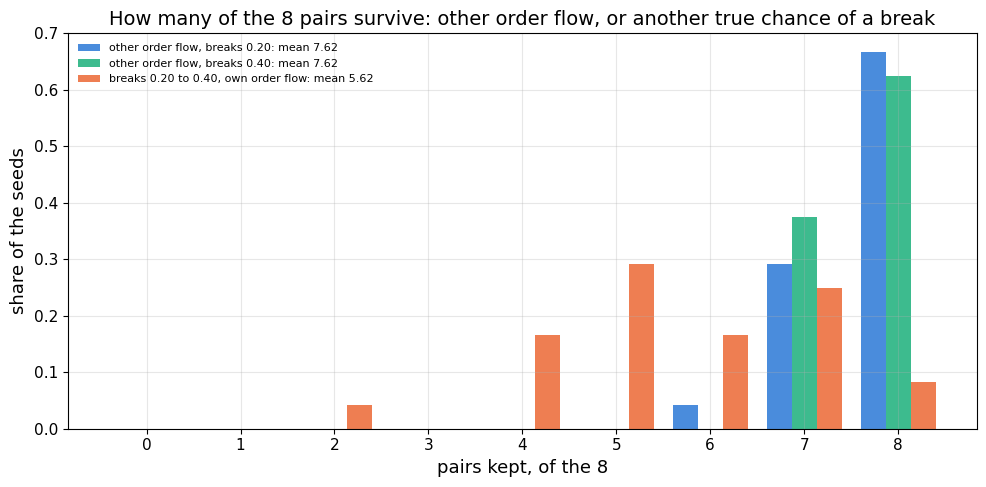

In [19]:
# 2d. Is it the deals, or luck? The formation alone, in the real market (order books, the library's pairs trader,
# stopped when it has chosen its pairs), with the order flow's random stream replaced after the market is built: the
# factor shocks, the own parts' shocks and the deals are the seed's, and only the luck of the order flow differs. Reads
# the pairs that section 1's blind trader chose on each seed of NEW at breaks 0.20 and 0.40 (news_test_frame,
# news_fair_frame; their own flow), which are what these runs are compared with.
# The seed's own stream of the order flow is default_rng([seed, 2]); the one that replaces it is
# default_rng([seed, 2, 1001]).
FLOW_STREAM = 1001
FORM_ROWS = {DEAL_CHEAP: (news_test_frame, news_test_blind), DEAL_FAIR: (news_fair_frame, news_fair_blind)}


def formation(seed, breaks, other_flow):
    # One market of `breaks` on `seed` run until its pairs trader has chosen its pairs: the pairs (as the books of each,
    # and as whole rows), when it chose and the deals so far. With `other_flow` the order flow's stream is replaced
    # right after the market is built, before any order: nothing else changes.
    check_seed(seed)
    started = time.time()
    trader = pairs_by()()
    market = BookMarket(dealing(breaks)(), seed=seed, traders=(trader,))
    if other_flow:
        market.rng = np.random.default_rng([seed, 2, FLOW_STREAM])
    while trader.fits == 0:
        market.step()
    return dict(
        seed=seed,
        breaks=breaks,
        other_flow=other_flow,
        fit_at=market.time,
        pairs=tuple(tuple(int(book) for book in np.nonzero(w)[0]) for w in trader.weights),
        weights=tuple(tuple(float(x) for x in w) for w in trader.weights),
        deals=deals_of(market.fair),
        secs=time.time() - started,
    )


# 48 runs with the other flow (every seed of NEW at both values of breaks), and 2 with the seed's own (the first seed of
# NEW at both), which must be the pairs of section 1's runs to the last digit: the formation alone is the market run's
# formation.
jobs = [(seed, b, True) for b in sorted(FORM_ROWS) for seed in NEW]
jobs += [(NEW[0], b, False) for b in sorted(FORM_ROWS)]
pairs_formations = pd.DataFrame(Parallel(n_jobs=-1)(delayed(formation)(*job) for job in jobs))
swapped, same_flow = pairs_formations[pairs_formations.other_flow], pairs_formations[~pairs_formations.other_flow]
assert len(swapped) == 2 * len(NEW), 'a formation is missing'

differ = 0
for run in pairs_formations.itertuples():
    frame, row = FORM_ROWS[run.breaks]
    section_1 = frame[(frame.row == row) & (frame.seed == run.seed)].iloc[0]
    assert len(run.pairs) == COUNT, f'seed {run.seed}, breaks {run.breaks}: {len(run.pairs)} pairs'
    # The deals up to the fit are the seed's: those that section 1's run announced by then, as (target, acquirer, time).
    made = {d[:3] for d in run.deals}
    there = {d[:3] for d in section_1.deals if d[2] <= run.fit_at}
    assert made == there, f'seed {run.seed}, breaks {run.breaks}: the formation has other deals than the market run'
    if run.other_flow:
        differ += run.weights != section_1.weights
    else:
        assert run.weights == section_1.weights, f'seed {run.seed}, breaks {run.breaks}: not the market run pairs'
assert differ > 0, 'replacing the order flow changed no pair or hedge in any run: is the stream replaced?'
print(
    f'Checked: the {len(pairs_formations)} formation-only runs have the deals that section 1 has up to the fit, and '
    f"the {len(same_flow)} with the seed's own order flow choose section 1's rows of weights to the last digit.\n"
)


def kept_of(own, other):
    # How many of the eight pairs two sets have in common.
    return len(set(own) & set(other))


kept_rows = []
for run in swapped.itertuples():
    frame, row = FORM_ROWS[run.breaks]
    own_pairs = frame[(frame.row == row) & (frame.seed == run.seed)].iloc[0].pairs
    kept_rows.append(
        dict(
            seed=run.seed,
            breaks=run.breaks,
            kept=kept_of(own_pairs, run.pairs),
            cross_own=sum(not SAME_SECTOR[x, y] for x, y in own_pairs),
            cross_other=sum(not SAME_SECTOR[x, y] for x, y in run.pairs),
        )
    )
pairs_kept = pd.DataFrame(kept_rows)
pairs_by_breaks = {b: pairs_kept[pairs_kept.breaks == b].set_index('seed') for b in sorted(FORM_ROWS)}
both_pairs = {
    b: frame[frame.row == row].set_index('seed').pairs.sort_index() for b, (frame, row) in sorted(FORM_ROWS.items())
}
low_b, high_b = sorted(FORM_ROWS)
pairs_kept_across = pd.Series(
    {seed: kept_of(both_pairs[low_b][seed], both_pairs[high_b][seed]) for seed in NEW}, name='pairs_kept_across'
).sort_index()
pairs_cross_across = pd.DataFrame(
    {b: [sum(not SAME_SECTOR[x, y] for x, y in both_pairs[b][seed]) for seed in NEW] for b in both_pairs},
    index=list(NEW),
)
pairs_cross_changes = (pairs_cross_across[low_b] != pairs_cross_across[high_b]).sum()

print(
    f"Of the eight pairs a trader chooses, how many it keeps when only the order flow's luck changes (the same seed, "
    f"the same true chance of a break, the same factor shocks and deals), on the {len(NEW)} seeds of NEW, and how many "
    f'it keeps when the true chance of a break changes instead (the same seed, the seed\'s own flow):\n'
)
for b, got in pairs_by_breaks.items():
    print(f'  other order flow, breaks {b:.2f}: {got.kept.mean():.2f} of {COUNT} (se {se_of(got.kept):.2f})')
print(
    f'  breaks {low_b:.2f} to {high_b:.2f}, own order flow: {pairs_kept_across.mean():.2f} of {COUNT} '
    f'(se {se_of(pairs_kept_across):.2f})'
)
pairs_luck_kept = sum(pairs_by_breaks[b].kept for b in pairs_by_breaks) / len(
    pairs_by_breaks
)  # a seed's mean over the two true chances
print(
    f'\nKept under other order flow less kept across the two true chances, seed by seed (the mean of the seed\'s two '
    f'cells, less its one): {said(pairs_luck_kept.sort_index() - pairs_kept_across, 2)}.'
)
pairs_cells_changed = int((pairs_kept.cross_own != pairs_kept.cross_other).sum())
print(
    f'Pairs across sectors: the count changes in {pairs_cells_changed} of {len(pairs_kept)} cells with other order '
    f'flow (mean absolute change {np.abs(pairs_kept.cross_own - pairs_kept.cross_other).mean():.2f}) and in '
    f'{pairs_cross_changes} of {len(NEW)} seeds between {low_b:.2f} and {high_b:.2f} '
    f'(mean absolute change {np.abs(pairs_cross_across[low_b] - pairs_cross_across[high_b]).mean():.2f}).'
)
print(
    f'\n{len(swapped)} formation runs with the other order flow and {len(same_flow)} with the seed\'s own: '
    f'{pairs_formations.secs.sum() / 60:.1f} core-minutes, {pairs_formations.secs.mean():.0f} core-seconds a run.'
)

# The figure: for each of the three groups, the share of its seeds that kept 0 to 8 of the pairs (one y-axis; the legend
# has each group's mean).
groups = [
    (f'other order flow, breaks {b:.2f}', pairs_by_breaks[b].kept, color)
    for (b, color) in zip(pairs_by_breaks, (BLUE, AQUA), strict=True)
]
groups += [(f'breaks {low_b:.2f} to {high_b:.2f}, own order flow', pairs_kept_across, ORANGE)]
fig, ax = plt.subplots(figsize=FIGSIZE)
width = 0.8 / len(groups)
for i, (label, kept, color) in enumerate(groups):
    share = np.bincount(kept, minlength=COUNT + 1) / len(kept)
    ax.bar(
        np.arange(COUNT + 1) + (i - (len(groups) - 1) / 2) * width,
        share,
        width,
        color=color,
        alpha=0.85,
        label=f'{label}: mean {kept.mean():.2f}',
    )
ax.set_xticks(range(COUNT + 1))
ax.set_xlabel(f'pairs kept, of the {COUNT}')
ax.set_ylabel('share of the seeds')
ax.set_title(f'How many of the {COUNT} pairs survive: other order flow, or another true chance of a break')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()
plt.show()

**Under other order flow a formation keeps nearly all of its eight pairs; across the two true chances it keeps fewer.** With only the order flow's luck changed, the 24 seeds keep 7.62 of the eight (standard error 0.12) at 0.20 and 7.62 (se 0.10) at 0.40. With the true chance changed instead, keeping the seed's own flow, they keep 5.62 (se 0.30). Seed by seed, the pairs kept under other flow (the mean of a seed's two cells) less those kept across the two true chances are +2.00 (se 0.28, t 7.12, 22 of 24 seeds positive). The exploration on seeds 1 to 24 had 7.54 (se 0.12), 7.38 (se 0.16) and 5.75, so the pairs survive other order flow about as well as before (plain differences of +0.08, +0.24 and -0.13, none over two standard errors). The luck of the order flow changes about 0.4 of the eight pairs (8 less 7.62) and the true chance about 2.4 (8 less 5.62), about six times as many (a plain ratio). So the sets of the two markets differ by the deals' outcomes and not by the luck of the order flow. Changing the true chance also changes the flow that the deals' outcomes induce, so the +2.00 is the pairs' dependence on the deals' outcomes and what follows from them, set against the luck of the stream, which is the only thing the other-flow cells change. A cell is one other stream, so a cell's "kept" is one draw of what luck does and the mean over 24 seeds is the measure. This is about which pairs are chosen and not about what a set is worth; that is 2a's and 2b's.

**The number of pairs across sectors is stable under other order flow.** It changes in 8 of the 48 cells with other flow (mean absolute change 0.17), so in 40 cells it does not change at all, and in 16 of the 24 seeds between 0.20 and 0.40 (mean absolute change 1.08), about six times as large (a plain ratio). The exploration had 7 of 48 cells, by one each time. So the number of pairs across sectors, the quantity that 2a's mechanism turns on, moves with the true chance and hardly with the luck of the order flow, which is what the mechanism needs.

**The checks and the cost.** All 50 formation-only runs have the deals that section 1 has up to the fit, and the 2 that keep the seed's own order flow, the first seed of `NEW` at both true chances, choose section 1's rows of weights to the last digit, so the formation alone is the market run's formation. That the replaced stream changed something is asserted in the cell, which stops if no run's pairs or hedges differ from section 1's, but the printed line does not say how many did, and nothing is printed of the hedges. It shows in the means above: had the replaced stream changed nothing, every cell would keep 8 of 8, and the means are 7.62. The 48 runs with other flow and the 2 with the seed's own took 17.5 core-minutes, 21 core-seconds a run, more than the head cell's estimate of about 16 seconds a run, which changes no figure.

The figure shows, for each of the three groups, the share of the seeds by the number of the eight pairs kept. The two groups with other order flow (blue at 0.20, green at 0.40) sit at 7 and 8, most of them at 8, and none keeps fewer than 6; the third group, across the two true chances with the seed's own flow, is spread from 2 to 8.

### In a Backtest's Terms

The scorecard and signal chart of the blind trader on another market's pairs, on the second seed of `NEW`, which played no part in choosing any setting and is not section 1's card: in the market of `breaks` 0.40, where the price of a break is fair, traded with the eight pairs that the trader of the same seed chose in the market of 0.20, the whole rows handed to it by the chooser of 2c. It is 2c's new row on this seed, run again to its end with a record of every decision, and the cell asserts it is that run (the same deals, as far as the shorter of the two goes). The card is on capital of 150,000 ticks times lots, like the other sections', unless the run holds more than that at its peak (a card is meant to hold less than its capital): then the next quarter above its peak, and the card says what it holds at its most. The chart is of the larger leg of the first of its eight pairs; its signal is the pair's z-score, with the levels it enters and leaves at.

**A card's hit rate and profit factor are those of legs, not of pairs.** The record holds the position in each book after each decision, so a "trade" of the scorecard is a run of one sign in one book, and a book is in several pairs: a book that is the larger leg of one pair and the smaller of another goes long and short in turn. The card is one seed of one market and an illustration of what the trader's record looks like, not evidence about the pairs it trades.

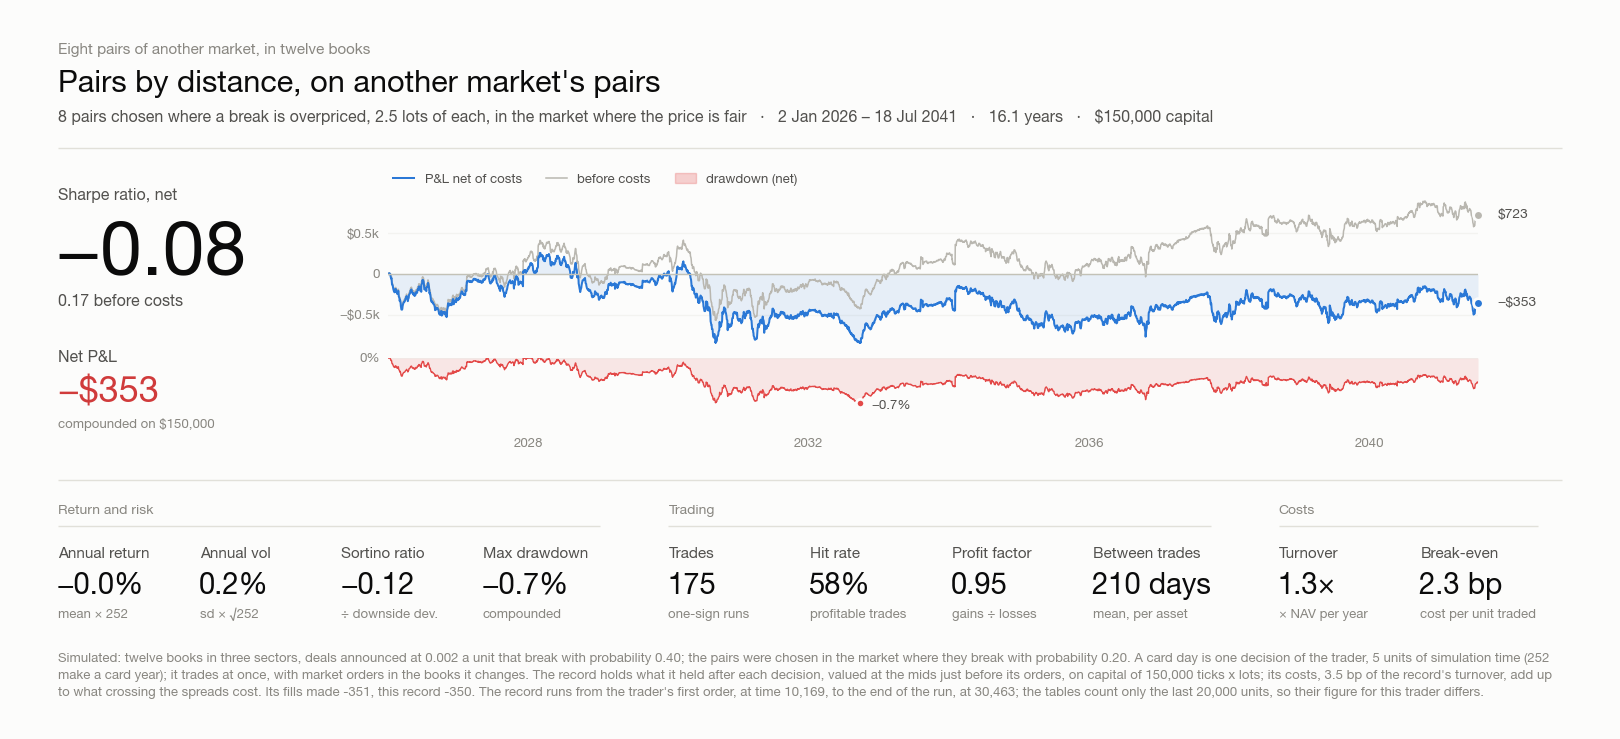

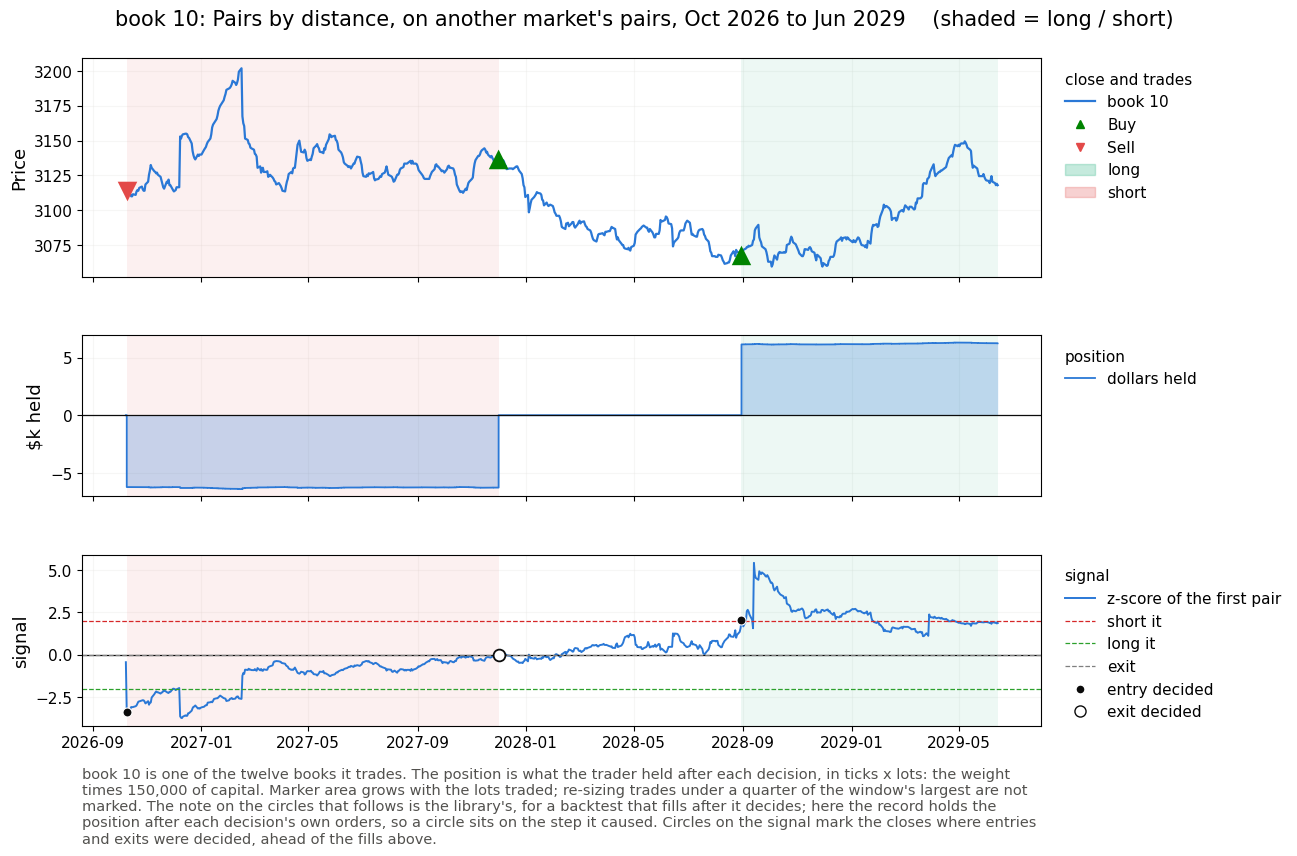

Eight pairs of another market, in twelve books: its fills made -351 and the record -350; it holds at most 0.57 times the capital of 150,000, and more than it on 0.0% of days.
2c's figure for this run (breaks 0.40, seed 122), the last 20,000 units only: -0.5. The capital of the card is 150,000 ticks x lots (the section's 150,000 unless the run holds more at its peak).


In [20]:
# The blind trader on another market's pairs, on the second seed of NEW (a seed no setting was chosen on, and not the
# card of section 1): in the market of breaks 0.40, traded with the pairs that the trader of the same seed chose in the
# market of breaks 0.20, the run of 2c's new row on that seed, to its end, with a record of every decision.
PAIRS_CARD_SEED = NEW[1]
trader, fills, market = recorded(
    dealing(DEAL_FAIR),
    partial(pairs_by(RelationTrader), choose=Fixed(pairs_handed_cheap[PAIRS_CARD_SEED])),
    PAIRS_BURN,
    seed=PAIRS_CARD_SEED,
)
assert np.array_equal(trader.weights, np.array(pairs_handed_cheap[PAIRS_CARD_SEED])), 'it did not trade the rows handed'
# The capital is the section's 150,000 ticks x lots unless the run holds more than that at its peak (a card is meant to
# hold less than its capital): then the next quarter of it above the peak, and the card says what it holds.
peak = record_of(trader).weights.abs().sum(axis=1).max()
card_capital = CAPITAL * max(1.0, math.ceil(peak * 1.05 * 4) / 4)
pairs_card = card(
    trader,
    fills,
    "Pairs by distance, on another market's pairs",
    f'{COUNT} pairs chosen where a break is overpriced, {SIZE} lots of each, in the market where the price is fair',
    "Eight pairs of another market, in twelve books",
    f'twelve books in three sectors, deals announced at {DEAL_RATE} a unit that break with probability '
    f'{DEAL_FAIR:.2f}; the pairs were chosen in the market where they break with probability {DEAL_CHEAP:.2f}',
    'z-score of the first pair',
    around(trader),
    largest_leg(trader),
    capital=card_capital,
)
assert pairs_card['peak'] <= 1, f"the run holds {pairs_card['peak']:.2f} times the capital of {card_capital:,.0f}"
# It is the run of 2c's row on this seed: the same deals (as far as the shorter of the two runs goes).
table_row = pairs_other_frame[(pairs_other_frame.row == MARKET_OTHER) & (pairs_other_frame.seed == PAIRS_CARD_SEED)]
check_card_deals(table_row, market, PAIRS_CARD_SEED)
# And the trader's own eight rows of weights, which depend on the trader and not on time alone: the table's run's.
assert tuple(map(tuple, trader.weights.tolist())) == table_row.weights.item(), (
    "the card's run chose other pairs or hedges than the table's run of the same row and seed"
)


def ticks_shown(x):
    # Whole ticks x lots with a sign; a figure that rounds to 0 without being 0 shows its first decimal, so that -0.5
    # does not read as minus nothing.
    text = f'{x:+,.0f}'
    return text if text.lstrip('+-') != '0' else f'{x:+,.1f}'


print(
    f"2c's figure for this run (breaks {DEAL_FAIR:.2f}, seed {PAIRS_CARD_SEED}), the last {SPAN:,.0f} units only: "
    f'{ticks_shown(table_row.pnl.item())}. The capital of the card is {card_capital:,.0f} ticks x lots (the section\'s '
    f'{CAPITAL:,.0f} unless the run holds more at its peak).'
)

**The card.** On the second seed of `NEW`, seed 122, the blind trader on the eight pairs of the market of 0.20, in the market of 0.40, made -351 by its fills and -350 by the record (ticks x lots, after costs). The run holds at most 0.57 times the capital of 150,000, and more than it on 0.0% of days, so the card's capital is the section's 150,000. The chart is of book 10, the larger leg of the first pair, and shows the position and the pair's z-score around the entries the trader made: the book is short from the first entry, decided at a z-score below -2, until the exit decided where the z-score crosses 0, then flat for a long stretch, then long from an entry decided above 2. 2c's figure for the same run is printed as -0.5 (half a tick x lots over the span, a coincidence and not a fault), against the card's -350, because it counts only the last 20,000 units of the run, while the record runs from the trader's first order, at time 10,169, to the end of the run, at 30,463. The card's headline Net P&L, -\$353 "compounded on \$150,000", is a figure of its own beside the printed -351 and -350, in dollars where the rest of this notebook is in ticks x lots. It is one seed and one run, an illustration of what the trader's record looks like and not evidence about the pairs it trades.

### What This Section Cannot Show

**The route is not a market.** Every figure of 2a and 2b is the worth of a set of pairs on fair values, with no order books, no spread paid, no rounding of 2.5 lots to whole lots and no impact of the trader's own orders, and "before costs" is never an edge: it is what a set of pairs is worth to a trader that trades them at fair values at no cost, which no trader does. What the same pairs earn in a market is something else, and notebook 15's +446 was one such figure. 2c measures how far the market agrees with the route on 24 seeds: a check of sign and size with the standard error it prints, and not the test, and at the power the exploration put on a test of 24 seeds. If the route and the market disagree there, the route's 200 seeds do not decide it.

**The cleaned sets are controls, and no trader can have them.** A completed deal's step needs the value of the target on its own, which is never seen. So 2b says where the damage is, the choice or the hedge, and nothing about what a trader could gain: a chooser that reads the news and re-bases a target's price after a completion is the realizable version, which this notebook does not build, and whether it would recover any of the damage is not shown. The route's own damage figure (the gap between a set chosen from raw values and one chosen and hedged from cleaned values) is on paper, and deals damage a formation at either true chance of a break, so it is larger than the gap between the two chances.

**One market and one set of settings.** Twelve books in three sectors of four, deals at 0.002 a unit with an offer of 60 ticks, lasting 500 units, a book out of a new deal for 100 units after, each acquirer in its target's sector, a price of a break of 0.40, eight pairs chosen by distance from a formation of 2,000 decisions, a window of 400, entry at 2. How many pairs across sectors a set has, how bent its hedges are, and how much that costs all depend on them: a different rate or premium of deals, more books or sectors, a cointegration test (`pairs_by_pvalue`) in place of distance, or a formation of another length could give another dial, and none is run. The pairs across sectors are in a set by a draw of the window, which is why the dial moves them; a chooser that tests for cointegration might not choose them, and none is run.

**The dial moves two things.** At a fixed price, a lower true chance of a break means more completions and fewer breaks, together. A break leaves no step, so by the mechanism the steps are completions' and the route reads them as such, through the cleaned control; but the dial alone cannot say it was the completions and not, say, how often a broken deal's fall back moves a pair's spread. The cleaned control is how the section separates them, not a second experiment.

**The split of the gap by pairs across sectors is a description.** The slope of the gap on the difference in pairs across sectors, and the gap on the seeds where they are equal, are lines through seeds, not an experiment: a seed that has more pairs across sectors in one set has fewer completions in its other, and the sets differ in other pairs too. The 2 x 2 is the section's separation of the choice and the hedge, and it is on one route.

**2d says the pairs are the deals' and not the flow's, not what they are worth.** It replaces the order flow's stream with one other stream a cell, so a cell is one draw of what luck does; the mean over the seeds is the measure. It runs the formation alone: a set's trading is another random sequence of the order flow, which it does not touch.

**The seeds.** The route's 200 seeds make its standard errors small beside a market test's, and they are standard errors over seeds of one simulated market, one set of settings: what they cannot do is give a standard error across markets or settings. The settings of the section (0.20, the price of 0.40, the eight pairs) were chosen on seeds 1 to 8 by earlier notebooks and the exploration used seeds 1 to 100, so no seed of this section is selected on, but the settings are not independent of seeds 1 to 8. Seeds 1 to 8 are never pooled with these.

**What the section found.** On the route, on fair values and before costs, the set chosen at 0.40 is worth +424 (standard error 72, 133 of 200 seeds positive) more than the set chosen at 0.20 in the paths of 0.40 on 200 seeds (+442, se 70, in the paths of 0.20), the completions and the pairs across sectors fall together along the dial while the worth rises by +410 (se 34) a step of 0.2, and the 2 x 2 does not put the gap in the choice or in the hedge: cleaning either alone leaves about three quarters of it (+321 and +340), cleaning both leaves +67 (se 31, 114 of 200), and the two channels overlap (interaction -169, se 55), so it is the completed steps, through either channel. The market agrees with the route seed by seed on the 24 seeds of `NEW` (+0.74 and +0.68) but those seeds show the gap in neither (the market +38, se 177, the route -94, se 186, against the route's +442 on `PAPER`), and the pairs of a formation differ by the deals and not by the order flow's luck (+2.00, se 0.28, more pairs kept under other order flow than across the two true chances).

**The discrepancy, again.** The 24 new seeds are not a disagreement between the market and the route: the route on them is 2.7 combined standard errors below its figure on `PAPER` (printed by the cell added after 2c: 0.18% of 24-seed draws from `PAPER` have a mean as low as the route's, and 0.44% are as far from `PAPER`'s mean in either direction), and the market's +38 is 1.8 below notebook 15's +446 (the premise review's figure, which no cell prints, given in 2c). No cause was found, so the reading left is an unusual draw of seeds, at the edge of what chance gives. So the market has not shown the gap's size anywhere but on notebook 15's eight seeds, and this section does not say that it confirms the route's size. The route's +442 is the same comparison on fair values, before costs, of a similar size to notebook 15's +446 (se 143) and not that figure again.

**Whether the explanation stands.** On the route, it is supported as measured. The completions and the pairs across sectors fall together along the dial (completions from 18.5 to 7.3, pairs across sectors from 2.15 to 0.60) while the worth rises, a pair across sectors makes about 400 less than one within a sector (-401, se 30), and taking the steps of the completed deals out of the choice and the hedge together leaves +67 (se 31, 114 of 200 seeds positive) of the gap of +424 (se 72, 133 of 200). The two channels both carry the damage, and the section puts no share of the gap in either, since each alone leaves about three quarters of it and the two overlap. That is on the route, on paper in this section's word: fair values, no order books, no costs. In the market the check on 24 seeds did not show the gap, nor did the route on those seeds, so what is shown there is the seed-by-seed agreement (+0.74, +0.68), and neither the sign nor the size: the market's +38 and -139 are 0.21 and 0.83 standard errors from 0, with 11 and 14 of 24 seeds positive. The cleaned sets are controls that no trader can have, so the section shows where the damage is and not how to avoid it. A chooser that reads the news and re-bases a target after a completion is the realizable version and the lead this section leaves; it is not built, and whether it would recover any of the damage is not shown.

## 3. Sector Indexes

**The question.** Notebook 15's index book is the thirteenth book of its market, made of all twelve, and its limitations list the sector indexes of a real market as left out. Notebook 12's best rule, stat-arb on PCA residuals, hedges each book it trades with the books of that book's own sector: it fits three principal-component factors to the moves of the last 500 decisions, and when a book's residual is far enough from its mean it holds the book and the minus of what the three factors take of it, in the books they take it from. A sector index book is one leg in place of those: the sum of a sector's four books. Would a residual trader that hedged with it, in one leg, pay less to trade?

**This section does not build a market with sector indexes and trade it.** `FactorValues(index=...)` takes any weights over the twelve books, so the sum of one sector's four books (weights of 1 on those four and 0 on the other eight) is an index book today, with no change to the library: it is book 12, with scale 4 (its order flow reaches 32 ticks, its starting book is 4 ticks apart, its premium is its own and a lot taken in it moves only the premium). What the question needs is cheaper than a market of fifteen books and an arm of traders, because the answer is largely arithmetic and the rest is two measurements. So the section shows three things, and one piece of arithmetic.

- **3a. What each hedge holds.** The residual trader's positions, from its recorded runs, at the decisions where it opens a sector from flat: what it holds of the book it entered and of the book's three sector mates, in lots. Then, as arithmetic in the cell, that five lots of the book against one lot of its sector's sum index are the same position.
- **3b. What each costs.** In bare markets (no trader in them) with one sector's sum index, read off the books without trading: the half-spread (what a lot costs at the touch) and the cost a lot of a market order of 1 to 5 lots against the mid, walking the book, in the index book and in an ordinary book, and so what an entry costs by each route, each of its orders priced at the cost a lot of an order of its size (an order of 4 or 5 lots walks the book, so it is not at the touch).
- **3c. What the cheapest mix would save.** The residual trader's own orders, replayed: for each decision's change of position, in each sector, the cheapest way to hold the same exposure with the four books and the sector's sum index when an index lot costs what 3b measured, what a book lot costs, and nothing. The share of its crossing cost that saves is the saving of that one policy, the cheapest mix at each decision on its own, for an index that has a price of an index lot and nothing else: it is neither the most that any use of a sector index could be worth to this trader nor a floor on it.
- **3d. One index of all twelve books, as a hedge.** Arithmetic from the loadings and the factors' volatilities, not a run: what one index of all twelve books, notebook 15's, would leave of a book's factor variance as the whole hedge, and what a sector's own index would.

**Why the answer is mostly arithmetic.** In this market the three factors that the trader fits are, in the population, the span of the loadings: a market factor and three sector factors, with the market's a sum of the three. What three factors that span take of a book's moves is the book's projection on the span, which for a book of a sector of four is a quarter of each of the sector's books, itself included (the book is in its own index, so the population coefficient is exactly one quarter; the trader estimates it from 500 decisions' moves and its estimate varies around that, which 3a prints). So a relation of one book against its factors is the book less a quarter of each book of the sector: with a size of five lots, which multiplies a relation whose weight on the book is 1 before the hedge, 3.75 lots of the book (the largest leg, before the rounding) and 1.25 of each of its three mates, which rounds to 4 and 1, and sums to nothing before the rounding. Five lots of the book against one lot of the sector's sum index, with the index taken apart into the four books it is made of, is 4 of the book and 1 of each mate: the same position, to the lot. The two routes cannot then differ in what they hold, only in what crossing the books costs, and in the premium's noise, which can only add to the index's. And an index lot replaces three mates' lots at the price of one more lot of the book: it is worth using, in an opening of that shape, only where it costs less than two book lots. A residual is neutral within its sector (its four lots sum to nothing before the rounding), so it holds none of the uniform exposure to the sector that an index sells, and could use an index lot only as a stand-in for the mates' lots; 3c measures what that is worth.

**Seeds.** `FEW` is seeds 101 to 108, the same eight as `FIRST`, in every part; nothing in this notebook was chosen on them.

**The trader, burn and span.** The residual trader is notebook 13's baseline row, alone in the sectors market with no deals and no index, deciding every 5 units: three factors, 5 lots of the largest, a window of 400 decisions, opening at an s-score of 1.5 and closing at 0; its burn is notebook 13's (10,465, the longest warm-up of its first table and 400 more) and its span 20,000 units. The same eight runs are read by 3a and replayed by 3c. The bare markets of 3b are 16 runs of 4,000 units each (a burn of 500, then a reading of every book every 7 units), at two points of notebook 15's index dial. The card is one more run of the trader, on seed 101.

**What was explored before, and on which seeds.** On seeds 1 to 8, before this notebook was written (none of them is a seed of this section). Nothing in this notebook prints these figures; they are not this section's results, and they fixed what is run.

- The index book's cost, in a bare market of one sector of four books and its sum index at `index_volatility` 0.4: a half-spread of 3.04 ticks (se 0.02) against 1.00 (se 0.005) for a book, and 4.07 a lot against 1.25 in an order of 5 lots; 2.99 at an `index_volatility` of 0. That fixed the dial's point here: 0.4 is notebook 15's chosen point, and 0 is run as the control, since the order flow's own orders make a premium at any point.
- The replay of the same residual trader's orders (12,000 units, no burn), with an index lot priced in book lots: next to none at 2 and above (under a tenth of a percent), 13% of the crossing cost at 1, 26% at 0. That fixed the curve of 3c, which prices an index lot from 0 to 4 book lots, so that a market that made an index cheaper than this one can be read off it.
- On seeds 1 to 4, an index book given other models through `BookMarket(models=...)` (no library change): a narrower reach of 8 ticks, the first thing to try, gave a half-spread of 2.75, since the index's fair value moves faster than a book's; four times the order flow at that reach gave 2.05, sixteen times 1.72, and four times the flow at a reach of 32 gave 1.36. So a cheap index is more flow with a wide reach, which is a different market from this one: it is not built here, and 3c's curve says what it would save.

**What is run.**

1. *3a*: the residual trader on `FEW`, one run a seed with its record kept, and the same trader at notebook 13's frontier setting, one run a seed, for the check against notebook 13's saved line.
2. *3b*: 16 bare markets, no trader in them.
3. *3c*: no new run; a replay of 3a's orders.
4. *3d*: arithmetic, no run.
5. *The card*: one recorded run of the residual trader, on the first seed of `FEW`.

**What the cells check.** That the run is notebook 12's rule on notebook 13's burn and span, and whether the same eight seeds give notebook 13's own line for it to the last digit (below: a flag, printed either way); that the orders the record shows are the lots the score counts; that the index book of 3b is the thirteenth book, of scale 4, the sum of the first sector's books, starting at their sum; that the index route holds the PCA route's position, in lots and in exposure to the factors; and in 3c that the replay with no index is the trader's own lots, that an index too dear to use is never used, and that a dearer index never saves more.

### 3a. What Each Hedge Holds

**The trader.** Notebook 12's best rule on PCA residuals, as notebook 13's first table has it as a baseline ("residuals, 3 factors (notebook 12)"): `ResidualTrader` with three factors, a size of 5 lots (the weight on the book is 1 before the hedge, so 3.75 lots of the book before the rounding), a window of 400 decisions, opening at an s-score of 1.5 and closing at 0, deciding every 5 units, alone in the sectors market with no deals and no index, after notebook 13's burn and over 20,000 units, on seeds 101 to 108. The cell keeps its record, and reads in each worker what it held after each decision of the span and what it ordered at each decision (the change in what it held). It checks that the orders the record shows add up to the lots the score counts.

**Is this notebook 13's row?** Notebook 13's baseline row is on twelve seeds, 101 to 112, and this section's are eight of them: the same runs on those seeds, in a mean of eight and not of twelve, so its figure cannot equal notebook 13's. The cell does two things. It prints notebook 13's row beside this one and asserts that the two means differ by no more than the four missing seeds can account for (five standard deviations of that difference, from the seeds' own spread). And it runs the exact check: notebook 13's section 5 ran this same trader (its "enter later" curve at an opening of 1.5, with no rate and no band) on seeds 101 to 108 alone, for 10,000 units after its own warm-up and 100 more, and printed a line for it. The cell runs that setting on those seeds and compares its P&L and standard error with the saved line (equal to half a tick) and its seeds positive (exactly), and prints whether they are equal. Equal is the same runs and not a replication. It is a flag and not an assert: a line that differs is printed as NOT EQUAL, for the prose to explain, and does not stop the run; the check is made on the saved notebook 13, and says so if it is not there.

**What it holds.** At a decision that opens a sector from flat (all four of the sector's books at 0 before, something held after), the trader holds one book's residual and nothing else in that sector, so the four books' lots are the relation it entered, hedge included, in whole lots. The cell counts these positions across the eight runs: the largest book first, signed positive so that a long and a short of one relation are one pattern, then its three mates from the most short up. By the arithmetic of the opening of this section it should be mostly one position, 4 lots of the book against 1 of each mate, and the table says how mostly, and what the others are (two relations opened at one decision in one sector, hedges that rounded another way). The cell then prints what the trader fitted before rounding (the row of the relation it last entered in each book, in lots), and the arithmetic itself from the loadings: what the factors take of a book, the position that leaves, the same position as five lots of the book against one of the sector's sum index taken apart into its four books, and the exposures to the market and sector factors of the two, which the cell asserts equal.

**What the cell does not claim.** That the trader's hedge is exactly a quarter of each mate: it is fitted from 500 decisions' moves and varies; the table of what it fitted shows by how much. The equality of the two routes is the equality of the population hedge, and the section asks only whether the rounded positions the trader held were the index route's.

In [21]:
# 3a. What the two hedges hold: the runs. Notebook 12's best rule on PCA residuals, as notebook 13's baseline row has it
# (three factors, 5 lots of the largest, a window of 400 decisions, opening at an s-score of 1.5 and closing at 0,
# deciding every 5 units), alone in the sectors market with no index and no deals, on FEW, with its record kept: the
# positions and the orders of every decision of the span. 3a reads what it holds; 3c replays its orders.
from collections import Counter

from lob.book import Side
from lob.statarb import ResidualTrader

SECTOR_COUNT, SECTOR_SIZE = 3, 4  # the sectors market's twelve books: books 4 s to 4 s + 3 are sector s's
BOOK_COUNT = SECTOR_COUNT * SECTOR_SIZE
assert LOADINGS['sectors'].shape == (BOOK_COUNT, 1 + SECTOR_COUNT), 'the sectors market is not three sectors of four'
RESIDUAL = dict(factors=3, interval=EVERY, size=5.0, window=400, open_at=1.5, close_long=0.0, close_short=0.0)
RESIDUAL_ROW = 'residuals, 3 factors (notebook 12)'  # notebook 13's name for it


def residual_by(**settings):
    # The residual trader of notebook 13's first table, as a function that makes one (a partial, for the workers).
    return partial(ResidualTrader, **{**RESIDUAL, **settings})


RESIDUAL_BURN = PAIRS_BURN  # notebook 13's burn for every row of its first table: the pairs' warm-up and 400 more
assert RESIDUAL_BURN >= residual_by()().warm_up, "the burn cuts into the residual trader's warm-up"


def residual_run(make_fair, make_trader, seed, burn, span):
    # run_one's run of one trader on one seed, with its record kept and two things read in the worker: what it held
    # after each decision of the span and what it ordered at each (the change in what it held). The market is stepped to
    # the burn here, so that the time the span starts at is known; score_holdings then has nothing left to step through
    # and gives the numbers it gives in run_one.
    check_seed(seed)
    trader = make_trader()
    trader.record = True
    market = BookMarket(make_fair(), seed=seed, traders=(trader,))
    started = time.time()
    while market.time < burn:
        market.step()
    start = market.time
    score = score_holdings(market, trader, burn, span)
    score['rest'] = score['pnl'] - score['factor_part']
    score.update(pushed=float(market.fair.pushed), warm_up=float(trader.warm_up))
    times = np.array([step[0] for step in trader.history])
    held = np.array([step[2] for step in trader.history], dtype=np.int16)
    inside = np.nonzero(times > start)[0]  # the decisions of the span: those after the one that crossed the burn
    moves = np.diff(held[inside[0] - 1 :], axis=0)  # what each ordered: the change in what it held
    assert len(moves) == len(inside), 'a decision of the span is missing from the record'
    assert np.abs(moves).sum() == score['lots'], 'the orders the record shows are not the lots the score counts'
    score['secs'] = time.time() - started
    return {
        'seed': seed,
        **score,
        'held': held[inside],
        'moves': moves,
        'hedges': np.array(trader.weights),  # each book's relation as it last entered it: a row a book
        'size': float(trader.size),
    }


index_runs = Parallel(n_jobs=-1)(
    delayed(residual_run)(market_of('sectors'), residual_by(), seed, RESIDUAL_BURN, SPAN) for seed in FEW
)
index_held = {run['seed']: run['held'] for run in index_runs}  # the lots of each book after each decision of the span
index_moves = {run['seed']: run['moves'] for run in index_runs}  # the orders of each decision of the span
index_hedges = {run['seed']: run['hedges'] for run in index_runs}
index_frame = pd.DataFrame(
    [{'row': RESIDUAL_ROW, **{k: v for k, v in run.items() if not isinstance(v, np.ndarray)}} for run in index_runs]
)
assert (index_frame.pushed == 0).all(), (
    'the floor pushed the factors in a run: the fair values are not the market of notebook 13'
)
assert not (index_frame.warm_up > RESIDUAL_BURN).any(), 'the burn cuts into the warm-up'
assert (index_frame.lots > 0).all(), 'the trader made no trade in a run'

print(
    'Notebook 12\'s best rule on PCA residuals ("residuals, 3 factors"), alone in the sectors market, '
    f'{len(FEW)} seeds, burn {RESIDUAL_BURN:,.0f}, span {SPAN:,.0f} units:\n'
)
print(shown(table_of(index_frame)))

# Notebook 13's first table has this trader in this market with this burn and span, on its twelve seeds (101 to 112).
# FEW is eight of them, so its mean is not that row's: a mean of eight is not a mean of twelve. What can be asserted is
# that the difference between them is only the four seeds that are missing here (the standard deviation of the
# difference is the seeds' sd times the root of 1/n - 1/N), at five of its standard deviations.
index_baseline = notebook_13_row(RESIDUAL_ROW)
if SMOKE:
    print('\nNot compared with notebook 13 in a smoke copy.')
elif index_baseline is None:
    print('\nNotebook 13 has no saved output with its residual row: it is not compared with it.')
else:
    pnl13, se13, positive13, seeds13 = index_baseline
    seeds_here, pnl_here = len(index_frame), index_frame.pnl
    allowed = 5 * pnl_here.std() * math.sqrt(1 / seeds_here - 1 / seeds13)
    assert seeds_here < seeds13 and abs(pnl_here.mean() - pnl13) <= allowed, (
        f"the {seeds_here} seeds' mean P&L is {pnl_here.mean():,.0f} and notebook 13's row on {seeds13} seeds is "
        f'{pnl13:,.0f}: more than {allowed:,.0f} apart, so not these runs. Is notebook 13 saved from other settings?'
    )
    print(
        f"\nNotebook 13's first table has this trader in this market, with this burn and span, on {seeds13} seeds: "
        f'{pnl13:+,.0f} (se {se13:.0f}, {positive13} of {seeds13} seeds positive). The {seeds_here} seeds here are '
        f'{seeds_here} of those {seeds13}, so the means differ by the other {seeds13 - seeds_here} seeds: '
        f'{pnl_here.mean():+,.0f} here, and {allowed:,.0f} is the most they may differ by. The check below is the one '
        'that is exact.'
    )


# The exact check. Notebook 13's frontier ran the same trader (its 'enter later' curve, at an opening of 1.5, with no
# rate and no band) in the same market on seeds 101 to 108, for 10,000 units after its own warm-up and 100 more. FEW is
# those eight seeds, so the same runs give the same line to the last digit, and a harness that drifted would not.
RESIDUAL_CHECK_BURN = burn_for('residual check burn', residual_by()().warm_up + 100.0, residual_by())
RESIDUAL_CHECK_SPAN = length('residual check span', 10_000.0, least=1_000.0)
FRONTIER_ROW = 'open_at 1.5, rate 1, band 0'
index_check_frame = run_rows(
    {FRONTIER_ROW: (market_of('sectors'), residual_by())}, FEW, RESIDUAL_CHECK_BURN, RESIDUAL_CHECK_SPAN
)
index_check = table_of(index_check_frame).loc[FRONTIER_ROW]
index_saved = saved_row('13_more_long_short_strategies.ipynb', FRONTIER_ROW)
check_said = (
    f'{index_check.pnl:+,.0f} (se {index_check.se:.0f}, {int(index_check.positive)} of {int(index_check.seeds)} seeds '
    'positive)'
)
index_frontier_equal = None  # True or False only where notebook 13's frontier line is saved (not in a smoke copy)
if SMOKE:
    print(f'\nThe frontier check, {len(FEW)} seeds: {check_said}; not compared with notebook 13 in a smoke copy.')
elif index_saved is None:
    print('\nNotebook 13 has no saved output with its frontier line for this setting: not compared with it.')
else:
    pnl13, se13, positive13, seeds13 = index_saved
    # A flag and not an assert: a late stop would cost what sections 1 and 2 took, and a line that differs is a finding
    # for the prose to explain (the library moved under notebook 13), not a reason to lose the run.
    index_frontier_equal = (
        len(index_check_frame) == seeds13
        and abs(index_check.pnl - pnl13) <= 0.5
        and abs(index_check.se - se13) <= 0.5
        and index_check.positive == positive13
    )
    print(
        f"\nThe same trader, market and seeds as notebook 13's frontier ({FRONTIER_ROW}: burn "
        f'{RESIDUAL_CHECK_BURN:,.0f}, span {RESIDUAL_CHECK_SPAN:,.0f}): {check_said}; notebook 13\'s line is '
        f'{pnl13:+,.0f} (se {se13:.0f}, {positive13} of {seeds13}): '
        + (
            'the same runs, and not a replication.'
            if index_frontier_equal
            else "NOT EQUAL: not notebook 13's runs; the prose must say why."
        )
    )
print()
ran(index_frame, index_check_frame)

Notebook 12's best rule on PCA residuals ("residuals, 3 factors"), alone in the sectors market, 8 seeds, burn 10,465, span 20,000 units:

                                      pnl  se positive before_costs costs entries  lots cost_a_lot cost_an_entry gross exposure deviation deviation_long risk_adjusted risk_adjusted_long factor_part   rest
row                                                                                                                                                                                                         
residuals, 3 factors (notebook 12) +4,067 200   8 of 8        9,101 5,034   299.5 4,294       1.17          16.8  15.1     1.59      6.09           4.65         0.033              0.044         +61 +4,007

Notebook 13's first table has this trader in this market, with this burn and span, on 12 seeds: +3,952 (se 143, 12 of 12 seeds positive). The 8 seeds here are 8 of those 12, so the means differ by the other 4 seeds: +4,067 here, and 577 is the mo


The same trader, market and seeds as notebook 13's frontier (open_at 1.5, rate 1, band 0: burn 2,625, span 10,000): +1,985 (se 160, 8 of 8 seeds positive); notebook 13's line is +1,985 (se 160, 8 of 8): the same runs, and not a replication.

16 runs, 8.3 core-minutes.


In [22]:
# 3a. What each hedge holds. The residual trader's positions at the decisions that open a sector from flat (all four of
# its books at 0 before, something held after): at such a decision it holds one book's residual and nothing else in the
# sector, so what it holds is the relation it entered, hedge included, in whole lots. The largest of the four books is
# written first and signed positive (so that a long and a short of one relation are one pattern), then the other three
# from the most short up.
def sector_openings(held, moves):
    # held, moves: decisions by twelve books, what the trader held after each decision and what it ordered at it.
    opened = []
    for sector in range(SECTOR_COUNT):
        books = slice(SECTOR_SIZE * sector, SECTOR_SIZE * (sector + 1))
        after, before = held[:, books].astype(int), held[:, books].astype(int) - moves[:, books]
        for row in after[(before == 0).all(axis=1) & (after != 0).any(axis=1)]:
            big = int(np.argmax(np.abs(row)))
            row = row * int(np.sign(row[big]))
            opened.append((int(row[big]), *sorted(int(x) for i, x in enumerate(row) if i != big)))
    return opened


index_openings = {seed: sector_openings(index_held[seed], index_moves[seed]) for seed in FEW}
index_counted = Counter(pattern for patterns in index_openings.values() for pattern in patterns)
assert index_counted, 'the trader never opened a sector from flat'
total = sum(index_counted.values())
print(
    f"What the residual trader holds in a sector after the decision that opens it from flat, {len(FEW)} seeds: "
    f'{total / len(FEW):.1f} openings a run, {len(index_counted)} different positions. The most common ({SECTOR_SIZE} '
    'books of one sector: the largest in lots, then its three mates):\n'
)
rows = []
for pattern, count in index_counted.most_common(8):
    rows.append(
        {
            'the book': f'{pattern[0]:+d}',
            'its mates': ', '.join(f'{m:+d}' for m in pattern[1:]),
            'sum of the four': f'{sum(pattern):+d}',
            'a run': f'{count / len(FEW):.1f}',
            'share': f'{count / total:.1%}',
        }
    )
rest = total - sum(count for _, count in index_counted.most_common(8))
rows.append(
    {
        'the book': '',
        'its mates': 'all others',
        'sum of the four': '',
        'a run': f'{rest / len(FEW):.1f}',
        'share': f'{rest / total:.1%}',
    }
)
print(pd.DataFrame(rows).to_string(index=False))

# The same, as a count of what the sector's lots add up to: the uniform exposure to the sector's own factor, in lots,
# which is what a sector's sum index sells (a lot of it is a lot of each of the four books).
sums = Counter(sum(pattern) for pattern in index_counted.elements())
net = {n: sum(c for s, c in sums.items() if abs(s) == n) for n in (0, 1)}
net_more = total - net[0] - net[1]
print(
    f"\nWhat the four books' lots add up to, at an opening: 0 in {net[0] / total:.1%} of them, 1 either way in "
    f'{net[1] / total:.1%} and more in {net_more / total:.1%} (a long of the relation and a short of it are counted '
    'alike).'
)

# What the trader fitted, before the rounding to lots. hedges[book] is the row of the relation it last entered in that
# book (zero for a book it never entered): the book's weight 1 less what the factors take of it, and the minus of what
# they take of each other book, the whole position being size times the row. In lots, for the sector of the book.
index_fitted = []
for seed in FEW:
    for book in range(BOOK_COUNT):
        row = index_hedges[seed][book] * index_runs[0]['size']
        if not row.any():
            continue
        mates = [
            b for b in range(SECTOR_SIZE * (book // SECTOR_SIZE), SECTOR_SIZE * (book // SECTOR_SIZE + 1)) if b != book
        ]
        outside = [b for b in range(BOOK_COUNT) if b != book and b not in mates]
        index_fitted.append(
            {
                'seed': seed,
                'book': row[book],
                'mates': row[mates].mean(),
                'sector sum': row[mates].sum() + row[book],
                'outside': np.abs(row[outside]).max(),
                'spread of mates': row[mates].max() - row[mates].min(),
            }
        )
index_fitted = pd.DataFrame(index_fitted)
assert len(index_fitted), 'the trader fitted no relation'
print(
    f'\nThe relation it last entered in each book, before the rounding to lots ({len(index_fitted)} rows: the books it '
    f'entered, by seed), in lots of size {index_runs[0]["size"]:g}: its mean (sd over rows)'
)
for column, what in [
    ('book', 'the book itself'),
    ('mates', 'each of its three mates (the mean of the three)'),
    ('sector sum', "the sector's four books added up"),
    ('outside', 'the largest lot of any book outside the sector, in absolute value'),
    ('spread of mates', 'the most one mate differs from another'),
]:
    print(f'  {what}: {index_fitted[column].mean():+.2f} ({index_fitted[column].std():.2f})')

# The arithmetic. The three factors the trader fits are, in this market, the span of its loadings: a market factor and
# three sector factors, with the market's a sum of the three (rank 3). What three factors that span take of a book's
# moves is the book's projection on that span, which for a book of a sector of four is a quarter of each of the sector's
# books: the book is in its own index, so the regression coefficient is exactly 1/4, whatever the sector's size is.
loadings = LOADINGS['sectors']
projector = loadings @ np.linalg.pinv(loadings)  # books by books: what the factors take of each book's moves
book = 0
index_exact = (np.eye(BOOK_COUNT)[book] - projector[book]) * RESIDUAL[
    'size'
]  # the residual position, in lots, before rounding
assert np.allclose(projector[book][:SECTOR_SIZE], 1 / SECTOR_SIZE) and np.allclose(projector[book][SECTOR_SIZE:], 0)
index_pca_position = np.rint(index_exact).astype(int)  # what the trader holds: whole lots of each book
# The index route: the sector's sum index, with a weight of 1 on each of the sector's books and 0 on the rest (so a lot
# of it is a lot of each of the four books in its fair value and in the factors' exposure), and the lots that its hedge
# ratio gives against 5 lots of the book: one, a quarter of five rounded.
index_weights = np.array([1.0] * SECTOR_SIZE + [0.0] * (BOOK_COUNT - SECTOR_SIZE))
index_lots = int(np.rint(RESIDUAL['size'] * projector[book][book]))
index_route = (
    np.eye(BOOK_COUNT)[book] * RESIDUAL['size'] - index_lots * index_weights
)  # in books: the index's lot, taken apart
assert np.array_equal(index_route, index_pca_position), 'the index route and the PCA route hold different positions'


def exposure_of(position):
    return position @ loadings  # lots of each factor: the market's, then each sector's


assert np.allclose(exposure_of(index_route), exposure_of(index_pca_position))
print(f'\nThe arithmetic, for book {book} of a sector of {SECTOR_SIZE} books and {RESIDUAL["size"]:g} lots:')
print(f'  what three factors take of it (the projection), by book of its sector: {np.round(projector[book][:4], 2)}')
print(f'  the residual position before rounding, in lots (its sector first): {np.round(index_exact[:SECTOR_SIZE], 2)}')
print(f'  rounded to lots, which is what the PCA route holds:                {index_pca_position[:SECTOR_SIZE]}')
print(
    f'  {RESIDUAL["size"]:g} lots of book {book} against {index_lots} lot of its sector\'s sum index, with the index '
    f'taken apart into its four books: {index_route[:SECTOR_SIZE].astype(int)}'
)
print(
    f'  exposure to the factors (market, then each sector), in lots: PCA {exposure_of(index_pca_position)}, '
    f'index route {exposure_of(index_route)}; before rounding, {np.round(exposure_of(index_exact), 2) + 0.0}'
)
print(
    f'  so the two routes hold the same position. Its {index_pca_position[:SECTOR_SIZE].sum()} lot of the sector in '
    f'all is what rounding to whole lots leaves of an exact '
    f'{round(float(index_exact[:SECTOR_SIZE].sum()), 6) + 0.0:.0f}: an '
    'exposure that neither hedge was asked for.'
)

What the residual trader holds in a sector after the decision that opens it from flat, 8 seeds: 141.8 openings a run, 13 different positions. The most common (4 books of one sector: the largest in lots, then its three mates):

the book  its mates sum of the four a run share
      +4 -1, -1, -1              +1 118.0 83.2%
      +4 -2, -1, -1              +0   7.5  5.3%
      +5 -5, +0, +0              +0   5.6  4.0%
      +3 -1, -1, -1              +0   2.4  1.7%
      +1 +0, +0, +0              +1   2.1  1.5%
      +3 -2, -1, -1              -1   2.0  1.4%
      +4 -2, -2, -1              -1   1.2  0.9%
      +3 -2, -2, -2              -3   1.0  0.7%
         all others                   1.9  1.3%

What the four books' lots add up to, at an opening: 0 in 10.9% of them, 1 either way in 87.2% and more in 1.9% (a long of the relation and a short of it are counted alike).

The relation it last entered in each book, before the rounding to lots (96 rows: the books it entered, by seed), in lo

**The run is notebook 13's trader on notebook 13's seeds, and the exact check says so.** On the eight seeds 101 to 108 the residual trader makes +4,067 after costs over the 20,000 units, with a standard error (se) of 200 over the seeds and 8 of 8 seeds positive, on 299.5 entries and 4,294 lots a run. Its crossing costs are 5,034 ticks a run, 1.17 a lot, and those are what the savings of 3c are shares of. Notebook 13's first table has this trader in this market, with this burn and span, on twelve seeds: +3,952 (se 143, 12 of 12 seeds positive). The eight seeds here are eight of those twelve, so the two means are not expected to be equal. They differ by 115, a plain difference of the two printed means, and the cell allows 577 for the four missing seeds. That is a bound, and runs that were not notebook 13's could pass it, so the cell also makes an exact check. Notebook 13's frontier line for this trader on seeds 101 to 108 (`open_at` 1.5, `rate` 1, `band` 0, 10,000 units after a burn of 2,625) is +1,985 (se 160, 8 of 8 seeds positive), and the same setting run here prints +1,985 (se 160, 8 of 8). The cell's flag reads "the same runs, and not a replication": the P&L and standard error agree to half a tick and the seeds positive agree exactly.

**What the check shows, and what it does not.** It shows that this harness and the library give notebook 13's own line for this trader to the last digit, so the library has not moved under notebook 13 and its saved output is from these settings. It does not make the row a replication: the seeds are notebook 13's, the runs are its runs, and agreement with them is agreement with the same draws. The row is the trader that 3a to 3c read, and nothing is claimed of it beyond what its table prints.

**Most openings are one position: 4 lots of the book against 1 lot of each of its three mates.** The trader opens a sector from flat 141.8 times a run on average over the eight seeds, in 13 different positions. The commonest is the book at +4 with its three mates at -1, -1 and -1: 118.0 a run, 83.2% of all openings, with the four books' lots adding up to +1. The next four are +4 against -2, -1, -1 (7.5 a run, 5.3%, sum 0), +5 against -5, 0, 0 (5.6 a run, 4.0%), +3 against -1, -1, -1 (2.4 a run, 1.7%) and +1 with nothing in its mates (2.1 a run, 1.5%). Three more are +3 against -2, -1, -1 (2.0 a run, 1.4%), +4 against -2, -2, -1 (1.2 a run, 0.9%) and +3 against -2, -2, -2 (1.0 a run, 0.7%), and the other five positions together are 1.9 a run, 1.3%. The table counts positions and not their causes. By arithmetic, +5 against -5, 0, 0 is what a long of one book's relation and a short of another's add up to when both open at one decision (4 + 1, -1 - 4, -1 + 1, -1 + 1), and +4 against -2, -1, -1 is the same relation with one mate's hedge rounded to 2 and not 1. These two readings are the arithmetic's and are not shown by the table. The four books' lots add up to 0 in 10.9% of openings, to 1 either way in 87.2% and to more in 1.9%, so 98.1% add up to 0 or 1 either way (10.9 and 87.2 added). A long of the relation and a short of it are counted alike.

**What it fitted before the rounding is a quarter.** The table of fitted relations has 96 rows, the books it entered on each seed (twelve books on each of eight seeds), in lots of size 5. The book itself is +3.74 (sd over rows 0.11) and each of its three mates -1.24 (0.07, the mean of the three). The sector's four books add up to +0.02 (0.30). The largest lot of any book outside the sector is 0.18 in absolute value (0.06), and the most one mate differs from another is 0.14 (0.07). So the fit is the arithmetic's quarter to within 0.01 lots on average, 3.74 against 3.75 and 1.24 against 1.25, with small lots outside the sector and the three mates close to alike. The standard deviations over rows say the fit varies from entry to entry, as an estimate from a finite window of moves does. The nearest boundary at which rounding would change the lots is 3.5 for the book and 1.5 for a mate, so the printed means sit about a quarter of a lot from it (0.24 and 0.26, plain differences). That is why most openings round the same way. It holds at size 5 and at this fit. It is not shown at another size or another fit, and this section does not run them.

**What the arithmetic shows.** It is printed for book 0, a sector of four books and 5 lots. What three factors take of the book's moves, its projection on them, is 0.25 of each of its sector's four books (itself included). The residual position before the rounding is then 3.75 of the book and -1.25 of each mate, which is 5 lots of the book against 1.25 lots of the sector's sum index taken apart into its four books. Rounded to whole lots it is 4, -1, -1, -1, which is what the PCA route holds. Five lots of the book against 1 lot of the sector's sum index, taken apart, is also 4, -1, -1, -1: the two routes hold the same four lots, and the cell asserts it in lots and in exposure to the factors, [1, 1, 0, 0] (the market's, then each sector's) for both. Before the rounding that exposure is [0, 0, 0, 0]. So the 1 lot of the sector in the rounded position is what the rounding to whole lots leaves of an exact 0, an exposure that neither hedge was asked for. The two routes cannot differ in what they hold in these openings, only in what crossing the books costs, which 3b measures.

### 3b. What Each Costs

**Bare markets.** The sectors market with one more book, the sum of the first sector's four books, no trader in it: 16 runs, on `FEW`, at two points of notebook 15's index dial. A run is 4,000 units: a burn of 500, then the books are read every 7 units, 501 times (3,500 units in steps of 7, both ends read, as the cell prints; this head, written before the run, said 500). A reading takes each book as it stands and trades nothing. For each book it takes the half-spread, half the gap between the best ask and the best bid, and, for a market order of 1 to 5 lots, the cost of walking the resting depth: the prices that the lots would be paid at, less the lots at the mid, for a buy up the asks and a sell down the bids, averaged over the two and divided by the lots, in ticks a lot. A book with an empty side, or an order that the 40 best price levels of a side cannot fill, gives no reading of that quantity that time. Nothing here is trader's, so nothing is the trader's own impact: this is what the books charge.

**What is compared.** The index book against an ordinary book of the sector it is the sum of: the mean of the four books that make it, each in the same run. A table says, for each size of order, the index's figure and the book's with their standard errors over the seeds, the index less the book seed by seed (with its standard error and the seeds on which the index is above), and the ratio seed by seed. The cost of an order of one lot is the half-spread; they are one row. The twelve books are alike (the same models, the same loadings but for their sector), and the cell asserts that the books' half-spreads differ by under 0.05 across the twelve, so that "a book" is any book, and prints the eight that are not in the index beside the four that are.

**Two points of the dial.** The index's premium is its fair value less the sum of its books': `index_volatility` is its own noise, and 0.4 is the point at which notebook 15 chose its trader's settings. The order flow's own market orders in the index book make a premium at any point, so 0 is not a market with none; the cell runs 0 as a control, to say whether the index's spread is the premium's noise or the order flow reaching further (the index's flow reaches 8 times its scale in ticks, 32, where a book's reaches 8). The table is at 0.4.

**What it costs to enter.** A lot of the index is a lot of each of its four books in exposure and fair value, so the cell prices an index lot against four book lots, seed by seed, and then an entry of the residual trader's 5 lots by each route, each order at the cost a lot of an order of its size (a lot of an order of 1 is at the touch; the orders of 4 and 5 lots walk the book, so the figure is not an entry at the touch): by the PCA route 4 lots in the book and 1 lot in each of its three mates (an order of 4 and three orders of 1), by the index route 5 lots in the book and 1 lot in the index (an order of 5 and an order of 1). The difference is the cost of an entry that the index route adds, before anything of the premium. It does not count the lots to close: the closing orders are the same two routes reversed.

**What 3c reads from here.** The index's cost a lot in book lots at one lot (the mean over seeds of the seed's ratio), and the cost a lot by order size of the index and of a book, from which 3c prices an index lot.

A sector's sum index book (book 12, scale 4) and its 4 books, in bare markets at index_volatility 0.4, 8 seeds, 3,500 units read every 7 after a burn of 500 (501 readings a seed), in ticks, the mean over seeds with its standard error (_se, over seeds). A book is the mean of the four books the index is made of; diff is the index less the book and ratio the index over the book, seed by seed (diff_positive: the seeds on which the index is above):

                                  index index_se  book book_se  diff diff_se diff_positive ratio ratio_se
half-spread (= cost a lot, 1 lot)  2.99     0.04  1.00    0.01  1.98    0.03        8 of 8  2.98     0.02
cost a lot, 2-lot order            3.23     0.03  1.06    0.01  2.17    0.03        8 of 8  3.04     0.02
cost a lot, 3-lot order            3.49     0.03  1.12    0.01  2.36    0.03        8 of 8  3.10     0.02
cost a lot, 4-lot order            3.74     0.04  1.19    0.01  2.56    0.03        8 of 8  3.16     0.02
cost a lot, 5-lot ord

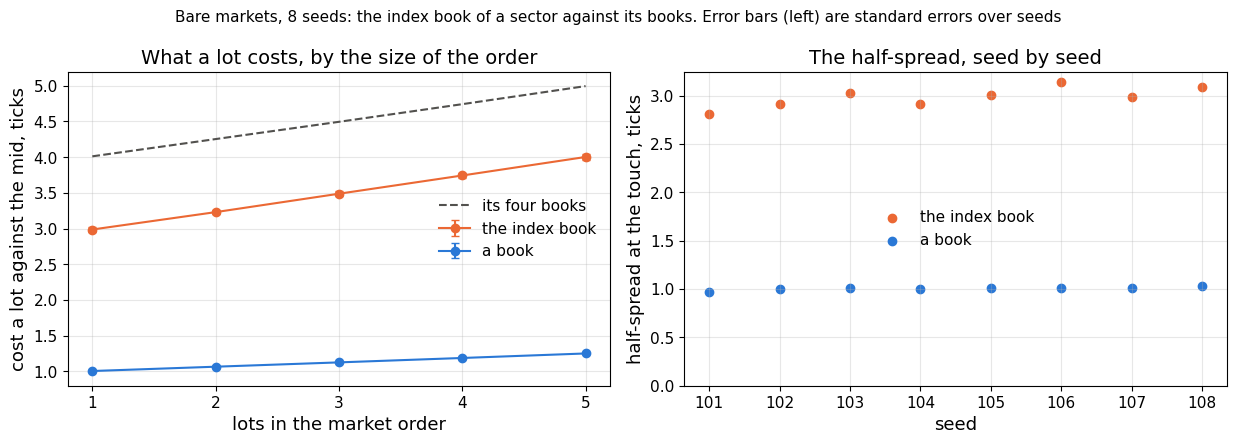


16 runs, 1.8 core-minutes.


In [23]:
# 3b. What each hedge costs. Bare markets (no trader in them): the sectors market with one more book, the sum of the
# four books of the first sector, which is book 12 and has scale 4 (FactorValues' index takes any weights over the
# twelve books; BookMarket makes a book of scale s a book like the others, s times over: its order flow reaches 8 s
# ticks, its starting book is s ticks apart). Every few units the books are read as they stand, without trading: the
# half-spread at the touch, and what a market order of 1 to 5 lots would cost against the mid, walking the resting
# depth, averaged over a buy and a sell.
BARE_BURN = length('bare burn', 500.0, least=300.0)
BARE_SPAN = length('bare span', 3_500.0, least=1_000.0)  # the books are read in the span, after the burn
BARE_EVERY = 7.0  # units of time between two readings of the books
BARE_LOTS = (1, 2, 3, 4, 5)  # the sizes of the market orders priced
INDEX_BOOK = BOOK_COUNT  # the index is the thirteenth book
INDEX_VOLATILITY = 0.4  # notebook 15's chosen point of the index's dial (CHOSEN), and its lowest point, as a control:
INDEX_DIAL = (
    INDEX_VOLATILITY,
    0.0,
)  # at 0 the premium has no noise of its own but the order flow's impact still makes one
fair_of_index = market_of('sectors', index=index_weights, index_volatility=INDEX_VOLATILITY)()
assert fair_of_index.n == BOOK_COUNT + 1 and fair_of_index.scales[INDEX_BOOK] == SECTOR_SIZE, 'not a scale-4 index book'
assert np.array_equal(fair_of_index.index_weights, index_weights), "the index is not the first sector's sum"
assert fair_of_index.level[INDEX_BOOK] == fair_of_index.level[:SECTOR_SIZE].sum(), (
    "the index does not start at its books' sum"
)


def lots_cost(levels, quantity):
    # What `quantity` lots cost, in the prices paid, walking these (price, depth) levels from the best; None if the
    # levels do not hold that many lots.
    left, paid = quantity, 0.0
    for price, depth in levels:
        take = min(left, depth)
        paid += take * price
        left -= take
        if not left:
            return paid
    return None


def read_books(market):
    # Each book's half-spread and the cost a lot of a market order of each size in BARE_LOTS, against the mid, averaged
    # over a buy (up the asks) and a sell (down the bids): read from the book as it stands. nan for a book with a side
    # that is empty, and for an order that the 40 best levels of a side cannot fill.
    half, cost = np.full(market.n, np.nan), np.full((len(BARE_LOTS), market.n), np.nan)
    for k, book in enumerate(market.books):
        if book.best_bid is None or book.best_ask is None:
            continue
        mid = (book.best_bid + book.best_ask) / 2
        half[k] = (book.best_ask - book.best_bid) / 2
        asks, bids = book.depth_profile(Side.ASK, 40), book.depth_profile(Side.BID, 40)
        for i, lots in enumerate(BARE_LOTS):
            buy, sell = lots_cost(asks, lots), lots_cost(bids, lots)
            if buy is not None and sell is not None:
                cost[i, k] = ((buy - lots * mid) + (lots * mid - sell)) / 2 / lots
    return half, cost


def bare_run(make_fair, seed):
    # One bare market, read every BARE_EVERY units of its span: the mean over the readings, book by book.
    check_seed(seed)
    market = BookMarket(make_fair(), seed=seed)
    started = time.time()
    end, due = BARE_BURN + BARE_SPAN, BARE_BURN
    half, cost = [], []
    while market.time < end:
        market.step()
        if market.time >= due:
            due += BARE_EVERY
            read = read_books(market)
            half.append(read[0])
            cost.append(read[1])
    return {
        'seed': seed,
        'half': np.nanmean(half, axis=0),
        'cost': np.nanmean(cost, axis=0),
        'readings': len(half),
        'secs': time.time() - started,
    }


bare_jobs = [(volatility, seed) for volatility in INDEX_DIAL for seed in FEW]
bare_results = Parallel(n_jobs=-1)(
    delayed(bare_run)(market_of('sectors', index=index_weights, index_volatility=volatility), seed)
    for volatility, seed in bare_jobs
)
bare_frame = pd.DataFrame(
    [
        {
            'volatility': volatility,
            'seed': seed,
            'readings': run['readings'],
            'secs': run['secs'],
            'half_index': run['half'][INDEX_BOOK],
            'half_book': run['half'][:SECTOR_SIZE].mean(),  # the four books the index is made of
            'half_others': run['half'][SECTOR_SIZE:INDEX_BOOK].mean(),  # the other eight
            **{f'index_{lots}': run['cost'][i, INDEX_BOOK] for i, lots in enumerate(BARE_LOTS)},
            **{f'book_{lots}': run['cost'][i, :SECTOR_SIZE].mean() for i, lots in enumerate(BARE_LOTS)},
        }
        for (volatility, seed), run in zip(bare_jobs, bare_results, strict=True)
    ]
)
assert bare_frame.drop(columns=['secs']).notna().all().all(), 'a bare market gave no reading of a quantity'
assert (bare_frame.readings > 0).all(), 'a bare market was never read'
per_book = np.mean([run['half'] for run in bare_results], axis=0)  # a book's half-spread, over every run
if not SMOKE:
    assert per_book[:INDEX_BOOK].max() - per_book[:INDEX_BOOK].min() < 0.05, 'the twelve books differ in their spreads'


def bare_line_of(frame, index_column, book_column):
    # The index book's figure and an ordinary book's, each over the seeds with its standard error (_se), the index less
    # the book seed by seed (diff) with its standard error and the seeds it is above (diff_positive), and the ratio of
    # the two seed by seed.
    x, y = frame[index_column], frame[book_column]
    return {
        'index': x.mean(),
        'index_se': se_of(x),
        'book': y.mean(),
        'book_se': se_of(y),
        'diff': (x - y).mean(),
        'diff_se': se_of(x - y),
        'diff_positive': f'{int((x > y).sum())} of {len(x)}',
        'ratio': (x / y).mean(),
        'ratio_se': se_of(x / y),
    }


bare_chosen = bare_frame[bare_frame.volatility == INDEX_VOLATILITY].set_index('seed')
# The cost a lot of an order of one lot is the half-spread: the mid is the middle of the touch, and a lot at the touch
# is bought at the ask and sold at the bid. The two are one row, and the cell asserts that they agree.
assert np.allclose(bare_frame.half_index, bare_frame.index_1) and np.allclose(
    bare_frame.half_book, bare_frame.book_1
), 'the cost of a lot in a 1-lot order is not the half-spread'
bare_table = pd.DataFrame(
    {
        'half-spread (= cost a lot, 1 lot)': bare_line_of(bare_chosen, 'half_index', 'half_book'),
        **{
            f'cost a lot, {lots}-lot order': bare_line_of(bare_chosen, f'index_{lots}', f'book_{lots}')
            for lots in BARE_LOTS[1:]
        },
    }
).T
print(
    f'A sector\'s sum index book (book {INDEX_BOOK}, scale {SECTOR_SIZE}) and its {SECTOR_SIZE} books, in bare markets '
    f'at index_volatility {INDEX_VOLATILITY}, {len(FEW)} seeds, {BARE_SPAN:,.0f} units read every {BARE_EVERY:g} '
    f'after a burn of {BARE_BURN:,.0f} ({int(bare_chosen.readings.mean())} readings a seed), in ticks, the mean over '
    'seeds '
    'with its standard error (_se, over seeds). A book is the mean of the four books the index is made of; diff is '
    'the index less the book and ratio the index over the book, seed by seed (diff_positive: the seeds on which the '
    'index is above):\n'
)
print(
    bare_table.to_string(
        formatters={column: formatter('.2f') for column in bare_table.columns if column != 'diff_positive'}
    )
)
bare_control = bare_frame[bare_frame.volatility == INDEX_DIAL[1]].set_index('seed')
print(
    f"\nThe control, at index_volatility {INDEX_DIAL[1]:g}: the index's half-spread is "
    f'{bare_control.half_index.mean():.2f} (se {se_of(bare_control.half_index):.2f}), against '
    f'{bare_chosen.half_index.mean():.2f} (se {se_of(bare_chosen.half_index):.2f}) at {INDEX_VOLATILITY}; a book\'s '
    f'is {bare_control.half_book.mean():.2f} (se {se_of(bare_control.half_book):.2f}).'
)
print(
    f'The eight books that are not in the index: half-spread {bare_chosen.half_others.mean():.2f} '
    f'(se {se_of(bare_chosen.half_others):.2f}), against {bare_chosen.half_book.mean():.2f} for the four that are.'
)

# A lot of the index is a lot of each of its four books in its exposure and its fair value. What it costs against what
# its four books cost, and what an entry of the residual trader costs by each route (the orders of each route, each
# priced at the cost a lot of an order of its size, so the orders of 4 and 5 lots are priced walking the book and are
# not at the touch): the PCA route is an order of 4 lots in the book and an order of 1 lot in each of its three mates;
# the index route is an order of 5 lots in the book and 1 lot of the index.
size, hedge_each = int(RESIDUAL['size']), 1
assert (size - hedge_each, hedge_each) == (4, 1) and index_lots == hedge_each, '3a: the hedge is not 4 lots against 1'
index_one, book_one = bare_chosen.index_1, bare_chosen.book_1
index_pca_entry = (size - hedge_each) * bare_chosen[f'book_{size - hedge_each}'] + (
    SECTOR_SIZE - 1
) * hedge_each * book_one
index_route_entry = size * bare_chosen[f'book_{size}'] + hedge_each * index_one
index_four = index_one - SECTOR_SIZE * book_one  # the index lot less a lot of each of its four books
index_dearer = index_route_entry - index_pca_entry  # an entry by the index route less an entry by the PCA route
print(
    f'\nA lot of the index, {index_one.mean():.2f} (se {se_of(index_one):.2f}), against a lot of each of its four '
    f'books, {SECTOR_SIZE} x {book_one.mean():.2f} = {SECTOR_SIZE * book_one.mean():.2f}. The index lot less its four '
    f'books, seed by seed: {said(index_four, 2)}.'
)
print(
    f'An entry of {size} lots, each order priced walking the book at its own size (not at the touch): the PCA route '
    f'{index_pca_entry.mean():.2f} (se {se_of(index_pca_entry):.2f}), the index route {index_route_entry.mean():.2f} '
    f'(se {se_of(index_route_entry):.2f}); the index route less the PCA route, seed by seed: '
    f'{said(index_dearer, 2)}.'
)
# What 3c reads: a book's and the index's cost a lot, by the size of the order (mean over the seeds), and the index lot
# in book lots at one lot.
bare_book_by_size = np.array([bare_chosen[f'book_{lots}'].mean() for lots in BARE_LOTS])
bare_index_by_size = np.array([bare_chosen[f'index_{lots}'].mean() for lots in BARE_LOTS])
index_price = float((bare_chosen.index_1 / bare_chosen.book_1).mean())  # the price of an index lot, in book lots

# The figure: the cost a lot by the size of the order, and the half-spread seed by seed.
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE_WIDE)
ax = axes[0]
for name, column, color in [('the index book', 'index', ORANGE), ('a book', 'book', BLUE)]:
    values = bare_chosen[[f'{column}_{lots}' for lots in BARE_LOTS]]
    ax.errorbar(BARE_LOTS, values.mean(), yerr=values.apply(se_of), color=color, marker='o', capsize=3, label=name)
ax.plot(
    BARE_LOTS,
    SECTOR_SIZE * bare_chosen[[f'book_{lots}' for lots in BARE_LOTS]].mean(),
    color=GRAY,
    ls='--',
    label='its four books',
)
ax.set_xticks(BARE_LOTS)
ax.set_xlabel('lots in the market order')
ax.set_ylabel('cost a lot against the mid, ticks')
ax.set_title('What a lot costs, by the size of the order')
ax.legend(frameon=False, loc='center right')
ax = axes[1]
places = np.arange(len(bare_chosen))
ax.scatter(places, bare_chosen.half_index, color=ORANGE, label='the index book')
ax.scatter(places, bare_chosen.half_book, color=BLUE, label='a book')
ax.set_xticks(places, [str(seed) for seed in bare_chosen.index])
ax.set_xlabel('seed')
ax.set_ylabel('half-spread at the touch, ticks')
ax.set_title('The half-spread, seed by seed')
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc='center')
fig.suptitle(
    f'Bare markets, {len(FEW)} seeds: the index book of a sector against its books. Error bars (left) are standard '
    'errors over seeds',
    fontsize=11,
)
fig.tight_layout()
plt.show()
print()
ran(bare_frame)

**The index book's half-spread is 2.99 ticks and a book's is 1.00 (means over eight seeds), and the index's is the larger on every seed.** In the bare markets at an `index_volatility` of 0.4, on eight seeds, the sector's sum index has a half-spread of 2.99 (standard error, se, 0.04) and a book of that sector 1.00 (se 0.01). The index less the book, seed by seed, is +1.98 (se 0.03), with the index above on 8 of 8 seeds, and the ratio seed by seed is 2.98 (se 0.02). A market order costs more a lot as it grows, in both books and faster in the index. At 5 lots the cost a lot is 4.00 (se 0.04) in the index and 1.25 (se 0.01) in a book, up from 2.99 and 1.00 at one lot, a rise of 1.01 and of 0.25 (plain differences of printed means). The index less the book is +2.75 (se 0.03) at 5 lots, again on 8 of 8 seeds, and the ratio is 3.20 (se 0.02): the index book is about three times as dear a lot at every size, and a little more than that as the order grows (2.98 at one lot, 3.04, 3.10, 3.16 and 3.20 at two to five).

**An index lot is cheaper than its four books, and dearer than one book.** A lot of the index costs 2.99 (se 0.04), against a lot of each of its four books, 4.01 in all (the printed line says 4 x 1.00 = 4.01: a book's half-spread is 1.00 rounded and a little above it before rounding). The index lot less its four books, seed by seed, is -1.03 (se 0.02, t -46.97, 0 of 8 seeds positive; 2.99 less 4.01 is -1.02 from the rounded figures, and the printed -1.03 is the mean of the seed-by-seed differences), so on no seed is the index lot the dearer. Its saving is 1.03 of 4.01, about a quarter (a plain ratio of two printed figures). The figure's dashed line for four books runs from 4.01 at one lot to 5.0 at five, above the index's 2.99 to 4.00 at every size. "Cheaper" is the index lot against its four books and not against one: against one book lot the index lot is 2.98 times as dear on average (the ratio at one lot, seed by seed), and dearer on every seed. That is the price 3c sets against the lots an index lot replaces.

**The control says the dial's noise is not where the spread comes from.** At an `index_volatility` of 0 the index's half-spread is 2.92 (se 0.02) against 2.99 (se 0.04) at 0.4, which is 0.07 lower (a plain difference of two printed means, whose standard errors are 0.02 and 0.04), and a book's is 0.99 (se 0.00). So nearly all of the index book's spread is there with the dial's own noise turned off. Zero is not a market with no premium, since the order flow's own market orders make one at any point of the dial, and the control does not say what that premium contributes. What it rules out is the dial's noise as the main source of a spread of about 3 ticks. The method gives the order flow in the index book a reach of 32 ticks, where a book's is 8, as the scale of 4 makes it, and that is the candidate for the source. No cell prints that reach and no cell here varies it, so it is a reading and not a measurement. The books outside the index are like those in it: the eight that are not in the index have a half-spread of 1.00 (se 0.01), against 1.00 for the four that are, so "a book" in the table is any book.

**An entry of 5 lots is dearer by the index route, by 1.48 ticks.** The cell prices an entry of the residual trader's 5 lots by each route, each order at the cost a lot of an order of its size from the table above. The PCA route is an order of 4 lots in the book and three orders of 1 lot in its mates: 7.75 (se 0.05). The index route is an order of 5 lots in the book and an order of 1 lot of the index: 9.23 (se 0.07). The index route less the PCA route, seed by seed, is +1.48 (se 0.03, t 48.44, 8 of 8 seeds positive), so the index route is the dearer on every seed. The printed terms account for it. The PCA route's 4 lots cost 1.19 a lot and each mate's lot 1.00, which gives 4 x 1.19 + 3 x 1.00 = 7.76, and the index route's 5 lots cost 1.25 a lot and the index lot 2.99, which gives 5 x 1.25 + 2.99 = 9.24, both within rounding of the printed lines. The index lot, at 2.99, costs what the three mates' lots it replaces cost (3 x 1.00, 0.01 apart). The 1.48 is the one more lot of the book that the index route's order holds, 5 x 1.25 less 4 x 1.19, which is 1.49. So the index route gains 0.01 on the mates and pays 1.49 for another lot of the book.

**What the entry figure is.** It is not an entry "at the touch": the printed line says that each order is priced walking the book at its own size, as the method does. The 4-lot and 5-lot orders are priced at 1.19 and 1.25 a lot, which is walking the book, and the figure is the bare books' cost a lot at each order's size. It is from bare markets with no trader in them, so it is before the premium's noise, which can only add to the index route's cost, and it counts the opening only: the closing orders are the same two routes reversed. It does not say what an entry costs a trader who is in the market, whose own orders move the books.

### 3c. What the Cheapest Mix Would Save

**The replay.** The residual trader's own orders, from the eight recorded runs of 3a: the change in what it held at each decision of its span, book by book. Suppose each sector had a sum index book. At each decision and in each sector, the trader's change of position is dx lots in each of the sector's four books, and the same change of exposure can be had as h lots of the index and dx - h lots of the books, for any whole number h, positive or negative (a lot of the index is a lot of each of the four books). The orders then cost the sum over the four books of the cost of an order of |dx - h| lots, plus the cost of an order of |h| lots of the index. h = 0 is the trader as it traded; the replay takes the cheapest h at each decision and sector, a tie going to the books. A tie between two other mixes of equal cost, which arises only at a price of exactly 0 or 2 book lots, is broken in a fixed order: it moves the `index_lots` column there and not the saving, which is the cost of the cheapest mix and is the same whichever of two equal ones is taken. The share of the trader's crossing cost that this saves, run by run, is the saving of this one policy, the cheapest mix at each decision on its own, for an index that has a price of an index lot and nothing else; it is not the most that any use of an index could save, and not a floor on it.

**Three prices of an index lot, and one more.** In book lots (a book lot is what a lot costs in the books, so the replay does not depend on what the trader paid a lot): what 3b measured, the mean over seeds of the index's cost a lot at one lot over a book's; the same priced by the size of the order, from 3b's costs a lot at 1 to 5 lots (larger orders at the 5-lot cost a lot); a lot that costs what a book lot does (1); and a lot that costs nothing (0). The last two are the bounds of a market where the index book is as liquid as a book, or more: they say what a cheap index would be worth, without a market that has one. Every price replays the same eight runs, so the rows are paired by seed, and a standard error is over the seeds. The cell also prints the whole curve, the share saved at each price from 0 to 4 book lots, with the line where 3b's price falls.

**Why a saving is expected only where an index lot is cheap.** A residual is neutral within its sector: what the factors take of a book is a quarter of each of the sector's four, so the relation is 3.75 lots of the book against 1.25 of each mate, and its four lots sum to nothing before the rounding to whole lots. An index sells the sector's uniform exposure, which a neutral position holds none of, net: the trader never wants that exposure, and can use an index only as a stand-in for its hedge. A lot of the index is a lot of each of the four books, the book's own among them, so in an order of 4 lots of a book against 1 of each of three mates one index lot replaces the three mates' lots (three book lots) by forcing one more lot of the book on the order (five book lots in the one book). It is worth using where it costs less than 3 - 1 = 2 book lots, and the saving at a price p below 2 is 2 - p of the 7 lots of the order. For an order of this shape the index is not worth using at a price of 2 and above; an order of another shape could be (four lots in the same direction, which one index lot replaces, is), and the replay says whether any of the trader's are. The cell also prints what the four books' lots add up to in the orders that a sector got, which is the uniform exposure that an index sells and that the orders hardly ask for.

**What the replay is, and is not.** It is the saving of one feasible policy, the cheapest mix at each decision on its own, in a market whose index book has a price of an index lot and no other cost: no premium noise, which is the noise of an index in a fair value that differs from its books', and no impact of its own, which would move the index's premium by the trader's own orders. Both only take away from the saving. A policy that nets the index lots it holds across decisions could save a little more than this one; it is not replayed. It is not a market in which an index book is traded by the residual trader: the trader's decisions, its signals and its s-scores would then be those of another market, with fifteen books and another stream of order flow, and are not the replay's.

**What the cell asserts.** That the replay with no index (an index too dear to use) is the trader's own lots, seed by seed, and uses no index lot; and, on the curve, that a dearer index never saves more, on any seed.

The residual trader's orders on 8 seeds (4,294 lots a run, costing 5,034 ticks to cross, 1.17 a lot), replayed with the cheapest mix of the books and a sector index. The price of an index lot is in book lots; saved is the share of the crossing cost the mix saves, the mean over seeds (saved_se, in points of a percent, over seeds; saved_positive: the seeds with a saving); index_lots the index lots it uses as a share of the book lots; ticks the share of the run's costs, in ticks a run (ticks_se over seeds), and of_pnl those over the mean P&L, a size beside a plain after-cost P&L:

                                        an index lot  saved saved_se saved_positive index_lots   ticks ticks_se of_pnl
an index lot costs what 3b measured (2.98 book lots)  0.01%     0.00         2 of 8      0.000     0.3      0.2  0.01%
the same, by the size of the order (3b: 1 to 5 lots)  0.01%     0.00         2 of 8      0.000     0.3      0.2  0.01%
             an index lot costs what a book lot does 13.27


By the price of an index lot, in book lots, the share of the crossing cost saved (mean over seeds, se): 0: 26.5% (0.1), 0.5: 19.9% (0.1), 1: 13.3% (0.1), 1.5: 6.6% (0.0), 2: 0.0% (0.0), 2.5: 0.0% (0.0), 3: 0.0% (0.0), 3.5: 0.0% (0.0), 4: 0.0% (0.0)
On the curve the mean saving prints as 0.0% (under 0.05%) from 2 book lots a lot up, and on no seed is there any saving from 4 up. At the prices between, the most that any seed saves is 0.047% of its crossing cost.


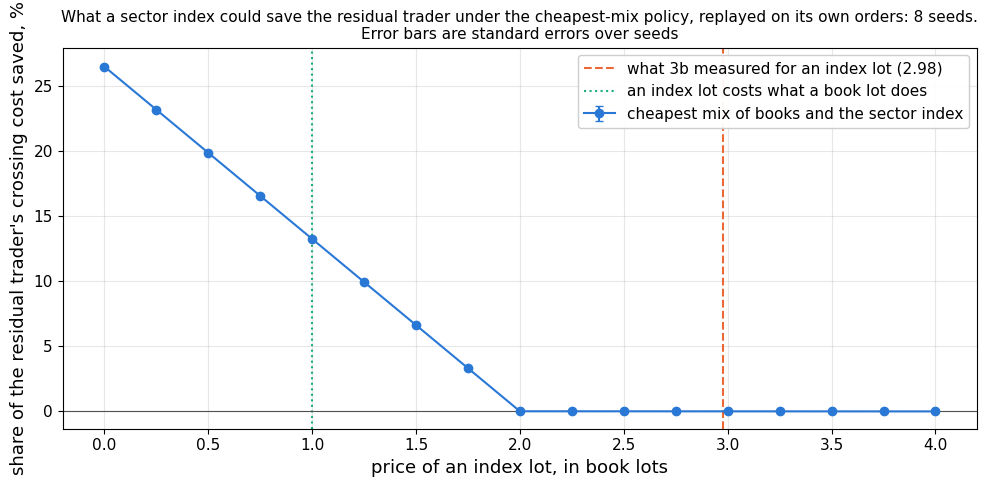

In [24]:
# 3c. What the cheapest mix would save. The residual trader's own orders (index_moves, from the runs of 3a: the change
# in what it held at each decision of its span) replayed. At each decision and in each sector the same change of
# exposure, dx lots in each of the sector's four books, can be had as h lots of the sector's sum index and dx - h in the
# books (h a whole number, positive or negative): an index lot is a lot of each of the four books. The cheapest h costs
# the sum over the four books of the cost of an order of |dx - h| lots, plus the cost of an order of |h| lots of the
# index; h = 0 is the trader as it traded. The index is not traded: nothing of its premium's noise or of its own impact
# is in this, which could only take away from what it saves. What it saves is the saving of this one policy, the
# cheapest mix at each decision on its own, for an index that has a price of a lot and nothing else: not the most that
# any use of an index could save (one that nets index lots held over decisions might do a little better) and not a
# floor on it (the noise and the impact would take away from it).
def order_costs(per_lot, largest):
    # What an order of q lots costs in all, q = 0 to `largest`, from a cost a lot that may depend on the order's size:
    # per_lot[q - 1] for orders of 1 to len(per_lot) lots, and the last for larger ones.
    q = np.arange(largest + 1)
    return q * np.asarray(per_lot, dtype=float)[np.minimum(q, len(per_lot)) - 1]


def cheapest_mix(moves, book_per_lot, index_per_lot, reach=12):
    # moves: decisions by books. The cost of the orders as they were and of the cheapest mix, the index lots it uses and
    # the book lots there were. Costs are in the units of the cost a lot that is given (book lots, say, or ticks).
    rows = moves.reshape(-1, SECTOR_SIZE)  # a row a decision and sector: the sector's books are four in a row
    rows = rows[(rows != 0).any(axis=1)]
    shifts = np.array(sorted(range(-reach, reach + 1), key=abs))  # 0 first, so that a tie keeps the books
    largest = int(np.abs(rows).max()) + reach
    books, index = order_costs(book_per_lot, largest), order_costs(index_per_lot, largest)
    mix = books[np.abs(rows[:, None, :] - shifts[None, :, None])].sum(axis=2) + index[np.abs(shifts)][None, :]
    chosen = np.where(mix.min(axis=1) < mix[:, 0] - 1e-9, mix.argmin(axis=1), 0)
    return mix[:, 0].sum(), mix[np.arange(len(rows)), chosen].sum(), np.abs(shifts[chosen]).sum(), np.abs(rows).sum()


def ledger_replay(book_per_lot, index_per_lot):
    # Every seed's run replayed: a line a seed with the share of the crossing cost the cheapest mix saves (0 if it uses
    # no index), the index lots it uses as a share of the book lots, and what that is in ticks of the run's costs.
    lines = []
    for seed in FEW:
        base, mixed, used, lots = cheapest_mix(index_moves[seed], book_per_lot, index_per_lot)
        run = index_frame[index_frame.seed == seed].iloc[0]
        lines.append(
            {
                'seed': seed,
                'saved': 1 - mixed / base,
                'index lots': used / lots,
                'ticks': (1 - mixed / base) * run.costs,
                'pnl': run.pnl,
            }
        )
    return pd.DataFrame(lines).set_index('seed')


# Before anything: the books-only replay is the trader's own cost, in lots, whatever the price of an index lot, and an
# index too dear to use is never used.
for seed in FEW:
    base, mixed, used, lots = cheapest_mix(index_moves[seed], [1.0], [1.0e6])
    assert base == mixed == lots == index_frame[index_frame.seed == seed].lots.iloc[0] and used == 0, (
        f'seed {seed}: the replay of the trader as it traded is not its own lots, or a very dear index was used'
    )

# The price of an index lot, in book lots: what 3b measured, the same by the size of the order, a book's, and none.
LEDGER_CASES = {
    f'an index lot costs what 3b measured ({index_price:.2f} book lots)': ([1.0], [index_price]),
    'the same, by the size of the order (3b: 1 to 5 lots)': (bare_book_by_size, bare_index_by_size),
    'an index lot costs what a book lot does': ([1.0], [1.0]),
    'an index lot costs nothing': ([1.0], [0.0]),
}
index_replays = {name: ledger_replay(*prices) for name, prices in LEDGER_CASES.items()}
rows = []
for name, got in index_replays.items():
    rows.append(
        {
            'an index lot': name,
            'saved': f'{got.saved.mean():.2%}',
            'saved_se': f'{se_of(got.saved) * 100:.2f}',
            'saved_positive': f'{int((got.saved > 1e-9).sum())} of {len(got)}',
            'index_lots': f'{got["index lots"].mean():.3f}',
            'ticks': f'{got.ticks.mean():,.1f}',
            'ticks_se': f'{se_of(got.ticks):.1f}',
            'of_pnl': f'{got.ticks.mean() / got.pnl.mean():.2%}',
        }
    )
print(
    f"The residual trader's orders on {len(FEW)} seeds ({index_frame.lots.mean():,.0f} lots a run, costing "
    f'{index_frame.costs.mean():,.0f} ticks to cross, {index_frame.costs.sum() / index_frame.lots.sum():.2f} a lot), '
    'replayed with the cheapest mix of the books and a sector index. The price of an index lot is in book lots; saved '
    'is the share of the crossing cost the mix saves, the mean over seeds (saved_se, in points of a percent, over '
    'seeds; saved_positive: the seeds with a saving); index_lots the index lots it uses as a share of the book lots; '
    "ticks the share of the run's costs, in ticks a run (ticks_se over seeds), and of_pnl those over the mean P&L, a "
    'size beside a plain after-cost P&L:\n'
)
print(pd.DataFrame(rows).to_string(index=False))

# The reason, from the orders themselves: what the four books' lots add up to in each order a sector got, in lots. An
# index sells that uniform exposure and nothing else, and a residual's orders are neutral within the sector (what the
# factors take of a book is a quarter of each of the four), but for a lot that rounding leaves.
index_sector_rows = np.vstack([moves.reshape(-1, SECTOR_SIZE) for moves in index_moves.values()])
index_sector_rows = index_sector_rows[(index_sector_rows != 0).any(axis=1)]
index_added = np.abs(index_sector_rows.sum(axis=1))
print(
    f"\nThe orders a sector got ({len(index_sector_rows) / len(FEW):,.0f} a run): the four books' lots add up to 0 in "
    f'{(index_added == 0).mean():.1%}, to 1 either way in {(index_added == 1).mean():.1%} and to 2 or more in '
    f'{(index_added >= 2).mean():.1%}; '
    f'{np.abs(index_sector_rows).sum(axis=1).mean():.1f} lots an order, {np.abs(index_sector_rows).max()} at most.'
)

# The curve: the share saved at each price of an index lot from 0 to 4 book lots (the price of an index lot that
# replaces three mates' lots and forces one more of the book is 2 at break-even), seed by seed.
LEDGER_PRICES = np.arange(0.0, 4.01, 0.25)
index_curve = pd.DataFrame({price: ledger_replay([1.0], [price]).saved for price in LEDGER_PRICES})
assert (np.diff(index_curve.mean().to_numpy()) <= 1e-12).all(), 'the saving rose with the price of an index lot'
assert (np.diff(index_curve.to_numpy(), axis=1) <= 1e-12).all(), (
    'on a seed the saving rose with the price of an index lot'
)
dear = index_curve.columns[index_curve.max() < 1e-9]  # the prices at which no seed saves anything
small = index_curve.columns[index_curve.mean() < 5e-4]  # the prices at which the mean saving prints as 0.0%
print(
    '\nBy the price of an index lot, in book lots, the share of the crossing cost saved (mean over seeds, se): '
    + ', '.join(
        f'{price:g}: {index_curve[price].mean():.1%} ({se_of(index_curve[price]) * 100:.1f})'
        for price in LEDGER_PRICES[::2]
    )
)
# The rows above print the mean saving to a tenth of a percent, which reads 0.0% from `small.min()` up; the saving is
# exactly 0 on every seed only from `dear.min()` up, and between the two a seed may still save a trace, which the last
# sentence gives as the most that any seed saves there.
if not len(dear):
    zero_text = 'A saving at every price on the curve (up to 4 book lots a lot).'
elif not len(small) or small.min() >= dear.min():
    zero_text = f'On the curve no seed has any saving from {dear.min():g} book lots a lot up.'
else:
    zero_text = (
        f'On the curve the mean saving prints as 0.0% (under 0.05%) from {small.min():g} book lots a lot up, and on no '
        f'seed is there any saving from {dear.min():g} up.'
    )
    between = [price for price in LEDGER_PRICES if small.min() <= price < dear.min()]
    zero_text += (
        f' At the prices between, the most that any seed saves is {index_curve[between].to_numpy().max():.3%} of its '
        'crossing cost.'
    )
print(zero_text)

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.errorbar(
    LEDGER_PRICES,
    index_curve.mean() * 100,
    yerr=index_curve.apply(se_of) * 100,
    color=BLUE,
    marker='o',
    capsize=3,
    label='cheapest mix of books and the sector index',
)
ax.axvline(index_price, color=ORANGE, ls='--', label=f'what 3b measured for an index lot ({index_price:.2f})')
ax.axvline(1.0, color=AQUA, ls=':', label='an index lot costs what a book lot does')
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlabel('price of an index lot, in book lots')
ax.set_ylabel("share of the residual trader's crossing cost saved, %")
ax.set_title(
    'What a sector index could save the residual trader under the cheapest-mix policy, replayed on its own orders: '
    f'{len(FEW)} seeds.\n'
    'Error bars are standard errors over seeds',
    fontsize=11,
)
ax.legend(loc='upper right', framealpha=0.95)
fig.tight_layout()
plt.show()

# What the conclusions read.
index_headline = {
    'measured_price': index_price,
    'saved_measured': index_replays[next(iter(LEDGER_CASES))].saved,
    'saved_as_a_book': index_replays['an index lot costs what a book lot does'].saved,
    'saved_free': index_replays['an index lot costs nothing'].saved,
    'ticks_free': index_replays['an index lot costs nothing'].ticks,
}

**At the price 3b measured, the cheapest mix saves a trace.** The replay takes the residual trader's orders on the eight seeds (4,294 lots a run, costing 5,034 ticks to cross, 1.17 a lot) and, at each decision and in each sector, the cheapest way to hold the same change of exposure with the four books and a sector index. With an index lot at what 3b measured, 2.98 book lots, the share of the crossing cost saved is 0.01% (standard error, se, 0.00 points of a percent, as printed), with a saving on 2 of 8 seeds. The mix uses next to no index lots (`index_lots` 0.000, the index lots as a share of the lots the trader traded) and saves 0.3 ticks a run (se 0.2), 0.01% of the P&L. Priced by the size of the order, from 3b's cost a lot at 1 to 5 lots, the row is the same: 0.01% (se 0.00), 2 of 8 seeds, 0.3 ticks a run (se 0.2). At the printed decimals that is nothing, and a trace on two seeds is all it can be called.

**At a book's price it saves 13.27%, and for nothing 26.52%.** If an index lot cost what a book lot does, the share saved is 13.27% (se 0.06), with a saving on 8 of 8 seeds. The mix then uses 0.133 index lots for each lot the trader traded (`index_lots`, 13.3 for every 100) and saves 667.7 ticks a run (se 14.2), 16.42% of the P&L. If an index lot cost nothing it is 26.52% (se 0.12), on 8 of 8 seeds, with the same 0.133 index lots for each lot traded, 1,334.8 ticks a run (se 28.4) and 32.82% of the P&L. The ticks and the share of the P&L set a saving of crossing costs beside the plain after-cost P&L of 3a's table (+4,067). They show how large a saving would be next to that P&L, and they are not an edge or a forecast of what a trader with an index would make.

**What each figure is.** Each is the saving of the cheapest mix at each decision of this replay, which is one policy. It takes the index as a price of an index lot and nothing else, so it is before the premium's noise and before the index's own impact, and both of those only take away from a saving. A policy that nets the index lots it holds across decisions could save more and is not replayed. So these are the savings of this policy at these prices: not the most that an index could save, and not a floor. The rows are paired by seed, the same eight runs at every price, so a standard error is over the seeds' savings and the rows can be compared with one another.

**The orders are nearly neutral across the four books, so an index lot can only stand in for the mates' lots.** A sector got 660 orders a run. The four books' lots add up to 0 in 10.7% of them, to 1 either way in 83.7% and to 2 or more in 5.6%, so 94.4% add up to 0 or 1 (10.7 and 83.7 added). An order holds 6.5 lots in all four books on average. The line prints "6 at most" after it, and that 6 is the largest lot in any single book of any order (the cell takes the largest single lot), not the largest order. The uniform exposure that a sector index sells is these sums, and they are 0 or the one lot that rounding leaves in nearly every order, so the trader has next to no exposure to sell. An index lot can then only replace the mates' lots, and it brings one more lot of the book with it. Against three mates' lots, that makes the break-even price 3 - 1 = 2 book lots, from the arithmetic of the method above.

**The curve reaches 0 at the break-even, and the measured price is above it.** The share saved is 26.5% (se 0.1) at an index lot of 0 book lots, 19.9% (0.1) at 0.5, 13.3% (0.1) at 1, 6.6% (0.0) at 1.5 and 0.0% at each of 2, 2.5, 3, 3.5 and 4. It falls by 6.6 or 6.7 points of a percent for each half book lot (plain differences of the printed shares) and reaches 0.0% at 2, which is the arithmetic's break-even. The last line says that the mean saving is under 0.05% (it prints as 0.0%) from 2 book lots a lot up, and that on no seed is there any saving from 4 up, which is where the saving is exactly 0 on every seed, on the quarter steps that the curve is computed at. At the prices between, it prints that the most that any seed saves is 0.047% of its crossing cost: from 2 to 4 the mean rows are 0.0% and a trace remains on some seeds, and the measured price, 2.98, is in that stretch and saves a mean of 0.01% over the eight seeds, with a saving on two of them (the most that any seed saves anywhere in the stretch is 0.047%). The trace is consistent with a few orders of another shape, such as four lots in the same direction, which one index lot replaces at any price below 4 (the method's example); the cell does not print which orders they were. The measured price is 0.98 book lots above the break-even (a plain difference), and the saving there is a trace.

**So the answer here is no, in this market.** A residual trader that hedged with this market's sector index would not pay less to trade, by what 3b and 3c measure: an entry by the index route is dearer by 1.48 ticks (3b) and the cheapest mix at each decision saves 0.01%. The answer rests on this market's index costing 2.98 book lots a lot against a break-even of 2. It is not an answer for an index at another price, and the savings at a book's price and at nothing say what such an index would be worth to this policy, in a market that this section does not build.

### 3d. One Index of All Twelve Books, as a One-Factor Hedge

Notebook 15's index book is made of all twelve books, and a sector index of one sector's four. 3d asks what each would leave of a book's factor variance if it were the whole hedge, one leg at the best ratio, and answers it by arithmetic from the market's loadings and the factors' volatilities: a calculation, and not a run. A book's factor part is its row of loadings times the factors (a market factor and three sector factors); hedged with one index at the best ratio, what is left of its variance is one less the squared correlation of the two factor parts. The cell prints it for the index of all twelve books, with weights of 1, for each book, and for the sum index of the book's own sector. The three factors of the PCA hedge of 3a span the loadings, so they leave none of it by construction; the cell says so and does not compute it.

In [25]:
# What one index of all twelve books would leave of a book's factor variance as a one-factor hedge, by arithmetic from
# the market's loadings and the factors' volatilities: not a run. A book's factor part is its row of loadings times the
# factors; hedged with one index at the best ratio, what is left of its variance is 1 less the squared correlation of
# the two factor parts.
fair_of_sectors = market_of('sectors')()
factor_cov = np.diag(fair_of_sectors.volatility**2)
rows = fair_of_sectors.loadings  # the twelve books' loadings on the market factor and the three sector factors


def left_by(book_rows, hedge_row):
    # Of the variance of each book's factor part, the share that a hedge of this index's factor part leaves.
    covariance = book_rows @ factor_cov @ hedge_row
    variances = ((book_rows @ factor_cov) * book_rows).sum(axis=1)
    return 1 - covariance**2 / (variances * (hedge_row @ factor_cov @ hedge_row))


left_all = left_by(
    rows, np.ones(BOOK_COUNT) @ rows
)  # the index of all twelve books, with weights of 1: its loadings are the sum
left_own = np.array(
    [
        left_by(rows[book : book + 1], np.eye(SECTOR_COUNT)[book // SECTOR_SIZE].repeat(SECTOR_SIZE) @ rows)[0]
        for book in range(BOOK_COUNT)
    ]
)  # the sum index of the book's own sector
print(
    f'A book hedged with one index of all {BOOK_COUNT} books, at the best ratio, keeps {left_all.mean():.3f} of the '
    f'variance of its factor part ({left_all.min():.3f} to {left_all.max():.3f} over the books); hedged with the '
    f'index of its own sector it keeps {left_own.mean():.3f} ({left_own.min():.3f} to {left_own.max():.3f}). The '
    'three factors of the PCA hedge keep none of it, by construction: they span the loadings.'
)

A book hedged with one index of all 12 books, at the best ratio, keeps 0.333 of the variance of its factor part (0.333 to 0.333 over the books); hedged with the index of its own sector it keeps 0.000 (0.000 to 0.000). The three factors of the PCA hedge keep none of it, by construction: they span the loadings.


**One index of all twelve books keeps a third of a book's factor variance, and its own sector's index keeps none.** This is arithmetic from the market's loadings and the factors' volatilities, and not a run, so it has no seeds and no standard errors. A book hedged with one index of all 12 books, at the best ratio, keeps 0.333 of the variance of its factor part, the same 0.333 for every book (0.333 to 0.333 over the books). Hedged with the index of its own sector it keeps 0.000 (0.000 to 0.000). So as the whole hedge, in one leg, notebook 15's index of all twelve books leaves a third of a book's factor variance unhedged, and a sector's own index leaves none of it at the three decimals printed: in this market a sector index is a one-factor hedge for its own sector, and the index of all twelve is not. The three factors of the PCA hedge keep none of it either, by construction, since they span the loadings. In the factor part, then, the sector index and the PCA hedge hedge the same thing, and they differ in what they cost, which 3b and 3c measure. The arithmetic is about a book's factor part only. It leaves out the book's own part, which no index hedges, and it says nothing of costs.

### In a Backtest's Terms

The scorecard and signal chart of the residual trader, in the sectors market with no deals and no index, on the first seed of this section's, 101, which played no part in choosing any setting: notebook 12's best rule, three factors, a size of 5 lots (the weight on the book is 1 before the hedge, so 3.75 lots of the book before the rounding), a window of 400 decisions, opening at an s-score of 1.5 and closing at 0, deciding every 5 units. It is the recorded run of the table of 3a for that seed, to its end. The chart is of the book whose lots change most often, and its signal is that book's s-score, against the levels the trader opens at (above 1.5 it sells the book against its factor hedge, below -1.5 it buys it) and closes at (0). The card is on capital of 250,000 ticks x lots, not the 150,000 of the other sections' cards: this trader holds up to some fifty lots of books worth some 3,000 ticks each (49 lots at its most on seeds 1 to 8, where this was looked at: a figure from a comment in the cell's code, which no cell prints and which was not rerun; the cell prints what the run on seed 101 holds at its most), which can be more than 150,000. The cell prints how much it holds at its most, as a multiple of the capital, and asserts that it is no more than the capital.

**A card's hit rate and profit factor are those of legs, not of relations.** The record holds the position in each book after each decision, so a "trade" of the scorecard is a run of one sign in one book. A residual is one book against its sector mates, and a book is a leg of several relations in turn, and the mates it is hedged with are legs too, each with its own noise: so the scorecard's trades are legs and not residuals.

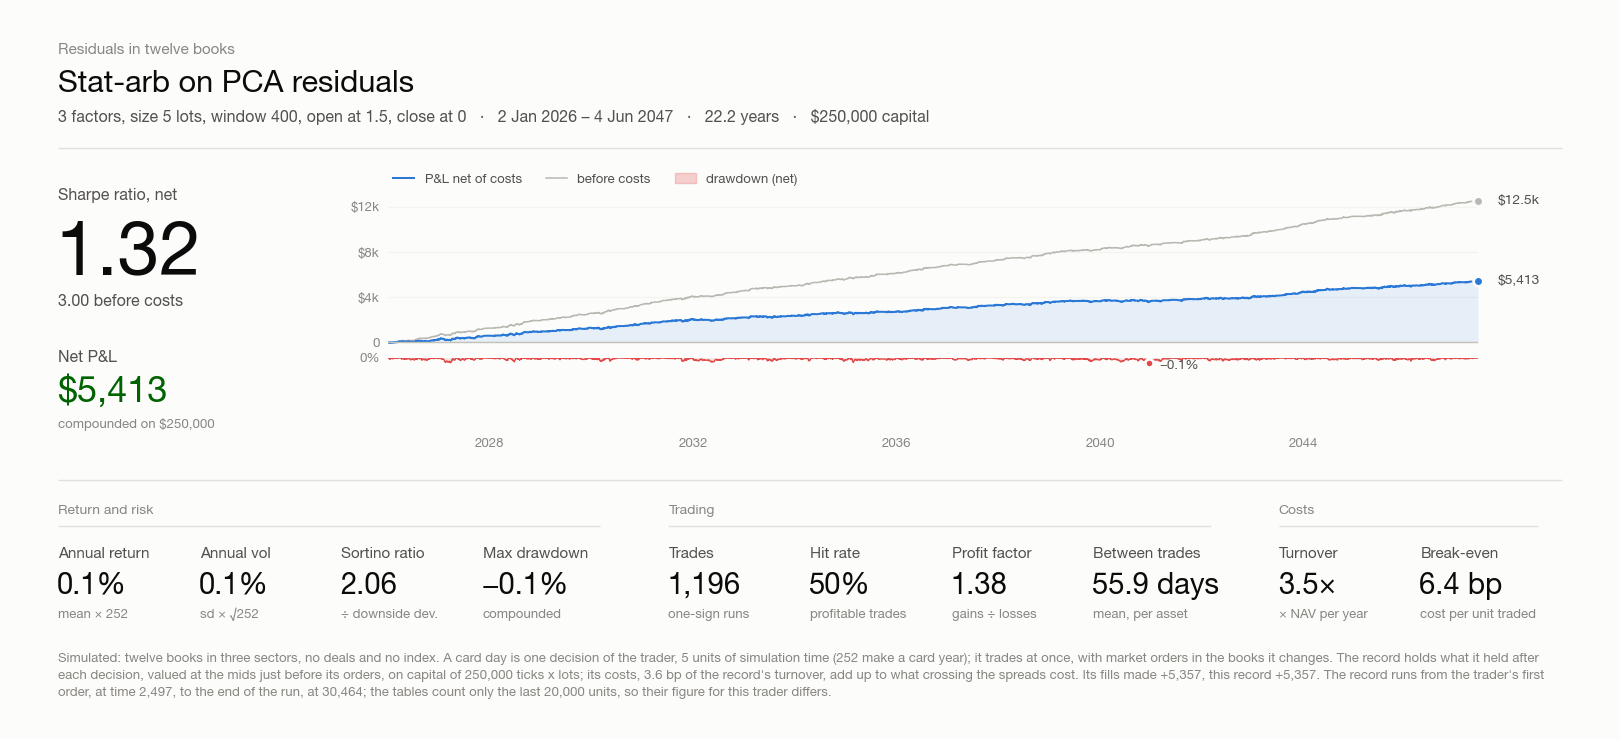

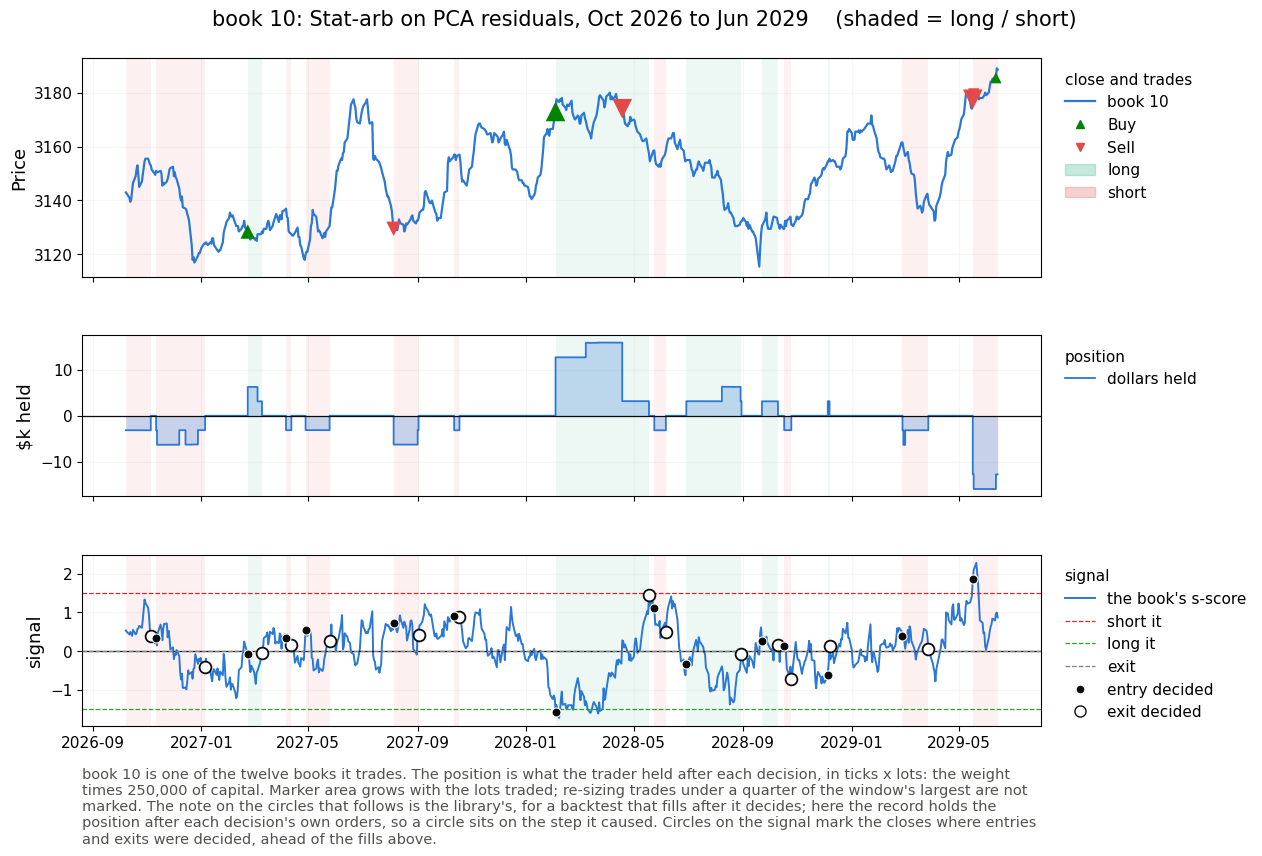

Residuals in twelve books: its fills made +5,357 and the record +5,357; it holds at most 0.53 times the capital of 250,000, and more than it on 0.0% of days.
The table's figure for this run (seed 101), the last 20,000 units only: +3,426. The chart is of book 10, of sector 2.


In [26]:
# The scorecard and signal chart of the residual trader on the first seed of this section's (a seed no setting was
# chosen on): the run of the table above for that seed, recorded to its end. The chart is of the book whose lots change
# most often, and its signal is that book's s-score, against the levels the trader opens and closes at.
index_card_trader, index_card_fills, index_card_market = recorded(
    market_of('sectors'), residual_by(), RESIDUAL_BURN, seed=FEW[0]
)
index_card_book = most_changed(index_card_trader)
# More than the 150,000 of the other cards: on seeds 1 to 8 this trader held up to 49 lots at its most, and a lot is
# some 3,000 ticks, so it can hold more than 150,000 ticks x lots; the card prints how much it holds at its most.
INDEX_CAPITAL = 250_000.0
index_card = card(
    index_card_trader,
    index_card_fills,
    'Stat-arb on PCA residuals',
    '3 factors, size 5 lots, window 400, open at 1.5, close at 0',
    'Residuals in twelve books',
    'twelve books in three sectors, no deals and no index',
    "the book's s-score",
    around(index_card_trader),
    index_card_book,
    relation=index_card_book,
    capital=INDEX_CAPITAL,
)
assert index_card['peak'] <= 1.0, (
    f'it holds {index_card["peak"]:.2f} times the capital of {INDEX_CAPITAL:,.0f} at its most'
)
# The table's figure for this run, over the span only (the card's fills are from the run's start and to its end).
index_card_counted = index_frame[index_frame.seed == FEW[0]].pnl.item()
print(
    f"The table's figure for this run (seed {FEW[0]}), the last {SPAN:,.0f} units only: "
    f'{index_card_counted:+,.0f}. The chart is of book {index_card_book}, of sector {index_card_book // SECTOR_SIZE}.'
)

**The card is one run, on seed 101, and its lines agree.** The line under it says the residual trader's fills made +5,357 and the record +5,357, so the two counts of the run are the same. The most the run holds is 0.53 times the capital of 250,000, the capital set for this card and not the 150,000 of the other sections' cards, for the reason given above, and it holds more than the capital on 0.0% of days. The product of those two printed figures is about 132,500 ticks x lots, which is under 150,000, so on this seed the larger capital was not needed. The table's figure for the same run is +3,426, which counts the last 20,000 units only. The card's footnote has the record running from the trader's first order, at time 2,497, to the end of the run, at 30,464, so the card's +5,357 covers a longer stretch of the same run than the table's +3,426, and the two are not the same quantity. The card's headline net P&L, \$5,413, is a third figure: it is labeled compounded on \$250,000, and its dollar sign stands for ticks x lots. The lines under the card are the ones this section quotes.

**What the chart shows.** The chart is of book 10, of sector 2, the book whose lots change most often: its s-score against the levels the trader opens at (1.5 and -1.5) and closes at (0), with that book's position under the price. The largest long opens where the s-score reaches about -1.5 and the largest short, at the end of the run, where it is above 1.5, and the position is flat for long stretches between. Many smaller steps are at s-scores between -1 and 1, because a book is also a leg of the other books' relations, as the note above says, and the chart does not separate the two. It is one seed, an illustration of what the trader's record looks like, and not evidence about the trader.

### What This Section Cannot Show

- **No index book is traded by the residual trader here.** 3c replays the orders that the trader made in a market with no index, and asks what the cheapest mix of the books and a sector index would have cost for the same changes of position. A trader that used an index would be in a market of fifteen books and another stream of order flow (an index book's flow draws from the stream the books' do), its decisions and its orders would be other than these, and the section does not run it. The only trader of this notebook with an index book to trade is notebook 15's index arbitrage, whose book is of all twelve.
- **The replay is one policy, and an index with a price and nothing else.** Its saving is that of the cheapest mix at each decision taken on its own. A policy that nets the index lots it holds across decisions could save a little more, which the replay does not try; and an index book also has a premium whose noise the trader would hold, and an impact of its own, which the replay leaves out and which could only take away from what it saves. So the figures of 3c are the saving of this policy in a market where an index lot has a price and nothing more. They are the saving of that policy: not the most that an index could save this trader (a policy that nets index lots across decisions could save more), and not a floor on it either (the premium's noise and the impact would take away from it), and they say nothing of any other use of an index.
- **An index made cheap by more order flow of its own is not built.** The index here is the library's book of scale 4: its order flow reaches four times as far as a book's, its fair value moves several times as far a unit of time, and what a lot of it costs is what 3b measures. Other models for it, through `BookMarket(models=...)`, gave a cheaper half-spread on seeds 1 to 4 only with several times the order flow, and a narrower reach did not. This section runs none of them: 3c's curve prices an index lot at any price from 0 to 4 book lots, so what such an index would save can be read off it, but whether a market could hold an index at that price, with that flow, is not shown, and nothing here says what it would do to the premium.
- **The index carries no information the books lack.** Its fair value is its books' (and a premium of its own) and a lot taken in it moves only its premium, so its mid says nothing about the books that their own mids do not, and the index cannot be a signal for them here. Reading an index as a signal for its constituents, as a trader in a real market might, needs a market where the index's orders move the books, through creation and redemption or through arbitrageurs: another market, and not a sector index in this one. The premium as a signal is index arbitrage, which is notebook 15's.
- **One index of all the books is not a one-factor hedge in this market; a sector index is, and only for its sector.** The arithmetic of 3d says what one index of all twelve books leaves of a book's factor variance, and what a sector's own index leaves. The market has its sectors by construction (a market factor and three sector factors), so the sector indexes fit it as a real market's might not: in the mixed market, where no two books' loadings are parallel, there are no sectors, a sector index is not defined, and the section does not say what any index would save there.
- **One trader, one size, one cost.** The trader is notebook 12's best rule at a size of five lots (3.75 lots of the book before the rounding, since the weight on the book is 1 before the hedge). What a free index would save belongs to that size: the hedge is rounded to whole lots of each mate (one lot each at five lots of the book), and the share saved depends on that rounding, so at other sizes it would differ (at two lots of the largest leg the mates' lots round to nothing); the section does not run them. Costs are the spread crossed a lot and what walking the book adds; a market whose costs were a fee for each order, or a commission for each lot, would favor an index lot, which is one lot for four books' exposure, and this one is not that market. The hedge is the true number of factors, three: a trader that fitted another number would hold other positions, which this section does not run.
- **Eight seeds, and a harness check on those eight.** The seeds are 101 to 108, and the run is compared with notebook 13's line for the same trader on them (3a prints whether it is equal to the last digit), but its first table's row is on twelve seeds and is compared to a standard that allows for the four missing, not equaled. The costs of 3b are of bare markets: the trader's own orders walk the books and move them, so what it paid a lot is more than a bare book's, which is why 3c prices an index lot in book lots and does not reuse the ticks.

## 4. Conclusions

The cell below prints, for each section, what the conclusions rest on, from the frames and tables the sections left, in the order the sections declared them: section 1's test and then each secondary in its declared order, and the bet on the lots held; section 2's dose-response, its 2 x 2, the market's check, the 24 new seeds against the 200 and the pairs a formation keeps; section 3's holdings, costs and savings. It ends with the core-minutes the runs took, by table. Every difference is printed as the sections print one: the mean, its standard error over the seeds, t (the mean in standard errors, a ratio and nothing more) and the seeds positive.

The conclusions after the cell were written after the run. They quote the figures it prints, and a few from the cards' lines and the sections' tables, which is where they come from; a figure that is a ratio, a difference or a product of printed figures says so. A premise review of the first run, a second reading of it by a reviewer who re-made the test's 48 market runs, the route and the 2 x 2 with code written from the library alone, and who found every printed figure it re-made equal to the notebook's, to the last digit, measured more than the first run printed. This notebook holds the second run, which added two cells that print most of what the review measured and the conclusions quote (the bet on the lots held, in section 1, and the 24 new seeds against the 200, in section 2); their heads say that they were added after the first run, on a review of it, and that each is a description and not a test. Four things are still the review's and no cell's, and each is marked as the premise review's where it is used: the 1.8 combined standard errors of the market's +38 below notebook 15's +446, the noise of the stand-in for the luck, the rough count of ten comparisons behind the 4.3%, and the limit of about 100 a run on how sharply the lead divides into the bet and the cost of reading (only its basis, the +117 and +126 that the route's sets carry where the bet is 0, is printed), with the review's statements that the shift across the two chances is not affected by that limit and that it found no structural cause for section 2's miss. The notebook was run twice, and the last paragraph of the conclusions says what the second run corrected.

In [27]:
# The headline figures of the three sections, from the frames and tables they left, in the order the sections declared
# them: section 1's test and then each secondary in its declared order, section 2's dose-response, its 2 x 2 and the
# market's check, section 3's holdings, costs and savings. The conclusions quote these printed figures and no others.
# Last, how long the runs took. A difference is printed as the sections print it: the mean, its standard error over the
# seeds, t (the mean in standard errors, a ratio and nothing more) and the seeds positive.
print(
    f'Seeds: FIRST {FIRST[0]} to {FIRST[-1]} ({len(FIRST)}), NEW {NEW[0]} to {NEW[-1]} ({len(NEW)}), PAPER '
    f'{PAPER[0]} to {PAPER[-1]} ({len(PAPER)}), FEW {FEW[0]} to {FEW[-1]} ({len(FEW)}). Ticks x lots after costs, '
    'unless a line says before costs or fair values.'
)

# ---------------------------------------------------------------------------------------------------------------------
print(f'\nSection 1, reading the news (sectors market, deals announced at {DEAL_RATE} a unit, burn {PAIRS_BURN:,.0f})')
r = news_test_result
print(
    f"- THE TEST, on the {r['n']} seeds of NEW, the reader out for a deal's life less the blind trader at breaks "
    f"{DEAL_CHEAP:.2f}, each on its own market's pairs: {said(news_test_lead)}; t {r['t']:.2f} on {r['df']} degrees of "
    f"freedom, {news_p_text(r['p_one'])} one-sided and {news_p_text(r['p_two'])} two-sided; sign test (robustness) p "
    f"{r['sign_p']:.4f}. The test, a lead more than {TEST_ERRORS:g} standard errors above 0: "
    f"{'MET' if r['met'] else 'NOT MET'}."
)
if SMOKE:
    print('- The harness: not compared with notebook 15 in a smoke copy.')
else:
    print(f"- The harness: all {len(mine)} lines of 1a are the figures notebook 15 printed, to the last digit.")
print(
    f"- FIRST, notebook 15's eight, reproduced and not tested again: {said(news_first_lead)}; at breaks "
    f'{DEAL_FAIR:.2f} {said(news_first_fair_lead)}.'
)
# The secondaries, in the order they were declared.
print(
    f"- (1) The luck-adjusted lead: {said(news_test_adjusted)}; the plain lead's variance is "
    f"{news_test_lead.var():,.0f} and the adjusted lead's {news_test_adjusted.var():,.0f}, "
    f"{news_test_adjusted.var() / news_test_lead.var():.2f} of it; the lead's correlation with the blind trader's luck "
    f"{news_test_lead.corr(news_test_luck):+.2f}. The luck itself: {said(news_test_luck)}."
)
bet = news_bet.iloc[0]
print(
    f"- (2) Where the lead is made. The blind trader at breaks {DEAL_CHEAP:.2f} holds {bet.held:.1f} of "
    f"{bet.deals:.1f} deals' targets two decisions after the announcement ({bet.short:.1f} short, "
    f"{bet.long:.1f} long), "
    f"{bet.net_short:.1f} lots net short; the edge is {bet.edge:.1f} ticks a lot and the bet it carries "
    f"{bet.bet:+,.0f} a run (the reader avoids {-bet.bet:+,.0f}). The lead in the targets' books while the deals are "
    f"on: {said(news_split_inside)}; everywhere else: {said(news_elsewhere_lead)}; the first less the bet avoided: "
    f"{news_split_inside.mean() + bet.bet:+,.0f}."
)
t_fair = news_fair_lead.mean() / se_of(news_fair_lead)
print(
    f'- (3) The cost of reading, the reader less the blind trader at breaks {DEAL_FAIR:.2f}: {said(news_fair_lead)}; '
    f'one-sided p of a lead this low or lower {stats.t.cdf(t_fair, len(NEW) - 1):.4f} (a description); '
    f'luck-adjusted {said(news_fair_adjusted)}.'
)
own_fair, own_cheap = three_of(DEAL_FAIR)[:2], three_of(DEAL_CHEAP)[:2]
print(
    f'- (4) On one set of pairs. The two markets chose {np.mean(news_in_common):.1f} pairs in common of the eight, on '
    f'average (by seed {min(news_in_common)} to {max(news_in_common)}). The reader less the blind trader on the pairs '
    f'of breaks {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}: {said(news_same_lead)}.'
)
for who, same_row, fair_row, cheap_row in zip(
    WHO[:2], (news_same_blind, news_same_reader), own_fair, own_cheap, strict=True
):
    print(
        f'    {who}, on the pairs of {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}: less its own row at '
        f'{DEAL_FAIR:.2f} {said(paired(news_both_worlds, same_row, fair_row))}; less its own row at {DEAL_CHEAP:.2f} '
        f'{said(paired(news_both_worlds, same_row, cheap_row))}.'
    )
print(
    f'    The difference of leads across {DEAL_CHEAP:.2f} and {DEAL_FAIR:.2f}, on one set of pairs: '
    f'{said(news_did_same)}; on each market\'s own pairs (two sets, not like for like): {said(news_did_own)}; the '
    f'bet the blind trader carries on the pairs held is '
    f'{-news_edge_same * news_blind_same.net_short.mean():+,.0f} a run.'
)
print(
    f'- (5) The default reader less the blind trader at breaks {DEAL_CHEAP:.2f}: {said(news_default_lead)}; less the '
    f'reader out for the deal: {said(lead_of(news_three, news_default_row, news_test_reader))}.'
)
gap = news_test_lead.mean() - news_first_lead.mean()
gap_se = math.sqrt(se_of(news_test_lead) ** 2 + se_of(news_first_lead) ** 2)
print(
    f'- (6) FIRST and NEW pooled, {len(news_pooled)} seeds, AN ESTIMATE AND NOT THE TEST: {said(news_pooled)}; '
    f'NEW less FIRST {gap:+,.0f} (se {gap_se:.0f}, the two standard errors added in quadrature; not a test).'
)
# Added after the first run, on a review of it (1c, the cell after the forest): a description and not a test.
print(
    '- Added after the first run, on a review of it (a description and not a test): the bet on the lots held and the '
    'cost of reading, the blind trader, a run.'
)
lots_by_decision = {k: news_held_by_decision[k].dropna() for k in HELD_AT}
print(
    f"    Lots net short of a deal's target after the announcement, a seed's mean over its deals, then over the seeds "
    f"(se), at decision {', '.join(f'{k}: {x.mean():.2f} ({se_of(x):.2f})' for k, x in lots_by_decision.items())}; "
    f"weighted by the deal part over the deal's life {news_held_by_decision['weighted'].mean():.2f} "
    f"({se_of(news_held_by_decision['weighted'].dropna()):.2f}). Over all the deals pooled, at decision "
    f"{', '.join(f'{k}: {news_held_pooled[k]:.2f}' for k in HELD_AT)}; weighted {news_held_pooled['weighted']:.2f}, "
    f'{news_held_ratio:.2f} times the lots at decision {HELD_AT[0]} on the same deals.'
)
for label, bet, arithmetic in (
    (f'own pairs, breaks {DEAL_CHEAP:.2f}', news_held_bet_own, news_held_arithmetic_own),
    (f'pairs of {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}', news_held_bet_same, news_held_arithmetic_same),
):
    print(
        f'    The expected bet with the lots held, {label}: {held_said(bet)}; the arithmetic of the bet '
        f'{arithmetic:+,.0f}, so {bet.mean() - arithmetic:+,.0f} from it, {bet.mean() / arithmetic:.2f} times it.'
    )
for label, real, cost in (
    (f'own pairs, breaks {DEAL_CHEAP:.2f}', news_held_real_own, news_held_cost_own),
    (f'pairs of {DEAL_FAIR:.2f} in the market of {DEAL_CHEAP:.2f}', news_held_real_same, news_held_cost_same),
    (f'own pairs, breaks {DEAL_FAIR:.2f}', news_held_real_fair, news_held_cost_fair),
):
    print(
        f'    The deal part the blind trader realizes, {label}: {held_said(real)}; the cost of reading there, the '
        f"reader's lead less the deal part it avoids: {said(cost)}."
    )
print(
    f'    The shift of the lead from {DEAL_FAIR:.2f} to {DEAL_CHEAP:.2f} on the pairs of {DEAL_FAIR:.2f}: '
    f'{said(news_did_same)}; the difference of the deal part avoided {said(news_held_shift_deal)}; what is left, the '
    f'difference of the cost of reading {said(news_held_shift_rest)}.'
)
print(
    f"- The card (seed {CARD_SEED}): fills {news_card['fills']:+,.0f}, record {news_card['record']:+,.0f}, the most it "
    f"holds {news_card['peak']:.2f} times the capital, above it on {news_card['above_one']:.1%} of days."
)

# ---------------------------------------------------------------------------------------------------------------------
print(
    f'\nSection 2, why a market\'s pairs differ (the books-free route on {len(PAPER)} seeds of PAPER, fair values, '
    f'before costs; the market on {len(NEW)} seeds of NEW)'
)
print(
    '- 2a, along the dial (the true chance of a break at which the set is chosen; traded in the paths of '
    f'{DEAL_FAIR:.2f}):'
)
for b, line in pairs_dose.iterrows():
    print(
        f"    breaks {b:.1f}: {line.completed:.1f} completions in the formation (se {line.completed_se:.1f}), "
        f"{line.cross:.2f} pairs across sectors (se {line.cross_se:.2f}; {int(line.cross_positive)} of "
        f"{int(line.seeds)} seeds with any), worth {line.worth:+,.0f} (se {line.worth_se:.0f})."
    )
print(
    f"    Per 0.2 of the true chance, pairs across sectors {pairs_slopes['cross'].mean():+.2f} "
    f"(se {se_of(pairs_slopes['cross']):.2f}) and worth {pairs_slopes['pnl'].mean():+,.0f} "
    f"(se {se_of(pairs_slopes['pnl']):.0f})."
)
for low, high in zip(FREE_BREAKS[:-1], FREE_BREAKS[1:], strict=True):
    print(
        f'    set of {high:.2f} less set of {low:.2f}, paths of {DEAL_FAIR:.2f}: '
        f'{said(lead_of(pairs_at_fair, set_name(high), set_name(low)))}.'
    )
print(
    f'- 2a, the comparison of notebook 15 (the set of 0.40 less the set of 0.20): in the paths of {DEAL_FAIR:.2f} '
    f'{said(pairs_gap_fair)}; in the paths of {DEAL_CHEAP:.2f} {said(pairs_gap_cheap)}; the home effect, the first '
    f'less the second: {said(pairs_gap_fair - pairs_gap_cheap)}.'
)
across, within = pairs_kind.loc[1], pairs_kind.loc[0]
print(
    f"- 2a, a pair across sectors makes {across['mean']:+,.0f} ({across['size']:,.0f} pairs) and one within a sector "
    f"{within['mean']:+,.0f} ({within['size']:,.0f} pairs); seed by seed, across less within: "
    f"{said(pairs_by_seed[1] - pairs_by_seed[0])}. The gap on how many more pairs across sectors the set of 0.40 "
    f"has: {pairs_line[0]:+,.0f} a pair (correlation {pairs_more_r:+.2f}); on the {len(pairs_equal)} seeds with as "
    f'many, {said(pairs_equal)}.'
)
print(f'- 2b, the 2 x 2, the set of {DEAL_FAIR:.2f} less the set of {DEAL_CHEAP:.2f} in each cell (the gap):')
for label, gap_of_cell in pairs_hedge_gaps.items():
    print(f'    {label}: {said(gap_of_cell)}.')
for label, contrast in pairs_contrasts.items():
    print(f'    {label}: {said(contrast)}.')
print(
    f"    Pairs across sectors among the {COUNT * len(chosen_clean)} pairs of the sets chosen from cleaned values: "
    f"{int(chosen_clean.cross.sum())}. The cleaned sets are controls that no trader can have."
)
print(
    "- 2c, does the market agree (market less route is what the books, the costs, the rounding and the difference "
    "between the market's sets and the route's add):"
)
for label, (market_lead, route_lead, expected) in pairs_comparisons.items():
    r, low, high = correlation(market_lead, route_lead)
    print(
        f'    {label}: market {said(market_lead)}; route {said(route_lead)}; market less route '
        f'{said(market_lead - route_lead)}; correlation {r:+.2f} ({low:+.2f} to {high:+.2f}); the route on PAPER is '
        f'{expected:+,.0f}, {abs(expected) / se_of(market_lead):.1f} standard errors of the market figure, and a '
        f'two-sided 5% test would separate a figure that size from 0 with probability '
        f'{power_of(market_lead, expected):.2f}.'
    )
print(
    f"    The market's decisions are {pairs_other_frame.gap.mean():.4f} apart in the formation against the route's "
    f"{FREE_EVERY}; its {FORM:,}th decision came at {pairs_other_frame.fit_at.mean():,.1f} against "
    f'{FORM * FREE_EVERY:,.1f}.'
)
print(
    f'- 2c, the 24 new seeds against the 200 (added after the first run, on a review of it: a description and not a '
    f'test; the route walked again on {len(pairs_vs_secs)} seeds, those of FIRST ({FIRST[0]} to {FIRST[-1]}) a '
    'diagnostic):'
)
for b_path in VS_PATHS:
    drawn = pairs_vs_draws[b_path]
    print(
        f'    The set of {DEAL_FAIR:.2f} less the set of {DEAL_CHEAP:.2f}, paths of {b_path:.2f}: PAPER '
        f"{said(pairs_vs_gap['PAPER'][b_path])}; NEW {said(pairs_vs_gap['NEW'][b_path])}; FIRST "
        f"{said(pairs_vs_gap['FIRST'][b_path])}. PAPER less NEW {drawn['difference']:+,.0f} (combined se "
        f"{drawn['combined']:.0f}); of {DRAWS:,} draws of {len(NEW)} of PAPER's seeds, {drawn['as_low']:.2%} have a "
        f"mean as low as NEW's and {drawn['as_far']:.2%} are as far from PAPER's mean in either direction."
    )
print(f'    The chance that one of ten comparisons is as extreme as the two-sided share above: {pairs_vs_chance:.1%}.')
for name, got in pairs_vs_mechanism.items():
    print(
        f"    {name}: completions {got['cheap'].mean():.1f} at {DEAL_CHEAP:.2f} and {got['fair'].mean():.1f} at "
        f"{DEAL_FAIR:.2f}, the first less the second {said(got['completions'], 2)}; pairs across sectors "
        f"{got['cross_cheap'].mean():.2f} and {got['cross_fair'].mean():.2f}, the second less the first "
        f"{said(got['cross'], 2)}; a pair across sectors less one within {said(got['across_within'])}."
    )
print(
    f"    PAPER's line of the gap in the paths of {DEAL_CHEAP:.2f} on those two differences gives "
    f"{pairs_vs_predicted:+,.0f} at NEW's own values; NEW's gap there is "
    f"{pairs_vs_gap['NEW'][DEAL_CHEAP].mean():+,.0f}."
)
for name in VS_GROUPS:
    for b_path in VS_PATHS:
        whole, part = pairs_vs_gap[name][b_path], pairs_vs_deal[name][b_path]
        print(
            f'    {name}, paths of {b_path:.2f}: gap {said(whole)} = deal part {said(part)} + the rest '
            f'{said(whole - part)}.'
        )
    home = pairs_vs_gap[name][DEAL_FAIR] - pairs_vs_gap[name][DEAL_CHEAP]
    home_part = pairs_vs_deal[name][DEAL_FAIR] - pairs_vs_deal[name][DEAL_CHEAP]
    print(f'    {name}, home effect {said(home)} = deal part {said(home_part)} + the rest {said(home - home_part)}.')
    for b_path in VS_PATHS:
        print(
            f'    {name}, the deal part each set carries in the paths of {b_path:.2f}: '
            + '; '.join(f'set of {b_set:.2f} {said(pairs_vs_carried[name][(b_set, b_path)])}' for b_set in VS_PATHS)
            + '.'
        )
print(
    f'    Pairs in common of the eight between the set of {DEAL_CHEAP:.2f} and the set of {DEAL_FAIR:.2f}, '
    + '; '.join(
        f"{name} {pairs_vs_common[(name, 'raw', 'raw')].mean():.2f} chosen from raw values and "
        f"{pairs_vs_common[(name, 'clean', 'raw')].mean():.2f} from cleaned"
        for name in ('PAPER', 'NEW')
    )
    + '.'
)
print(
    f'- 2d, of the {COUNT} pairs, the number kept (pairs across sectors changed in {pairs_cells_changed} of '
    f'{len(pairs_kept)} cells):'
)
for b, got in pairs_by_breaks.items():
    print(f'    other order flow, breaks {b:.2f}: {got.kept.mean():.2f} (se {se_of(got.kept):.2f}).')
print(
    f'    breaks {low_b:.2f} to {high_b:.2f}, the seed\'s own flow: {pairs_kept_across.mean():.2f} '
    f'(se {se_of(pairs_kept_across):.2f}); kept under other flow less kept across the two true chances: '
    f'{said(pairs_luck_kept.sort_index() - pairs_kept_across, 2)}; the number across sectors differs between the two '
    f'true chances in {pairs_cross_changes} of {len(NEW)} seeds.'
)
print(
    f"- The card (seed {PAIRS_CARD_SEED}, capital {card_capital:,.0f}): fills {pairs_card['fills']:+,.0f}, record "
    f"{pairs_card['record']:+,.0f}, the most it holds {pairs_card['peak']:.2f} times the capital, above it on "
    f"{pairs_card['above_one']:.1%} of days."
)

# ---------------------------------------------------------------------------------------------------------------------
print(f'\nSection 3, sector indexes (sectors market, no deals, burn {RESIDUAL_BURN:,.0f}, span {SPAN:,.0f} units)')
line = table_of(index_frame).loc[RESIDUAL_ROW]
print(
    f'- 3a, the residual trader ({RESIDUAL_ROW}) on the {len(FEW)} seeds of FEW: {said(line)}; before costs '
    f'{line.before_costs:+,.0f}, costs {line.costs:,.0f}, {line.entries:.1f} entries, {line.lots:,.0f} lots; '
    f'deviation_long {line.deviation_long:.2f}, risk_adjusted_long {line.risk_adjusted_long:+.3f}.'
)
if SMOKE:
    print('  Not compared with notebook 13 in a smoke copy.')
elif index_baseline is None or index_saved is None:
    print("  Notebook 13's saved output does not have the lines 3a compares with.")
else:
    print(
        f"  Notebook 13's row on {index_baseline[3]} seeds: {index_baseline[0]:+,.0f} (se {index_baseline[1]:.0f}, "
        f"{index_baseline[2]} of {index_baseline[3]}). The exact check, notebook 13's frontier line "
        f"({FRONTIER_ROW}): {index_check.pnl:+,.0f} (se {index_check.se:.0f}, {int(index_check.positive)} of "
        f"{int(index_check.seeds)}), "
        f"{'equal to' if index_frontier_equal else 'NOT equal to'} the saved line."
    )
(top, count), total = index_counted.most_common(1)[0], sum(index_counted.values())
share_net = {n: sum(c for p, c in index_counted.items() if abs(sum(p)) == n) / total for n in (0, 1)}
print(
    f"- 3a, what it holds. {total / len(FEW):.1f} sector openings a run; the most common is {top[0]:+d} lots of the "
    f"book against {', '.join(f'{m:+d}' for m in top[1:])} of its mates, {count / total:.1%} of the openings; the four "
    f"books' lots add up to 0 in {share_net[0]:.1%} and to 1 either way in {share_net[1]:.1%}."
)
print(
    f"  Fitted before rounding, in lots: the book {index_fitted['book'].mean():+.2f}, each mate "
    f"{index_fitted['mates'].mean():+.2f}, the sector's four {index_fitted['sector sum'].mean():+.2f}, the largest "
    f"lot outside the sector {index_fitted['outside'].mean():.2f}."
)
print(
    f'  The arithmetic: before rounding {np.round(index_exact[:SECTOR_SIZE], 2)}, rounded '
    f'{index_pca_position[:SECTOR_SIZE]} (the PCA route); {RESIDUAL["size"]:g} lots of the book against '
    f'{index_lots} lot of the sector index, taken apart, {index_route[:SECTOR_SIZE].astype(int)} (the index route).'
)
print(
    f'- 3b, bare markets at index_volatility {INDEX_VOLATILITY} ({len(FEW)} seeds): half-spread of the index book '
    f"{bare_table.loc['half-spread (= cost a lot, 1 lot)', 'index']:.2f} (se "
    f"{bare_table.loc['half-spread (= cost a lot, 1 lot)', 'index_se']:.2f}), of a book "
    f"{bare_table.loc['half-spread (= cost a lot, 1 lot)', 'book']:.2f}; at {BARE_LOTS[-1]} lots a lot costs "
    f"{bare_table.loc[f'cost a lot, {BARE_LOTS[-1]}-lot order', 'index']:.2f} in the index and "
    f"{bare_table.loc[f'cost a lot, {BARE_LOTS[-1]}-lot order', 'book']:.2f} in a book; the control at "
    f"{INDEX_DIAL[1]:g}: {bare_control.half_index.mean():.2f}; the index lot is {index_price:.2f} book lots."
)
print(
    f'  An index lot less its four books: {said(index_four, 2)}. An entry of {size} lots, each order priced walking '
    f'the book, the index route less the PCA route: {said(index_dearer, 2)} (the PCA route '
    f'{index_pca_entry.mean():.2f}, the index route {index_route_entry.mean():.2f}).'
)
print('- 3c, the share of the residual trader\'s crossing cost the cheapest mix of books and a sector index saves:')
for name, got in index_replays.items():
    print(
        f'    {name}: {got.saved.mean():.2%} (se {se_of(got.saved) * 100:.2f} points, '
        f'{int((got.saved > 1e-9).sum())} of {len(got)} seeds with a saving), {got.ticks.mean():,.1f} ticks a run, '
        f'{got.ticks.mean() / got.pnl.mean():.2%} of the P&L.'
    )
print(f'    {zero_text}')
print(
    f"    The orders a sector got: the four books' lots add up to 0 in {(index_added == 0).mean():.1%}, to 1 "
    f'either way in {(index_added == 1).mean():.1%}, to 2 or more in {(index_added >= 2).mean():.1%}.'
)
print(
    f'- 3d, a book hedged with one index of all {BOOK_COUNT} books keeps {left_all.mean():.3f} of the variance of its '
    f'factor part; with the index of its own sector {left_own.mean():.3f}.'
)
print(
    f"- The card (seed {FEW[0]}, capital {INDEX_CAPITAL:,.0f}): fills {index_card['fills']:+,.0f}, record "
    f"{index_card['record']:+,.0f}, the most it holds {index_card['peak']:.2f} times the capital, above it on "
    f"{index_card['above_one']:.1%} of days; the table's figure for the same run {index_card_counted:+,.0f}."
)

# ---------------------------------------------------------------------------------------------------------------------
# Core-minutes of the runs that have a frame (each on one core: a run's seconds). Not in them: the three cards'
# recorded runs (timed apart, below), and the walks of fair values that check the route's rule against the library's.


def core_minutes(table):
    # A frame of runs with a column of seconds, or a Series of seconds, as core-minutes.
    return (table.secs.sum() if isinstance(table, pd.DataFrame) else table.sum()) / 60


RUNS = {
    'section 1': {
        '1a, the harness on FIRST': [news_first_frame],
        '1b, the test': [news_test_frame],
        '1c (3), breaks 0.40': [news_fair_frame],
        '1c (4), the same pairs': [news_same_frame],
        '1c (5), the default reader': [news_default_frame],
    },
    'section 2': {
        '2a and 2b, the route': [pairs_route_secs],
        '2c, the pairs of the other market': [pairs_other_frame],
        '2c, the route again, the deal part': [pairs_vs_secs],
        '2d, the formations': [pairs_formations],
    },
    'section 3': {
        '3a, the residual trader and the check': [index_frame, index_check_frame],
        '3b, bare markets': [bare_frame],
    },
}
print()
total = 0.0
for section, tables in RUNS.items():
    minutes = {name: sum(core_minutes(f) for f in frames) for name, frames in tables.items()}
    runs = sum(len(f) for frames in tables.values() for f in frames)
    total += sum(minutes.values())
    print(
        f'Core-minutes, {section}: {sum(minutes.values()):.0f} in {runs} runs ('
        + '; '.join(f'{name}: {x:.1f}' for name, x in minutes.items())
        + ').'
    )
print(f'Core-minutes, the {len(CARD_SECS)} cards: {sum(CARD_SECS) / 60:.1f}.')
print(f'Core-minutes in all: {total + sum(CARD_SECS) / 60:.0f}.')

Seeds: FIRST 101 to 108 (8), NEW 121 to 144 (24), PAPER 201 to 400 (200), FEW 101 to 108 (8). Ticks x lots after costs, unless a line says before costs or fair values.

Section 1, reading the news (sectors market, deals announced at 0.002 a unit, burn 10,465)
- THE TEST, on the 24 seeds of NEW, the reader out for a deal's life less the blind trader at breaks 0.20, each on its own market's pairs: +576 (se 116, t 4.98, 19 of 24 seeds positive); t 4.98 on 23 degrees of freedom, p under 0.0001 one-sided and p under 0.0001 two-sided; sign test (robustness) p 0.0033. The test, a lead more than 2 standard errors above 0: MET.
- The harness: all 6 lines of 1a are the figures notebook 15 printed, to the last digit.
- FIRST, notebook 15's eight, reproduced and not tested again: +429 (se 256, t 1.68, 5 of 8 seeds positive); at breaks 0.40 -119 (se 217, t -0.55, 4 of 8 seeds positive).
- (1) The luck-adjusted lead: +553 (se 124, t 4.46, 18 of 24 seeds positive); the plain lead's variance is 320,33

**What the notebook settled, and what it did not.** What follows is written after the run, from the figures the cell above printed, in the order it printed them. A figure has its standard error (se) over the seeds and the seeds positive where the cell gives them; a plain difference or ratio of two printed figures says so; and a figure that no cell prints says that the premise review of the first run measured it (the two cells added after the first run print most of what that review measured, and say so in their heads). No printed figure was found wrong; the notebook was run twice, and the last paragraph says what the second run changed.

**In sum.** Section 1: the test written before the run is met (+576, se 116, t 4.98, 19 of 24 seeds positive), and the lead is the bet avoided less a cost of reading. A cell added after the first run, on a review of it, measures the two on the lots that the blind trader holds over a deal's life (a description and not a test): the deal part that it realizes at 0.20 is -911 (se 68), against an expected bet of -886 (se 39), and the cost of reading is -335 (se 103, 6 of 24 seeds positive) at 0.20 on the own pairs and -350 (se 88, 4 of 24) at 0.40. Section 2: the route shows notebook 15's comparison on 200 seeds, on fair values before costs (+442, se 70), of a similar size to its +446 in the market and not that figure again, made by the completed deals' steps through the choice of pairs and the hedge together; the 24 new seeds do not show it, in the market (+38, se 177) or in the route (-94, se 186, 2.7 combined standard errors below its +442; 0.18% of draws of 24 of `PAPER`'s seeds have a mean as low as -94, and 0.44% are as far from +442 in either direction), and no cause was found, so the reading left is an unusual draw of seeds and not a disagreement between market and route. Section 3: no, at this market's price (an index lot costs 2.98 book lots against a break-even of 2). What the added cell measures, on these 24 seeds, is the deal part avoided (the blind trader's -911, se 68, with its sign turned) and what is left of the lead (-335, se 103), and that what is left does not move with the chance of a break (-11, se 71). Still open: how much of the deal part is the bet and how much is ordinary reversion that the reader also gives up (the route's sets carry, where the bet is 0, +117, se 47, and +126, se 51, a run on `PAPER`, which is the review's about 100, and +161, se 131, and +232, se 153, on `NEW`; not measured in the market), the same measure on seeds other than these 24, since it was made after seeing the first run, the gap's size in the market beyond notebook 15's eight seeds, and a chooser that reads the news and re-bases a target after a completion.

**Section 1: does reading the news pay a pairs trader on its own pairs?**

**The test is met, and the first of the four outcomes holds.** On the 24 seeds of `NEW` (121 to 144) the reader out for a deal's life led the blind trader at a true chance of a break of 0.20 by +576 (se 116, t 4.98, 19 of 24 seeds positive): t 4.98 on 23 degrees of freedom, a one-sided p under 0.0001 (the cell prints "p under 0.0001" for the one-sided and the two-sided p), and the cell's line reads "a lead more than 2 standard errors above 0: MET". The sign test, shown as robustness and not as the test, has p 0.0033. The first eight's lead, notebook 15's own figure, reproduced and not tested again, was +429 (se 256, t 1.68, 5 of 8 seeds positive), short of two standard errors; the lead on the new seeds is 147 above it (a plain difference). The test shows that the lead is far from 0 in units of its own standard error. It does not show its size: t 4.98 is not a size, and a lead that has cleared a bar is on average larger than the true one. It is one premium of one simulated market, with two true chances and no line through them.

**The secondaries, in their declared order. None is a test, and none changes which outcome holds.**

1. *The luck-adjusted lead* is +553 (se 124, t 4.46, 18 of 24 seeds positive). It was expected to cut the lead's variance, as it did on seeds 1 to 8 (0.66 of it, with a correlation of -0.58 with the luck); it did not. Its variance is 1.15 of the plain lead's and the correlation is -0.21, so the adjustment raised the variance and the standard error (124 against 116), and it does not sharpen the estimate. The luck itself is -23 (se 76, t -0.30, 10 of 24). The premise review of the first run found the stand-in for the luck, the lots two decisions after the announcement, noisy (not printed here); the cell added after the first run prints the lots it stands on, +1.60 (se 0.08) net short at decision 2 against +1.89 (se 0.07) over the deal's life weighted by the deal part. The adjustment is kept as it was declared.
2. *Where the lead is made.* The targets' books while the deals are on carry +829 (se 134, t 6.19, 21 of 24 seeds positive) and everywhere else -254 (se 126, t -2.02, 10 of 24). The bet's arithmetic is -740 a run (61.7 lots net short at 12.0 ticks a lot, 38.9 deals counted), so the reader avoids +740; the targets' books less it are +89, 0.7 of the books part's standard error of 134 (a plain ratio). The targets' books carry about the bet, and everywhere else is below 0, for reasons that this split does not separate. But the +89 is not a second source of the lead, since the arithmetic counts the lots two decisions after the announcement and the blind trader's net short grows over the deal (weighted by the deal part over a deal's life it is 1.18 times its lots at decision 2 on the same 927 deals: 1.88 against 1.59 pooled, and +1.89, se 0.07, against +1.60, se 0.08, over the seeds), so it understates the bet: the cell added after the first run prints the expected bet with the lots held at -886 (se 39, t -22.54, 0 of 24 seeds positive; 24 of 24 below 0), 146 from the arithmetic and 1.20 times it (a plain difference and a plain ratio, as it prints them). And the -254 is not the cost of reading: it holds the spread paid in the targets' books, the jump at an announcement and every other book and time.
3. *The cost of reading at 0.40*, where the bet is fair, is -454 (se 153, t -2.97, 8 of 24 seeds positive), below 0 as expected and 2.97 standard errors below it (the printed t); luck-adjusted it is -419 (se 105, t -4.00, 5 of 24), and here the adjustment did cut the standard error, from 153 to 105. Measured on the lots held, the cell added after the first run prints the cost of reading at 0.40 as -350 (se 88, t -3.98, 4 of 24 seeds positive): the -454 less the deal part that the reader avoids, -104, which is the blind trader's realized +104 (se 128, 12 of 24 seeds positive) with its sign turned.
4. *On one set of pairs.* The markets of 0.20 and 0.40 chose 5.6 of the eight pairs in common on average (by seed, 2 to 8). On the pairs of 0.40 held in the market of 0.20 the reader leads the blind trader by +530 (se 103, t 5.15, 22 of 24 seeds positive); the blind trader is -1,020 (se 115, t -8.89, 1 of 24) below its own row at 0.40 and the reader -36 (se 51, t -0.69, 12 of 24). The difference of leads across 0.20 and 0.40 on one set of pairs is +984 (se 125, t 7.88, 24 of 24 seeds positive), and +1,030 (se 165, t 6.25, 22 of 24) on each market's own pairs, where the sets differ. The bet's arithmetic on the pairs held is -807, so the shift is 177 above it (a plain difference, 1.4 of its standard error), about the bet and, by the split of the two rows (plain differences of printed parts), made in the targets' books; the arithmetic understates it again (the cell added after the first run prints the expected bet with the lots held on these pairs at -942, se 33, t -28.30, 0 of 24 seeds positive; 24 of 24 below 0, which is 135 from the arithmetic and 1.17 times it), and splits the shift into +995 (se 123, t 8.11, 23 of 24 seeds positive), the difference of the deal part that the blind trader realizes, and -11 (se 71, t -0.16, 11 of 24), the difference of the cost of reading.
5. *The default reader* less the blind trader at 0.20 is +258 (se 156, t 1.65, 15 of 24 seeds positive), positive and under two standard errors, as in notebook 15, where it was +88 (se 295, 3 of 8). Less the reader out for the deal's life it is -317 (se 109, t -2.92, 7 of 24), with a higher `risk_adjusted_long` (+0.006, se 0.001): it gives up P&L for a lower deviation, and the two are said together.
6. *`FIRST` and `NEW` pooled*, 32 seeds, is +539 (se 106, t 5.08, 24 of 32 seeds positive): an estimate and not the test, because the hypothesis came from 8 of the 32 and the other 24 were added after those had been seen. `NEW` less `FIRST` is +147 (se 281, the two standard errors added in quadrature, not a test), about half its standard error (a plain ratio).

**The bet on the lots held, and the cost of reading (a cell added after the first run, on a review of it: a description of these 24 seeds and not a test, and nothing was chosen from it).** The blind trader at 0.20 on its own pairs is net short of a deal's target by +1.60 lots (se 0.08, t 19.89, 24 of 24 seeds positive) at decision 2 after the announcement, +1.68 (se 0.07) at decision 10, +1.96 (se 0.08) at 50 and +2.02 (se 0.07) at 75 (1.59, 1.68, 1.95 and 2.01 pooled over 927, 908, 826 and 782 deals, so the later decisions are on fewer deals), and +1.89 (se 0.07, 24 of 24) over the deal's life weighted by the deal part, which pooled is 1.18 times the 1.59 at decision 2 on the same 927 deals. The expected bet on those lots is -886 (se 39, 24 of 24 seeds below 0) on its own pairs and -942 (se 33, 24 of 24) on the pairs of 0.40, 1.20 and 1.17 times the printed arithmetic of -740 and -807. The deal part that it realizes, at fair values before the spread paid, is -911 (se 68, 0 of 24 seeds positive) at 0.20 on its own pairs and -891 (se 85, 1 of 24) on the pairs of 0.40, and +104 (se 128, 12 of 24) at 0.40, where the bet is fair. The cost of reading, the reader's lead less the deal part it avoids, is then -335 (se 103, t -3.25, 6 of 24 seeds positive) at 0.20 on the own pairs, and -361 (se 89, 5 of 24) at 0.20 and -350 (se 88, 4 of 24) at 0.40 on the pairs of 0.40, not shown to differ between the two chances (their difference is -11, se 71, 11 of 24). On one set of pairs the shift of the lead from 0.40 to 0.20, +984 (se 125, 24 of 24 seeds positive), is +995 (se 123, 23 of 24) of difference in the deal part avoided, with -11 left. So, by the definition of the cost of reading, the lead on the own pairs is the deal part that the blind trader loses in the targets of deals and the reader avoids, +911 at 0.20 (the expected bet being 886), less a cost of reading of -335 (a plain sum: 911 less 335 is 576). That sum holds by definition, on any seeds. What the cell shows is that +911 is about the expected bet (886) and that what is left does not move between the two chances (-11, se 71). What this does not say: how much of the deal part is the bet (the line between the bet and the cost is not measured here, since a target tracks its acquirer and the deal part holds some ordinary reversion: a set of the route carries +117, se 47, and +126, se 51, a run in the paths of 0.40 on `PAPER`, where the bet is 0, which is the review's about 100 a run, and +161, se 131, and +232, se 153, on `NEW`'s own seeds; if the reader gives that up too, the deal part avoided is net of it, the bet avoided is larger than +911 and the cost of what reading gives up is larger than -335, by about that much; and the standard errors come on top of it, se 68 on the deal part and se 103 on the -335); the deal part is at fair values and leaves the spread paid out; and the measure was made after seeing the first run, at one premium of one simulated market, so it does not say that reading pays at another premium or in a real market.

**What this says about reading the news.** The reader's lead on its own pairs is the bet that the blind trader holds in the targets of deals and the reader avoids, less a cost of reading: the lead moves by +984 (se 125, 24 of 24 seeds positive) from a fair price to an overpriced break on one set of pairs, +995 (se 123, 23 of 24) of it the deal part that the blind trader realizes and the reader avoids and -11 (se 71, 11 of 24) what is left, and where the bet is fair reading costs -454 (se 153, 8 of 24 seeds positive) as printed and -350 (se 88, 4 of 24) if the blind trader's realized +104 is luck and is taken out; if that +104 is the ordinary reversion that the route shows where the bet is 0, the reader gives it up too and the cost is nearer -454. The division of the lead into the bet and the cost of reading is the sum that the paragraph above gives by definition, with the deal part avoided about the expected bet and what is left not moving with the chance of a break; how much of the deal part is the bet is not measured; the -254 is not that cost. The test does not show that the news says anything about the pairs, that reading pays at another premium, or that it pays in a real market.

**Section 2: why are the pairs chosen in the market with a risk premium worth less?**

**The dose-response, on the route (fair values, no order books, before costs; 200 seeds of `PAPER`).** Along the true chance at which a set is chosen, 0, 0.2, 0.4 and 0.6, the completions in the formation fall (18.5, se 0.3; 14.7, se 0.3; 11.0, se 0.2; 7.3, se 0.2), the pairs across sectors among the eight fall (2.15, se 0.11; 1.66, se 0.10; 1.22, se 0.09; 0.60, se 0.07), by 0.51 (se 0.04) a step of 0.2, and the worth of a set in the paths of 0.40 rises (+3,803, se 97; +4,055, se 96; +4,479, se 92; +5,029, se 87), by +410 (se 34) a step of 0.2. The steps of the worth are not of one size: +252 (se 67, 120 of 200 seeds positive), +424 (se 72, 133 of 200) and +550 (se 75, 138 of 200). The set of 0.40 less the set of 0.20 is +424 (se 72, t 5.87, 133 of 200) in the paths of 0.40 and +442 (se 70, t 6.36, 134 of 200) in the paths of 0.20, each more than two standard errors above 0, with a home effect of -18 (se 31, t -0.58, 99 of 200): a set is not shown to be worth more in the market it was chosen in. A pair across sectors makes 401 less than one within a sector (across less within, -401, se 30, t -13.54, 28 of 169 seeds positive), so those pairs are part of the gap; on the 103 seeds where the two sets have as many, the gap is +271 (se 86, t 3.14, 61 of 103), so they are not all of it, and both are descriptions over seeds. These are the route's figures, which are not the market's and are never an edge. The route's +442 is of a similar size to notebook 15's +446 (se 143) in the market, which was after costs on eight seeds, and it is not that figure again.

**The 2 x 2 does not say which half does it.** The gap, the set of 0.40 less the set of 0.20 in the paths of 0.40, is +424 (se 72, 133 of 200 seeds positive) from raw values, +321 (se 49, 139 of 200) with the choice of pairs cleaned of completed deals' steps, +340 (se 64, 131 of 200) with the hedge cleaned and +67 (se 31, t 2.18, 114 of 200) with both cleaned; no pair of the sets chosen from cleaned values is across sectors. Each gap less the raw gap is -103 (se 73, t -1.42, 95 of 200 seeds positive) for the choice, -84 (se 50, t -1.68, 98 of 200) for the hedge and -357 (se 82, t -4.36, 73 of 200) for both, and the interaction, both less the two alone, is -169 (se 55, t -3.08, 78 of 200). Neither single cleaning is separated from 0, and each leaves about three quarters of the gap (+321 and +340 against +424, plain ratios of 0.76 and 0.80); both together narrow it by more than the two alone, so the channels overlap: a completed deal's step either gets a pair dropped from the best eight or, if the pair is kept, bends its hedge. The sets chosen from cleaned values share 7.16 (se 0.05) of the eight pairs across the two true chances against 5.59 (se 0.10) for raw ones (printed in the cell added to section 2, with 6.92, se 0.17, and 5.71, se 0.28, on `NEW`; the hedge changes none of them), so the gap with the choice cleaned is the hedge's damage on nearly one set of pairs, and no share of the gap belongs to the choice or to the hedge: the completed steps do it, through either channel. Which single cleaning leaves more swaps between seeds 9 to 100 (+412 and +349) and these seeds (+321 and +340), so none is claimed. The cleaned sets are controls that no trader can have, so this says where the damage is and not how to avoid it.

**Does the market agree: seed by seed, yes; in sign and in size, not shown on these seeds.** On the 24 seeds of `NEW`, in A (the market of 0.20, notebook 15's comparison) the market gives +38 (se 177, t 0.21, 11 of 24 seeds positive) and the route on the same seeds -94 (se 186, t -0.50, 12 of 24), with a correlation of +0.74 (+0.49 to +0.88); in B (the market of 0.40, where the bet is fair and the difference is the pairs alone) the market gives -139 (se 168, t -0.83, 14 of 24) and the route -111 (se 209, t -0.53, 10 of 24), with a correlation of +0.68 (+0.37 to +0.85). The route's figure on `PAPER` is +442 in A and -424 in B, each 2.5 standard errors of the market's, and a two-sided 5% test on 24 seeds would separate a true figure of that size from 0 with probability 0.67 and 0.68. So this is a check of sign and size and not the test. Neither market figure is separated from 0 (t 0.21 and -0.83), and in neither do most seeds have the route's sign (11 of 24 positive in A, where the route's figure on `PAPER` is positive; 14 of 24 positive in B, where it is negative), so on these seeds the market shows neither the sign nor the size of the gap; what it shows is that it moves with the route, seed by seed. A market figure that is not separated from 0 is what 24 seeds give about a third of the time even if the route's size is right (the power of 0.67 and 0.68), so neither shows the route wrong; but here the route itself fell to -94 on the same seeds, which is the discrepancy below and a far rarer draw than a third. Market less route, +132 (se 130, t 1.01, 13 of 24 seeds positive) in A and -28 (se 157, t -0.18, 10 of 24) in B, is what the books, the costs, the rounding and the difference between the market's sets and the route's add; it is not "the bet", which the route carries too (the deal part that a set carries in the paths of 0.20 on `PAPER` is -819, se 49, for the set of 0.20 and -787, se 51, for the set of 0.40, printed in the cell added after 2c).

**The discrepancy.** On these seeds neither the market nor the route shows the gap. The route's -94 (se 186) is 536 below its +442 on `PAPER`, which is 2.7 combined standard errors (the combined standard error is 199); of 200,000 draws of 24 of `PAPER`'s 200 seeds, 0.18% have a mean as low as the route's and 0.44% are as far from `PAPER`'s mean in either direction, and the chance that one of ten such comparisons is as extreme is 4.3% (plain arithmetic, ten being the premise review's rough count and not computed here). All of that is printed by the cell added after 2c, a description of the route and not a test, which says how unusual the draw is and not why. In the paths of 0.40, where the route's figure on `NEW` is +111 (se 209) and `PAPER`'s is +424 (se 72), the difference is +313, 1.4 combined standard errors, and 5.31% of the draws are as low and 11.00% as far in either direction. The gap is milder there through the deal part (119 below `PAPER`'s in the paths of 0.20, 62 above it in the paths of 0.40) and not through the rest (418 and 375 below), plain differences of the printed parts. The market's +38 is 1.8 combined standard errors below notebook 15's +446 (the premise review's figure, not printed here). The market and the route agree seed by seed and the route is lower still, so this is not a disagreement between them. The mechanism's own variables do not account for the miss: `NEW` has more of the completions (+4.17, se 0.42, against +3.73, se 0.14), its sets of 0.40 shed fewer pairs across sectors (-0.21, se 0.25, against -0.43, se 0.07, not separated), and `PAPER`'s line of the gap on the two, at `NEW`'s own values, gives +369 where the route gave -94. On `PAPER` the route's gap is the rest, +411 (se 62), and not the deal part, +32 (se 36); on `NEW` the two are -87 (se 124) and -7 (se 164), neither separated from 0. The shortfall from `PAPER` is in the rest in both paths (+411 against -7 and +415 against +40, which is 418 and 375 below, 2.4 and 2.1 combined standard errors) and not in the deal part, which is within one combined standard error of `PAPER`'s in both (-87 against +32 and +71 against +9; plain arithmetic on printed figures). `NEW`'s home effect, +205 (se 75), is 223 above `PAPER`'s -18 (se 31), which is 2.75 combined standard errors of 81 (plain arithmetic): a second figure of the same seeds that is far from `PAPER`'s, and not an account of the first. So no cause was found, and the reading left is an unusual draw of seeds, at the edge of chance. The route on notebook 15's own eight seeds (a diagnostic, and nothing was chosen on it) gives +491 (se 320) in the paths of 0.20, consistent with notebook 15's market figure at a standard error of 320: those eight are not unusual for the route. The notebook does not say that the market confirms the route's size, that `NEW` refutes the route, or that notebook 15's +446 to +635 replicated in the market: those three figures are one comparison seen three times, and only the blind trader's +446 is 2c's A.

**Deals or luck.** With only the order flow's luck changed, a formation keeps 7.62 of its eight pairs (se 0.12) at 0.20 and 7.62 (se 0.10) at 0.40; with the true chance changed instead, keeping the seed's own flow, it keeps 5.62 (se 0.30). Kept under other flow less kept across the two true chances is +2.00 (se 0.28, t 7.12, 22 of 24 seeds positive). The number of pairs across sectors changed in 8 of the 48 cells with other flow and differs between the two true chances in 16 of 24 seeds. So the sets of the two markets differ by the deals' outcomes and not by the luck of the order flow. That is about which pairs are chosen, not what a set is worth; and the worth gap being the deals' is the route's and the 2 x 2's to say, and not 2d's.

**Whether the explanation stands.** On the route, it does as measured: completions and pairs across sectors fall together along the dial while the worth rises, a pair across sectors makes 401 less than one within a sector (across less within, -401, se 30, 28 of 169 seeds positive), and taking the completed steps out of the choice and the hedge together leaves +67 (se 31, 114 of 200) of +424 (se 72, 133 of 200). The dial moves how often a deal completes and how often it breaks together, so the cleaned control, and not the dial, is what puts the damage on the steps. In the market on 24 seeds neither figure is separated from 0 (+38, t 0.21, 11 of 24 seeds positive, in A; -139, t -0.83, 14 of 24 positive, in B), so the market shows neither the sign nor the size of the gap there; what it shows is that it moves with the route seed by seed (+0.74, +0.68). What only notebook 15's eight seeds showed in the market is the gap's size, +446 (se 143), which 24 new seeds did not show; the market's agreement with the route on seeds 1 to 8, +0.85, is inside the interval of A's +0.74 (+0.49 to +0.88). The lead that the section leaves is a chooser that reads the news and re-bases a target after a completion, so that the deals do not damage its formation: it is not built, and whether it would recover any of the gap is not shown.

**Section 3: would sector index books let a residual hedge with one leg, more cheaply?**

**What the two hedges hold.** The residual trader opens a sector from flat 141.8 times a run on the 8 seeds of `FEW`, and the commonest opening, 83.2% of them, is +4 lots of the book against -1, -1 and -1 of its three mates; the four lots add up to 1 either way in 87.2% and to 0 in 10.9%. Fitted before rounding, in lots of size 5, the book is +3.74 and each mate -1.24 (the four add to +0.02, the largest lot outside the sector is 0.18), which is the arithmetic's 3.75 and -1.25: 5 lots of the book against 1.25 lots of the sector's index taken apart. Rounded, that is 4, -1, -1, -1, which is also what 5 lots of the book against 1 lot of the sector's sum index is when the index is taken apart, and the cell asserts it in lots and in exposure to the factors. So the two routes hold the same position in these openings, whole lots at size 5 with this fit, and can differ only in what they cost to trade; it is not shown at another size or fit. The residual trader makes +4,067 (se 200, 8 of 8 seeds positive) after costs, and its exact-check line, notebook 13's frontier line, is +1,985 (se 160, 8 of 8), equal to the saved line to the last digit: the same runs as notebook 13's, and not a replication.

**What each costs.** In bare markets at an `index_volatility` of 0.4 the sector index has a half-spread of 2.99 (se 0.04) and a book 1.00; at 5 lots a lot costs 4.00 in the index and 1.25 in a book; at an `index_volatility` of 0 the index's half-spread is 2.92. An index lot is 2.98 book lots, and an index lot less its four books is -1.03 (se 0.02, t -46.97, 0 of 8 seeds positive): cheaper than the four, dearer than one. An entry of 5 lots costs 7.75 by the PCA route and 9.23 by the index route, which is dearer by +1.48 (se 0.03, t 48.44, 8 of 8 seeds positive). Both are priced walking the book, at the cost a lot of each order's size, and not at the touch, as the cell's line says. The 1.48 is the one more lot of the book that the index route holds.

**What the cheapest mix would save.** Replaying the residual trader's own orders (4,294 lots a run, costing 5,034 ticks to cross) with the cheapest mix of books and a sector index at each decision, the share of the crossing cost saved is 0.01% (se 0.00 points, 2 of 8 seeds with a saving, 0.3 ticks a run, 0.01% of the P&L) at the price that 3b measured, 13.27% (se 0.06 points, 8 of 8 seeds, 667.7 ticks a run, 16.42% of the P&L) at a book's price and 26.52% (se 0.12 points, 8 of 8, 1,334.8 ticks a run, 32.82% of the P&L) at nothing. By the price of an index lot in book lots the share is 26.5% at 0, 13.3% at 1, 6.6% at 1.5 and 0.0% from 2 (the mean saving is under 0.05% from there, no seed has any saving from 4 up, and between 2 and 4 the most that any seed saves is 0.047% of its crossing cost). The reason is in the orders: a sector's four books' lots add up to 0 in 10.7% of them, to 1 either way in 83.7% and to 2 or more in 5.6%, so a residual is neutral within its sector, an index lot only stands in for the mates' lots and brings one more lot of the book with it, and it pays only where it costs less than 2 book lots (3 mates' lots less 1 lot of the book, arithmetic). A sector index is not worth building for this trader at what an index lot costs in this market, 2.98 book lots; the answer is no, here, and it rests on that price, which the library's scale-4 book sets, and not on indexes in general. At a book's price it would save 13.27%, in a market that this section does not build. These are the savings of one policy, the cheapest mix at each decision, for an index lot that has a price and nothing else: neither the most that an index could save nor a floor. And one index of all twelve books, as the whole hedge, leaves 0.333 of a book's factor variance unhedged, the same for every book, where a sector's own index leaves 0.000 (3d, arithmetic with no seeds).

**All three.** Each section took something that notebook 15 left resting on eight seeds, or without an explanation, and asked what it was made of, and in each the answer is a piece of arithmetic that the run then measured: the bet avoided less a cost of reading, a completed deal's step in a formation, an index lot's price against two book lots. Of the two figures that rested on eight seeds, the lead held on 24 new seeds, +576 against +429, and the market's gap did not show on them, +38 against +446, though the route shows the comparison on 200 seeds, before costs. For the lead, the eight seeds were right in sign and close in size. For the gap, notebook 15's +446 was of the size of the route's +442 on 200 seeds (a similar comparison on fair values before costs, and not the same figure); in the market the 24 new seeds showed neither the sign nor the size, and the route on those same seeds fell to -94. A figure on eight seeds is where a test begins and not a size to rely on. A test on 24 seeds can miss a gap of this spread about a third of the time (the check's power was 0.67 and 0.68), but here the route itself missed it on the same seeds, by as much as only 0.44% of 24-seed samples from `PAPER` do (printed in the cell added after 2c).

**The cost.** The runs took 241 core-minutes in all: 169 in 208 runs in section 1 (1a, the harness on `FIRST`, 25.5; 1b, the test, 39.1; 1c (3), at 0.40, 39.6; 1c (4), the same pairs, 45.1; 1c (5), the default reader, 19.8), 60 in 530 runs in section 2 (the route 10.2, 2c 20.4, 2c's route again for the deal part 11.5, 2d 17.5) and 10 in 32 runs in section 3 (3a 8.3, 3b 1.8), and the three cards, one recorded run each, 2.1. The plan the notebook was built from, a document outside it that no cell prints, put the total at about 240, so 241 is about equal to it (a plain ratio of 1.00), with the 11.5 of the route walked again, which the plan did not have, inside the total, and section 1's 169 is against a plan of about 160 with 1a. The first run's timing lines said 260 in all and 204 in section 1: the same runs take another time from one run to the next, and no figure depends on it.

**The two runs.** The notebook was run twice, each time in full. The second run corrected printed sentences of the first and added the two parts whose heads say that they were added after the first run, on a review of it (the bet on the lots held, in section 1, and the 24 new seeds against the 200, in section 2), and every figure of the first run but the timings and the corrected strings is printed again by the second to the digit, because the second run is the same code on the same seeds (the traders now also record, which 1a and 1c (4) assert changes nothing, and the test cell changed only in how it prints the p): it is not a second test or a replication, and the test was decided by the first run, on the outcome texts written before it. The sentences that the reviews of the first run found wrong, and that the second run prints corrected, had said that the test's p was 0.0000, that the bet was -741 in one cell and -740 in another, that the arithmetic of the bet and the split "agree in expectation only", that market less route is what the bet adds, that an entry was priced "at the touch", that a P&L of half a tick was "-0", and that the saving's curve reaches 0 at 4 book lots (the rows print 0.0% from 2); a scorecard's caption had also called the entry "5 lots of the largest leg", where the largest leg is 3.75 lots before the rounding. The lines that say how long a run took differ between the two runs, and no figure depends on them.

### Limitations

Each section ended with what it cannot show, and those lists are the full statements. They are gathered here in short, with what holds for the notebook as a whole and what the run added. The first two groups are the notebook's as written before the run, with a clause added here and there from what the run printed; the third says what the run's figures cannot be read as.

**How the questions were chosen.**

- **The first eight seeds chose section 1's question.** The hypothesis of section 1, that reading the news pays a pairs trader on its own pairs at a true chance of a break of 0.20, came from notebook 15's eight seeds (`FIRST`) and from seeds 1 to 8, where the settings were chosen. `FIRST` is reproduced and never tested again, and the test is on 24 seeds that no market run of notebook 15 used; but the direction, the pair of true chances and the traders are not independent of the seeds that suggested them, and the pooled figure of `FIRST` and `NEW` is an estimate and not a test.
- **A pass is not the size of the lead, and a failure would not have been a lead of 0.** The test passed (t 4.98), which puts the lead far from 0 in units of its own standard error; a lead that has cleared a bar is, on average, larger than the true one, and the spread over the seeds, about 566 (the printed standard error times the square root of 24), came out below the 740 the test was sized with, so the test could show more than it was sized for. One test on 24 seeds, one-sided, at two standard errors, has little power against a lead of a few hundred ticks at a spread near 740, so a test that had failed would not have shown a lead of 0. The secondaries are six figures read beside the test, with no allowance for there being six, and none is allowed to change which outcome of the test holds.
- **Nothing here was selected on these seeds, but the settings are not independent of seeds 1 to 8.** The exploration used seeds 1 to 100 and the settings (0.20, the price of 0.40, eight pairs by distance, a window of 400, entry at 2, a premium of 60 ticks) were chosen on seeds 1 to 8 by earlier notebooks. The standard errors are over seeds of one simulated market with one set of settings; none is a standard error across markets or settings.

**What the model leaves out, for all three sections.**

- **One simulated market.** Twelve books in three sectors of four, with fair values that are exogenous and independent of the traders, a trader alone in its market, market orders only, no fees, borrow, financing, queue position or passive orders. What a set of pairs, a hedge or an index leg is worth here depends on these, and none is varied beyond what a section says.
- **The news is a perfectly informative list of deals.** The target, the announcement's time and the deal's end are known to the reader exactly and at once; deals come at random from the books themselves, with no information in the order flow before or after them, no leakage, no crowding and no change in the premium with the market; a completed deal is worth a fixed premium and a broken one falls back to where it was. A trader that stopped trading a target while its deal is on, in a market built so that the target's pair is disturbed by the deal, is what section 1 tests. Its lead is the bet avoided less a cost of reading, so it shows that staying out of an overpriced bet pays, and not that the news says anything about the pairs: no trader that avoids the bet without the news, by trading less, and none that takes the other side of it, is run.
- **Two true chances of a break and no line.** Section 1 has 0.20 and 0.40 with the price fixed at 0.40, so no break-even; where a break is underpriced the bet changes sign and the reader's lead would be another quantity, and that reading pays at another premium, or in a real market, is not shown.
- **The books-free route has no order books and no costs.** Every figure of 2a and 2b is the worth of a set of pairs on fair values: no spread paid, no rounding of 2.5 lots to whole lots, no impact of the trader's own orders, no mids that bounce around the fair values. It says what a set is worth to a trader that trades it at fair values at no cost, which no trader does, and "before costs" is never an edge. What the same pairs earn in a market is another figure: 2c measures how far the two agree on 24 seeds, as a check of sign and size at the power it prints (0.67 and 0.68) and not as a test, and on those seeds neither the market nor the route showed the gap, so the gap's size in the market is shown only on notebook 15's eight seeds. The route carries the bet of the deals too (a set of it carries -819, se 49, and -787, se 51, a run in the paths of 0.20 on `PAPER`, printed in the cell added after 2c), so the market less the route is not "the bet".
- **The cleaned sets are controls and no trader can have them.** A completed deal's step needs the value of the target on its own, which is never seen, so 2b says where the damage is and nothing about what a trader could gain. The 2 x 2 is one route, on paper, and it puts no share of the gap in the choice or in the hedge, since each alone leaves about three quarters of it and the two overlap; the dial moves the completions and the breaks together, which the cleaned control separates but a second experiment would be needed to confirm.
- **A chooser that reads the news and re-bases a target after a completion is the lead this notebook leaves, and it is not built.** The premise review of the design, made before the run, named it: a pairs trader that chooses its pairs after taking a completed deal's step out of the target's prices, which it can see only through the announcement, so that the deals do not damage its formation. Whether it would recover any of the gap that section 2 measures is not shown, and section 1's reader reads the news only after choosing its pairs.
- **2d shows only that the pairs a formation chooses are the deals' and not the order flow's.** It replaces one stream of the order flow with one other, a cell being one draw of what luck does, and it runs the formation alone; it does not say what a set is worth, and that the worth gap is the deals is the route's and the 2 x 2's to say.
- **No index book is traded by the residual trader.** Section 3 replays the orders the trader made in a market with no index, so a trader that used an index, in a market of fifteen books and another stream of order flow, would decide and order differently, and the section does not run it. Its saving is that of one policy, the cheapest mix at each decision on its own, with an index lot that has a price and nothing else (no premium noise, no impact of its own), which could only take away; a policy that nets the index lots it holds across decisions could save a little more. So the savings are neither the most that an index could save nor a floor.
- **An index made cheap by more order flow of its own is not built, and the index carries no information the books lack.** Section 3's curve prices an index lot at any price from 0 to 4 book lots, so what such an index would save can be read off it, but whether a market could hold an index at that price, and what that would do to the premium, is not shown; and reading an index as a signal for its constituents needs a market where its orders move the books, which is another market.
- **One trader, one size, one cost.** The residual trader is notebook 12's best rule at a size of 5, which scales a relation whose book weight is 1 before its hedge, so that the largest leg is 3.75 lots before rounding and not 5. The equivalence of 5 lots of the book against 1 lot of the sector's index with the PCA route's 4, -1, -1, -1 holds in whole lots at this size, at this fit (3.74 and -1.24) and in the 83.2% of openings that have this shape; it is not shown at another size or another fit, where the fitted legs may sit on a rounding boundary. Costs are the spread crossed a lot and what walking the book adds, so a market with a fee for each order or a commission for each lot would favor an index lot.
- **A card is an illustration.** Each section's scorecard and signal chart is one run on one seed that no setting was chosen on; its hit rate and profit factor are those of legs, not of deals, pairs or relations, and it is not evidence about the traders.

**What the run's figures cannot be read as.**

- **The lead's division into a bet and a cost of reading is a description, and how much of the deal part is the bet is not measured.** The printed arithmetic of the bet, about -740 a run, counts the lots two decisions after the announcement and understates it, so the +89 of the targets' books over it and the 984 against 807 are not a second source of the lead, and the -254 everywhere else is not the cost of reading. The cell added after the first run, on a review of it, measures the bet and the cost on the lots that the blind trader holds over a deal's life: an expected bet of -886 (se 39) on the own pairs at 0.20 and -942 (se 33) on the pairs of 0.40, a realized deal part of -911 (se 68) at 0.20, and a cost of reading of -335 (se 103) at 0.20 on the own pairs and -350 (se 88) at 0.40. That is a description of these 24 seeds, made after seeing the first run, at one premium of one market, and not a test. The sum of the deal part avoided and the cost of reading is the lead by definition; what the cell shows is that the deal part avoided is about the expected bet (+911 against +886) and that what is left does not move with the chance of a break (-11, se 71). The review put the line between the bet and the cost at about a hundred ticks a run, since a target leg's deal part also holds some ordinary reversion (a set of the route carries +117, se 47, and +126, se 51, a run where the bet is 0, on `PAPER`, printed in the cell added to section 2), but that is another instrument, on fair values and on other seeds: on these 24 seeds the route's sets carry +161 (se 131) and +232 (se 153) where the bet is 0, and the cell's own head says that it does not measure how small the reversion is. So the limit is not measured on these seeds, and the standard errors come on top of it (se 68 on the deal part, se 103 on the -335). If the reader gives the reversion up too, the deal part avoided is net of it, and the bet avoided is larger than +911 and the cost of what reading gives up larger than -335, by about that much.
- **The luck adjustment is a secondary that raised the variance.** Its stand-in for the luck, the lots two decisions after the announcement, is noisy, so on the test's seeds the variance of the adjusted lead is 1.15 of the plain lead's; it is printed as it was declared and does not sharpen the estimate. The default reader gives up P&L (-317, se 109) against the reader out for the deal's life for a better risk-adjusted figure (+0.006, se 0.001), and neither is said without the other.
- **The 24 new seeds are an unusual draw for section 2's check, at the edge of chance, and not a verdict on the route.** The route's -94 on them is 2.7 combined standard errors below its +442 on `PAPER` (printed by the cell added after 2c: 0.18% of 24-seed draws from `PAPER` have a mean as low as -94, and 0.44% are as far from `PAPER`'s mean in either direction), and an extreme this large has a chance of 4.3% across ten such comparisons (plain arithmetic, ten being the review's rough count of this notebook's comparisons of this kind and not a number computed here). No cause was found, so chance is the reading left: the shortfall from `PAPER` is in the rest in both paths and not in the deal part, and `NEW`'s home effect (+205, se 75, against -18, se 31) is itself 2.75 combined standard errors from `PAPER`'s (plain arithmetic), a second figure of the same seeds that is far from `PAPER`'s and not an account of the first. That the market confirms the route's size, that `NEW` refutes it, and that notebook 15's +446 to +635 replicated in the market are none of them shown, and the +446 and +635 are one comparison seen more than once.
- **Section 3's "no" rests on this market's price of an index lot.** An index lot costs 2.98 book lots here, which the library's scale-4 book sets (one book's order flow over four times the reach) and which is a modeling choice; against a break-even of 2 it saves a trace. At a book's price the same policy would save 13.27%. That sector indexes cannot help a residual trader anywhere is not shown.
- **The notebook was run twice, and the second run added two descriptions.** The second run corrected the printed sentences of the first that were wrong (the last paragraph of the conclusions says which) and added two cells that print most of what a review of the first run measured; every figure of the first run but the timings and the corrected strings is printed again to the digit, because the second run is the same code on the same seeds, so it is not a second test or a replication: the test was decided by the first run. The added cells are descriptions made after seeing the first run: nothing was chosen from them, and they are not tests.